In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

print(os.listdir(PROJECT_DIR))

['Figure_10_EBSD.ctf', 'Figure_12b_hardness_data.csv', 'Figure_13_grain_size_and_strain_data.xlsx', 'Figure_6b_EBSD.ctf']


In [ ]:
# ============================================================
# Experiment 1: Missing-pixel reconstruction for EBSD .ctf maps
# Dataset: Figure_10_EBSD.ctf / Figure_6b_EBSD.ctf
# Baselines: nearest, linear, cubic interpolation
# Outputs: CSV metrics + reconstruction figures
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# 1. Project paths
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
DATASET_DIR = PROJECT_DIR
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_01_missing_pixels"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Choose EBSD file here
CTF_FILE = "Figure_10_EBSD.ctf"
ctf_path = os.path.join(DATASET_DIR, CTF_FILE)

print("Using file:", ctf_path)

# ============================================================
# 2. Read CTF file
# ============================================================

def read_ctf_file(path):
    """
    Reads Oxford/HKL .ctf EBSD file.
    Automatically finds the column header line beginning with 'Phase'.
    """

    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_line_index = None

    for i, line in enumerate(lines):
        if line.strip().startswith("Phase"):
            header_line_index = i
            break

    if header_line_index is None:
        raise ValueError("Could not find CTF data header line starting with 'Phase'.")

    columns = lines[header_line_index].strip().split()

    print("Detected columns:")
    print(columns)

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_line_index + 1,
        names=columns,
        engine="python"
    )

    return df, columns

df, columns = read_ctf_file(ctf_path)

print("\nData preview:")
display(df.head())

print("\nData shape:", df.shape)

# ============================================================
# 3. Identify coordinate and orientation columns
# ============================================================

# Common CTF columns are usually:
# Phase, X, Y, Bands, Error, Euler1, Euler2, Euler3, MAD, BC, BS

x_col = "X"
y_col = "Y"

possible_orientation_cols = ["Euler1", "Euler2", "Euler3"]

for col in [x_col, y_col] + possible_orientation_cols:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}. Available columns: {df.columns.tolist()}")

orientation_cols = possible_orientation_cols

print("\nUsing orientation columns:", orientation_cols)

# ============================================================
# 4. Convert EBSD table to 2D maps
# ============================================================

x_vals = np.sort(df[x_col].unique())
y_vals = np.sort(df[y_col].unique())

nx = len(x_vals)
ny = len(y_vals)

print(f"\nGrid size detected: {ny} rows x {nx} columns")

maps = {}

for col in orientation_cols:
    pivot = df.pivot(index=y_col, columns=x_col, values=col)
    pivot = pivot.loc[y_vals, x_vals]
    maps[col] = pivot.values.astype(float)

# Optional: also keep phase map if available
phase_map = None
if "Phase" in df.columns:
    pivot_phase = df.pivot(index=y_col, columns=x_col, values="Phase")
    pivot_phase = pivot_phase.loc[y_vals, x_vals]
    phase_map = pivot_phase.values

# ============================================================
# 5. Missing-pixel corruption
# ============================================================

def create_missing_mask(shape, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    return rng.random(shape) < missing_fraction

# ============================================================
# 6. Reconstruction methods
# ============================================================

def reconstruct_grid(original_grid, missing_mask, method="nearest"):
    """
    Reconstruct missing pixels using scipy griddata.
    method: nearest, linear, cubic
    """

    yy, xx = np.indices(original_grid.shape)

    known_mask = ~missing_mask
    missing_points_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_missing = np.column_stack((xx[missing_points_mask], yy[missing_points_mask]))

    reconstructed = original_grid.copy()

    reconstructed[missing_points_mask] = griddata(
        points_known,
        values_known,
        points_missing,
        method=method
    )

    # Fill NaNs produced by linear/cubic at boundaries using nearest neighbour
    if np.isnan(reconstructed).any():
        nan_mask = np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_mask], yy[nan_mask]))

        reconstructed[nan_mask] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

# ============================================================
# 7. Metrics
# ============================================================

def compute_metrics(original, reconstructed, missing_mask):
    true_values = original[missing_mask]
    pred_values = reconstructed[missing_mask]

    mae = mean_absolute_error(true_values, pred_values)
    rmse = np.sqrt(mean_squared_error(true_values, pred_values))

    return mae, rmse

# ============================================================
# 8. Run Experiment 1
# ============================================================

missing_levels = [0.05, 0.10, 0.20, 0.40]
methods = ["nearest", "linear", "cubic"]

all_results = []

for missing_fraction in missing_levels:

    print(f"\nRunning missing fraction: {int(missing_fraction * 100)}%")

    missing_mask = create_missing_mask(
        shape=maps[orientation_cols[0]].shape,
        missing_fraction=missing_fraction,
        seed=42
    )

    for method in methods:

        print(f"  Method: {method}")

        result_row = {
            "file": CTF_FILE,
            "missing_fraction": missing_fraction,
            "method": method
        }

        reconstructed_maps = {}
        corrupted_maps = {}

        for col in orientation_cols:

            original = maps[col]
            corrupted = original.copy()
            corrupted[missing_mask] = np.nan

            reconstructed = reconstruct_grid(
                original_grid=original,
                missing_mask=missing_mask,
                method=method
            )

            mae, rmse = compute_metrics(
                original=original,
                reconstructed=reconstructed,
                missing_mask=missing_mask
            )

            result_row[f"{col}_MAE"] = mae
            result_row[f"{col}_RMSE"] = rmse

            corrupted_maps[col] = corrupted
            reconstructed_maps[col] = reconstructed

        all_results.append(result_row)

        # Save figure for Euler1 only
        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_maps["Euler1"], cmap="viridis")
        axes[1].set_title(f"Corrupted: {int(missing_fraction * 100)}% missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title(f"Reconstructed: {method}")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_name = f"{CTF_FILE.replace('.ctf','')}_missing_{int(missing_fraction*100)}_{method}_Euler1.png"
        fig_path = os.path.join(FIG_DIR, fig_name)

        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.close()

# ============================================================
# 9. Save metrics
# ============================================================

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    f"{CTF_FILE.replace('.ctf','')}_experiment_01_missing_pixel_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using file: /content/drive/MyDrive/EBSD Paper2/Figure_10_EBSD.ctf
Detected columns:
['Phases', '1']

Data preview:


Phases  \
3.192;3.192;3.192 90;90;90 Titanium cubic 11    229      3803863129_5.0.6.3 -1973751222 technique     de   
Phase             X        Y        Bands Error Euler1   Euler2             Euler3      MAD           BC   
1                 0.0000   0.0000   1     0     151.8700 32.4340            42.1090     0.7000        14   
                  1.5000   0.0000   8     0     151.1200 32.2080            42.8150     0.7000        80   
                  3.0000   0.0000   1     0     149.6100 33.3050            44.0660     0.6000        13   

                                                                                                             1  
3.192;3.192;3.192 90;90;90 Titanium cubic 11    229      3803863129_5.0.6.3 -1973751222 technique  l'ingenieur  
Phase             X        Y        Bands Error Euler1   Euler2             Euler3      MAD                 BS  
1                 0.0000   0.0000   1     0     151.8700 32.4340            42.1090     0.7000               0  
                  1.5000   0.0000   8     0     151.1200 32.2080            42.8150     0.7000               0  
                  3.0000   0.0000   1     0     149.6100 33.3050            44.0660     0.6000               0


Data shape: (2356358, 2)


ValueError: Required column missing: X. Available columns: ['Phases', '1']

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))


['Colab Notebooks', 'How to get started with Drive.pdf', 'Expenses.gsheet', 'Java Notes.gdoc', 'Cashflows 2018-2019.gsheet', 'Performance.gdoc', 'Route 53.gdoc', 'Deployment.gdoc', 'IAM.gdoc', 'Miscellaneous II.gdoc', 'VPC (1).gdoc', 'EBS EFS.gdoc', 'Security.gdoc', 'EC2.gdoc', 'Analytics.gdoc', 'VPC.gdoc', 'AWS Databases.gdoc', 'Miscallaneous.gdoc', 'Final notes.gdoc', 'S3.gdoc', 'Docker.gdoc', 'Jenkins', 'J03 Builds.gdoc', 'J05 Advanced Builds.gdoc', 'J07 - Configuring Jenkins Server.gdoc', 'J08 - Setting up Jenkins.gdoc', 'J06 - Distributed Builds.gdoc', 'Jenkins Fundamental Part1.gdoc', 'JENKINS Fundamental - 2.gdoc', 'J10 Accessing Jenknis Remotely.gdoc', 'Untitled document (17).gdoc', 'Jenkins Adminstration.gdoc', 'J11 - Security.gdoc', 'J12 - Jenkins Security.gdoc', 'J02 Plugin.gdoc', 'J13 Decralative Pipeline.gdoc', 'J09- GUI.gdoc', 'Jenkins Defintions.gdoc', 'Jenkins Fundamental - Part3.gdoc', 'Terraform', 'Terraform State - ch7.gdoc', 'Terraform Chapter 3.gdoc', 'Terraform Wo

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
PACKAGE_DIR = f"{PROJECT_DIR}/ebsd_graph"

folders = [
    PACKAGE_DIR,
    f"{PROJECT_DIR}/results",
    f"{PROJECT_DIR}/figures",
    f"{PROJECT_DIR}/checkpoints",
    f"{PROJECT_DIR}/notebooks"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# This makes ebsd_graph importable as a Python package
open(f"{PACKAGE_DIR}/__init__.py", "w").close()

print("Project structure created:")
print(PACKAGE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project structure created:
/content/drive/MyDrive/EBSD Paper2/ebsd_graph


In [ ]:
io_code = r'''
import pandas as pd

def load_ctf(path):
    """
    Load Oxford/HKL .ctf EBSD file.

    Returns:
        df: pandas DataFrame with columns such as:
        Phase, X, Y, Bands, Error, Euler1, Euler2, Euler3, MAD, BC, BS
    """

    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        stripped = line.strip()

        # Correct CTF numeric data header usually starts exactly like this
        if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df
'''

with open(f"{PACKAGE_DIR}/io.py", "w") as f:
    f.write(io_code)

print("Created io.py")

Created io.py


In [ ]:
visualization_code = r'''
import numpy as np
import matplotlib.pyplot as plt

def dataframe_to_grid(df, value_col, x_col="X", y_col="Y"):
    x_vals = np.sort(df[x_col].unique())
    y_vals = np.sort(df[y_col].unique())

    grid = df.pivot(index=y_col, columns=x_col, values=value_col)
    grid = grid.loc[y_vals, x_vals]

    return grid.values.astype(float), x_vals, y_vals

def plot_map(grid, title="EBSD map", save_path=None):
    plt.figure(figsize=(7, 6))
    plt.imshow(grid, cmap="viridis")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
'''

with open(f"{PACKAGE_DIR}/visualization.py", "w") as f:
    f.write(visualization_code)

print("Created visualization.py")

Created visualization.py


   Phase    X    Y  Bands  Error  Euler1  Euler2  Euler3  MAD  BC  BS
0      1  0.0  0.0      1      0  151.87  32.434  42.109  0.7  14   0
1      1  1.5  0.0      8      0  151.12  32.208  42.815  0.7  80   0
2      1  3.0  0.0      1      0  149.61  33.305  44.066  0.6  13   0
3      1  4.5  0.0      9      0  152.40  33.103  40.352  0.9  87   0
4      0  6.0  0.0      0      3    0.00   0.000   0.000  0.0  99   0
Index(['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3',
       'MAD', 'BC', 'BS'],
      dtype='object')
(2356356, 11)


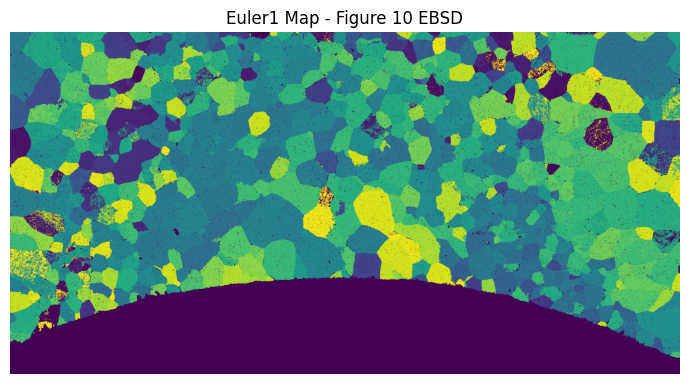

In [ ]:
import sys

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
sys.path.append(PROJECT_DIR)

from ebsd_graph.io import load_ctf
from ebsd_graph.visualization import dataframe_to_grid, plot_map

ctf_path = f"{PROJECT_DIR}/Figure_10_EBSD.ctf"

df = load_ctf(ctf_path)

print(df.head())
print(df.columns)
print(df.shape)

euler1_grid, x_vals, y_vals = dataframe_to_grid(df, "Euler1")

plot_map(euler1_grid, title="Euler1 Map - Figure 10 EBSD")

In [ ]:
# Create a manageable 512 x 512 crop for Experiment 1

df_valid = df[df["Phase"] > 0].copy()

x_unique = sorted(df_valid["X"].unique())
y_unique = sorted(df_valid["Y"].unique())

x_crop = x_unique[:512]
y_crop = y_unique[:512]

df_crop = df_valid[
    df_valid["X"].isin(x_crop) &
    df_valid["Y"].isin(y_crop)
].copy()

print(df_crop.shape)
print(df_crop.head())

(256005, 11)
   Phase    X    Y  Bands  Error  Euler1  Euler2  Euler3  MAD  BC  BS
0      1  0.0  0.0      1      0  151.87  32.434  42.109  0.7  14   0
1      1  1.5  0.0      8      0  151.12  32.208  42.815  0.7  80   0
2      1  3.0  0.0      1      0  149.61  33.305  44.066  0.6  13   0
3      1  4.5  0.0      9      0  152.40  33.103  40.352  0.9  87   0
5      1  7.5  0.0      1      0  150.39  34.117  43.269  0.8  13   0


In [ ]:
# ============================================================
# Experiment 1: Missing-pixel EBSD reconstruction baseline
# Safe version: handles original NaNs/unindexed gaps
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_01_missing_pixels"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

df_valid = df[df["Phase"] > 0].copy()

x_unique = np.sort(df["X"].unique())
y_unique = np.sort(df["Y"].unique())

x_crop = x_unique[:512]
y_crop = y_unique[:512]

df_crop = df[
    df["X"].isin(x_crop) &
    df["Y"].isin(y_crop)
].copy()

def dataframe_to_grid(df_in, value_col):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

orientation_cols = ["Euler1", "Euler2", "Euler3"]

maps = {col: dataframe_to_grid(df_crop, col) for col in orientation_cols}
phase_grid = dataframe_to_grid(df_crop, "Phase")

valid_mask = phase_grid > 0

print("Grid shape:", maps["Euler1"].shape)
print("Valid pixels in crop:", valid_mask.sum())

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)

    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)

    mask = np.zeros(valid_mask.shape, dtype=bool)
    chosen_pixels = candidates[selected]
    mask[chosen_pixels[:, 0], chosen_pixels[:, 1]] = True

    return mask

def reconstruct_grid(original_grid, valid_mask, missing_mask, method="nearest"):
    yy, xx = np.indices(original_grid.shape)

    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)

        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

def compute_metrics(original, reconstructed, missing_mask):
    y_true = original[missing_mask]
    y_pred = reconstructed[missing_mask]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    mae = mean_absolute_error(y_true[valid], y_pred[valid])
    rmse = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))

    return mae, rmse

missing_levels = [0.05, 0.10, 0.20, 0.40]
methods = ["nearest", "linear", "cubic"]

all_results = []

for missing_fraction in missing_levels:
    print(f"\nMissing level: {int(missing_fraction * 100)}%")

    missing_mask = create_missing_mask(
        valid_mask=valid_mask,
        missing_fraction=missing_fraction,
        seed=42
    )

    for method in methods:
        print(f"  Method: {method}")

        row = {
            "file": "Figure_10_EBSD.ctf",
            "crop_size": "512x512",
            "valid_pixels": int(valid_mask.sum()),
            "missing_fraction": missing_fraction,
            "method": method
        }

        reconstructed_maps = {}
        corrupted_maps = {}

        for col in orientation_cols:
            original = maps[col]

            corrupted = original.copy()
            corrupted[missing_mask] = np.nan

            reconstructed = reconstruct_grid(
                original_grid=original,
                valid_mask=valid_mask,
                missing_mask=missing_mask,
                method=method
            )

            mae, rmse = compute_metrics(original, reconstructed, missing_mask)

            row[f"{col}_MAE"] = mae
            row[f"{col}_RMSE"] = rmse

            corrupted_maps[col] = corrupted
            reconstructed_maps[col] = reconstructed

        all_results.append(row)

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_maps["Euler1"], cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title(f"Reconstructed: {method}")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"Figure10_512_missing_{int(missing_fraction*100)}_{method}_Euler1.png"
        )

        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.close()

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Figure10_512_experiment_01_missing_pixel_baselines_SAFE.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment completed.")
print("Results saved to:", results_csv)

display(results_df)

Grid shape: (512, 512)
Valid pixels in crop: 256005

Missing level: 5%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 10%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 20%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 40%
  Method: nearest
  Method: linear
  Method: cubic

Experiment completed.
Results saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_01_missing_pixels/Figure10_512_experiment_01_missing_pixel_baselines_SAFE.csv


,file,crop_size,valid_pixels,missing_fraction,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,nearest,8.071533,30.338451,0.911134,3.199295,6.653991,17.047322
1,Figure_10_EBSD.ctf,512x512,256005,0.05,linear,7.419079,23.701124,0.837603,2.449941,6.116184,14.170090
2,Figure_10_EBSD.ctf,512x512,256005,0.05,cubic,8.648879,24.917873,0.960597,2.499255,6.924322,15.447344
3,Figure_10_EBSD.ctf,512x512,256005,0.10,nearest,8.063786,30.039699,0.915887,3.227526,6.611452,16.829377
4,Figure_10_EBSD.ctf,512x512,256005,0.10,linear,7.453420,23.798114,0.832637,2.438205,6.151960,14.286534
5,Figure_10_EBSD.ctf,512x512,256005,0.10,cubic,8.668589,24.902150,0.953375,2.463808,6.985792,15.599795
6,Figure_10_EBSD.ctf,512x512,256005,0.20,nearest,7.995902,29.480394,0.904089,3.179690,6.734202,17.093719
7,Figure_10_EBSD.ctf,512x512,256005,0.20,linear,7.329644,23.019114,0.833055,2.409858,6.168399,14.174612
8,Figure_10_EBSD.ctf,512x512,256005,0.20,cubic,8.704878,24.573213,0.964443,2.461455,7.032236,15.501407
9,Figure_10_EBSD.ctf,512x512,256005,0.40,nearest,7.978385,29.336312,0.907636,3.170780,6.888446,17.422962


In [ ]:
# ============================================================
# Experiment 1: Missing-pixel reconstruction for EBSD .ctf maps
# Files: Figure_10_EBSD.ctf and Figure_6b_EBSD.ctf
# Methods: nearest, linear, cubic interpolation
# Missing levels: 5%, 10%, 20%, 40%
# Output: CSV metrics + figures + RMSE plot
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_01_missing_pixels"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

ctf_files = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

# ------------------------------------------------------------
# 2. CTF reader
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        stripped = line.strip()
        if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)

    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)

    mask = np.zeros(valid_mask.shape, dtype=bool)
    chosen = candidates[selected]
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

def reconstruct_grid(original_grid, valid_mask, missing_mask, method="nearest"):
    yy, xx = np.indices(original_grid.shape)

    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    # Fill NaNs from boundary effects using nearest neighbour
    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

def compute_metrics(original, reconstructed, missing_mask):
    y_true = original[missing_mask]
    y_pred = reconstructed[missing_mask]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    mae = mean_absolute_error(y_true[valid], y_pred[valid])
    rmse = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))

    return mae, rmse

# ------------------------------------------------------------
# 4. Experiment settings
# ------------------------------------------------------------

orientation_cols = ["Euler1", "Euler2", "Euler3"]
missing_levels = [0.05, 0.10, 0.20, 0.40]
methods = ["nearest", "linear", "cubic"]
crop_size = 512

all_results = []

# ------------------------------------------------------------
# 5. Run experiment on both CTF files
# ------------------------------------------------------------

for ctf_file in ctf_files:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    ctf_path = os.path.join(PROJECT_DIR, ctf_file)
    df = load_ctf(ctf_path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    print("Crop rows:", len(df_crop))

    maps = {
        col: dataframe_to_grid(df_crop, col, x_crop, y_crop)
        for col in orientation_cols
    }

    phase_grid = dataframe_to_grid(df_crop, "Phase", x_crop, y_crop)
    valid_mask = phase_grid > 0

    print("Grid shape:", maps["Euler1"].shape)
    print("Valid pixels:", int(valid_mask.sum()))

    for missing_fraction in missing_levels:

        print(f"\nMissing level: {int(missing_fraction * 100)}%")

        missing_mask = create_missing_mask(
            valid_mask=valid_mask,
            missing_fraction=missing_fraction,
            seed=42
        )

        for method in methods:

            print("  Method:", method)

            row = {
                "file": ctf_file,
                "crop_size": f"{crop_size}x{crop_size}",
                "valid_pixels": int(valid_mask.sum()),
                "missing_fraction": missing_fraction,
                "missing_percent": int(missing_fraction * 100),
                "method": method
            }

            reconstructed_maps = {}
            corrupted_maps = {}

            for col in orientation_cols:

                original = maps[col]

                corrupted = original.copy()
                corrupted[missing_mask] = np.nan

                reconstructed = reconstruct_grid(
                    original_grid=original,
                    valid_mask=valid_mask,
                    missing_mask=missing_mask,
                    method=method
                )

                mae, rmse = compute_metrics(
                    original=original,
                    reconstructed=reconstructed,
                    missing_mask=missing_mask
                )

                row[f"{col}_MAE"] = mae
                row[f"{col}_RMSE"] = rmse

                corrupted_maps[col] = corrupted
                reconstructed_maps[col] = reconstructed

            all_results.append(row)

            # Save Euler1 example figure
            fig, axes = plt.subplots(1, 3, figsize=(13, 4))

            axes[0].imshow(maps["Euler1"], cmap="viridis")
            axes[0].set_title("Original Euler1")

            axes[1].imshow(corrupted_maps["Euler1"], cmap="viridis")
            axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

            axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
            axes[2].set_title(f"Reconstructed: {method}")

            for ax in axes:
                ax.axis("off")

            plt.tight_layout()

            fig_name = (
                f"{ctf_file.replace('.ctf','')}_"
                f"{crop_size}_missing_{int(missing_fraction*100)}_"
                f"{method}_Euler1.png"
            )

            fig_path = os.path.join(FIG_DIR, fig_name)
            plt.savefig(fig_path, dpi=300, bbox_inches="tight")
            plt.close()

# ------------------------------------------------------------
# 6. Save combined results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

combined_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_01_missing_pixel_baselines_combined.csv"
)

results_df.to_csv(combined_csv, index=False)

print("\nExperiment completed.")
print("Combined results saved to:", combined_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

# ------------------------------------------------------------
# 7. Plot RMSE comparison for Euler1
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for ctf_file in ctf_files:
    for method in methods:
        subset = results_df[
            (results_df["file"] == ctf_file) &
            (results_df["method"] == method)
        ]

        plt.plot(
            subset["missing_percent"],
            subset["Euler1_RMSE"],
            marker="o",
            label=f"{ctf_file.replace('.ctf','')} - {method}"
        )

plt.xlabel("Missing pixels (%)")
plt.ylabel("Euler1 RMSE")
plt.title("Experiment 1: Missing-pixel reconstruction baseline")
plt.legend(fontsize=8)
plt.grid(True)
plt.tight_layout()

plot_path = os.path.join(
    FIG_DIR,
    "Experiment_01_Euler1_RMSE_comparison.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
# ------------------------------------------------------------
# Save final comparison figure
# ------------------------------------------------------------

plot_path = os.path.join(
    FIG_DIR,
    "Experiment_01_Euler1_RMSE_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=600,
    bbox_inches="tight"
)

plt.close()

print(f"Figure saved to:\n{plot_path}")

print("Comparison plot saved to:", plot_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf
Rows: 2356356
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
Crop rows: 262144
Grid shape: (512, 512)
Valid pixels: 256005

Missing level: 5%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 10%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 20%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 40%
  Method: nearest
  Method: linear
  Method: cubic

Processing: Figure_6b_EBSD.ctf
Rows: 2831310
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
Crop rows: 262144
Grid shape: (512, 512)
Valid pixels: 231622

Missing level: 5%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 10%
  Method: nearest
  Method: linear
  Method: cubic

Missing level: 20%
  Method: nearest
 

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,nearest,8.071533,30.338451,0.911134,3.199295,6.653991,17.047322
1,Figure_10_EBSD.ctf,512x512,256005,0.05,5,linear,7.419079,23.701124,0.837603,2.449941,6.116184,14.170090
2,Figure_10_EBSD.ctf,512x512,256005,0.05,5,cubic,8.648879,24.917873,0.960597,2.499255,6.924322,15.447344
3,Figure_10_EBSD.ctf,512x512,256005,0.10,10,nearest,8.063786,30.039699,0.915887,3.227526,6.611452,16.829377
4,Figure_10_EBSD.ctf,512x512,256005,0.10,10,linear,7.453420,23.798114,0.832637,2.438205,6.151960,14.286534
5,Figure_10_EBSD.ctf,512x512,256005,0.10,10,cubic,8.668589,24.902150,0.953375,2.463808,6.985792,15.599795
6,Figure_10_EBSD.ctf,512x512,256005,0.20,20,nearest,7.995902,29.480394,0.904089,3.179690,6.734202,17.093719
7,Figure_10_EBSD.ctf,512x512,256005,0.20,20,linear,7.329644,23.019114,0.833055,2.409858,6.168399,14.174612
8,Figure_10_EBSD.ctf,512x512,256005,0.20,20,cubic,8.704878,24.573213,0.964443,2.461455,7.032236,15.501407
9,Figure_10_EBSD.ctf,512x512,256005,0.40,40,nearest,7.978385,29.336312,0.907636,3.170780,6.888446,17.422962


Figure saved to:
/content/drive/MyDrive/EBSD Paper2/results/experiment_01_missing_pixels/figures/Experiment_01_Euler1_RMSE_comparison.png
Comparison plot saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_01_missing_pixels/figures/Experiment_01_Euler1_RMSE_comparison.png


In [ ]:
# ============================================================
# Experiment 2: Graph-neighbour reconstruction baseline
# Uses saved EBSD CTF files directly
# Method: reconstruct missing pixels using neighbouring graph nodes
# Neighbourhood: 4-neighbour grid graph
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_02_graph_neighbour"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

ctf_files = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

# ------------------------------------------------------------
# 2. CTF reader
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        stripped = line.strip()
        if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)

    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)

    mask = np.zeros(valid_mask.shape, dtype=bool)
    chosen = candidates[selected]
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

def compute_metrics(original, reconstructed, missing_mask):
    y_true = original[missing_mask]
    y_pred = reconstructed[missing_mask]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    mae = mean_absolute_error(y_true[valid], y_pred[valid])
    rmse = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))

    return mae, rmse

# ------------------------------------------------------------
# 4. Graph-neighbour reconstruction
# ------------------------------------------------------------

def graph_neighbour_reconstruct(original_grid, valid_mask, missing_mask, max_iters=20):
    """
    Reconstruct missing pixels using local graph-neighbour averaging.

    Each pixel is treated as a graph node.
    Edges connect 4-neighbour pixels: up, down, left, right.

    Missing nodes are iteratively filled from known neighbouring nodes.
    """

    reconstructed = original_grid.copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            neighbours = []

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])

            if len(neighbours) > 0:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1

        reconstructed = new_reconstructed

        print(f"    Iteration {iteration + 1}: filled {updated} pixels")

        if updated == 0:
            break

    # Any remaining NaNs: fallback to global mean of valid known pixels
    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        fallback_value = np.nanmean(reconstructed[valid_mask])
        reconstructed[remaining] = fallback_value

    return reconstructed

# ------------------------------------------------------------
# 5. Experiment settings
# ------------------------------------------------------------

orientation_cols = ["Euler1", "Euler2", "Euler3"]
missing_levels = [0.05, 0.10, 0.20, 0.40]
crop_size = 512

all_results = []

# ------------------------------------------------------------
# 6. Run Experiment 2
# ------------------------------------------------------------

for ctf_file in ctf_files:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    ctf_path = os.path.join(PROJECT_DIR, ctf_file)
    df = load_ctf(ctf_path)

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        col: dataframe_to_grid(df_crop, col, x_crop, y_crop)
        for col in orientation_cols
    }

    phase_grid = dataframe_to_grid(df_crop, "Phase", x_crop, y_crop)
    valid_mask = phase_grid > 0

    print("Grid shape:", maps["Euler1"].shape)
    print("Valid pixels:", int(valid_mask.sum()))

    for missing_fraction in missing_levels:

        print(f"\nMissing level: {int(missing_fraction * 100)}%")

        missing_mask = create_missing_mask(
            valid_mask=valid_mask,
            missing_fraction=missing_fraction,
            seed=42
        )

        row = {
            "file": ctf_file,
            "crop_size": f"{crop_size}x{crop_size}",
            "valid_pixels": int(valid_mask.sum()),
            "missing_fraction": missing_fraction,
            "missing_percent": int(missing_fraction * 100),
            "method": "graph_4_neighbour_mean"
        }

        reconstructed_maps = {}
        corrupted_maps = {}

        for col in orientation_cols:

            print(f"  Reconstructing {col}")

            original = maps[col]

            corrupted = original.copy()
            corrupted[missing_mask] = np.nan

            reconstructed = graph_neighbour_reconstruct(
                original_grid=original,
                valid_mask=valid_mask,
                missing_mask=missing_mask,
                max_iters=20
            )

            mae, rmse = compute_metrics(
                original=original,
                reconstructed=reconstructed,
                missing_mask=missing_mask
            )

            row[f"{col}_MAE"] = mae
            row[f"{col}_RMSE"] = rmse

            corrupted_maps[col] = corrupted
            reconstructed_maps[col] = reconstructed

        all_results.append(row)

        # Save Euler1 figure
        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_maps["Euler1"], cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title("Graph 4-neighbour reconstruction")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_name = (
            f"{ctf_file.replace('.ctf','')}_"
            f"{crop_size}_missing_{int(missing_fraction*100)}_"
            f"graph4_Euler1.png"
        )

        fig_path = os.path.join(FIG_DIR, fig_name)
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.close()

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_02_graph_neighbour_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 2 completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf
Grid shape: (512, 512)
Valid pixels: 256005

Missing level: 5%
  Reconstructing Euler1
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler2
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler3
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels

Missing level: 10%
  Reconstructing Euler1
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler2
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler3
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 p

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,graph_4_neighbour_mean,6.944585,21.491375,0.776963,2.220166,5.777143,12.996110
1,Figure_10_EBSD.ctf,512x512,256005,0.10,10,graph_4_neighbour_mean,6.926497,21.501850,0.772753,2.207357,5.820819,13.112697
2,Figure_10_EBSD.ctf,512x512,256005,0.20,20,graph_4_neighbour_mean,6.946347,21.873122,0.778783,2.280915,5.925190,13.511630
3,Figure_10_EBSD.ctf,512x512,256005,0.40,40,graph_4_neighbour_mean,7.283250,24.028877,0.817000,2.546028,6.226013,14.605362
4,Figure_6b_EBSD.ctf,512x512,231622,0.05,5,graph_4_neighbour_mean,8.881907,29.406877,5.763648,19.262255,1.699625,5.517572
5,Figure_6b_EBSD.ctf,512x512,231622,0.10,10,graph_4_neighbour_mean,8.780051,29.249795,5.753637,19.346511,1.692056,5.570178
6,Figure_6b_EBSD.ctf,512x512,231622,0.20,20,graph_4_neighbour_mean,8.843731,30.258085,5.730414,19.821374,1.730923,5.883461
7,Figure_6b_EBSD.ctf,512x512,231622,0.40,40,graph_4_neighbour_mean,9.143006,32.896369,5.891319,21.400685,1.796507,6.328270


In [ ]:
display(results_df.head())

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,graph_4_neighbour_mean,6.944585,21.491375,0.776963,2.220166,5.777143,12.996110
1,Figure_10_EBSD.ctf,512x512,256005,0.10,10,graph_4_neighbour_mean,6.926497,21.501850,0.772753,2.207357,5.820819,13.112697
2,Figure_10_EBSD.ctf,512x512,256005,0.20,20,graph_4_neighbour_mean,6.946347,21.873122,0.778783,2.280915,5.925190,13.511630
3,Figure_10_EBSD.ctf,512x512,256005,0.40,40,graph_4_neighbour_mean,7.283250,24.028877,0.817000,2.546028,6.226013,14.605362
4,Figure_6b_EBSD.ctf,512x512,231622,0.05,5,graph_4_neighbour_mean,8.881907,29.406877,5.763648,19.262255,1.699625,5.517572


Combined results saved to:
/content/drive/MyDrive/EBSD Paper2/results/experiment_03_method_comparison/Experiment_03_all_methods_combined.csv


,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,nearest,8.071533,30.338451,0.911134,3.199295,6.653991,17.047322
1,Figure_10_EBSD.ctf,512x512,256005,0.05,5,linear,7.419079,23.701124,0.837603,2.449941,6.116184,14.170090
2,Figure_10_EBSD.ctf,512x512,256005,0.05,5,cubic,8.648879,24.917873,0.960597,2.499255,6.924322,15.447344
3,Figure_10_EBSD.ctf,512x512,256005,0.10,10,nearest,8.063786,30.039699,0.915887,3.227526,6.611452,16.829377
4,Figure_10_EBSD.ctf,512x512,256005,0.10,10,linear,7.453420,23.798114,0.832637,2.438205,6.151960,14.286534
5,Figure_10_EBSD.ctf,512x512,256005,0.10,10,cubic,8.668589,24.902150,0.953375,2.463808,6.985792,15.599795
6,Figure_10_EBSD.ctf,512x512,256005,0.20,20,nearest,7.995902,29.480394,0.904089,3.179690,6.734202,17.093719
7,Figure_10_EBSD.ctf,512x512,256005,0.20,20,linear,7.329644,23.019114,0.833055,2.409858,6.168399,14.174612
8,Figure_10_EBSD.ctf,512x512,256005,0.20,20,cubic,8.704878,24.573213,0.964443,2.461455,7.032236,15.501407
9,Figure_10_EBSD.ctf,512x512,256005,0.40,40,nearest,7.978385,29.336312,0.907636,3.170780,6.888446,17.422962


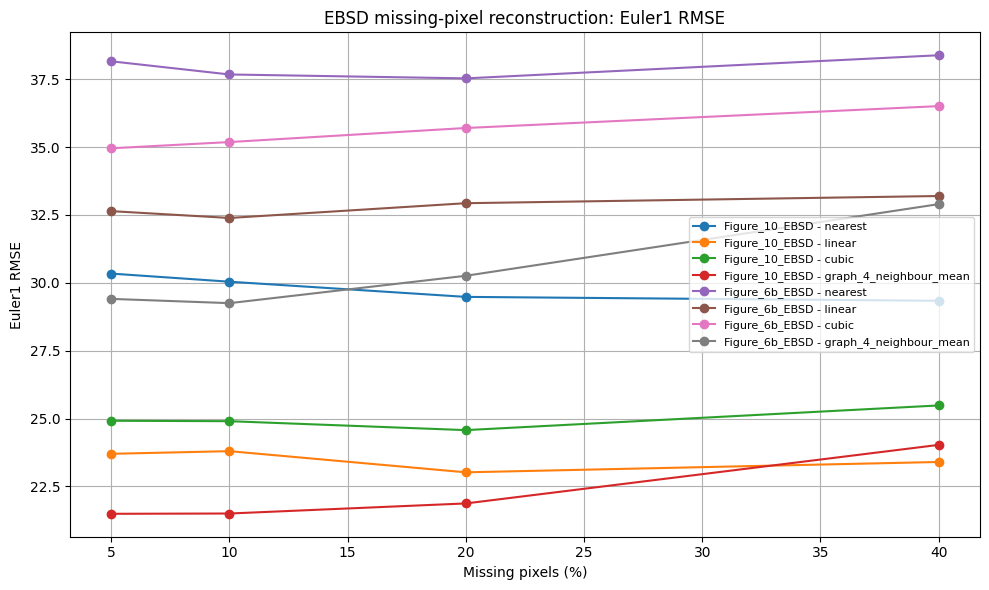

Saved plot:
/content/drive/MyDrive/EBSD Paper2/results/experiment_03_method_comparison/figures/Experiment_03_Euler1_RMSE_all_methods.png


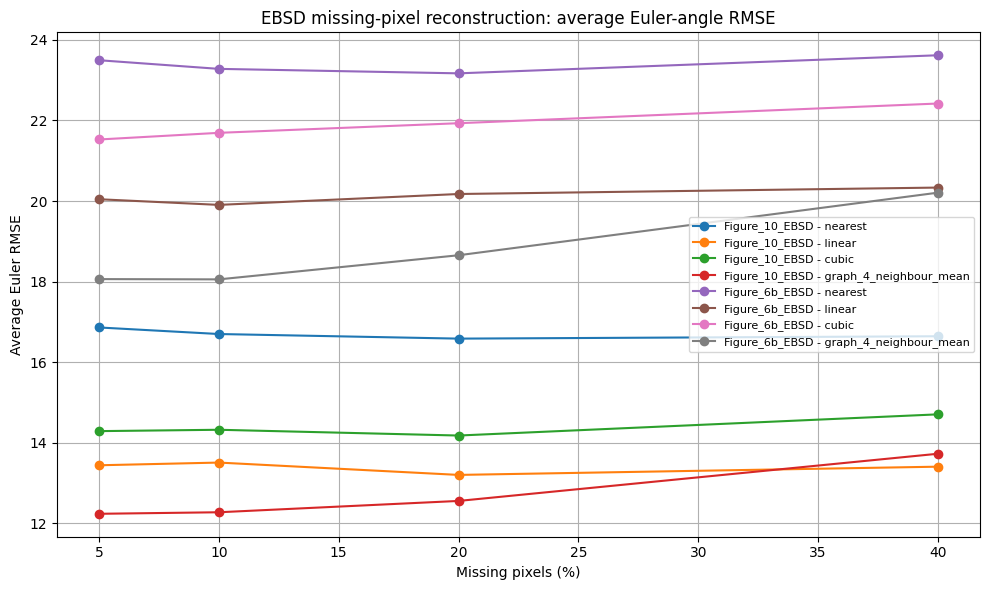

Saved average RMSE plot:
/content/drive/MyDrive/EBSD Paper2/results/experiment_03_method_comparison/figures/Experiment_03_Average_Euler_RMSE_all_methods.png
Best method summary saved to:
/content/drive/MyDrive/EBSD Paper2/results/experiment_03_method_comparison/Experiment_03_best_method_summary.csv


,file,missing_percent,method,Average_Euler_RMSE,Euler1_RMSE,Euler2_RMSE,Euler3_RMSE
0,Figure_10_EBSD.ctf,5,graph_4_neighbour_mean,12.235883,21.491375,2.220166,12.996110
1,Figure_10_EBSD.ctf,10,graph_4_neighbour_mean,12.273968,21.501850,2.207357,13.112697
2,Figure_10_EBSD.ctf,20,graph_4_neighbour_mean,12.555222,21.873122,2.280915,13.511630
3,Figure_10_EBSD.ctf,40,linear,13.405672,23.399980,2.440578,14.376460
4,Figure_6b_EBSD.ctf,5,graph_4_neighbour_mean,18.062235,29.406877,19.262255,5.517572
5,Figure_6b_EBSD.ctf,10,graph_4_neighbour_mean,18.055495,29.249795,19.346511,5.570178
6,Figure_6b_EBSD.ctf,20,graph_4_neighbour_mean,18.654307,30.258085,19.821374,5.883461
7,Figure_6b_EBSD.ctf,40,graph_4_neighbour_mean,20.208441,32.896369,21.400685,6.328270


In [ ]:
# ============================================================
# Combine Experiment 1 and Experiment 2 results
# Compare: nearest, linear, cubic, graph 4-neighbour
# Outputs: combined CSV + comparison plots saved to Google Drive
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

EXP1_DIR = f"{PROJECT_DIR}/results/experiment_01_missing_pixels"
EXP2_DIR = f"{PROJECT_DIR}/results/experiment_02_graph_neighbour"

OUTPUT_DIR = f"{PROJECT_DIR}/results/experiment_03_method_comparison"
FIG_DIR = f"{OUTPUT_DIR}/figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load results
# ------------------------------------------------------------

exp1_csv = f"{EXP1_DIR}/Experiment_01_missing_pixel_baselines_combined.csv"
exp2_csv = f"{EXP2_DIR}/Experiment_02_graph_neighbour_results.csv"

exp1 = pd.read_csv(exp1_csv)
exp2 = pd.read_csv(exp2_csv)

combined = pd.concat([exp1, exp2], ignore_index=True)

combined_csv = f"{OUTPUT_DIR}/Experiment_03_all_methods_combined.csv"
combined.to_csv(combined_csv, index=False)

print("Combined results saved to:")
print(combined_csv)

display(combined)

# ------------------------------------------------------------
# 2. Plot Euler1 RMSE comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for file_name in combined["file"].unique():
    for method in combined["method"].unique():
        subset = combined[
            (combined["file"] == file_name) &
            (combined["method"] == method)
        ].sort_values("missing_percent")

        if len(subset) == 0:
            continue

        plt.plot(
            subset["missing_percent"],
            subset["Euler1_RMSE"],
            marker="o",
            label=f"{file_name.replace('.ctf','')} - {method}"
        )

plt.xlabel("Missing pixels (%)")
plt.ylabel("Euler1 RMSE")
plt.title("EBSD missing-pixel reconstruction: Euler1 RMSE")
plt.legend(fontsize=8)
plt.grid(True)
plt.tight_layout()

plot_path = f"{FIG_DIR}/Experiment_03_Euler1_RMSE_all_methods.png"
plt.savefig(plot_path, dpi=600, bbox_inches="tight")
plt.show()

print("Saved plot:")
print(plot_path)

# ------------------------------------------------------------
# 3. Plot average RMSE across Euler angles
# ------------------------------------------------------------

combined["Average_Euler_RMSE"] = combined[
    ["Euler1_RMSE", "Euler2_RMSE", "Euler3_RMSE"]
].mean(axis=1)

avg_csv = f"{OUTPUT_DIR}/Experiment_03_average_euler_rmse.csv"
combined.to_csv(avg_csv, index=False)

plt.figure(figsize=(10, 6))

for file_name in combined["file"].unique():
    for method in combined["method"].unique():
        subset = combined[
            (combined["file"] == file_name) &
            (combined["method"] == method)
        ].sort_values("missing_percent")

        if len(subset) == 0:
            continue

        plt.plot(
            subset["missing_percent"],
            subset["Average_Euler_RMSE"],
            marker="o",
            label=f"{file_name.replace('.ctf','')} - {method}"
        )

plt.xlabel("Missing pixels (%)")
plt.ylabel("Average Euler RMSE")
plt.title("EBSD missing-pixel reconstruction: average Euler-angle RMSE")
plt.legend(fontsize=8)
plt.grid(True)
plt.tight_layout()

plot_path_avg = f"{FIG_DIR}/Experiment_03_Average_Euler_RMSE_all_methods.png"
plt.savefig(plot_path_avg, dpi=600, bbox_inches="tight")
plt.show()

print("Saved average RMSE plot:")
print(plot_path_avg)

# ------------------------------------------------------------
# 4. Create summary table: best method per file and missing level
# ------------------------------------------------------------

summary = (
    combined
    .sort_values("Average_Euler_RMSE")
    .groupby(["file", "missing_percent"])
    .first()
    .reset_index()
)

summary = summary[
    [
        "file",
        "missing_percent",
        "method",
        "Average_Euler_RMSE",
        "Euler1_RMSE",
        "Euler2_RMSE",
        "Euler3_RMSE"
    ]
]

summary_csv = f"{OUTPUT_DIR}/Experiment_03_best_method_summary.csv"
summary.to_csv(summary_csv, index=False)

print("Best method summary saved to:")
print(summary_csv)

display(summary)

In [ ]:
# ============================================================
# Experiment 4: Crystallography-aware weighted graph reconstruction
# Compares: graph_4_neighbour_mean vs graph_4_neighbour_weighted
# Weighting: exp(-orientation_difference / sigma)
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_04_weighted_graph"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

ctf_files = ["Figure_10_EBSD.ctf", "Figure_6b_EBSD.ctf"]

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None
    for i, line in enumerate(lines):
        stripped = line.strip()
        if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    return pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)

    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]

    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

def compute_metrics(original, reconstructed, missing_mask):
    y_true = original[missing_mask]
    y_pred = reconstructed[missing_mask]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    mae = mean_absolute_error(y_true[valid], y_pred[valid])
    rmse = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))

    return mae, rmse

def weighted_graph_reconstruct(maps, valid_mask, missing_mask, target_col, sigma=20.0, max_iters=20):
    """
    Weighted graph reconstruction.

    Each pixel is treated as a graph node.
    Edges connect 4-neighbour pixels.
    Known neighbours are weighted by approximate Euler-space similarity.

    This is intentionally a simple baseline, not a full crystallographic
    misorientation model.
    """

    reconstructed = maps[target_col].copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    e1 = maps["Euler1"]
    e2 = maps["Euler2"]
    e3 = maps["Euler3"]

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            values = []
            weights = []

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):

                        # Approximate local Euler-space distance
                        d = np.sqrt(
                            (e1[rr, cc] - e1[r, c])**2 +
                            (e2[rr, cc] - e2[r, c])**2 +
                            (e3[rr, cc] - e3[r, c])**2
                        )

                        w = np.exp(-d / sigma)

                        values.append(reconstructed[rr, cc])
                        weights.append(w)

            if len(values) > 0:
                values = np.array(values)
                weights = np.array(weights)

                if weights.sum() > 0:
                    new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights)
                else:
                    new_reconstructed[r, c] = np.mean(values)

                updated += 1

        reconstructed = new_reconstructed
        print(f"    Iteration {iteration + 1}: filled {updated} pixels")

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        fallback = np.nanmean(reconstructed[valid_mask])
        reconstructed[remaining] = fallback

    return reconstructed

orientation_cols = ["Euler1", "Euler2", "Euler3"]
missing_levels = [0.05, 0.10, 0.20, 0.40]
crop_size = 512
sigma = 20.0

all_results = []

for ctf_file in ctf_files:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        col: dataframe_to_grid(df_crop, col, x_crop, y_crop)
        for col in orientation_cols
    }

    phase_grid = dataframe_to_grid(df_crop, "Phase", x_crop, y_crop)
    valid_mask = phase_grid > 0

    print("Grid shape:", maps["Euler1"].shape)
    print("Valid pixels:", int(valid_mask.sum()))

    for missing_fraction in missing_levels:

        print(f"\nMissing level: {int(missing_fraction * 100)}%")

        missing_mask = create_missing_mask(
            valid_mask=valid_mask,
            missing_fraction=missing_fraction,
            seed=42
        )

        row = {
            "file": ctf_file,
            "crop_size": f"{crop_size}x{crop_size}",
            "valid_pixels": int(valid_mask.sum()),
            "missing_fraction": missing_fraction,
            "missing_percent": int(missing_fraction * 100),
            "method": "graph_4_neighbour_weighted",
            "sigma": sigma
        }

        reconstructed_maps = {}
        corrupted_maps = {}

        for col in orientation_cols:

            print(f"  Reconstructing {col}")

            original = maps[col]

            corrupted = original.copy()
            corrupted[missing_mask] = np.nan

            reconstructed = weighted_graph_reconstruct(
                maps=maps,
                valid_mask=valid_mask,
                missing_mask=missing_mask,
                target_col=col,
                sigma=sigma,
                max_iters=20
            )

            mae, rmse = compute_metrics(
                original=original,
                reconstructed=reconstructed,
                missing_mask=missing_mask
            )

            row[f"{col}_MAE"] = mae
            row[f"{col}_RMSE"] = rmse

            reconstructed_maps[col] = reconstructed
            corrupted_maps[col] = corrupted

        all_results.append(row)

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_maps["Euler1"], cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title("Weighted graph reconstruction")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_{crop_size}_missing_{int(missing_fraction*100)}_weighted_graph_Euler1.png"
        )

        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.close()

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_04_weighted_graph_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 4 completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf
Grid shape: (512, 512)
Valid pixels: 256005

Missing level: 5%
  Reconstructing Euler1
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler2
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler3
    Iteration 1: filled 12799 pixels
    Iteration 2: filled 1 pixels
    Iteration 3: filled 0 pixels

Missing level: 10%
  Reconstructing Euler1
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler2
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 pixels
  Reconstructing Euler3
    Iteration 1: filled 25591 pixels
    Iteration 2: filled 9 pixels
    Iteration 3: filled 0 p

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,sigma,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,graph_4_neighbour_weighted,20.0,2.754527,10.754539,0.472934,0.847600,2.815997,7.890251
1,Figure_10_EBSD.ctf,512x512,256005,0.10,10,graph_4_neighbour_weighted,20.0,2.893276,11.212228,0.480079,0.978476,2.922885,8.184501
2,Figure_10_EBSD.ctf,512x512,256005,0.20,20,graph_4_neighbour_weighted,20.0,3.239235,13.154280,0.509220,1.225643,3.232430,9.198947
3,Figure_10_EBSD.ctf,512x512,256005,0.40,40,graph_4_neighbour_weighted,20.0,4.334260,17.941569,0.603602,1.857733,4.113663,11.679757
4,Figure_6b_EBSD.ctf,512x512,231622,0.05,5,graph_4_neighbour_weighted,20.0,2.258664,17.976166,1.446158,11.551920,0.688891,3.449349
5,Figure_6b_EBSD.ctf,512x512,231622,0.10,10,graph_4_neighbour_weighted,20.0,2.389215,18.502293,1.528585,12.038579,0.719536,3.706770
6,Figure_6b_EBSD.ctf,512x512,231622,0.20,20,graph_4_neighbour_weighted,20.0,2.949642,20.831479,1.894032,13.551912,0.851882,4.382125
7,Figure_6b_EBSD.ctf,512x512,231622,0.40,40,graph_4_neighbour_weighted,20.0,4.613026,26.614947,2.975856,17.287642,1.116212,5.274179


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os, time, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
CTF_FILES = ["Figure_10_EBSD.ctf", "Figure_6b_EBSD.ctf"]

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()
    header_idx = None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")
    columns = lines[header_idx].strip().split()
    return pd.read_csv(path, sep=r"\s+", skiprows=header_idx + 1, names=columns, engine="python")

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))
    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())
    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]
    df_crop = df[df["X"].isin(x_crop) & df["Y"].isin(y_crop)].copy()
    maps = {c: dataframe_to_grid(df_crop, c, x_crop, y_crop) for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]}
    valid_mask = maps["Phase"] > 0
    return maps, valid_mask

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]
    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True
    return mask

def compute_euler_metrics(original_deg, reconstructed_deg, eval_mask):
    out = {}
    for i, col in enumerate(["Euler1", "Euler2", "Euler3"]):
        y_true = original_deg[i][eval_mask]
        y_pred = reconstructed_deg[i][eval_mask]
        valid = np.isfinite(y_true) & np.isfinite(y_pred)
        out[f"{col}_MAE"] = mean_absolute_error(y_true[valid], y_pred[valid])
        out[f"{col}_RMSE"] = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))
    out["Average_Euler_RMSE"] = np.mean([out["Euler1_RMSE"], out["Euler2_RMSE"], out["Euler3_RMSE"]])
    out["Average_Euler_MAE"] = np.mean([out["Euler1_MAE"], out["Euler2_MAE"], out["Euler3_MAE"]])
    return out

# ============================================================
# Experiment 07: GraphSAGE reconstruction with checkpointing
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_07_graphsage_reconstruction"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"
LOG_DIR = f"{RESULTS_DIR}/logs"
for d in [RESULTS_DIR, FIG_DIR, MODEL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        kernel = torch.tensor([[0,1,0],[1,0,1],[0,1,0]], dtype=torch.float32).view(1,1,3,3)
        self.register_buffer("kernel", kernel)

    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(
            x * valid_mask,
            self.kernel.repeat(x.shape[1], 1, 1, 1),
            padding=1,
            groups=x.shape[1]
        )
        neighbour_count = F.conv2d(valid_mask, self.kernel, padding=1).clamp(min=1.0)
        neighbour_mean = neighbour_sum / neighbour_count
        return self.self_linear(x) + self.neigh_linear(neighbour_mean)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=8, hidden_channels=64, out_channels=3):
        super().__init__()
        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)

    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        return self.output(x)

def run_graphsage(ctf_file, missing_fraction, crop_size=256, epochs=80, lr=1e-3, seed=42, resume=True):
    maps, valid_mask_np = prepare_crop(ctf_file, crop_size=crop_size)
    original_deg = np.stack([maps["Euler1"], maps["Euler2"], maps["Euler3"]], axis=0)
    original_norm = original_deg / 360.0

    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)

    eval_missing_mask = create_missing_mask(valid_mask_np, missing_fraction, seed=seed)

    rng = np.random.default_rng(seed + 1000)
    train_candidates = np.argwhere(valid_mask_np & (~eval_missing_mask))
    train_hide_count = int(len(train_candidates) * 0.10)
    chosen = train_candidates[rng.choice(len(train_candidates), size=train_hide_count, replace=False)]

    train_hide_mask = np.zeros(valid_mask_np.shape, dtype=bool)
    train_hide_mask[chosen[:, 0], chosen[:, 1]] = True

    hidden_mask = eval_missing_mask | train_hide_mask
    visible_mask = valid_mask_np & (~hidden_mask)

    euler_input = original_norm.copy()
    euler_input[:, hidden_mask] = 0.0

    input_features = np.stack([
        euler_input[0], euler_input[1], euler_input[2],
        phase_norm, bc_norm, mad_norm,
        visible_mask.astype(float),
        valid_mask_np.astype(float)
    ], axis=0)

    x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
    y_tensor = torch.tensor(original_norm, dtype=torch.float32).unsqueeze(0).to(device)
    valid_tensor = torch.tensor(valid_mask_np.astype(float), dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    train_mask_tensor = torch.tensor(train_hide_mask, dtype=torch.bool).to(device)

    model = GridGraphSAGE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    run_id = f"{ctf_file.replace('.ctf','')}_crop{crop_size}_missing{int(missing_fraction*100)}_seed{seed}"
    checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")
    final_model_path = os.path.join(MODEL_DIR, f"{run_id}_final.pt")
    log_path = os.path.join(LOG_DIR, f"{run_id}_training_log.csv")

    start_epoch = 0
    logs = []

    if resume and os.path.exists(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        start_epoch = ckpt["epoch"] + 1
        if os.path.exists(log_path):
            logs = pd.read_csv(log_path).to_dict("records")
        print(f"Resuming {run_id} from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(x_tensor, valid_tensor)
        loss = F.mse_loss(pred[0, :, train_mask_tensor].T, y_tensor[0, :, train_mask_tensor].T)
        loss.backward()
        optimizer.step()

        logs.append({"epoch": epoch + 1, "loss": float(loss.item())})

        if (epoch + 1) % 5 == 0 or epoch == epochs - 1:
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "loss": float(loss.item())
            }, checkpoint_path)
            pd.DataFrame(logs).to_csv(log_path, index=False)
            print(f"{run_id}: epoch {epoch+1}/{epochs}, loss={loss.item():.6f}")

    model.eval()
    with torch.no_grad():
        pred_norm = model(x_tensor, valid_tensor)[0].cpu().numpy()

    pred_deg = pred_norm * 360.0
    metrics = compute_euler_metrics(original_deg, pred_deg, eval_missing_mask)

    torch.save(model.state_dict(), final_model_path)

    # Save figure
    corrupted_euler1 = maps["Euler1"].copy()
    corrupted_euler1[eval_missing_mask] = np.nan
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(maps["Euler1"], cmap="viridis"); axes[0].set_title("Original Euler1")
    axes[1].imshow(corrupted_euler1, cmap="viridis"); axes[1].set_title(f"{int(missing_fraction*100)}% missing")
    axes[2].imshow(pred_deg[0], cmap="viridis"); axes[2].set_title("GraphSAGE reconstruction")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, f"{run_id}_GraphSAGE_Euler1.png")
    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.close()

    row = {
        "file": ctf_file,
        "crop_size": f"{crop_size}x{crop_size}",
        "valid_pixels": int(valid_mask_np.sum()),
        "missing_fraction": missing_fraction,
        "missing_percent": int(missing_fraction * 100),
        "method": "GraphSAGE_grid",
        "epochs": epochs,
        "learning_rate": lr,
        "seed": seed,
        "checkpoint": checkpoint_path,
        "final_model": final_model_path
    }
    row.update(metrics)
    return row

all_results = []
for ctf_file in CTF_FILES:
    for missing_fraction in [0.05, 0.10, 0.20, 0.40]:
        all_results.append(run_graphsage(ctf_file, missing_fraction, crop_size=256, epochs=80, lr=1e-3, seed=42, resume=True))
        pd.DataFrame(all_results).to_csv(os.path.join(RESULTS_DIR, "Experiment_07_GraphSAGE_results_IN_PROGRESS.csv"), index=False)

results_df = pd.DataFrame(all_results)
results_csv = os.path.join(RESULTS_DIR, "Experiment_07_GraphSAGE_results.csv")
results_df.to_csv(results_csv, index=False)
print("Saved:", results_csv)
display(results_df)


Mounted at /content/drive
Using device: cpu
Figure_10_EBSD_crop256_missing5_seed42: epoch 5/80, loss=0.020003
Figure_10_EBSD_crop256_missing5_seed42: epoch 10/80, loss=0.015484
Figure_10_EBSD_crop256_missing5_seed42: epoch 15/80, loss=0.016166
Figure_10_EBSD_crop256_missing5_seed42: epoch 20/80, loss=0.010329
Figure_10_EBSD_crop256_missing5_seed42: epoch 25/80, loss=0.010802
Figure_10_EBSD_crop256_missing5_seed42: epoch 30/80, loss=0.010069
Figure_10_EBSD_crop256_missing5_seed42: epoch 35/80, loss=0.008679
Figure_10_EBSD_crop256_missing5_seed42: epoch 40/80, loss=0.008466
Figure_10_EBSD_crop256_missing5_seed42: epoch 45/80, loss=0.007797
Figure_10_EBSD_crop256_missing5_seed42: epoch 50/80, loss=0.007279
Figure_10_EBSD_crop256_missing5_seed42: epoch 55/80, loss=0.006835
Figure_10_EBSD_crop256_missing5_seed42: epoch 60/80, loss=0.006301
Figure_10_EBSD_crop256_missing5_seed42: epoch 65/80, loss=0.005849
Figure_10_EBSD_crop256_missing5_seed42: epoch 70/80, loss=0.005342
Figure_10_EBSD_crop

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,epochs,learning_rate,seed,checkpoint,final_model,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,256x256,63940,0.05,5,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,24.247404,31.412818,9.425266,11.130121,20.050250,22.233797,21.592245,17.907640
1,Figure_10_EBSD.ctf,256x256,63940,0.10,10,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,34.194910,42.238626,10.259143,12.269447,15.213595,17.902382,24.136818,19.889216
2,Figure_10_EBSD.ctf,256x256,63940,0.20,20,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,35.185609,43.932525,9.516612,11.935407,13.561245,16.906521,24.258151,19.421155
3,Figure_10_EBSD.ctf,256x256,63940,0.40,40,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,39.904739,49.097760,10.372881,12.506090,14.584009,17.975944,26.526598,21.620543
4,Figure_6b_EBSD.ctf,256x256,59548,0.05,5,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,14.088256,27.417401,13.465221,21.200385,5.544209,9.099556,19.239114,11.032562
5,Figure_6b_EBSD.ctf,256x256,59548,0.10,10,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,16.769710,30.118773,16.495740,23.857184,5.282492,8.986851,20.987603,12.849314
6,Figure_6b_EBSD.ctf,256x256,59548,0.20,20,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,20.319822,33.391493,18.527770,26.514295,5.838284,9.294215,23.066668,14.895292
7,Figure_6b_EBSD.ctf,256x256,59548,0.40,40,GraphSAGE_grid,80,0.001,42,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,21.453592,35.517643,20.252942,27.249519,6.471678,10.354966,24.374043,16.059404


In [ ]:
# Experiment 7B: GraphSAGE with sin/cos Euler representation
# Saves all outputs to Google Drive

from google.colab import drive
drive.mount('/content/drive')

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_07B_graphsage_sincos"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CTF_FILES = ["Figure_10_EBSD.ctf", "Figure_6b_EBSD.ctf"]

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    columns = lines[header_idx].strip().split()

    return pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0

    return maps, valid_mask

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)

    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]

    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

def euler_to_sincos(e1, e2, e3):
    angles = np.stack([e1, e2, e3], axis=0)
    radians = np.deg2rad(angles)

    sin_part = np.sin(radians)
    cos_part = np.cos(radians)

    return np.concatenate([sin_part, cos_part], axis=0)

def sincos_to_euler(pred):
    sin_part = pred[:3]
    cos_part = pred[3:]

    angles = np.rad2deg(np.arctan2(sin_part, cos_part))
    angles = np.mod(angles, 360.0)

    return angles

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_metrics(original_deg, reconstructed_deg, eval_mask):
    out = {}

    for i, col in enumerate(["Euler1", "Euler2", "Euler3"]):
        err = angular_error_deg(original_deg[i], reconstructed_deg[i])
        values = err[eval_mask]
        values = values[np.isfinite(values)]

        out[f"{col}_MAE"] = np.mean(values)
        out[f"{col}_RMSE"] = np.sqrt(np.mean(values ** 2))

    out["Average_Euler_RMSE"] = np.mean([
        out["Euler1_RMSE"],
        out["Euler2_RMSE"],
        out["Euler3_RMSE"]
    ])

    out["Average_Euler_MAE"] = np.mean([
        out["Euler1_MAE"],
        out["Euler2_MAE"],
        out["Euler3_MAE"]
    ])

    return out

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        kernel = torch.tensor(
            [[0,1,0],
             [1,0,1],
             [0,1,0]],
            dtype=torch.float32
        ).view(1,1,3,3)

        self.register_buffer("kernel", kernel)

    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(
            x * valid_mask,
            self.kernel.repeat(x.shape[1], 1, 1, 1),
            padding=1,
            groups=x.shape[1]
        )

        neighbour_count = F.conv2d(
            valid_mask,
            self.kernel,
            padding=1
        ).clamp(min=1.0)

        neighbour_mean = neighbour_sum / neighbour_count

        return self.self_linear(x) + self.neigh_linear(neighbour_mean)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=11, hidden_channels=128, out_channels=6):
        super().__init__()

        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.layer3 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)

    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        x = F.relu(self.layer3(x, valid_mask))
        return self.output(x)

crop_size = 256
missing_levels = [0.05, 0.10, 0.20, 0.40]
epochs = 150
learning_rate = 5e-4
seed = 42

all_results = []

for ctf_file in CTF_FILES:

    print("\n====================================")
    print("Processing:", ctf_file)
    print("====================================")

    maps, valid_mask_np = prepare_crop(ctf_file, crop_size=crop_size)

    original_deg = np.stack(
        [maps["Euler1"], maps["Euler2"], maps["Euler3"]],
        axis=0
    )

    target_sincos = euler_to_sincos(
        maps["Euler1"],
        maps["Euler2"],
        maps["Euler3"]
    )

    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)

    for missing_fraction in missing_levels:

        print(f"\nMissing level: {int(missing_fraction*100)}%")

        eval_missing_mask = create_missing_mask(
            valid_mask_np,
            missing_fraction,
            seed=seed
        )

        rng = np.random.default_rng(seed + 1000)

        available_train = valid_mask_np & (~eval_missing_mask)
        train_candidates = np.argwhere(available_train)

        train_hide_count = int(len(train_candidates) * 0.10)
        selected = rng.choice(
            len(train_candidates),
            size=train_hide_count,
            replace=False
        )

        chosen = train_candidates[selected]

        train_hide_mask = np.zeros(valid_mask_np.shape, dtype=bool)
        train_hide_mask[chosen[:, 0], chosen[:, 1]] = True

        hidden_mask = eval_missing_mask | train_hide_mask
        visible_mask = valid_mask_np & (~hidden_mask)

        sincos_input = target_sincos.copy()
        sincos_input[:, hidden_mask] = 0.0

        input_features = np.concatenate(
            [
                sincos_input,
                np.expand_dims(phase_norm, axis=0),
                np.expand_dims(bc_norm, axis=0),
                np.expand_dims(mad_norm, axis=0),
                np.expand_dims(visible_mask.astype(float), axis=0),
                np.expand_dims(valid_mask_np.astype(float), axis=0),
            ],
            axis=0
        )

        x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
        y_tensor = torch.tensor(target_sincos, dtype=torch.float32).unsqueeze(0).to(device)

        valid_tensor = torch.tensor(
            valid_mask_np.astype(float),
            dtype=torch.float32
        ).unsqueeze(0).unsqueeze(0).to(device)

        train_mask_tensor = torch.tensor(train_hide_mask, dtype=torch.bool).to(device)

        model = GridGraphSAGE(
            in_channels=input_features.shape[0],
            hidden_channels=128,
            out_channels=6
        ).to(device)

        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

        run_id = f"{ctf_file.replace('.ctf','')}_crop{crop_size}_missing{int(missing_fraction*100)}_sincos"
        checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")

        losses = []

        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()

            pred = model(x_tensor, valid_tensor)

            loss = F.mse_loss(
                pred[0, :, train_mask_tensor].T,
                y_tensor[0, :, train_mask_tensor].T
            )

            loss.backward()
            optimizer.step()

            losses.append(float(loss.item()))

            if (epoch + 1) % 25 == 0:
                print(f"Epoch {epoch+1}/{epochs}, loss={loss.item():.6f}")
                torch.save(model.state_dict(), checkpoint_path)

        model.eval()

        with torch.no_grad():
            pred_sincos = model(x_tensor, valid_tensor)[0].cpu().numpy()

        pred_deg = sincos_to_euler(pred_sincos)

        metrics = compute_metrics(
            original_deg,
            pred_deg,
            eval_missing_mask
        )

        row = {
            "file": ctf_file,
            "crop_size": f"{crop_size}x{crop_size}",
            "valid_pixels": int(valid_mask_np.sum()),
            "missing_fraction": missing_fraction,
            "missing_percent": int(missing_fraction * 100),
            "method": "GraphSAGE_sincos",
            "epochs": epochs,
            "learning_rate": learning_rate,
            "seed": seed
        }

        row.update(metrics)
        all_results.append(row)

        torch.save(
            model.state_dict(),
            os.path.join(MODEL_DIR, f"{run_id}_final.pt")
        )

        pd.DataFrame({"epoch": range(1, epochs + 1), "loss": losses}).to_csv(
            os.path.join(RESULTS_DIR, f"{run_id}_loss.csv"),
            index=False
        )

        corrupted_euler1 = maps["Euler1"].copy()
        corrupted_euler1[eval_missing_mask] = np.nan

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_euler1, cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction*100)}% Missing")

        axes[2].imshow(pred_deg[0], cmap="viridis")
        axes[2].set_title("GraphSAGE sin/cos")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{run_id}_Euler1.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

        pd.DataFrame(all_results).to_csv(
            os.path.join(RESULTS_DIR, "Experiment_07B_GraphSAGE_sincos_IN_PROGRESS.csv"),
            index=False
        )

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_07B_GraphSAGE_sincos_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 7B completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)
print("Models saved to:", MODEL_DIR)

display(results_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu

Processing: Figure_10_EBSD.ctf

Missing level: 5%
Epoch 25/150, loss=0.089356
Epoch 50/150, loss=0.030790
Epoch 75/150, loss=0.018258
Epoch 100/150, loss=0.013749
Epoch 125/150, loss=0.011307
Epoch 150/150, loss=0.009649

Missing level: 10%
Epoch 25/150, loss=0.089180
Epoch 50/150, loss=0.033885
Epoch 75/150, loss=0.017409
Epoch 100/150, loss=0.011796
Epoch 125/150, loss=0.009477
Epoch 150/150, loss=0.008658

Missing level: 20%
Epoch 25/150, loss=0.105482
Epoch 50/150, loss=0.035633
Epoch 75/150, loss=0.017750
Epoch 100/150, loss=0.013302
Epoch 125/150, loss=0.010343
Epoch 150/150, loss=0.009215

Missing level: 40%
Epoch 25/150, loss=0.105214
Epoch 50/150, loss=0.043706
Epoch 75/150, loss=0.028077
Epoch 100/150, loss=0.019769
Epoch 125/150, loss=0.014339
Epoch 150/150, loss=0.011461

Processing: Figure_6b_EBSD.ctf

Missing level: 5%
Epoch 2

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,epochs,learning_rate,seed,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,256x256,63940,0.05,5,GraphSAGE_sincos,150,0.0005,42,4.685427,11.693864,2.257842,3.577405,4.277969,7.928903,7.733391,3.740412
1,Figure_10_EBSD.ctf,256x256,63940,0.10,10,GraphSAGE_sincos,150,0.0005,42,4.690982,12.659515,1.885252,3.338532,4.368384,8.317047,8.105031,3.648206
2,Figure_10_EBSD.ctf,256x256,63940,0.20,20,GraphSAGE_sincos,150,0.0005,42,4.744645,11.404536,1.968898,3.307786,4.504861,8.450554,7.720959,3.739468
3,Figure_10_EBSD.ctf,256x256,63940,0.40,40,GraphSAGE_sincos,150,0.0005,42,5.262873,12.888618,2.942622,4.489578,5.316724,9.260611,8.879602,4.507407
4,Figure_6b_EBSD.ctf,256x256,59548,0.05,5,GraphSAGE_sincos,150,0.0005,42,6.361144,24.743527,5.819296,17.445811,2.265313,5.732605,15.973981,4.815251
5,Figure_6b_EBSD.ctf,256x256,59548,0.10,10,GraphSAGE_sincos,150,0.0005,42,6.635278,25.053660,5.979461,17.421684,2.530364,5.882366,16.119236,5.048368
6,Figure_6b_EBSD.ctf,256x256,59548,0.20,20,GraphSAGE_sincos,150,0.0005,42,7.048770,25.933352,6.250701,17.955743,2.594264,6.253702,16.714266,5.297912
7,Figure_6b_EBSD.ctf,256x256,59548,0.40,40,GraphSAGE_sincos,150,0.0005,42,8.054705,26.766813,7.061265,18.787231,3.214826,6.894996,17.483013,6.110265


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: classical_interpolation
Loaded: graph_neighbour
Loaded: observable_weighted_graph
Loaded: graphsage_raw_euler
Loaded: graphsage_sincos

Saved master table:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/Experiment_07C_master_all_methods.csv


,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,source,Average_Euler_RMSE,Average_Euler_MAE,Euler1_RMSE,...,Euler2_MAE,Euler3_MAE,epochs,learning_rate,seed,sigma_bc,sigma_mad,phase_bonus,checkpoint,final_model
0,Figure_10_EBSD.ctf,512x512,256005,0.05,5,nearest,classical_interpolation,16.861689,5.212219,30.338451,...,0.911134,6.653991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Figure_10_EBSD.ctf,512x512,256005,0.05,5,linear,classical_interpolation,13.440385,4.790955,23.701124,...,0.837603,6.116184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Figure_10_EBSD.ctf,512x512,256005,0.05,5,cubic,classical_interpolation,14.288158,5.511266,24.917873,...,0.960597,6.924322,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Figure_10_EBSD.ctf,512x512,256005,0.10,10,nearest,classical_interpolation,16.698867,5.197042,30.039699,...,0.915887,6.611452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Figure_10_EBSD.ctf,512x512,256005,0.10,10,linear,classical_interpolation,13.507618,4.812672,23.798114,...,0.832637,6.151960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Figure_10_EBSD.ctf,512x512,256005,0.10,10,cubic,classical_interpolation,14.321918,5.535918,24.902150,...,0.953375,6.985792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Figure_10_EBSD.ctf,512x512,256005,0.20,20,nearest,classical_interpolation,16.584601,5.211398,29.480394,...,0.904089,6.734202,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Figure_10_EBSD.ctf,512x512,256005,0.20,20,linear,classical_interpolation,13.201195,4.777033,23.019114,...,0.833055,6.168399,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Figure_10_EBSD.ctf,512x512,256005,0.20,20,cubic,classical_interpolation,14.178692,5.567186,24.573213,...,0.964443,7.032236,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Figure_10_EBSD.ctf,512x512,256005,0.40,40,nearest,classical_interpolation,16.643351,5.258156,29.336312,...,0.907636,6.888446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved best-method summary:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/tables/Experiment_07C_best_method_summary.csv


,file,missing_percent,method,source,Average_Euler_RMSE,Average_Euler_MAE,Euler1_RMSE,Euler2_RMSE,Euler3_RMSE
0,Figure_10_EBSD.ctf,5,GraphSAGE_sincos,graphsage_sincos,7.733391,3.740412,11.693864,3.577405,7.928903
1,Figure_10_EBSD.ctf,10,GraphSAGE_sincos,graphsage_sincos,8.105031,3.648206,12.659515,3.338532,8.317047
2,Figure_10_EBSD.ctf,20,GraphSAGE_sincos,graphsage_sincos,7.720959,3.739468,11.404536,3.307786,8.450554
3,Figure_10_EBSD.ctf,40,GraphSAGE_sincos,graphsage_sincos,8.879602,4.507407,12.888618,4.489578,9.260611
4,Figure_6b_EBSD.ctf,5,GraphSAGE_sincos,graphsage_sincos,15.973981,4.815251,24.743527,17.445811,5.732605
5,Figure_6b_EBSD.ctf,10,GraphSAGE_sincos,graphsage_sincos,16.119236,5.048368,25.053660,17.421684,5.882366
6,Figure_6b_EBSD.ctf,20,GraphSAGE_sincos,graphsage_sincos,16.714266,5.297912,25.933352,17.955743,6.253702
7,Figure_6b_EBSD.ctf,40,GraphSAGE_sincos,graphsage_sincos,17.483013,6.110265,26.766813,18.787231,6.894996



Saved manuscript table:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/tables/Experiment_07C_manuscript_table.csv


,file,crop_size,missing_percent,method,Average_Euler_RMSE,Average_Euler_MAE
48,Figure_10_EBSD.ctf,256x256,5,GraphSAGE_sincos,7.733391,3.740412
24,Figure_10_EBSD.ctf,512x512,5,graph_4_neighbour_mean,12.235883,4.499564
1,Figure_10_EBSD.ctf,512x512,5,linear,13.440385,4.790955
32,Figure_10_EBSD.ctf,512x512,5,observable_weighted_graph,13.466435,4.604094
2,Figure_10_EBSD.ctf,512x512,5,cubic,14.288158,5.511266
0,Figure_10_EBSD.ctf,512x512,5,nearest,16.861689,5.212219
40,Figure_10_EBSD.ctf,256x256,5,GraphSAGE_grid,21.592245,17.907640
49,Figure_10_EBSD.ctf,256x256,10,GraphSAGE_sincos,8.105031,3.648206
25,Figure_10_EBSD.ctf,512x512,10,graph_4_neighbour_mean,12.273968,4.506689
4,Figure_10_EBSD.ctf,512x512,10,linear,13.507618,4.812672



Saved pivot RMSE table:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/tables/Experiment_07C_pivot_average_rmse.csv


method,file,crop_size,missing_percent,GraphSAGE_grid,GraphSAGE_sincos,cubic,graph_4_neighbour_mean,linear,nearest,observable_weighted_graph
0,Figure_10_EBSD.ctf,256x256,5,21.592245,7.733391,NaN,NaN,NaN,NaN,NaN
1,Figure_10_EBSD.ctf,256x256,10,24.136818,8.105031,NaN,NaN,NaN,NaN,NaN
2,Figure_10_EBSD.ctf,256x256,20,24.258151,7.720959,NaN,NaN,NaN,NaN,NaN
3,Figure_10_EBSD.ctf,256x256,40,26.526598,8.879602,NaN,NaN,NaN,NaN,NaN
4,Figure_10_EBSD.ctf,512x512,5,NaN,NaN,14.288158,12.235883,13.440385,16.861689,13.466435
5,Figure_10_EBSD.ctf,512x512,10,NaN,NaN,14.321918,12.273968,13.507618,16.698867,13.522214
6,Figure_10_EBSD.ctf,512x512,20,NaN,NaN,14.178692,12.555222,13.201195,16.584601,13.575879
7,Figure_10_EBSD.ctf,512x512,40,NaN,NaN,14.704835,13.726756,13.405672,16.643351,14.524723
8,Figure_6b_EBSD.ctf,256x256,5,19.239114,15.973981,NaN,NaN,NaN,NaN,NaN
9,Figure_6b_EBSD.ctf,256x256,10,20.987603,16.119236,NaN,NaN,NaN,NaN,NaN


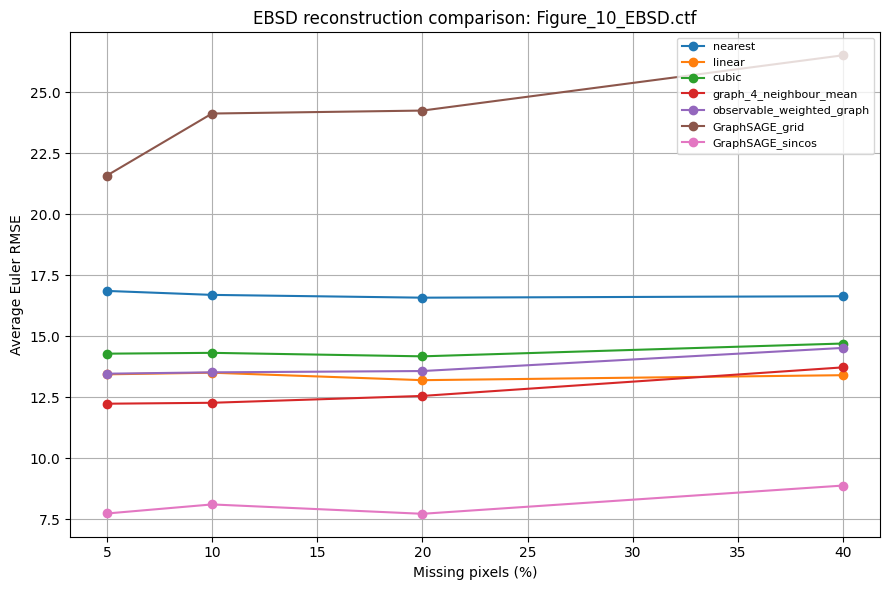

Saved: /content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/figures/Figure_10_EBSD_Average_Euler_RMSE_all_methods.png


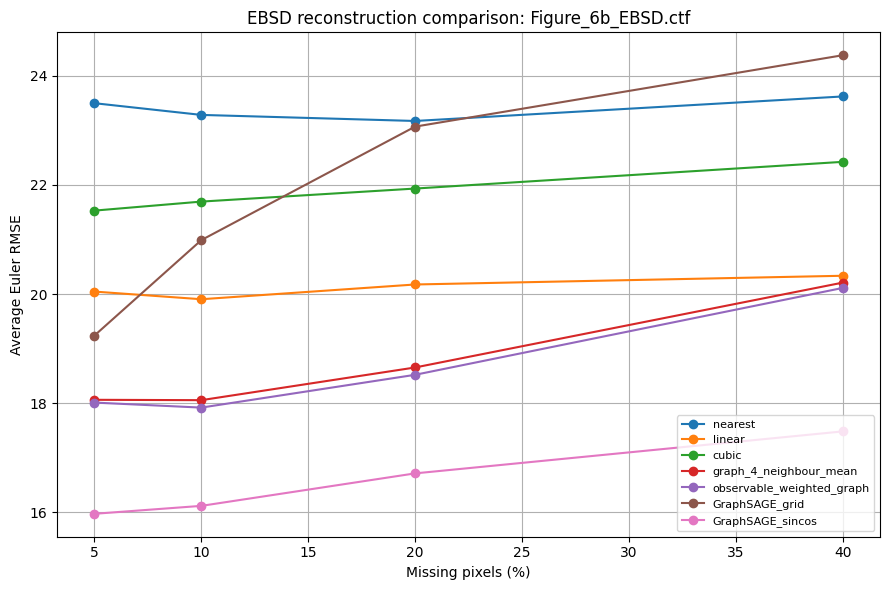

Saved: /content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/figures/Figure_6b_EBSD_Average_Euler_RMSE_all_methods.png

Saved summary notes:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison/Experiment_07C_summary_notes.txt

Experiment 7C completed.
Master results folder:
/content/drive/MyDrive/EBSD Paper2/results/experiment_07C_master_comparison


In [ ]:

# ============================================================
# Experiment 7C: Master comparison of all EBSD reconstruction methods
# Combines all previous CSV files and saves:
# - master table
# - best-method summary
# - manuscript-ready tables
# - comparison plots
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

OUTPUT_DIR = f"{PROJECT_DIR}/results/experiment_07C_master_comparison"
FIG_DIR = f"{OUTPUT_DIR}/figures"
TABLE_DIR = f"{OUTPUT_DIR}/tables"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

csv_files = {
    "classical_interpolation": f"{PROJECT_DIR}/results/experiment_01_missing_pixels/Experiment_01_missing_pixel_baselines_combined.csv",
    "graph_neighbour": f"{PROJECT_DIR}/results/experiment_02_graph_neighbour/Experiment_02_graph_neighbour_results.csv",
    "observable_weighted_graph": f"{PROJECT_DIR}/results/experiment_06_observable_weighted_graph/Experiment_06_observable_weighted_graph_results.csv",
    "graphsage_raw_euler": f"{PROJECT_DIR}/results/experiment_07_graphsage_reconstruction/Experiment_07_GraphSAGE_results.csv",
    "graphsage_sincos": f"{PROJECT_DIR}/results/experiment_07B_graphsage_sincos/Experiment_07B_GraphSAGE_sincos_results.csv"
}

frames = []

for source_name, path in csv_files.items():
    if os.path.exists(path):
        df = pd.read_csv(path)
        df["source"] = source_name
        frames.append(df)
        print(f"Loaded: {source_name}")
    else:
        print(f"Missing: {source_name}")
        print(path)

if len(frames) == 0:
    raise FileNotFoundError("No result CSV files were found.")

combined = pd.concat(frames, ignore_index=True)

required_rmse = ["Euler1_RMSE", "Euler2_RMSE", "Euler3_RMSE"]
required_mae = ["Euler1_MAE", "Euler2_MAE", "Euler3_MAE"]

for col in required_rmse + required_mae:
    if col not in combined.columns:
        combined[col] = pd.NA

combined["Average_Euler_RMSE"] = combined[required_rmse].mean(axis=1)
combined["Average_Euler_MAE"] = combined[required_mae].mean(axis=1)

preferred_cols = [
    "file", "crop_size", "valid_pixels", "missing_fraction", "missing_percent",
    "method", "source", "Average_Euler_RMSE", "Average_Euler_MAE",
    "Euler1_RMSE", "Euler2_RMSE", "Euler3_RMSE",
    "Euler1_MAE", "Euler2_MAE", "Euler3_MAE",
    "epochs", "learning_rate", "seed"
]

existing_cols = [c for c in preferred_cols if c in combined.columns]
remaining_cols = [c for c in combined.columns if c not in existing_cols]
combined = combined[existing_cols + remaining_cols]

master_csv = f"{OUTPUT_DIR}/Experiment_07C_master_all_methods.csv"
combined.to_csv(master_csv, index=False)
print("\nSaved master table:")
print(master_csv)
display(combined)

best_summary = (
    combined
    .dropna(subset=["Average_Euler_RMSE"])
    .sort_values("Average_Euler_RMSE")
    .groupby(["file", "missing_percent"])
    .first()
    .reset_index()
)

best_summary = best_summary[
    [
        "file", "missing_percent", "method", "source",
        "Average_Euler_RMSE", "Average_Euler_MAE",
        "Euler1_RMSE", "Euler2_RMSE", "Euler3_RMSE"
    ]
]

best_csv = f"{TABLE_DIR}/Experiment_07C_best_method_summary.csv"
best_summary.to_csv(best_csv, index=False)
print("\nSaved best-method summary:")
print(best_csv)
display(best_summary)

manuscript_table = combined[
    ["file", "crop_size", "missing_percent", "method", "Average_Euler_RMSE", "Average_Euler_MAE"]
].copy()

manuscript_table = manuscript_table.sort_values(
    ["file", "missing_percent", "Average_Euler_RMSE"]
)

manuscript_csv = f"{TABLE_DIR}/Experiment_07C_manuscript_table.csv"
manuscript_table.to_csv(manuscript_csv, index=False)
print("\nSaved manuscript table:")
print(manuscript_csv)
display(manuscript_table)

pivot_rmse = manuscript_table.pivot_table(
    index=["file", "crop_size", "missing_percent"],
    columns="method",
    values="Average_Euler_RMSE",
    aggfunc="mean"
).reset_index()

pivot_csv = f"{TABLE_DIR}/Experiment_07C_pivot_average_rmse.csv"
pivot_rmse.to_csv(pivot_csv, index=False)
print("\nSaved pivot RMSE table:")
print(pivot_csv)
display(pivot_rmse)

for file_name in combined["file"].dropna().unique():

    plt.figure(figsize=(9, 6))
    subset_file = combined[combined["file"] == file_name]

    for method in subset_file["method"].dropna().unique():
        subset = subset_file[subset_file["method"] == method].sort_values("missing_percent")
        if len(subset) == 0:
            continue

        plt.plot(
            subset["missing_percent"],
            subset["Average_Euler_RMSE"],
            marker="o",
            label=method
        )

    plt.xlabel("Missing pixels (%)")
    plt.ylabel("Average Euler RMSE")
    plt.title(f"EBSD reconstruction comparison: {file_name}")
    plt.legend(fontsize=8)
    plt.grid(True)
    plt.tight_layout()

    fig_path = f"{FIG_DIR}/{file_name.replace('.ctf','')}_Average_Euler_RMSE_all_methods.png"
    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()
    print("Saved:", fig_path)

for file_name in combined["file"].dropna().unique():

    for missing_percent in sorted(combined["missing_percent"].dropna().unique()):

        subset = combined[
            (combined["file"] == file_name) &
            (combined["missing_percent"] == missing_percent)
        ].dropna(subset=["Average_Euler_RMSE"])

        subset = subset.sort_values("Average_Euler_RMSE")

        if len(subset) == 0:
            continue

        plt.figure(figsize=(9, 5))
        plt.bar(subset["method"], subset["Average_Euler_RMSE"])
        plt.ylabel("Average Euler RMSE")
        plt.title(f"{file_name}, {int(missing_percent)}% missing")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        fig_path = f"{FIG_DIR}/{file_name.replace('.ctf','')}_missing_{int(missing_percent)}_method_ranking.png"
        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

summary_txt = f"{OUTPUT_DIR}/Experiment_07C_summary_notes.txt"

with open(summary_txt, "w") as f:
    f.write("Experiment 7C Master Comparison\n")
    f.write("================================\n\n")
    f.write(f"Total rows combined: {len(combined)}\n\n")
    f.write("Best method by dataset and missing level:\n")
    f.write(best_summary.to_string(index=False))
    f.write("\n\nNotes:\n")
    f.write("- GraphSAGE_sincos used 256x256 crops, while some earlier baselines used 512x512 crops.\n")
    f.write("- For final manuscript fairness, rerun strongest baselines on the same crop size as GraphSAGE, or rerun GraphSAGE on 512x512 if compute permits.\n")
    f.write("- Avoid using the earlier optimistic weighted graph as final evidence because it used true orientation information for weighting.\n")

print("\nSaved summary notes:")
print(summary_txt)

print("\nExperiment 7C completed.")
print("Master results folder:")
print(OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf
Grid shape: (256, 256)
Valid pixels: 63940

Missing level: 5%
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Missing level: 10%
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Missing level: 20%
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Missing level: 40%
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Processing: Figure_6b_EBSD.ctf
Grid shape: (256, 256)
Valid pixels: 59548

Missing level: 5%
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Missing level: 10%
  M

,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,seed,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE,sigma_bc,sigma_mad,phase_bonus
0,Figure_10_EBSD.ctf,256x256,63940,0.05,5,nearest,42,5.289198,16.713253,0.987960,3.553247,4.565644,10.431119,10.232540,3.614267,NaN,NaN,NaN
1,Figure_10_EBSD.ctf,256x256,63940,0.05,5,linear,42,4.855142,14.142162,0.879251,2.677450,3.938943,8.354013,8.391208,3.224445,NaN,NaN,NaN
2,Figure_10_EBSD.ctf,256x256,63940,0.05,5,cubic,42,5.673292,14.829984,1.040235,2.800168,4.323786,9.009292,8.879814,3.679105,NaN,NaN,NaN
3,Figure_10_EBSD.ctf,256x256,63940,0.05,5,graph_4_neighbour_mean,42,4.714897,13.481022,0.850553,2.523809,3.645463,7.682440,7.895757,3.070304,NaN,NaN,NaN
4,Figure_10_EBSD.ctf,256x256,63940,0.05,5,observable_weighted_graph,42,5.036518,15.726315,0.878702,2.795236,3.788917,8.098624,8.873391,3.234712,25.0,1.0,2.0
5,Figure_10_EBSD.ctf,256x256,63940,0.10,10,nearest,42,5.445822,18.062719,1.066180,4.196054,4.579021,10.770019,11.009597,3.697008,NaN,NaN,NaN
6,Figure_10_EBSD.ctf,256x256,63940,0.10,10,linear,42,5.064540,15.209762,0.923856,2.866466,4.047455,8.869132,8.981787,3.345283,NaN,NaN,NaN
7,Figure_10_EBSD.ctf,256x256,63940,0.10,10,cubic,42,5.730590,15.382392,1.067114,2.881041,4.458422,9.686451,9.316628,3.752042,NaN,NaN,NaN
8,Figure_10_EBSD.ctf,256x256,63940,0.10,10,graph_4_neighbour_mean,42,4.732472,13.753790,0.873711,2.648021,3.777054,8.223950,8.208587,3.127746,NaN,NaN,NaN
9,Figure_10_EBSD.ctf,256x256,63940,0.10,10,observable_weighted_graph,42,4.970174,15.402006,0.891757,2.920538,3.938572,8.738736,9.020427,3.266834,25.0,1.0,2.0


Combined comparison saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_08A_256_baseline_rerun/Experiment_08A_256_baselines_plus_GraphSAGE_sincos.csv
Best method summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_08A_256_baseline_rerun/tables/Experiment_08A_best_method_256_comparison.csv


,file,missing_percent,method,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,5,GraphSAGE_sincos,7.733391,3.740412
1,Figure_10_EBSD.ctf,10,GraphSAGE_sincos,8.105031,3.648206
2,Figure_10_EBSD.ctf,20,GraphSAGE_sincos,7.720959,3.739468
3,Figure_10_EBSD.ctf,40,GraphSAGE_sincos,8.879602,4.507407
4,Figure_6b_EBSD.ctf,5,GraphSAGE_sincos,15.973981,4.815251
5,Figure_6b_EBSD.ctf,10,GraphSAGE_sincos,16.119236,5.048368
6,Figure_6b_EBSD.ctf,20,GraphSAGE_sincos,16.714266,5.297912
7,Figure_6b_EBSD.ctf,40,GraphSAGE_sincos,17.483013,6.110265


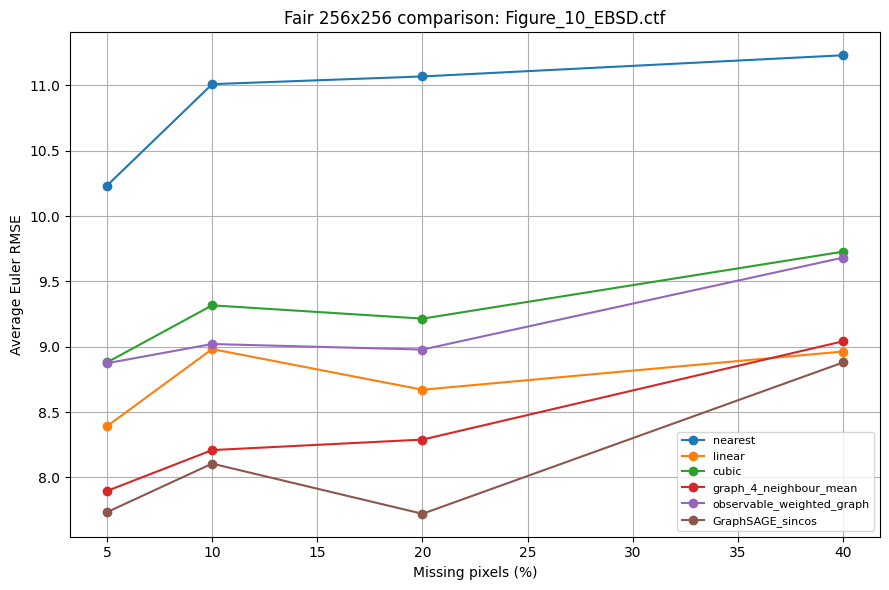

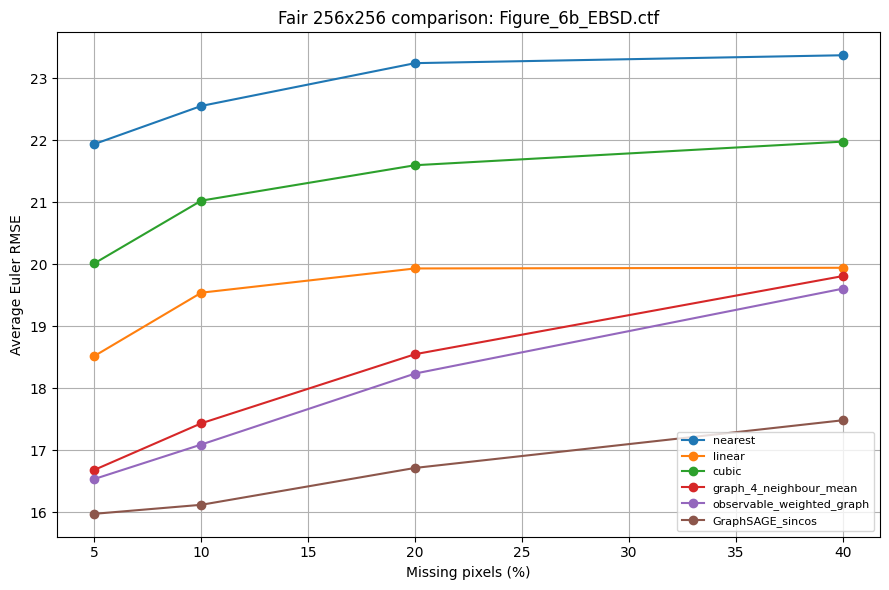

In [ ]:

# ============================================================
# Experiment 8A: Fair 256x256 baseline rerun
# Purpose:
# Rerun classical interpolation and graph baselines on 256x256 crops,
# so they can be compared fairly with GraphSAGE_sincos.
#
# Methods:
# - nearest
# - linear
# - cubic
# - graph_4_neighbour_mean
# - observable_weighted_graph
#
# Outputs saved to Google Drive:
# - CSV results
# - figures
# - comparison plots
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_08A_256_baseline_rerun"
FIG_DIR = f"{RESULTS_DIR}/figures"
TABLE_DIR = f"{RESULTS_DIR}/tables"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

CTF_FILES = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

# ------------------------------------------------------------
# 2. CTF reader and preprocessing
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0

    return maps, valid_mask

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)

    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)

    chosen = candidates[selected]

    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

# ------------------------------------------------------------
# 3. Metrics
# ------------------------------------------------------------

def compute_metrics(original, reconstructed, missing_mask):
    y_true = original[missing_mask]
    y_pred = reconstructed[missing_mask]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    mae = mean_absolute_error(y_true[valid], y_pred[valid])
    rmse = np.sqrt(mean_squared_error(y_true[valid], y_pred[valid]))

    return mae, rmse

def compute_all_euler_metrics(maps, reconstructed_maps, missing_mask):
    row = {}

    for col in ["Euler1", "Euler2", "Euler3"]:
        mae, rmse = compute_metrics(
            maps[col],
            reconstructed_maps[col],
            missing_mask
        )

        row[f"{col}_MAE"] = mae
        row[f"{col}_RMSE"] = rmse

    row["Average_Euler_RMSE"] = np.mean([
        row["Euler1_RMSE"],
        row["Euler2_RMSE"],
        row["Euler3_RMSE"]
    ])

    row["Average_Euler_MAE"] = np.mean([
        row["Euler1_MAE"],
        row["Euler2_MAE"],
        row["Euler3_MAE"]
    ])

    return row

# ------------------------------------------------------------
# 4. Classical interpolation
# ------------------------------------------------------------

def interpolate_grid(original_grid, valid_mask, missing_mask, method="nearest"):
    yy, xx = np.indices(original_grid.shape)

    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

# ------------------------------------------------------------
# 5. Graph neighbour mean
# ------------------------------------------------------------

def graph_neighbour_mean_reconstruct(original_grid, valid_mask, missing_mask, max_iters=20):
    reconstructed = original_grid.copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            neighbours = []

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])

            if len(neighbours) > 0:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])

    return reconstructed

# ------------------------------------------------------------
# 6. Observable weighted graph
# ------------------------------------------------------------

def observable_weighted_graph_reconstruct(
    target_grid,
    valid_mask,
    missing_mask,
    phase_grid,
    bc_grid,
    mad_grid,
    sigma_bc=25.0,
    sigma_mad=1.0,
    phase_bonus=2.0,
    max_iters=20
):
    reconstructed = target_grid.copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            values = []
            weights = []

            center_phase = phase_grid[r, c]
            center_bc = bc_grid[r, c]
            center_mad = mad_grid[r, c]

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:

                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):

                        neighbour_phase = phase_grid[rr, cc]
                        neighbour_bc = bc_grid[rr, cc]
                        neighbour_mad = mad_grid[rr, cc]

                        w_phase = phase_bonus if center_phase == neighbour_phase else 1.0
                        w_bc = np.exp(-abs(center_bc - neighbour_bc) / sigma_bc)
                        w_mad = np.exp(-abs(center_mad - neighbour_mad) / sigma_mad)

                        weight = w_phase * w_bc * w_mad

                        values.append(reconstructed[rr, cc])
                        weights.append(weight)

            if len(values) > 0:
                values = np.array(values)
                weights = np.array(weights)

                if weights.sum() > 0:
                    new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights)
                else:
                    new_reconstructed[r, c] = np.mean(values)

                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])

    return reconstructed

# ------------------------------------------------------------
# 7. Run Experiment 8A
# ------------------------------------------------------------

crop_size = 256
missing_levels = [0.05, 0.10, 0.20, 0.40]
seed = 42

classical_methods = ["nearest", "linear", "cubic"]

all_results = []

for ctf_file in CTF_FILES:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    maps, valid_mask = prepare_crop(ctf_file, crop_size=crop_size)

    print("Grid shape:", maps["Euler1"].shape)
    print("Valid pixels:", int(valid_mask.sum()))

    for missing_fraction in missing_levels:

        print(f"\nMissing level: {int(missing_fraction * 100)}%")

        missing_mask = create_missing_mask(
            valid_mask=valid_mask,
            missing_fraction=missing_fraction,
            seed=seed
        )

        # ----------------------------------------------------
        # Classical interpolation methods
        # ----------------------------------------------------

        for method in classical_methods:

            print("  Method:", method)

            reconstructed_maps = {}

            for col in ["Euler1", "Euler2", "Euler3"]:
                reconstructed_maps[col] = interpolate_grid(
                    original_grid=maps[col],
                    valid_mask=valid_mask,
                    missing_mask=missing_mask,
                    method=method
                )

            row = {
                "file": ctf_file,
                "crop_size": f"{crop_size}x{crop_size}",
                "valid_pixels": int(valid_mask.sum()),
                "missing_fraction": missing_fraction,
                "missing_percent": int(missing_fraction * 100),
                "method": method,
                "seed": seed
            }

            row.update(compute_all_euler_metrics(maps, reconstructed_maps, missing_mask))
            all_results.append(row)

        # ----------------------------------------------------
        # Graph neighbour mean
        # ----------------------------------------------------

        print("  Method: graph_4_neighbour_mean")

        reconstructed_maps = {}

        for col in ["Euler1", "Euler2", "Euler3"]:
            reconstructed_maps[col] = graph_neighbour_mean_reconstruct(
                original_grid=maps[col],
                valid_mask=valid_mask,
                missing_mask=missing_mask,
                max_iters=20
            )

        row = {
            "file": ctf_file,
            "crop_size": f"{crop_size}x{crop_size}",
            "valid_pixels": int(valid_mask.sum()),
            "missing_fraction": missing_fraction,
            "missing_percent": int(missing_fraction * 100),
            "method": "graph_4_neighbour_mean",
            "seed": seed
        }

        row.update(compute_all_euler_metrics(maps, reconstructed_maps, missing_mask))
        all_results.append(row)

        # Save example figure for graph mean
        corrupted_euler1 = maps["Euler1"].copy()
        corrupted_euler1[missing_mask] = np.nan

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_euler1, cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title("Graph neighbour mean")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_{crop_size}_missing_{int(missing_fraction*100)}_graph_mean_Euler1.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

        # ----------------------------------------------------
        # Observable weighted graph
        # ----------------------------------------------------

        print("  Method: observable_weighted_graph")

        reconstructed_maps = {}

        for col in ["Euler1", "Euler2", "Euler3"]:
            reconstructed_maps[col] = observable_weighted_graph_reconstruct(
                target_grid=maps[col],
                valid_mask=valid_mask,
                missing_mask=missing_mask,
                phase_grid=maps["Phase"],
                bc_grid=maps["BC"],
                mad_grid=maps["MAD"],
                sigma_bc=25.0,
                sigma_mad=1.0,
                phase_bonus=2.0,
                max_iters=20
            )

        row = {
            "file": ctf_file,
            "crop_size": f"{crop_size}x{crop_size}",
            "valid_pixels": int(valid_mask.sum()),
            "missing_fraction": missing_fraction,
            "missing_percent": int(missing_fraction * 100),
            "method": "observable_weighted_graph",
            "seed": seed,
            "sigma_bc": 25.0,
            "sigma_mad": 1.0,
            "phase_bonus": 2.0
        }

        row.update(compute_all_euler_metrics(maps, reconstructed_maps, missing_mask))
        all_results.append(row)

        # Save example figure for observable weighted graph
        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(corrupted_euler1, cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction * 100)}% Missing")

        axes[2].imshow(reconstructed_maps["Euler1"], cmap="viridis")
        axes[2].set_title("Observable weighted graph")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_{crop_size}_missing_{int(missing_fraction*100)}_observable_weighted_Euler1.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

        # Save in-progress results after each missing level
        pd.DataFrame(all_results).to_csv(
            os.path.join(RESULTS_DIR, "Experiment_08A_256_baseline_rerun_IN_PROGRESS.csv"),
            index=False
        )

# ------------------------------------------------------------
# 8. Save final results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_08A_256_baseline_rerun_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 8A completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

# ------------------------------------------------------------
# 9. Compare 256x256 baselines against GraphSAGE_sincos
# ------------------------------------------------------------

graphsage_csv = f"{PROJECT_DIR}/results/experiment_07B_graphsage_sincos/Experiment_07B_GraphSAGE_sincos_results.csv"

if os.path.exists(graphsage_csv):

    graphsage_df = pd.read_csv(graphsage_csv)

    combined = pd.concat([results_df, graphsage_df], ignore_index=True)

    combined_csv = os.path.join(
        RESULTS_DIR,
        "Experiment_08A_256_baselines_plus_GraphSAGE_sincos.csv"
    )

    combined.to_csv(combined_csv, index=False)

    print("Combined comparison saved to:", combined_csv)

    # Best method summary
    best = (
        combined
        .sort_values("Average_Euler_RMSE")
        .groupby(["file", "missing_percent"])
        .first()
        .reset_index()
    )

    best_csv = os.path.join(
        TABLE_DIR,
        "Experiment_08A_best_method_256_comparison.csv"
    )

    best.to_csv(best_csv, index=False)

    print("Best method summary saved to:", best_csv)

    display(best[
        [
            "file",
            "missing_percent",
            "method",
            "Average_Euler_RMSE",
            "Average_Euler_MAE"
        ]
    ])

    # Plot comparison
    for ctf_file in CTF_FILES:

        plt.figure(figsize=(9, 6))

        subset_file = combined[combined["file"] == ctf_file]

        for method in subset_file["method"].unique():

            subset = subset_file[
                subset_file["method"] == method
            ].sort_values("missing_percent")

            plt.plot(
                subset["missing_percent"],
                subset["Average_Euler_RMSE"],
                marker="o",
                label=method
            )

        plt.xlabel("Missing pixels (%)")
        plt.ylabel("Average Euler RMSE")
        plt.title(f"Fair 256x256 comparison: {ctf_file}")
        plt.grid(True)
        plt.legend(fontsize=8)
        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_fair_256_comparison_all_methods.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.show()

else:
    print("GraphSAGE sin/cos results not found. Skipping combined comparison.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf

Noise level: 0.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 2.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 5.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 10.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Processing: Figure_6b_EBSD.ctf

Noise level: 0.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 2.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 5.0 degrees
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Noise level: 10.0 deg

,file,crop_size,valid_pixels,missing_fraction,missing_percent,noise_std_deg,method,seed,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,256x256,63940,0.2,20,0.0,linear,42,4.890159,13.256402,0.916951,2.827063,4.069548,8.919584,8.334350,3.292219
1,Figure_10_EBSD.ctf,256x256,63940,0.2,20,0.0,graph_4_neighbour_mean,42,4.698243,12.813210,0.863407,2.691407,3.886246,8.556217,8.020278,3.149299
2,Figure_10_EBSD.ctf,256x256,63940,0.2,20,0.0,observable_weighted_graph,42,4.839139,14.149882,0.873865,2.936410,4.043423,9.151594,8.745962,3.252143
3,Figure_10_EBSD.ctf,256x256,63940,0.2,20,2.0,linear,42,5.218481,13.546405,4.078751,20.885531,4.677284,11.493184,15.308373,4.658172
4,Figure_10_EBSD.ctf,256x256,63940,0.2,20,2.0,graph_4_neighbour_mean,42,4.923716,12.848050,3.922522,18.208304,4.374441,10.547103,13.867819,4.406893
5,Figure_10_EBSD.ctf,256x256,63940,0.2,20,2.0,observable_weighted_graph,42,5.156365,14.191420,3.479120,15.913453,4.550152,10.507985,13.537619,4.395212
6,Figure_10_EBSD.ctf,256x256,63940,0.2,20,5.0,linear,42,6.232763,14.000850,17.420027,49.756365,6.013175,13.965196,25.907470,9.888655
7,Figure_10_EBSD.ctf,256x256,63940,0.2,20,5.0,graph_4_neighbour_mean,42,5.761996,13.351166,17.479200,44.519340,5.468900,12.590131,23.486879,9.570032
8,Figure_10_EBSD.ctf,256x256,63940,0.2,20,5.0,observable_weighted_graph,42,6.254901,14.659667,13.536176,36.840002,5.870414,12.669938,21.389869,8.553831
9,Figure_10_EBSD.ctf,256x256,63940,0.2,20,10.0,linear,42,8.580159,16.289653,35.392488,71.728763,9.836709,22.646340,36.888252,17.936452


Best method summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_09_noise_robustness/tables/Experiment_09_best_method_by_noise_level.csv


,file,noise_std_deg,method,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,0.0,graph_4_neighbour_mean,8.020278,3.149299
1,Figure_10_EBSD.ctf,2.0,observable_weighted_graph,13.537619,4.395212
2,Figure_10_EBSD.ctf,5.0,observable_weighted_graph,21.389869,8.553831
3,Figure_10_EBSD.ctf,10.0,observable_weighted_graph,29.928780,15.231880
4,Figure_6b_EBSD.ctf,0.0,observable_weighted_graph,17.378550,4.902434
5,Figure_6b_EBSD.ctf,2.0,observable_weighted_graph,22.197578,6.807426
6,Figure_6b_EBSD.ctf,5.0,observable_weighted_graph,30.247583,11.177320
7,Figure_6b_EBSD.ctf,10.0,observable_weighted_graph,42.422315,21.720424


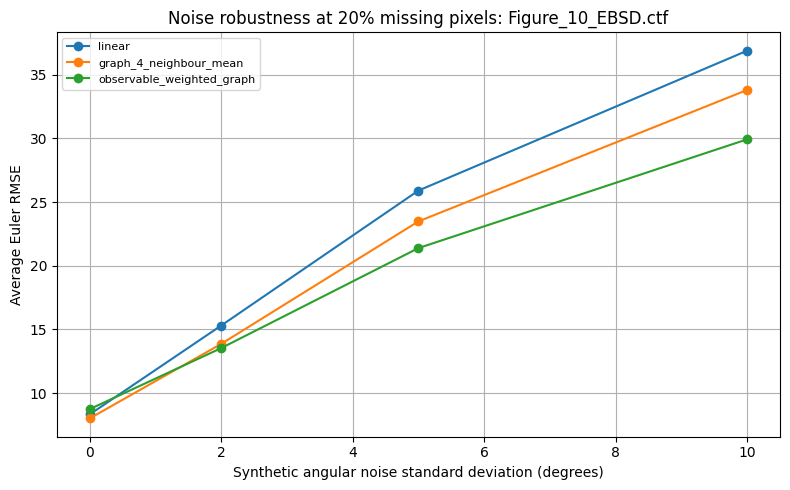

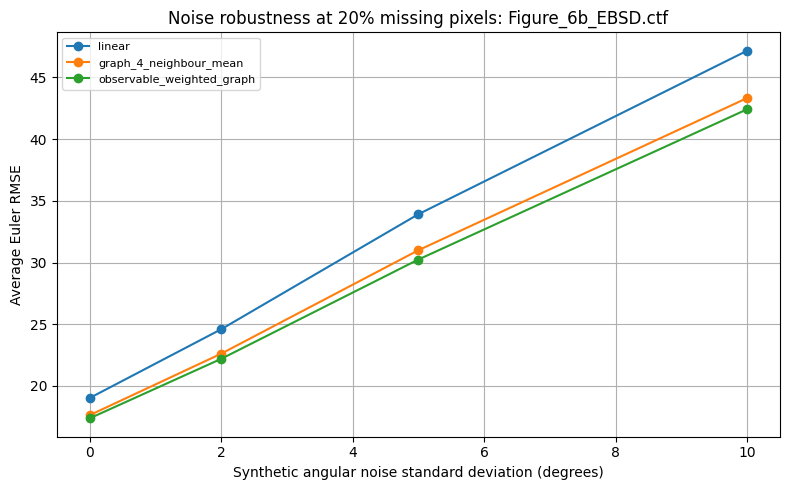

In [ ]:

# ============================================================
# Experiment 09: Noise robustness for EBSD reconstruction
# Purpose:
# Test how reconstruction methods behave when EBSD orientation maps
# contain additional synthetic angular noise.
#
# Methods:
# - linear interpolation
# - graph_4_neighbour_mean
# - observable_weighted_graph
# - GraphSAGE_sincos baseline loaded from previous results for comparison
#
# Noise levels:
# - 0°, 2°, 5°, 10° Gaussian angular perturbation
#
# Outputs saved to Google Drive:
# - CSV results
# - figures
# - comparison plots
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_09_noise_robustness"
FIG_DIR = f"{RESULTS_DIR}/figures"
TABLE_DIR = f"{RESULTS_DIR}/tables"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

CTF_FILES = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

# ------------------------------------------------------------
# 2. CTF reader and preprocessing
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0

    return maps, valid_mask

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)

    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)

    chosen = candidates[selected]

    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True

    return mask

# ------------------------------------------------------------
# 3. Noise and angular metrics
# ------------------------------------------------------------

def add_angular_noise(maps, valid_mask, noise_std_deg=0.0, seed=42):
    """
    Adds Gaussian angular noise to valid EBSD orientations.

    This is a simple perturbation of Euler angles and should be
    described as a controlled synthetic-noise test, not a full
    crystallographic noise model.
    """

    rng = np.random.default_rng(seed)

    noisy_maps = {k: np.copy(v) for k, v in maps.items()}

    for col in ["Euler1", "Euler2", "Euler3"]:
        noise = rng.normal(
            loc=0.0,
            scale=noise_std_deg,
            size=noisy_maps[col].shape
        )

        noisy_maps[col][valid_mask] = np.mod(
            noisy_maps[col][valid_mask] + noise[valid_mask],
            360.0
        )

    return noisy_maps

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_metrics(original, reconstructed, missing_mask):
    err = angular_error_deg(original, reconstructed)
    values = err[missing_mask]
    values = values[np.isfinite(values)]

    mae = np.mean(values)
    rmse = np.sqrt(np.mean(values ** 2))

    return mae, rmse

def compute_all_euler_metrics(clean_maps, reconstructed_maps, missing_mask):
    """
    Reconstruction is performed from noisy inputs, but metrics are
    computed against the original clean EBSD map.
    """

    row = {}

    for col in ["Euler1", "Euler2", "Euler3"]:
        mae, rmse = compute_metrics(
            clean_maps[col],
            reconstructed_maps[col],
            missing_mask
        )

        row[f"{col}_MAE"] = mae
        row[f"{col}_RMSE"] = rmse

    row["Average_Euler_RMSE"] = np.mean([
        row["Euler1_RMSE"],
        row["Euler2_RMSE"],
        row["Euler3_RMSE"]
    ])

    row["Average_Euler_MAE"] = np.mean([
        row["Euler1_MAE"],
        row["Euler2_MAE"],
        row["Euler3_MAE"]
    ])

    return row

# ------------------------------------------------------------
# 4. Reconstruction methods
# ------------------------------------------------------------

def interpolate_grid(original_grid, valid_mask, missing_mask, method="linear"):
    yy, xx = np.indices(original_grid.shape)

    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

def graph_neighbour_mean_reconstruct(original_grid, valid_mask, missing_mask, max_iters=20):
    reconstructed = original_grid.copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            neighbours = []

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])

            if len(neighbours) > 0:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])

    return reconstructed

def observable_weighted_graph_reconstruct(
    target_grid,
    valid_mask,
    missing_mask,
    phase_grid,
    bc_grid,
    mad_grid,
    sigma_bc=25.0,
    sigma_mad=1.0,
    phase_bonus=2.0,
    max_iters=20
):
    reconstructed = target_grid.copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            values = []
            weights = []

            center_phase = phase_grid[r, c]
            center_bc = bc_grid[r, c]
            center_mad = mad_grid[r, c]

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:

                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):

                        neighbour_phase = phase_grid[rr, cc]
                        neighbour_bc = bc_grid[rr, cc]
                        neighbour_mad = mad_grid[rr, cc]

                        w_phase = phase_bonus if center_phase == neighbour_phase else 1.0
                        w_bc = np.exp(-abs(center_bc - neighbour_bc) / sigma_bc)
                        w_mad = np.exp(-abs(center_mad - neighbour_mad) / sigma_mad)

                        weight = w_phase * w_bc * w_mad

                        values.append(reconstructed[rr, cc])
                        weights.append(weight)

            if len(values) > 0:
                values = np.array(values)
                weights = np.array(weights)

                if weights.sum() > 0:
                    new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights)
                else:
                    new_reconstructed[r, c] = np.mean(values)

                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])

    return reconstructed

# ------------------------------------------------------------
# 5. Run Experiment 09
# ------------------------------------------------------------

crop_size = 256
missing_fraction = 0.20   # controlled standard condition for robustness test
seed = 42

noise_levels = [0.0, 2.0, 5.0, 10.0]
methods = ["linear", "graph_4_neighbour_mean", "observable_weighted_graph"]

all_results = []

for ctf_file in CTF_FILES:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    clean_maps, valid_mask = prepare_crop(ctf_file, crop_size=crop_size)

    missing_mask = create_missing_mask(
        valid_mask=valid_mask,
        missing_fraction=missing_fraction,
        seed=seed
    )

    for noise_std in noise_levels:

        print(f"\nNoise level: {noise_std} degrees")

        noisy_maps = add_angular_noise(
            clean_maps,
            valid_mask=valid_mask,
            noise_std_deg=noise_std,
            seed=seed
        )

        for method in methods:

            print("  Method:", method)

            reconstructed_maps = {}

            for col in ["Euler1", "Euler2", "Euler3"]:

                if method == "linear":
                    reconstructed_maps[col] = interpolate_grid(
                        original_grid=noisy_maps[col],
                        valid_mask=valid_mask,
                        missing_mask=missing_mask,
                        method="linear"
                    )

                elif method == "graph_4_neighbour_mean":
                    reconstructed_maps[col] = graph_neighbour_mean_reconstruct(
                        original_grid=noisy_maps[col],
                        valid_mask=valid_mask,
                        missing_mask=missing_mask,
                        max_iters=20
                    )

                elif method == "observable_weighted_graph":
                    reconstructed_maps[col] = observable_weighted_graph_reconstruct(
                        target_grid=noisy_maps[col],
                        valid_mask=valid_mask,
                        missing_mask=missing_mask,
                        phase_grid=clean_maps["Phase"],
                        bc_grid=clean_maps["BC"],
                        mad_grid=clean_maps["MAD"],
                        sigma_bc=25.0,
                        sigma_mad=1.0,
                        phase_bonus=2.0,
                        max_iters=20
                    )

            row = {
                "file": ctf_file,
                "crop_size": f"{crop_size}x{crop_size}",
                "valid_pixels": int(valid_mask.sum()),
                "missing_fraction": missing_fraction,
                "missing_percent": int(missing_fraction * 100),
                "noise_std_deg": noise_std,
                "method": method,
                "seed": seed
            }

            row.update(
                compute_all_euler_metrics(
                    clean_maps,
                    reconstructed_maps,
                    missing_mask
                )
            )

            all_results.append(row)

        # Save a visual example for this noise level
        corrupted = noisy_maps["Euler1"].copy()
        corrupted[missing_mask] = np.nan

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))

        axes[0].imshow(clean_maps["Euler1"], cmap="viridis")
        axes[0].set_title("Clean Euler1")

        axes[1].imshow(corrupted, cmap="viridis")
        axes[1].set_title(f"Noisy + 20% missing\nNoise={noise_std}°")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_noise_{int(noise_std)}deg_input_example.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

        pd.DataFrame(all_results).to_csv(
            os.path.join(RESULTS_DIR, "Experiment_09_noise_robustness_IN_PROGRESS.csv"),
            index=False
        )

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_09_noise_robustness_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 09 completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

# ------------------------------------------------------------
# 7. Summary table and plots
# ------------------------------------------------------------

summary = (
    results_df
    .sort_values("Average_Euler_RMSE")
    .groupby(["file", "noise_std_deg"])
    .first()
    .reset_index()
)

summary_csv = os.path.join(
    TABLE_DIR,
    "Experiment_09_best_method_by_noise_level.csv"
)

summary.to_csv(summary_csv, index=False)

print("Best method summary saved to:", summary_csv)

display(summary[
    [
        "file",
        "noise_std_deg",
        "method",
        "Average_Euler_RMSE",
        "Average_Euler_MAE"
    ]
])

for ctf_file in CTF_FILES:

    subset_file = results_df[results_df["file"] == ctf_file]

    plt.figure(figsize=(8, 5))

    for method in methods:
        subset = subset_file[subset_file["method"] == method].sort_values("noise_std_deg")

        plt.plot(
            subset["noise_std_deg"],
            subset["Average_Euler_RMSE"],
            marker="o",
            label=method
        )

    plt.xlabel("Synthetic angular noise standard deviation (degrees)")
    plt.ylabel("Average Euler RMSE")
    plt.title(f"Noise robustness at 20% missing pixels: {ctf_file}")
    plt.grid(True)
    plt.legend(fontsize=8)
    plt.tight_layout()

    fig_path = os.path.join(
        FIG_DIR,
        f"{ctf_file.replace('.ctf','')}_noise_robustness_RMSE.png"
    )

    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing: Figure_10_EBSD.ctf
Grid shape: (256, 256)
Valid pixels: 63940

Sparse factor: 2x
Known pixels: 15999
Reconstructed pixels: 47941
Known fraction: 0.2502
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Sparse factor: 4x
Known pixels: 3980
Reconstructed pixels: 59960
Known fraction: 0.0622
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Sparse factor: 8x
Known pixels: 992
Reconstructed pixels: 62948
Known fraction: 0.0155
  Method: nearest
  Method: linear
  Method: cubic
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph

Processing: Figure_6b_EBSD.ctf
Grid shape: (256, 256)
Valid pixels: 59548

Sparse factor: 2x
Known pixels: 14867
Reconstructed pixels: 44681
Known fraction: 0.2497
  Me

,file,crop_size,valid_pixels,sparse_factor,known_pixels,reconstructed_pixels,known_fraction,reconstructed_fraction,method,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,nearest,5.538949,16.440118,1.071947,4.135761,4.711463,10.895908,10.490596,3.774120
1,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,linear,5.140175,14.070803,0.981939,3.072917,4.167903,9.171414,8.771711,3.430006
2,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,cubic,5.664174,14.427458,1.099844,3.117181,4.428646,9.555935,9.033525,3.730888
3,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,graph_4_neighbour_mean,4.974658,13.625883,0.935960,2.919617,4.050295,8.918567,8.488022,3.320304
4,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,observable_weighted_graph,5.086192,14.391390,0.949048,3.202910,4.230716,9.547600,9.047300,3.421985
5,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,nearest,6.619933,19.594727,1.297266,4.817808,5.168925,11.450726,11.954420,4.362041
6,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,linear,6.690490,17.379404,1.348645,3.883574,4.803114,10.022416,10.428465,4.280750
7,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,cubic,7.304135,17.777400,1.505557,3.969946,5.080870,10.465367,10.737571,4.630188
8,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,graph_4_neighbour_mean,6.392906,18.192478,1.213560,4.119130,4.851631,10.555814,10.955807,4.152699
9,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,observable_weighted_graph,6.456240,18.664933,1.230818,4.288319,4.927324,10.789607,11.247620,4.204794


Best method summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_10_super_resolution/tables/Experiment_10_best_method_by_sparse_factor.csv


,file,sparse_factor,known_fraction,method,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,2,0.250219,graph_4_neighbour_mean,8.488022,3.320304
1,Figure_10_EBSD.ctf,4,0.062246,linear,10.428465,4.280750
2,Figure_10_EBSD.ctf,8,0.015515,linear,12.764074,5.586568
3,Figure_6b_EBSD.ctf,2,0.249664,observable_weighted_graph,17.918007,5.073911
4,Figure_6b_EBSD.ctf,4,0.062403,graph_4_neighbour_mean,22.091780,6.573132
5,Figure_6b_EBSD.ctf,8,0.015500,linear,28.792568,15.708994


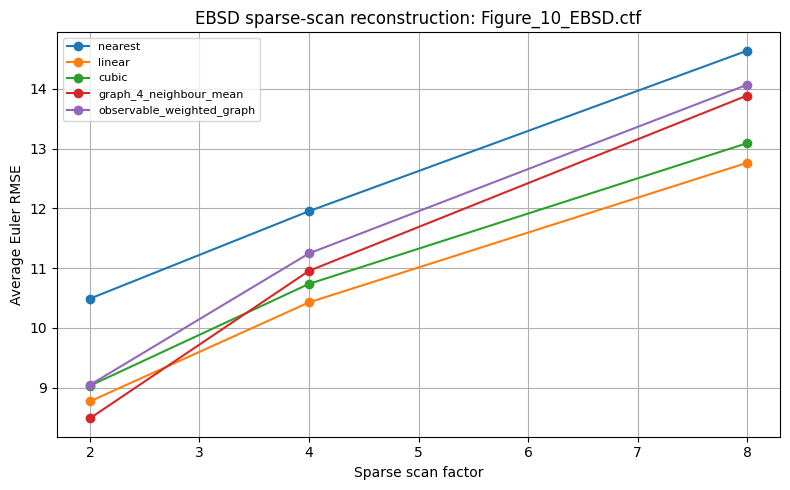

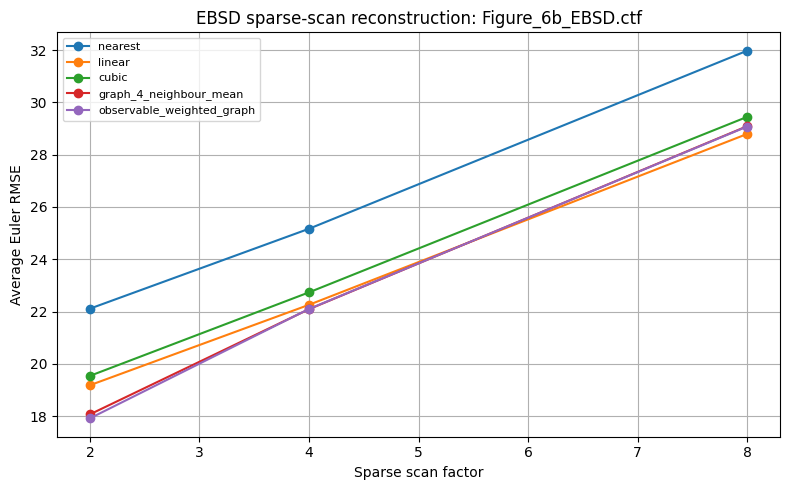

Saved notes: /content/drive/MyDrive/EBSD Paper2/results/experiment_10_super_resolution/Experiment_10_notes.txt


In [ ]:

# ============================================================
# Experiment 10: EBSD Super-Resolution / Sparse-Scan Reconstruction
# Purpose:
# Simulate faster EBSD acquisition by keeping only sparse indexed pixels
# and reconstructing the dense 256x256 orientation map.
#
# Methods:
# - nearest
# - linear
# - cubic
# - graph_4_neighbour_mean
# - observable_weighted_graph
#
# Sparse sampling factors:
# - 2x sparse scan: keep every 2nd pixel
# - 4x sparse scan: keep every 4th pixel
# - 8x sparse scan: keep every 8th pixel
#
# Outputs saved to Google Drive:
# - CSV results
# - figures
# - best-method summary
# - comparison plots
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_10_super_resolution"
FIG_DIR = f"{RESULTS_DIR}/figures"
TABLE_DIR = f"{RESULTS_DIR}/tables"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

CTF_FILES = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

# ------------------------------------------------------------
# 2. CTF reader and preprocessing
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0

    return maps, valid_mask

# ------------------------------------------------------------
# 3. Sparse scan simulation
# ------------------------------------------------------------

def create_sparse_scan_mask(valid_mask, factor=2):
    """
    Simulates sparse EBSD acquisition.

    factor=2 keeps every 2nd row and column.
    factor=4 keeps every 4th row and column.
    factor=8 keeps every 8th row and column.

    known_mask = pixels acquired in the sparse scan
    target_mask = valid pixels not acquired and therefore reconstructed
    """

    sparse_known = np.zeros(valid_mask.shape, dtype=bool)
    sparse_known[::factor, ::factor] = True

    known_mask = valid_mask & sparse_known
    target_mask = valid_mask & (~sparse_known)

    return known_mask, target_mask

# ------------------------------------------------------------
# 4. Angular metrics
# ------------------------------------------------------------

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_metrics(original, reconstructed, target_mask):
    err = angular_error_deg(original, reconstructed)
    values = err[target_mask]
    values = values[np.isfinite(values)]

    mae = np.mean(values)
    rmse = np.sqrt(np.mean(values ** 2))

    return mae, rmse

def compute_all_euler_metrics(maps, reconstructed_maps, target_mask):
    row = {}

    for col in ["Euler1", "Euler2", "Euler3"]:
        mae, rmse = compute_metrics(
            maps[col],
            reconstructed_maps[col],
            target_mask
        )

        row[f"{col}_MAE"] = mae
        row[f"{col}_RMSE"] = rmse

    row["Average_Euler_RMSE"] = np.mean([
        row["Euler1_RMSE"],
        row["Euler2_RMSE"],
        row["Euler3_RMSE"]
    ])

    row["Average_Euler_MAE"] = np.mean([
        row["Euler1_MAE"],
        row["Euler2_MAE"],
        row["Euler3_MAE"]
    ])

    return row

# ------------------------------------------------------------
# 5. Reconstruction methods
# ------------------------------------------------------------

def interpolate_sparse_grid(original_grid, valid_mask, known_mask, target_mask, method="linear"):
    yy, xx = np.indices(original_grid.shape)

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()
    reconstructed[target_mask] = np.nan

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

    return reconstructed

def graph_neighbour_mean_reconstruct(original_grid, valid_mask, known_mask, target_mask, max_iters=100):
    reconstructed = original_grid.copy()
    reconstructed[target_mask] = np.nan

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            neighbours = []

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])

            if len(neighbours) > 0:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[known_mask])

    return reconstructed

def observable_weighted_graph_reconstruct(
    target_grid,
    valid_mask,
    known_mask,
    target_mask,
    phase_grid,
    bc_grid,
    mad_grid,
    sigma_bc=25.0,
    sigma_mad=1.0,
    phase_bonus=2.0,
    max_iters=100
):
    reconstructed = target_grid.copy()
    reconstructed[target_mask] = np.nan

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            values = []
            weights = []

            center_phase = phase_grid[r, c]
            center_bc = bc_grid[r, c]
            center_mad = mad_grid[r, c]

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr = r + dr
                cc = c + dc

                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:

                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):

                        neighbour_phase = phase_grid[rr, cc]
                        neighbour_bc = bc_grid[rr, cc]
                        neighbour_mad = mad_grid[rr, cc]

                        w_phase = phase_bonus if center_phase == neighbour_phase else 1.0
                        w_bc = np.exp(-abs(center_bc - neighbour_bc) / sigma_bc)
                        w_mad = np.exp(-abs(center_mad - neighbour_mad) / sigma_mad)

                        weight = w_phase * w_bc * w_mad

                        values.append(reconstructed[rr, cc])
                        weights.append(weight)

            if len(values) > 0:
                values = np.array(values)
                weights = np.array(weights)

                if weights.sum() > 0:
                    new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights)
                else:
                    new_reconstructed[r, c] = np.mean(values)

                updated += 1

        reconstructed = new_reconstructed

        if updated == 0:
            break

    remaining = target_mask & np.isnan(reconstructed)

    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[known_mask])

    return reconstructed

# ------------------------------------------------------------
# 6. Run Experiment 10
# ------------------------------------------------------------

crop_size = 256
sparse_factors = [2, 4, 8]

methods = [
    "nearest",
    "linear",
    "cubic",
    "graph_4_neighbour_mean",
    "observable_weighted_graph"
]

all_results = []

for ctf_file in CTF_FILES:

    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    maps, valid_mask = prepare_crop(ctf_file, crop_size=crop_size)

    print("Grid shape:", maps["Euler1"].shape)
    print("Valid pixels:", int(valid_mask.sum()))

    for factor in sparse_factors:

        print(f"\nSparse factor: {factor}x")

        known_mask, target_mask = create_sparse_scan_mask(
            valid_mask=valid_mask,
            factor=factor
        )

        known_fraction = known_mask.sum() / valid_mask.sum()
        target_fraction = target_mask.sum() / valid_mask.sum()

        print("Known pixels:", int(known_mask.sum()))
        print("Reconstructed pixels:", int(target_mask.sum()))
        print("Known fraction:", round(known_fraction, 4))

        for method in methods:

            print("  Method:", method)

            reconstructed_maps = {}

            for col in ["Euler1", "Euler2", "Euler3"]:

                if method in ["nearest", "linear", "cubic"]:

                    reconstructed_maps[col] = interpolate_sparse_grid(
                        original_grid=maps[col],
                        valid_mask=valid_mask,
                        known_mask=known_mask,
                        target_mask=target_mask,
                        method=method
                    )

                elif method == "graph_4_neighbour_mean":

                    reconstructed_maps[col] = graph_neighbour_mean_reconstruct(
                        original_grid=maps[col],
                        valid_mask=valid_mask,
                        known_mask=known_mask,
                        target_mask=target_mask,
                        max_iters=100
                    )

                elif method == "observable_weighted_graph":

                    reconstructed_maps[col] = observable_weighted_graph_reconstruct(
                        target_grid=maps[col],
                        valid_mask=valid_mask,
                        known_mask=known_mask,
                        target_mask=target_mask,
                        phase_grid=maps["Phase"],
                        bc_grid=maps["BC"],
                        mad_grid=maps["MAD"],
                        sigma_bc=25.0,
                        sigma_mad=1.0,
                        phase_bonus=2.0,
                        max_iters=100
                    )

            row = {
                "file": ctf_file,
                "crop_size": f"{crop_size}x{crop_size}",
                "valid_pixels": int(valid_mask.sum()),
                "sparse_factor": factor,
                "known_pixels": int(known_mask.sum()),
                "reconstructed_pixels": int(target_mask.sum()),
                "known_fraction": known_fraction,
                "reconstructed_fraction": target_fraction,
                "method": method
            }

            row.update(
                compute_all_euler_metrics(
                    maps,
                    reconstructed_maps,
                    target_mask
                )
            )

            all_results.append(row)

        # Save input example for this sparse factor
        sparse_euler1 = maps["Euler1"].copy()
        sparse_euler1[target_mask] = np.nan

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))

        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")

        axes[1].imshow(sparse_euler1, cmap="viridis")
        axes[1].set_title(f"Sparse input: keep every {factor}th pixel")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_sparse_factor_{factor}_input_example.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.close()

        pd.DataFrame(all_results).to_csv(
            os.path.join(RESULTS_DIR, "Experiment_10_super_resolution_IN_PROGRESS.csv"),
            index=False
        )

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_10_super_resolution_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 10 completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)

display(results_df)

# ------------------------------------------------------------
# 8. Best method summary
# ------------------------------------------------------------

summary = (
    results_df
    .sort_values("Average_Euler_RMSE")
    .groupby(["file", "sparse_factor"])
    .first()
    .reset_index()
)

summary_csv = os.path.join(
    TABLE_DIR,
    "Experiment_10_best_method_by_sparse_factor.csv"
)

summary.to_csv(summary_csv, index=False)

print("Best method summary saved to:", summary_csv)

display(summary[
    [
        "file",
        "sparse_factor",
        "known_fraction",
        "method",
        "Average_Euler_RMSE",
        "Average_Euler_MAE"
    ]
])

# ------------------------------------------------------------
# 9. Plots
# ------------------------------------------------------------

for ctf_file in CTF_FILES:

    subset_file = results_df[results_df["file"] == ctf_file]

    plt.figure(figsize=(8, 5))

    for method in methods:
        subset = subset_file[subset_file["method"] == method].sort_values("sparse_factor")

        plt.plot(
            subset["sparse_factor"],
            subset["Average_Euler_RMSE"],
            marker="o",
            label=method
        )

    plt.xlabel("Sparse scan factor")
    plt.ylabel("Average Euler RMSE")
    plt.title(f"EBSD sparse-scan reconstruction: {ctf_file}")
    plt.grid(True)
    plt.legend(fontsize=8)
    plt.tight_layout()

    fig_path = os.path.join(
        FIG_DIR,
        f"{ctf_file.replace('.ctf','')}_super_resolution_RMSE.png"
    )

    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# 10. Notes file
# ------------------------------------------------------------

notes_path = os.path.join(RESULTS_DIR, "Experiment_10_notes.txt")

with open(notes_path, "w") as f:
    f.write("Experiment 10: EBSD Super-Resolution / Sparse-Scan Reconstruction\n")
    f.write("=================================================================\n\n")
    f.write("This experiment simulates lower-density EBSD acquisition by retaining every nth pixel.\n")
    f.write("The reconstruction target is the dense 256x256 orientation map.\n\n")
    f.write("Important interpretation note:\n")
    f.write("This is a sparse-sampling reconstruction experiment, not a true optical super-resolution experiment.\n")
    f.write("It should be described as EBSD sparse-scan densification or super-resolution-like reconstruction.\n")

print("Saved notes:", notes_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu

Processing: Figure_10_EBSD.ctf

Sparse factor: 2x
Resuming Figure_10_EBSD_crop256_sparse2_GraphSAGE_sincos from epoch 150

Sparse factor: 4x
Resuming Figure_10_EBSD_crop256_sparse4_GraphSAGE_sincos from epoch 150

Sparse factor: 8x
Resuming Figure_10_EBSD_crop256_sparse8_GraphSAGE_sincos from epoch 150

Processing: Figure_6b_EBSD.ctf

Sparse factor: 2x
Resuming Figure_6b_EBSD_crop256_sparse2_GraphSAGE_sincos from epoch 150

Sparse factor: 4x
Resuming Figure_6b_EBSD_crop256_sparse4_GraphSAGE_sincos from epoch 150

Sparse factor: 8x
Resuming Figure_6b_EBSD_crop256_sparse8_GraphSAGE_sincos from epoch 150

Experiment 10B completed.
Results saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_10B_graphsage_sparse_scan/Experiment_10B_GraphSAGE_sparse_scan_results.csv
Figures saved to: /content/drive/MyDrive/EBSD Paper2/results/experime

,file,crop_size,valid_pixels,sparse_factor,known_pixels,reconstructed_pixels,known_fraction,reconstructed_fraction,method,epochs,...,checkpoint,final_model,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,256x256,63940,2,15999,47941,0.250219,0.749781,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,4.957408,12.582184,4.659818,6.742125,4.888408,8.941271,9.421860,4.835211
1,Figure_10_EBSD.ctf,256x256,63940,4,3980,59960,0.062246,0.937754,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,16.961718,30.129666,9.965678,11.872711,13.290239,16.961034,19.654470,13.405878
2,Figure_10_EBSD.ctf,256x256,63940,8,992,62948,0.015515,0.984485,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,43.961572,56.294829,11.984436,14.759292,14.503253,17.934627,29.662916,23.483087
3,Figure_6b_EBSD.ctf,256x256,59548,2,14867,44681,0.249664,0.750336,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,7.833017,27.218403,6.972370,18.890799,3.376728,7.251006,17.786736,6.060705
4,Figure_6b_EBSD.ctf,256x256,59548,4,3716,55832,0.062403,0.937597,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,17.867849,36.804093,17.373483,27.711737,5.477952,9.543224,24.686351,13.573095
5,Figure_6b_EBSD.ctf,256x256,59548,8,923,58625,0.015500,0.984500,GraphSAGE_sincos_sparse,150,...,/content/drive/MyDrive/EBSD Paper2/results/exp...,/content/drive/MyDrive/EBSD Paper2/results/exp...,33.621704,52.061450,30.781806,37.254962,7.645151,10.965442,33.427285,24.016220


Combined comparison saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_10B_graphsage_sparse_scan/Experiment_10B_super_resolution_all_methods_with_GraphSAGE.csv
Best-method table saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_10B_graphsage_sparse_scan/tables/Experiment_10B_best_method_with_GraphSAGE.csv


,file,sparse_factor,known_fraction,method,Average_Euler_RMSE,Average_Euler_MAE
0,Figure_10_EBSD.ctf,2,0.250219,graph_4_neighbour_mean,8.488022,3.320304
1,Figure_10_EBSD.ctf,4,0.062246,linear,10.428465,4.280750
2,Figure_10_EBSD.ctf,8,0.015515,linear,12.764074,5.586568
3,Figure_6b_EBSD.ctf,2,0.249664,GraphSAGE_sincos_sparse,17.786736,6.060705
4,Figure_6b_EBSD.ctf,4,0.062403,graph_4_neighbour_mean,22.091780,6.573132
5,Figure_6b_EBSD.ctf,8,0.015500,linear,28.792568,15.708994


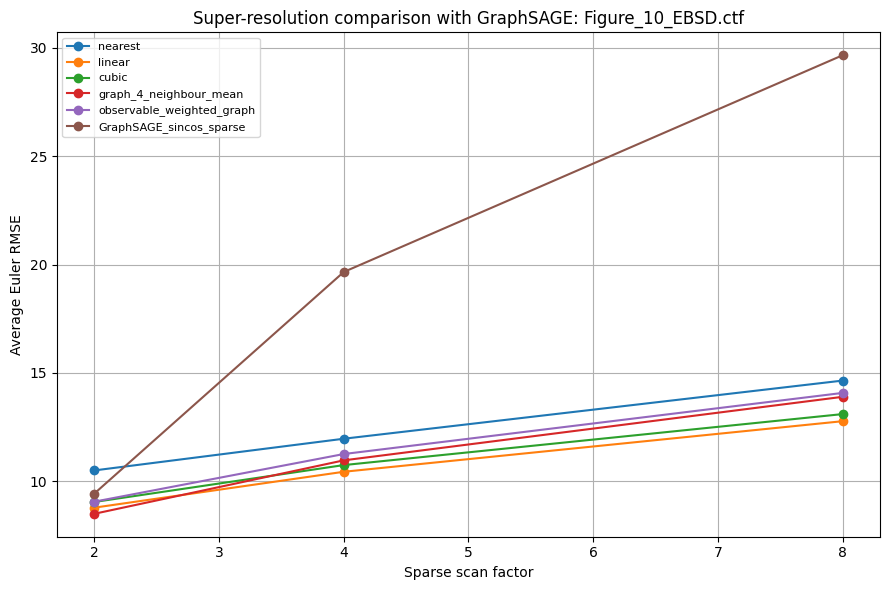

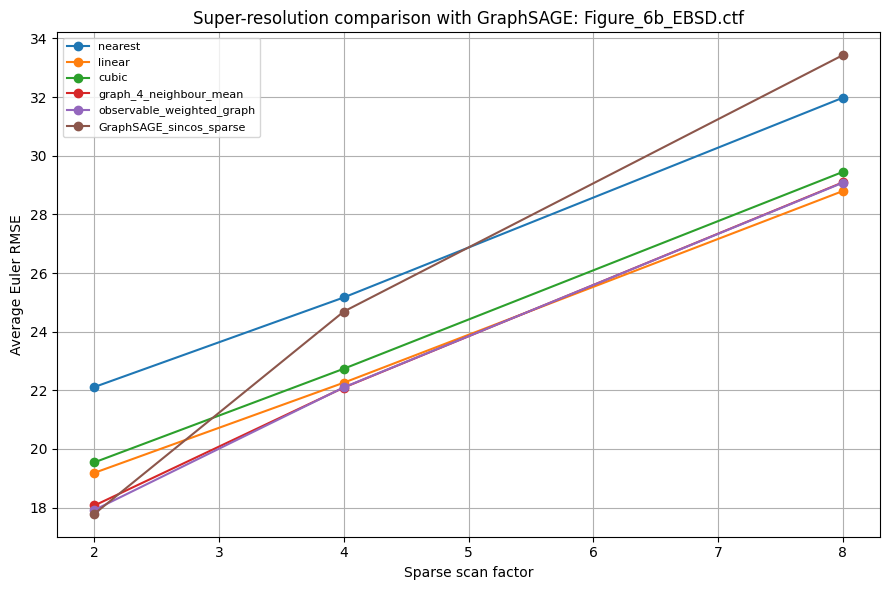

Saved notes: /content/drive/MyDrive/EBSD Paper2/results/experiment_10B_graphsage_sparse_scan/Experiment_10B_notes.txt


In [ ]:

# ============================================================
# Experiment 10B: GraphSAGE sin/cos for sparse EBSD reconstruction
# Purpose:
# Train GraphSAGE_sincos to reconstruct dense EBSD orientation maps
# from sparse EBSD scans.
#
# Sparse factors:
# - 2x: keep every 2nd pixel
# - 4x: keep every 4th pixel
# - 8x: keep every 8th pixel
#
# Output:
# - CSV results
# - model checkpoints
# - reconstruction figures
# - comparison with Experiment 10 classical/graph baselines
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_10B_graphsage_sparse_scan"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"
TABLE_DIR = f"{RESULTS_DIR}/tables"
LOG_DIR = f"{RESULTS_DIR}/logs"

for d in [RESULTS_DIR, FIG_DIR, MODEL_DIR, TABLE_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

CTF_FILES = [
    "Figure_10_EBSD.ctf",
    "Figure_6b_EBSD.ctf"
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ------------------------------------------------------------
# 2. CTF reader and preprocessing
# ------------------------------------------------------------

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]

    df_crop = df[
        df["X"].isin(x_crop) &
        df["Y"].isin(y_crop)
    ].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0

    return maps, valid_mask

# ------------------------------------------------------------
# 3. Sparse scan mask
# ------------------------------------------------------------

def create_sparse_scan_mask(valid_mask, factor=2):
    sparse_known = np.zeros(valid_mask.shape, dtype=bool)
    sparse_known[::factor, ::factor] = True

    known_mask = valid_mask & sparse_known
    target_mask = valid_mask & (~sparse_known)

    return known_mask, target_mask

# ------------------------------------------------------------
# 4. sin/cos representation and angular metrics
# ------------------------------------------------------------

def euler_to_sincos(e1, e2, e3):
    angles = np.stack([e1, e2, e3], axis=0)
    radians = np.deg2rad(angles)

    sin_part = np.sin(radians)
    cos_part = np.cos(radians)

    return np.concatenate([sin_part, cos_part], axis=0)

def sincos_to_euler(pred):
    sin_part = pred[:3]
    cos_part = pred[3:]

    angles = np.rad2deg(np.arctan2(sin_part, cos_part))
    angles = np.mod(angles, 360.0)

    return angles

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_metrics(original_deg, reconstructed_deg, eval_mask):
    out = {}

    for i, col in enumerate(["Euler1", "Euler2", "Euler3"]):
        err = angular_error_deg(original_deg[i], reconstructed_deg[i])
        values = err[eval_mask]
        values = values[np.isfinite(values)]

        out[f"{col}_MAE"] = np.mean(values)
        out[f"{col}_RMSE"] = np.sqrt(np.mean(values ** 2))

    out["Average_Euler_RMSE"] = np.mean([
        out["Euler1_RMSE"],
        out["Euler2_RMSE"],
        out["Euler3_RMSE"]
    ])

    out["Average_Euler_MAE"] = np.mean([
        out["Euler1_MAE"],
        out["Euler2_MAE"],
        out["Euler3_MAE"]
    ])

    return out

# ------------------------------------------------------------
# 5. Grid GraphSAGE model
# ------------------------------------------------------------

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        kernel = torch.tensor(
            [[0, 1, 0],
             [1, 0, 1],
             [0, 1, 0]],
            dtype=torch.float32
        ).view(1, 1, 3, 3)

        self.register_buffer("kernel", kernel)

    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(
            x * valid_mask,
            self.kernel.repeat(x.shape[1], 1, 1, 1),
            padding=1,
            groups=x.shape[1]
        )

        neighbour_count = F.conv2d(
            valid_mask,
            self.kernel,
            padding=1
        ).clamp(min=1.0)

        neighbour_mean = neighbour_sum / neighbour_count

        return self.self_linear(x) + self.neigh_linear(neighbour_mean)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=11, hidden_channels=128, out_channels=6):
        super().__init__()

        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.layer3 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)

    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        x = F.relu(self.layer3(x, valid_mask))
        return self.output(x)

# ------------------------------------------------------------
# 6. Training function
# ------------------------------------------------------------

def run_graphsage_sparse(
    ctf_file,
    sparse_factor,
    crop_size=256,
    epochs=150,
    learning_rate=5e-4,
    hidden_channels=128,
    seed=42,
    resume=True
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    maps, valid_mask_np = prepare_crop(ctf_file, crop_size=crop_size)

    known_mask, target_mask = create_sparse_scan_mask(
        valid_mask=valid_mask_np,
        factor=sparse_factor
    )

    known_fraction = known_mask.sum() / valid_mask_np.sum()
    target_fraction = target_mask.sum() / valid_mask_np.sum()

    original_deg = np.stack(
        [maps["Euler1"], maps["Euler2"], maps["Euler3"]],
        axis=0
    )

    target_sincos = euler_to_sincos(
        maps["Euler1"],
        maps["Euler2"],
        maps["Euler3"]
    )

    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)

    visible_mask = known_mask.copy()

    sincos_input = target_sincos.copy()
    sincos_input[:, ~known_mask] = 0.0

    input_features = np.concatenate(
        [
            sincos_input,
            np.expand_dims(phase_norm, axis=0),
            np.expand_dims(bc_norm, axis=0),
            np.expand_dims(mad_norm, axis=0),
            np.expand_dims(visible_mask.astype(float), axis=0),
            np.expand_dims(valid_mask_np.astype(float), axis=0),
        ],
        axis=0
    )

    x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
    y_tensor = torch.tensor(target_sincos, dtype=torch.float32).unsqueeze(0).to(device)

    valid_tensor = torch.tensor(
        valid_mask_np.astype(float),
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(device)

    train_mask_tensor = torch.tensor(target_mask, dtype=torch.bool).to(device)

    model = GridGraphSAGE(
        in_channels=input_features.shape[0],
        hidden_channels=hidden_channels,
        out_channels=6
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    run_id = f"{ctf_file.replace('.ctf','')}_crop{crop_size}_sparse{int(sparse_factor)}_GraphSAGE_sincos"

    checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")
    final_model_path = os.path.join(MODEL_DIR, f"{run_id}_final.pt")
    log_path = os.path.join(LOG_DIR, f"{run_id}_loss.csv")

    start_epoch = 0
    losses = []

    if resume and os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        start_epoch = checkpoint["epoch"] + 1

        if os.path.exists(log_path):
            old_log = pd.read_csv(log_path)
            losses = old_log["loss"].tolist()

        print(f"Resuming {run_id} from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train()
        optimizer.zero_grad()

        pred = model(x_tensor, valid_tensor)

        loss = F.mse_loss(
            pred[0, :, train_mask_tensor].T,
            y_tensor[0, :, train_mask_tensor].T
        )

        loss.backward()
        optimizer.step()

        losses.append(float(loss.item()))

        if (epoch + 1) % 25 == 0 or (epoch + 1) == epochs:
            print(f"{run_id}: epoch {epoch+1}/{epochs}, loss={loss.item():.6f}")

            torch.save(
                {
                    "epoch": epoch,
                    "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "loss": float(loss.item())
                },
                checkpoint_path
            )

            pd.DataFrame(
                {"epoch": range(1, len(losses) + 1), "loss": losses}
            ).to_csv(log_path, index=False)

    model.eval()

    with torch.no_grad():
        pred_sincos = model(x_tensor, valid_tensor)[0].cpu().numpy()

    pred_deg = sincos_to_euler(pred_sincos)

    metrics = compute_metrics(
        original_deg=original_deg,
        reconstructed_deg=pred_deg,
        eval_mask=target_mask
    )

    torch.save(model.state_dict(), final_model_path)

    # Save reconstruction figure
    sparse_euler1 = maps["Euler1"].copy()
    sparse_euler1[target_mask] = np.nan

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    axes[0].imshow(maps["Euler1"], cmap="viridis")
    axes[0].set_title("Original Euler1")

    axes[1].imshow(sparse_euler1, cmap="viridis")
    axes[1].set_title(f"Sparse input: factor {sparse_factor}")

    axes[2].imshow(pred_deg[0], cmap="viridis")
    axes[2].set_title("GraphSAGE sin/cos reconstruction")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    fig_path = os.path.join(FIG_DIR, f"{run_id}_Euler1.png")
    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.close()

    row = {
        "file": ctf_file,
        "crop_size": f"{crop_size}x{crop_size}",
        "valid_pixels": int(valid_mask_np.sum()),
        "sparse_factor": sparse_factor,
        "known_pixels": int(known_mask.sum()),
        "reconstructed_pixels": int(target_mask.sum()),
        "known_fraction": known_fraction,
        "reconstructed_fraction": target_fraction,
        "method": "GraphSAGE_sincos_sparse",
        "epochs": epochs,
        "learning_rate": learning_rate,
        "hidden_channels": hidden_channels,
        "seed": seed,
        "checkpoint": checkpoint_path,
        "final_model": final_model_path
    }

    row.update(metrics)

    return row

# ------------------------------------------------------------
# 7. Run Experiment 10B
# ------------------------------------------------------------

crop_size = 256
sparse_factors = [2, 4, 8]
epochs = 150
learning_rate = 5e-4
hidden_channels = 128
seed = 42

all_results = []

for ctf_file in CTF_FILES:
    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    for sparse_factor in sparse_factors:
        print(f"\nSparse factor: {sparse_factor}x")

        row = run_graphsage_sparse(
            ctf_file=ctf_file,
            sparse_factor=sparse_factor,
            crop_size=crop_size,
            epochs=epochs,
            learning_rate=learning_rate,
            hidden_channels=hidden_channels,
            seed=seed,
            resume=True
        )

        all_results.append(row)

        pd.DataFrame(all_results).to_csv(
            os.path.join(RESULTS_DIR, "Experiment_10B_GraphSAGE_sparse_scan_IN_PROGRESS.csv"),
            index=False
        )

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR,
    "Experiment_10B_GraphSAGE_sparse_scan_results.csv"
)

results_df.to_csv(results_csv, index=False)

print("\nExperiment 10B completed.")
print("Results saved to:", results_csv)
print("Figures saved to:", FIG_DIR)
print("Models saved to:", MODEL_DIR)

display(results_df)

# ------------------------------------------------------------
# 9. Compare with Experiment 10 baselines
# ------------------------------------------------------------

baseline_csv = f"{PROJECT_DIR}/results/experiment_10_super_resolution/Experiment_10_super_resolution_results.csv"

if os.path.exists(baseline_csv):
    baseline_df = pd.read_csv(baseline_csv)

    combined = pd.concat([baseline_df, results_df], ignore_index=True)

    combined_csv = os.path.join(
        RESULTS_DIR,
        "Experiment_10B_super_resolution_all_methods_with_GraphSAGE.csv"
    )

    combined.to_csv(combined_csv, index=False)

    print("Combined comparison saved to:", combined_csv)

    best = (
        combined
        .sort_values("Average_Euler_RMSE")
        .groupby(["file", "sparse_factor"])
        .first()
        .reset_index()
    )

    best_csv = os.path.join(
        TABLE_DIR,
        "Experiment_10B_best_method_with_GraphSAGE.csv"
    )

    best.to_csv(best_csv, index=False)

    print("Best-method table saved to:", best_csv)

    display(best[
        [
            "file",
            "sparse_factor",
            "known_fraction",
            "method",
            "Average_Euler_RMSE",
            "Average_Euler_MAE"
        ]
    ])

    # Plot comparison
    for ctf_file in CTF_FILES:

        subset_file = combined[combined["file"] == ctf_file]

        plt.figure(figsize=(9, 6))

        for method in subset_file["method"].unique():
            subset = subset_file[
                subset_file["method"] == method
            ].sort_values("sparse_factor")

            plt.plot(
                subset["sparse_factor"],
                subset["Average_Euler_RMSE"],
                marker="o",
                label=method
            )

        plt.xlabel("Sparse scan factor")
        plt.ylabel("Average Euler RMSE")
        plt.title(f"Super-resolution comparison with GraphSAGE: {ctf_file}")
        plt.grid(True)
        plt.legend(fontsize=8)
        plt.tight_layout()

        fig_path = os.path.join(
            FIG_DIR,
            f"{ctf_file.replace('.ctf','')}_super_resolution_with_GraphSAGE_RMSE.png"
        )

        plt.savefig(fig_path, dpi=600, bbox_inches="tight")
        plt.show()

else:
    print("Baseline super-resolution CSV not found. Skipping combined comparison.")

# ------------------------------------------------------------
# 10. Notes
# ------------------------------------------------------------

notes_path = os.path.join(RESULTS_DIR, "Experiment_10B_notes.txt")

with open(notes_path, "w") as f:
    f.write("Experiment 10B: GraphSAGE sin/cos for Sparse EBSD Reconstruction\n")
    f.write("================================================================\n\n")
    f.write("This experiment trains GraphSAGE_sincos to reconstruct dense EBSD maps from sparse sampled inputs.\n")
    f.write("The result should be compared against Experiment 10 classical/graph baselines.\n\n")
    f.write("Interpretation note:\n")
    f.write("This is sparse-scan EBSD densification / super-resolution-like reconstruction.\n")
    f.write("It is not optical image super-resolution.\n")

print("Saved notes:", notes_path)


In [ ]:

# ============================================================
# Experiment 11: Statistical validation of EBSD reconstruction
# Repeats the random missing-pixel task over multiple seeds.
# Saves mean ± SD and Wilcoxon tests to Google Drive.
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.stats import wilcoxon

import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_11_statistical_validation"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"
TABLE_DIR = f"{RESULTS_DIR}/tables"
LOG_DIR = f"{RESULTS_DIR}/logs"

for d in [RESULTS_DIR, FIG_DIR, MODEL_DIR, TABLE_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

CTF_FILES = ["Figure_10_EBSD.ctf", "Figure_6b_EBSD.ctf"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()
    header_idx = None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")
    columns = lines[header_idx].strip().split()
    return pd.read_csv(path, sep=r"\s+", skiprows=header_idx + 1, names=columns, engine="python")

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_file, crop_size=256):
    df = load_ctf(os.path.join(PROJECT_DIR, ctf_file))
    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())
    x_crop = x_unique[:crop_size]
    y_crop = y_unique[:crop_size]
    df_crop = df[df["X"].isin(x_crop) & df["Y"].isin(y_crop)].copy()
    maps = {c: dataframe_to_grid(df_crop, c, x_crop, y_crop) for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]}
    valid_mask = maps["Phase"] > 0
    return maps, valid_mask

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]
    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True
    return mask

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_one_metric(original, reconstructed, missing_mask):
    err = angular_error_deg(original, reconstructed)
    values = err[missing_mask]
    values = values[np.isfinite(values)]
    return np.mean(values), np.sqrt(np.mean(values ** 2))

def compute_all_euler_metrics(maps, reconstructed_maps, missing_mask):
    row = {}
    for col in ["Euler1", "Euler2", "Euler3"]:
        mae, rmse = compute_one_metric(maps[col], reconstructed_maps[col], missing_mask)
        row[f"{col}_MAE"] = mae
        row[f"{col}_RMSE"] = rmse
    row["Average_Euler_RMSE"] = np.mean([row["Euler1_RMSE"], row["Euler2_RMSE"], row["Euler3_RMSE"]])
    row["Average_Euler_MAE"] = np.mean([row["Euler1_MAE"], row["Euler2_MAE"], row["Euler3_MAE"]])
    return row

def interpolate_grid(original_grid, valid_mask, missing_mask, method="linear"):
    yy, xx = np.indices(original_grid.shape)
    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask
    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]
    points_target = np.column_stack((xx[target_mask], yy[target_mask]))
    reconstructed = original_grid.copy()
    reconstructed[target_mask] = griddata(points_known, values_known, points_target, method=method)
    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))
        reconstructed[nan_target] = griddata(points_known, values_known, points_nan, method="nearest")
    return reconstructed

def graph_neighbour_mean_reconstruct(original_grid, valid_mask, missing_mask, max_iters=20):
    reconstructed = original_grid.copy()
    reconstructed[missing_mask] = np.nan
    target_mask = missing_mask.copy()
    for _ in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()
        for r, c in np.argwhere(target_mask & np.isnan(reconstructed)):
            neighbours = []
            for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]:
                rr, cc = r + dr, c + dc
                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])
            if neighbours:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1
        reconstructed = new_reconstructed
        if updated == 0:
            break
    remaining = target_mask & np.isnan(reconstructed)
    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])
    return reconstructed

def observable_weighted_graph_reconstruct(target_grid, valid_mask, missing_mask, phase_grid, bc_grid, mad_grid, sigma_bc=25.0, sigma_mad=1.0, phase_bonus=2.0, max_iters=20):
    reconstructed = target_grid.copy()
    reconstructed[missing_mask] = np.nan
    target_mask = missing_mask.copy()
    for _ in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()
        for r, c in np.argwhere(target_mask & np.isnan(reconstructed)):
            values, weights = [], []
            center_phase, center_bc, center_mad = phase_grid[r, c], bc_grid[r, c], mad_grid[r, c]
            for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]:
                rr, cc = r + dr, c + dc
                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        w_phase = phase_bonus if center_phase == phase_grid[rr, cc] else 1.0
                        w_bc = np.exp(-abs(center_bc - bc_grid[rr, cc]) / sigma_bc)
                        w_mad = np.exp(-abs(center_mad - mad_grid[rr, cc]) / sigma_mad)
                        values.append(reconstructed[rr, cc])
                        weights.append(w_phase * w_bc * w_mad)
            if values:
                values = np.array(values)
                weights = np.array(weights)
                new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights) if weights.sum() > 0 else np.mean(values)
                updated += 1
        reconstructed = new_reconstructed
        if updated == 0:
            break
    remaining = target_mask & np.isnan(reconstructed)
    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])
    return reconstructed

def euler_to_sincos(e1, e2, e3):
    angles = np.stack([e1, e2, e3], axis=0)
    radians = np.deg2rad(angles)
    return np.concatenate([np.sin(radians), np.cos(radians)], axis=0)

def sincos_to_euler(pred):
    sin_part = pred[:3]
    cos_part = pred[3:]
    angles = np.rad2deg(np.arctan2(sin_part, cos_part))
    return np.mod(angles, 360.0)

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        kernel = torch.tensor([[0,1,0],[1,0,1],[0,1,0]], dtype=torch.float32).view(1,1,3,3)
        self.register_buffer("kernel", kernel)
    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(x * valid_mask, self.kernel.repeat(x.shape[1], 1, 1, 1), padding=1, groups=x.shape[1])
        neighbour_count = F.conv2d(valid_mask, self.kernel, padding=1).clamp(min=1.0)
        neighbour_mean = neighbour_sum / neighbour_count
        return self.self_linear(x) + self.neigh_linear(neighbour_mean)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=11, hidden_channels=128, out_channels=6):
        super().__init__()
        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.layer3 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)
    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        x = F.relu(self.layer3(x, valid_mask))
        return self.output(x)

def run_graphsage_sincos(maps, valid_mask_np, eval_missing_mask, ctf_file, missing_fraction, seed, crop_size=256, epochs=100, learning_rate=5e-4, hidden_channels=128, resume=True):
    np.random.seed(seed)
    torch.manual_seed(seed)

    target_sincos = euler_to_sincos(maps["Euler1"], maps["Euler2"], maps["Euler3"])

    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)

    rng = np.random.default_rng(seed + 1000)
    available_train = valid_mask_np & (~eval_missing_mask)
    train_candidates = np.argwhere(available_train)
    train_hide_count = int(len(train_candidates) * 0.10)
    selected = rng.choice(len(train_candidates), size=train_hide_count, replace=False)
    chosen = train_candidates[selected]

    train_hide_mask = np.zeros(valid_mask_np.shape, dtype=bool)
    train_hide_mask[chosen[:, 0], chosen[:, 1]] = True

    hidden_mask = eval_missing_mask | train_hide_mask
    visible_mask = valid_mask_np & (~hidden_mask)

    sincos_input = target_sincos.copy()
    sincos_input[:, hidden_mask] = 0.0

    input_features = np.concatenate([
        sincos_input,
        np.expand_dims(phase_norm, axis=0),
        np.expand_dims(bc_norm, axis=0),
        np.expand_dims(mad_norm, axis=0),
        np.expand_dims(visible_mask.astype(float), axis=0),
        np.expand_dims(valid_mask_np.astype(float), axis=0),
    ], axis=0)

    x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
    y_tensor = torch.tensor(target_sincos, dtype=torch.float32).unsqueeze(0).to(device)
    valid_tensor = torch.tensor(valid_mask_np.astype(float), dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    train_mask_tensor = torch.tensor(train_hide_mask, dtype=torch.bool).to(device)

    model = GridGraphSAGE(in_channels=input_features.shape[0], hidden_channels=hidden_channels, out_channels=6).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    run_id = f"{ctf_file.replace('.ctf','')}_crop{crop_size}_missing{int(missing_fraction*100)}_seed{seed}_GraphSAGE_sincos"
    checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")
    final_model_path = os.path.join(MODEL_DIR, f"{run_id}_final.pt")
    log_path = os.path.join(LOG_DIR, f"{run_id}_loss.csv")

    start_epoch, losses = 0, []
    if resume and os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        start_epoch = checkpoint["epoch"] + 1
        if os.path.exists(log_path):
            losses = pd.read_csv(log_path)["loss"].tolist()
        print(f"Resuming {run_id} from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(x_tensor, valid_tensor)
        loss = F.mse_loss(pred[0, :, train_mask_tensor].T, y_tensor[0, :, train_mask_tensor].T)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))
        if (epoch + 1) % 25 == 0 or (epoch + 1) == epochs:
            print(f"{run_id}: epoch {epoch+1}/{epochs}, loss={loss.item():.6f}")
            torch.save({"epoch": epoch, "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(), "loss": float(loss.item())}, checkpoint_path)
            pd.DataFrame({"epoch": range(1, len(losses) + 1), "loss": losses}).to_csv(log_path, index=False)

    model.eval()
    with torch.no_grad():
        pred_sincos = model(x_tensor, valid_tensor)[0].cpu().numpy()

    pred_deg = sincos_to_euler(pred_sincos)
    torch.save(model.state_dict(), final_model_path)

    return {"Euler1": pred_deg[0], "Euler2": pred_deg[1], "Euler3": pred_deg[2]}

crop_size = 256
missing_levels = [0.05, 0.10, 0.20, 0.40]
seeds = [1, 2, 3, 4, 5]
graphsage_epochs = 100
learning_rate = 5e-4
methods = ["linear", "graph_4_neighbour_mean", "observable_weighted_graph", "GraphSAGE_sincos"]

all_results = []

for ctf_file in CTF_FILES:
    print("\n============================================")
    print("Processing:", ctf_file)
    print("============================================")

    maps, valid_mask = prepare_crop(ctf_file, crop_size=crop_size)

    for missing_fraction in missing_levels:
        print(f"\nMissing level: {int(missing_fraction * 100)}%")

        for seed in seeds:
            print(f"\nSeed: {seed}")
            missing_mask = create_missing_mask(valid_mask=valid_mask, missing_fraction=missing_fraction, seed=seed)

            for method in methods:
                print("  Method:", method)
                reconstructed_maps = {}

                if method == "linear":
                    for col in ["Euler1", "Euler2", "Euler3"]:
                        reconstructed_maps[col] = interpolate_grid(maps[col], valid_mask, missing_mask, method="linear")

                elif method == "graph_4_neighbour_mean":
                    for col in ["Euler1", "Euler2", "Euler3"]:
                        reconstructed_maps[col] = graph_neighbour_mean_reconstruct(maps[col], valid_mask, missing_mask)

                elif method == "observable_weighted_graph":
                    for col in ["Euler1", "Euler2", "Euler3"]:
                        reconstructed_maps[col] = observable_weighted_graph_reconstruct(
                            maps[col], valid_mask, missing_mask,
                            maps["Phase"], maps["BC"], maps["MAD"]
                        )

                elif method == "GraphSAGE_sincos":
                    reconstructed_maps = run_graphsage_sincos(
                        maps=maps,
                        valid_mask_np=valid_mask,
                        eval_missing_mask=missing_mask,
                        ctf_file=ctf_file,
                        missing_fraction=missing_fraction,
                        seed=seed,
                        crop_size=crop_size,
                        epochs=graphsage_epochs,
                        learning_rate=learning_rate,
                        hidden_channels=128,
                        resume=True
                    )

                row = {
                    "file": ctf_file,
                    "crop_size": f"{crop_size}x{crop_size}",
                    "valid_pixels": int(valid_mask.sum()),
                    "missing_fraction": missing_fraction,
                    "missing_percent": int(missing_fraction * 100),
                    "method": method,
                    "seed": seed
                }
                row.update(compute_all_euler_metrics(maps, reconstructed_maps, missing_mask))
                all_results.append(row)

                pd.DataFrame(all_results).to_csv(os.path.join(RESULTS_DIR, "Experiment_11_statistical_validation_IN_PROGRESS.csv"), index=False)

results_df = pd.DataFrame(all_results)
raw_csv = os.path.join(RESULTS_DIR, "Experiment_11_statistical_validation_raw_results.csv")
results_df.to_csv(raw_csv, index=False)
print("\nRaw results saved to:", raw_csv)
display(results_df)

summary = results_df.groupby(["file", "missing_percent", "method"]).agg(
    mean_rmse=("Average_Euler_RMSE", "mean"),
    std_rmse=("Average_Euler_RMSE", "std"),
    mean_mae=("Average_Euler_MAE", "mean"),
    std_mae=("Average_Euler_MAE", "std"),
    n=("Average_Euler_RMSE", "count")
).reset_index()

summary_csv = os.path.join(TABLE_DIR, "Experiment_11_mean_std_summary.csv")
summary.to_csv(summary_csv, index=False)
print("Mean ± SD summary saved to:", summary_csv)
display(summary)

best = summary.sort_values("mean_rmse").groupby(["file", "missing_percent"]).first().reset_index()
best_csv = os.path.join(TABLE_DIR, "Experiment_11_best_method_mean_rmse.csv")
best.to_csv(best_csv, index=False)
print("Best-method summary saved to:", best_csv)
display(best)

stats_rows = []
for file_name in results_df["file"].unique():
    for missing_percent in sorted(results_df["missing_percent"].unique()):
        subset = results_df[(results_df["file"] == file_name) & (results_df["missing_percent"] == missing_percent)]
        gnn = subset[subset["method"] == "GraphSAGE_sincos"].sort_values("seed")
        for method in ["linear", "graph_4_neighbour_mean", "observable_weighted_graph"]:
            comp = subset[subset["method"] == method].sort_values("seed")
            if len(comp) == len(gnn) and len(gnn) > 0:
                try:
                    stat, p_value = wilcoxon(gnn["Average_Euler_RMSE"].values, comp["Average_Euler_RMSE"].values)
                except Exception:
                    stat, p_value = np.nan, np.nan
                stats_rows.append({
                    "file": file_name,
                    "missing_percent": missing_percent,
                    "comparison": f"GraphSAGE_sincos_vs_{method}",
                    "gnn_mean_rmse": gnn["Average_Euler_RMSE"].mean(),
                    "comparison_mean_rmse": comp["Average_Euler_RMSE"].mean(),
                    "wilcoxon_stat": stat,
                    "p_value": p_value
                })

stats_df = pd.DataFrame(stats_rows)
stats_csv = os.path.join(TABLE_DIR, "Experiment_11_wilcoxon_tests_vs_GraphSAGE.csv")
stats_df.to_csv(stats_csv, index=False)
print("Wilcoxon tests saved to:", stats_csv)
display(stats_df)

for file_name in results_df["file"].unique():
    subset_file = summary[summary["file"] == file_name]
    plt.figure(figsize=(9, 6))
    for method in methods:
        subset = subset_file[subset_file["method"] == method].sort_values("missing_percent")
        plt.errorbar(subset["missing_percent"], subset["mean_rmse"], yerr=subset["std_rmse"], marker="o", capsize=4, label=method)
    plt.xlabel("Missing pixels (%)")
    plt.ylabel("Average Euler RMSE")
    plt.title(f"Statistical validation: {file_name}")
    plt.grid(True)
    plt.legend(fontsize=8)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, f"{file_name.replace('.ctf','')}_statistical_validation_RMSE.png")
    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()

notes_path = os.path.join(RESULTS_DIR, "Experiment_11_notes.txt")
with open(notes_path, "w") as f:
    f.write("Experiment 11: Statistical Validation\n")
    f.write("Repeats the random missing-pixel inpainting task over multiple random seeds.\n")
    f.write("GraphSAGE uses 100 epochs here for runtime reasons; consider 150 epochs for final publication.\n")
    f.write("Wilcoxon tests are exploratory because n=5 seeds is small.\n")
print("Saved notes:", notes_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu

Processing: Figure_10_EBSD.ctf

Missing level: 5%

Seed: 1
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph
  Method: GraphSAGE_sincos
Figure_10_EBSD_crop256_missing5_seed1_GraphSAGE_sincos: epoch 25/100, loss=0.074957
Figure_10_EBSD_crop256_missing5_seed1_GraphSAGE_sincos: epoch 50/100, loss=0.026233
Figure_10_EBSD_crop256_missing5_seed1_GraphSAGE_sincos: epoch 75/100, loss=0.016646
Figure_10_EBSD_crop256_missing5_seed1_GraphSAGE_sincos: epoch 100/100, loss=0.011183

Seed: 2
  Method: linear
  Method: graph_4_neighbour_mean
  Method: observable_weighted_graph
  Method: GraphSAGE_sincos
Figure_10_EBSD_crop256_missing5_seed2_GraphSAGE_sincos: epoch 25/100, loss=0.084632
Figure_10_EBSD_crop256_missing5_seed2_GraphSAGE_sincos: epoch 50/100, loss=0.027091
Figure_10_EBSD_crop256_missing5_seed2_GraphSAGE_sinco

In [ ]:
# Experiment 12: Multi-Dataset EBSD Reconstruction Benchmark
# Put all .ctf files in: /content/drive/MyDrive/EBSD Paper2/datasets/
# Start with RUN_GRAPHSAGE=False. Set True later for full benchmark.

from google.colab import drive
drive.mount('/content/drive')

import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.stats import wilcoxon
import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
DATA_DIR = f"{PROJECT_DIR}/datasets"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_12_multi_dataset_benchmark"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"
TABLE_DIR = f"{RESULTS_DIR}/tables"
LOG_DIR = f"{RESULTS_DIR}/logs"
for d in [RESULTS_DIR, FIG_DIR, MODEL_DIR, TABLE_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

CROP_SIZE = 256
MISSING_LEVELS = [0.05, 0.10, 0.20, 0.40]
SEEDS = [1, 2, 3, 4, 5]
RUN_GRAPHSAGE = False   # Set True only after baseline run works
GRAPHSAGE_EPOCHS = 100
LEARNING_RATE = 5e-4
HIDDEN_CHANNELS = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

ctf_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.ctf")))
if len(ctf_paths) == 0:
    raise FileNotFoundError(f"No .ctf files found in {DATA_DIR}")
print(f"Found {len(ctf_paths)} CTF files:")
for p in ctf_paths:
    print(" -", os.path.basename(p))

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()
    header_idx = None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError(f"Could not locate CTF numeric data header in {path}")
    columns = lines[header_idx].strip().split()
    return pd.read_csv(path, sep=r"\s+", skiprows=header_idx + 1, names=columns, engine="python")

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_path, crop_size=256):
    df = load_ctf(ctf_path)
    required = ["Phase", "X", "Y", "Euler1", "Euler2", "Euler3"]
    for col in required:
        if col not in df.columns:
            raise ValueError(f"{os.path.basename(ctf_path)} is missing required column: {col}")
    if "BC" not in df.columns:
        print(f"Warning: BC missing in {os.path.basename(ctf_path)}. Using zeros.")
        df["BC"] = 0.0
    if "MAD" not in df.columns:
        print(f"Warning: MAD missing in {os.path.basename(ctf_path)}. Using zeros.")
        df["MAD"] = 0.0
    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())
    crop_size_use = min(len(x_unique), len(y_unique), crop_size)
    if crop_size_use < crop_size:
        print(f"Warning: {os.path.basename(ctf_path)} smaller than requested crop. Using {crop_size_use}x{crop_size_use}.")
    x_crop = x_unique[:crop_size_use]
    y_crop = y_unique[:crop_size_use]
    df_crop = df[df["X"].isin(x_crop) & df["Y"].isin(y_crop)].copy()
    maps = {c: dataframe_to_grid(df_crop, c, x_crop, y_crop) for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]}
    valid_mask = maps["Phase"] > 0
    return maps, valid_mask, crop_size_use

def create_missing_mask(valid_mask, missing_fraction, seed=42):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]
    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True
    return mask

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_one_metric(original, reconstructed, missing_mask):
    err = angular_error_deg(original, reconstructed)
    values = err[missing_mask]
    values = values[np.isfinite(values)]
    return np.mean(values), np.sqrt(np.mean(values ** 2))

def compute_all_euler_metrics(maps, reconstructed_maps, missing_mask):
    row = {}
    for col in ["Euler1", "Euler2", "Euler3"]:
        mae, rmse = compute_one_metric(maps[col], reconstructed_maps[col], missing_mask)
        row[f"{col}_MAE"] = mae
        row[f"{col}_RMSE"] = rmse
    row["Average_Euler_RMSE"] = np.mean([row["Euler1_RMSE"], row["Euler2_RMSE"], row["Euler3_RMSE"]])
    row["Average_Euler_MAE"] = np.mean([row["Euler1_MAE"], row["Euler2_MAE"], row["Euler3_MAE"]])
    return row

def interpolate_grid(original_grid, valid_mask, missing_mask, method="linear"):
    yy, xx = np.indices(original_grid.shape)
    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask
    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]
    points_target = np.column_stack((xx[target_mask], yy[target_mask]))
    reconstructed = original_grid.copy()
    reconstructed[target_mask] = griddata(points_known, values_known, points_target, method=method)
    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)
        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))
        reconstructed[nan_target] = griddata(points_known, values_known, points_nan, method="nearest")
    return reconstructed

def graph_neighbour_mean_reconstruct(original_grid, valid_mask, missing_mask, max_iters=20):
    reconstructed = original_grid.copy()
    reconstructed[missing_mask] = np.nan
    target_mask = missing_mask.copy()
    for _ in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()
        for r, c in np.argwhere(target_mask & np.isnan(reconstructed)):
            neighbours = []
            for dr, dc in [(-1,0), (1,0), (0,-1), (0,1)]:
                rr, cc = r + dr, c + dc
                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        neighbours.append(reconstructed[rr, cc])
            if neighbours:
                new_reconstructed[r, c] = np.mean(neighbours)
                updated += 1
        reconstructed = new_reconstructed
        if updated == 0:
            break
    remaining = target_mask & np.isnan(reconstructed)
    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])
    return reconstructed

def observable_weighted_graph_reconstruct(target_grid, valid_mask, missing_mask, phase_grid, bc_grid, mad_grid, sigma_bc=25.0, sigma_mad=1.0, phase_bonus=2.0, max_iters=20):
    reconstructed = target_grid.copy()
    reconstructed[missing_mask] = np.nan
    target_mask = missing_mask.copy()
    for _ in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()
        for r, c in np.argwhere(target_mask & np.isnan(reconstructed)):
            values, weights = [], []
            center_phase, center_bc, center_mad = phase_grid[r, c], bc_grid[r, c], mad_grid[r, c]
            for dr, dc in [(-1,0), (1,0), (0,-1), (0,1)]:
                rr, cc = r + dr, c + dc
                if 0 <= rr < reconstructed.shape[0] and 0 <= cc < reconstructed.shape[1]:
                    if valid_mask[rr, cc] and np.isfinite(reconstructed[rr, cc]):
                        w_phase = phase_bonus if center_phase == phase_grid[rr, cc] else 1.0
                        w_bc = np.exp(-abs(center_bc - bc_grid[rr, cc]) / sigma_bc)
                        w_mad = np.exp(-abs(center_mad - mad_grid[rr, cc]) / sigma_mad)
                        values.append(reconstructed[rr, cc])
                        weights.append(w_phase * w_bc * w_mad)
            if values:
                values, weights = np.array(values), np.array(weights)
                new_reconstructed[r, c] = np.sum(values * weights) / np.sum(weights) if weights.sum() > 0 else np.mean(values)
                updated += 1
        reconstructed = new_reconstructed
        if updated == 0:
            break
    remaining = target_mask & np.isnan(reconstructed)
    if remaining.any():
        reconstructed[remaining] = np.nanmean(reconstructed[valid_mask])
    return reconstructed

# Optional GraphSAGE support
def euler_to_sincos(e1, e2, e3):
    angles = np.stack([e1, e2, e3], axis=0)
    radians = np.deg2rad(angles)
    return np.concatenate([np.sin(radians), np.cos(radians)], axis=0)

def sincos_to_euler(pred):
    angles = np.rad2deg(np.arctan2(pred[:3], pred[3:]))
    return np.mod(angles, 360.0)

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        kernel = torch.tensor([[0,1,0],[1,0,1],[0,1,0]], dtype=torch.float32).view(1,1,3,3)
        self.register_buffer("kernel", kernel)
    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(x * valid_mask, self.kernel.repeat(x.shape[1], 1, 1, 1), padding=1, groups=x.shape[1])
        neighbour_count = F.conv2d(valid_mask, self.kernel, padding=1).clamp(min=1.0)
        return self.self_linear(x) + self.neigh_linear(neighbour_sum / neighbour_count)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=11, hidden_channels=128, out_channels=6):
        super().__init__()
        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.layer3 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)
    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        x = F.relu(self.layer3(x, valid_mask))
        return self.output(x)

def run_graphsage_sincos(maps, valid_mask_np, eval_missing_mask, dataset_name, missing_fraction, seed, crop_size, resume=True):
    np.random.seed(seed)
    torch.manual_seed(seed)
    target_sincos = euler_to_sincos(maps["Euler1"], maps["Euler2"], maps["Euler3"])
    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)
    rng = np.random.default_rng(seed + 1000)
    available_train = valid_mask_np & (~eval_missing_mask)
    train_candidates = np.argwhere(available_train)
    train_hide_count = max(1, int(len(train_candidates) * 0.10))
    chosen = train_candidates[rng.choice(len(train_candidates), size=train_hide_count, replace=False)]
    train_hide_mask = np.zeros(valid_mask_np.shape, dtype=bool)
    train_hide_mask[chosen[:, 0], chosen[:, 1]] = True
    hidden_mask = eval_missing_mask | train_hide_mask
    visible_mask = valid_mask_np & (~hidden_mask)
    sincos_input = target_sincos.copy()
    sincos_input[:, hidden_mask] = 0.0
    input_features = np.concatenate([sincos_input, phase_norm[None], bc_norm[None], mad_norm[None], visible_mask.astype(float)[None], valid_mask_np.astype(float)[None]], axis=0)
    x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
    y_tensor = torch.tensor(target_sincos, dtype=torch.float32).unsqueeze(0).to(device)
    valid_tensor = torch.tensor(valid_mask_np.astype(float), dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    train_mask_tensor = torch.tensor(train_hide_mask, dtype=torch.bool).to(device)
    model = GridGraphSAGE(input_features.shape[0], HIDDEN_CHANNELS, 6).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    run_id = f"{dataset_name}_crop{crop_size}_missing{int(missing_fraction*100)}_seed{seed}_GraphSAGE_sincos"
    checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")
    final_model_path = os.path.join(MODEL_DIR, f"{run_id}_final.pt")
    log_path = os.path.join(LOG_DIR, f"{run_id}_loss.csv")
    start_epoch, losses = 0, []
    if resume and os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        start_epoch = checkpoint["epoch"] + 1
        if os.path.exists(log_path):
            losses = pd.read_csv(log_path)["loss"].tolist()
        print(f"Resuming {run_id} from epoch {start_epoch}")
    for epoch in range(start_epoch, GRAPHSAGE_EPOCHS):
        model.train(); optimizer.zero_grad()
        pred = model(x_tensor, valid_tensor)
        loss = F.mse_loss(pred[0, :, train_mask_tensor].T, y_tensor[0, :, train_mask_tensor].T)
        loss.backward(); optimizer.step()
        losses.append(float(loss.item()))
        if (epoch + 1) % 25 == 0 or (epoch + 1) == GRAPHSAGE_EPOCHS:
            print(f"{run_id}: epoch {epoch+1}/{GRAPHSAGE_EPOCHS}, loss={loss.item():.6f}")
            torch.save({"epoch": epoch, "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(), "loss": float(loss.item())}, checkpoint_path)
            pd.DataFrame({"epoch": range(1, len(losses)+1), "loss": losses}).to_csv(log_path, index=False)
    model.eval()
    with torch.no_grad():
        pred_sincos = model(x_tensor, valid_tensor)[0].cpu().numpy()
    pred_deg = sincos_to_euler(pred_sincos)
    torch.save(model.state_dict(), final_model_path)
    return {"Euler1": pred_deg[0], "Euler2": pred_deg[1], "Euler3": pred_deg[2]}

progress_csv = os.path.join(RESULTS_DIR, "Experiment_12_multi_dataset_IN_PROGRESS.csv")
raw_csv = os.path.join(RESULTS_DIR, "Experiment_12_multi_dataset_raw_results.csv")
all_results = pd.read_csv(progress_csv).to_dict("records") if os.path.exists(progress_csv) else []
print(f"Loaded existing progress with {len(all_results)} rows." if all_results else "Starting new benchmark.")

def result_exists(dataset_name, missing_percent, method, seed):
    for r in all_results:
        if r.get("dataset") == dataset_name and int(r.get("missing_percent")) == int(missing_percent) and r.get("method") == method and int(r.get("seed")) == int(seed):
            return True
    return False

methods = ["linear", "graph_4_neighbour_mean", "observable_weighted_graph"]
if RUN_GRAPHSAGE:
    methods.append("GraphSAGE_sincos")

start_time = time.time()
for ctf_path in ctf_paths:
    dataset_name = os.path.basename(ctf_path).replace(".ctf", "")
    print("\n=================================================")
    print("Dataset:", dataset_name)
    print("=================================================")
    try:
        maps, valid_mask, crop_used = prepare_crop(ctf_path, CROP_SIZE)
        print("Grid shape:", maps["Euler1"].shape, "Valid pixels:", int(valid_mask.sum()))
        overview_path = os.path.join(FIG_DIR, f"{dataset_name}_overview_Euler1.png")
        if not os.path.exists(overview_path):
            plt.figure(figsize=(5,5)); plt.imshow(maps["Euler1"], cmap="viridis"); plt.title(f"{dataset_name} - Euler1"); plt.axis("off"); plt.tight_layout(); plt.savefig(overview_path, dpi=400, bbox_inches="tight"); plt.close()
    except Exception as e:
        print("ERROR preparing dataset:", dataset_name, e)
        continue
    for missing_fraction in MISSING_LEVELS:
        missing_percent = int(missing_fraction * 100)
        print(f"\nMissing level: {missing_percent}%")
        for seed in SEEDS:
            missing_mask = create_missing_mask(valid_mask, missing_fraction, seed)
            for method in methods:
                if result_exists(dataset_name, missing_percent, method, seed):
                    print(f"Skipping existing: {dataset_name}, {missing_percent}%, {method}, seed {seed}")
                    continue
                print(f"Running: {dataset_name}, {missing_percent}%, seed {seed}, method {method}")
                try:
                    reconstructed_maps = {}
                    if method == "linear":
                        for col in ["Euler1", "Euler2", "Euler3"]:
                            reconstructed_maps[col] = interpolate_grid(maps[col], valid_mask, missing_mask, "linear")
                    elif method == "graph_4_neighbour_mean":
                        for col in ["Euler1", "Euler2", "Euler3"]:
                            reconstructed_maps[col] = graph_neighbour_mean_reconstruct(maps[col], valid_mask, missing_mask)
                    elif method == "observable_weighted_graph":
                        for col in ["Euler1", "Euler2", "Euler3"]:
                            reconstructed_maps[col] = observable_weighted_graph_reconstruct(maps[col], valid_mask, missing_mask, maps["Phase"], maps["BC"], maps["MAD"])
                    elif method == "GraphSAGE_sincos":
                        reconstructed_maps = run_graphsage_sincos(maps, valid_mask, missing_mask, dataset_name, missing_fraction, seed, crop_used)
                    row = {"dataset": dataset_name, "file": os.path.basename(ctf_path), "crop_size": f"{crop_used}x{crop_used}", "valid_pixels": int(valid_mask.sum()), "missing_fraction": missing_fraction, "missing_percent": missing_percent, "method": method, "seed": seed, "run_graphsage": RUN_GRAPHSAGE}
                    row.update(compute_all_euler_metrics(maps, reconstructed_maps, missing_mask))
                    all_results.append(row)
                    pd.DataFrame(all_results).to_csv(progress_csv, index=False)
                except Exception as e:
                    print("ERROR during method:", dataset_name, missing_percent, method, seed, e)
                    continue

results_df = pd.DataFrame(all_results)
results_df.to_csv(raw_csv, index=False)
print("\nBenchmark completed. Raw results saved to:", raw_csv)
display(results_df)

summary = results_df.groupby(["dataset", "file", "missing_percent", "method"]).agg(mean_rmse=("Average_Euler_RMSE", "mean"), std_rmse=("Average_Euler_RMSE", "std"), mean_mae=("Average_Euler_MAE", "mean"), std_mae=("Average_Euler_MAE", "std"), n=("Average_Euler_RMSE", "count")).reset_index()
summary_csv = os.path.join(TABLE_DIR, "Experiment_12_mean_std_summary.csv")
summary.to_csv(summary_csv, index=False)
print("Mean ± SD summary saved to:", summary_csv)
display(summary)

best = summary.sort_values("mean_rmse").groupby(["dataset", "missing_percent"]).first().reset_index()
best_csv = os.path.join(TABLE_DIR, "Experiment_12_best_method_by_dataset.csv")
best.to_csv(best_csv, index=False)
print("Best method summary saved to:", best_csv)
display(best)

dataset_rank = summary.groupby(["dataset", "method"]).agg(overall_mean_rmse=("mean_rmse", "mean"), overall_std_rmse=("mean_rmse", "std"), n_conditions=("mean_rmse", "count")).reset_index().sort_values(["dataset", "overall_mean_rmse"])
dataset_rank_csv = os.path.join(TABLE_DIR, "Experiment_12_dataset_level_method_ranking.csv")
dataset_rank.to_csv(dataset_rank_csv, index=False)
display(dataset_rank)

overall_rank = summary.groupby(["method"]).agg(overall_mean_rmse=("mean_rmse", "mean"), overall_std_rmse=("mean_rmse", "std"), n_conditions=("mean_rmse", "count")).reset_index().sort_values("overall_mean_rmse")
overall_rank_csv = os.path.join(TABLE_DIR, "Experiment_12_overall_method_ranking.csv")
overall_rank.to_csv(overall_rank_csv, index=False)
display(overall_rank)

if "GraphSAGE_sincos" in results_df["method"].unique():
    stats_rows = []
    for dataset in results_df["dataset"].unique():
        for missing_percent in sorted(results_df["missing_percent"].unique()):
            subset = results_df[(results_df["dataset"] == dataset) & (results_df["missing_percent"] == missing_percent)]
            gnn = subset[subset["method"] == "GraphSAGE_sincos"].sort_values("seed")
            for method in ["linear", "graph_4_neighbour_mean", "observable_weighted_graph"]:
                comp = subset[subset["method"] == method].sort_values("seed")
                if len(comp) == len(gnn) and len(gnn) > 0:
                    try:
                        stat, p_value = wilcoxon(gnn["Average_Euler_RMSE"].values, comp["Average_Euler_RMSE"].values)
                    except Exception:
                        stat, p_value = np.nan, np.nan
                    stats_rows.append({"dataset": dataset, "missing_percent": missing_percent, "comparison": f"GraphSAGE_sincos_vs_{method}", "gnn_mean_rmse": gnn["Average_Euler_RMSE"].mean(), "comparison_mean_rmse": comp["Average_Euler_RMSE"].mean(), "wilcoxon_stat": stat, "p_value": p_value})
    stats_df = pd.DataFrame(stats_rows)
    stats_csv = os.path.join(TABLE_DIR, "Experiment_12_wilcoxon_tests_vs_GraphSAGE.csv")
    stats_df.to_csv(stats_csv, index=False)
    display(stats_df)

for dataset in summary["dataset"].unique():
    subset_dataset = summary[summary["dataset"] == dataset]
    plt.figure(figsize=(9,6))
    for method in subset_dataset["method"].unique():
        s = subset_dataset[subset_dataset["method"] == method].sort_values("missing_percent")
        plt.errorbar(s["missing_percent"], s["mean_rmse"], yerr=s["std_rmse"], marker="o", capsize=4, label=method)
    plt.xlabel("Missing pixels (%)"); plt.ylabel("Average Euler RMSE"); plt.title(f"Multi-dataset benchmark: {dataset}"); plt.grid(True); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{dataset}_RMSE_vs_missing.png"), dpi=600, bbox_inches="tight")
    plt.close()

plt.figure(figsize=(8,5))
plt.bar(overall_rank["method"], overall_rank["overall_mean_rmse"])
plt.ylabel("Overall mean RMSE"); plt.title("Overall method ranking across datasets"); plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Experiment_12_overall_method_ranking.png"), dpi=600, bbox_inches="tight")
plt.close()

notes_path = os.path.join(RESULTS_DIR, "Experiment_12_notes.txt")
with open(notes_path, "w") as f:
    f.write("Experiment 12: Multi-Dataset EBSD Reconstruction Benchmark\n")
    f.write(f"Datasets folder: {DATA_DIR}\n")
    f.write(f"Number of CTF files detected: {len(ctf_paths)}\n")
    f.write(f"Crop size: {CROP_SIZE}\n")
    f.write(f"Missing levels: {MISSING_LEVELS}\n")
    f.write(f"Seeds: {SEEDS}\n")
    f.write(f"RUN_GRAPHSAGE: {RUN_GRAPHSAGE}\n")
    f.write(f"Elapsed seconds: {time.time() - start_time:.2f}\n")
print("Figures saved to:", FIG_DIR)
print("Experiment 12 finished.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
Found 4 CTF files:
 - EBSD_AN_XY.ctf
 - EBSD_AN_ZX.ctf
 - EBSD_DA_XY.ctf
 - EBSD_DA_ZX.ctf
Starting new benchmark.

Dataset: EBSD_AN_XY
Grid shape: (256, 256) Valid pixels: 58152

Missing level: 5%
Running: EBSD_AN_XY, 5%, seed 1, method linear
Running: EBSD_AN_XY, 5%, seed 1, method graph_4_neighbour_mean
Running: EBSD_AN_XY, 5%, seed 1, method observable_weighted_graph
Running: EBSD_AN_XY, 5%, seed 2, method linear
Running: EBSD_AN_XY, 5%, seed 2, method graph_4_neighbour_mean
Running: EBSD_AN_XY, 5%, seed 2, method observable_weighted_graph
Running: EBSD_AN_XY, 5%, seed 3, method linear
Running: EBSD_AN_XY, 5%, seed 3, method graph_4_neighbour_mean
Running: EBSD_AN_XY, 5%, seed 3, method observable_weighted_graph
Running: EBSD_AN_XY, 5%, seed 4, method linear
Running: EBSD_AN_XY, 5%, seed 4, method graph_4_neighbour_mean
Running: EBSD_AN_

,dataset,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,seed,run_graphsage,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,linear,1,False,19.940750,33.549162,16.970584,28.302328,6.672969,11.624594,24.492028,14.528101
1,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,graph_4_neighbour_mean,1,False,18.137341,29.473867,15.287064,25.067792,6.078340,10.323344,21.621668,13.167582
2,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,observable_weighted_graph,1,False,17.520675,30.285544,14.927811,25.810330,5.886048,10.642876,22.246250,12.778178
3,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,linear,2,False,19.253540,32.482733,16.412673,27.651976,6.330657,11.427300,23.854003,13.998956
4,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,graph_4_neighbour_mean,2,False,17.663203,29.203688,15.093599,25.080354,5.876451,10.377175,21.553739,12.877751
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,graph_4_neighbour_mean,4,False,13.565021,29.321391,9.819858,20.665616,5.077870,10.747788,20.244932,9.487583
236,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,observable_weighted_graph,4,False,12.740034,29.205368,9.317265,20.819678,4.818519,10.809894,20.278313,8.958606
237,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,linear,5,False,14.885767,28.892988,10.787777,20.076484,5.551841,10.453748,19.807740,10.408462
238,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,graph_4_neighbour_mean,5,False,13.657394,29.405073,9.895674,20.738253,5.149687,10.862278,20.335201,9.567585


Mean ± SD summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_12_multi_dataset_benchmark/tables/Experiment_12_mean_std_summary.csv


,dataset,file,missing_percent,method,mean_rmse,std_rmse,mean_mae,std_mae,n
0,EBSD_AN_XY,EBSD_AN_XY.ctf,5,graph_4_neighbour_mean,21.781238,0.440610,13.132568,0.406443,5
1,EBSD_AN_XY,EBSD_AN_XY.ctf,5,linear,24.459573,0.653918,14.460101,0.504937,5
2,EBSD_AN_XY,EBSD_AN_XY.ctf,5,observable_weighted_graph,22.426925,0.564205,12.823728,0.454312,5
3,EBSD_AN_XY,EBSD_AN_XY.ctf,10,graph_4_neighbour_mean,22.447881,0.243275,13.329885,0.176809,5
4,EBSD_AN_XY,EBSD_AN_XY.ctf,10,linear,24.375140,0.325479,14.397977,0.236871,5
5,EBSD_AN_XY,EBSD_AN_XY.ctf,10,observable_weighted_graph,23.064364,0.270833,13.036798,0.166599,5
6,EBSD_AN_XY,EBSD_AN_XY.ctf,20,graph_4_neighbour_mean,23.458449,0.126203,13.534747,0.089664,5
7,EBSD_AN_XY,EBSD_AN_XY.ctf,20,linear,24.711463,0.171163,14.794583,0.155621,5
8,EBSD_AN_XY,EBSD_AN_XY.ctf,20,observable_weighted_graph,24.020088,0.081516,13.250806,0.067001,5
9,EBSD_AN_XY,EBSD_AN_XY.ctf,40,graph_4_neighbour_mean,25.614496,0.089248,13.897120,0.046988,5


Best method summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_12_multi_dataset_benchmark/tables/Experiment_12_best_method_by_dataset.csv


,dataset,missing_percent,file,method,mean_rmse,std_rmse,mean_mae,std_mae,n
0,EBSD_AN_XY,5,EBSD_AN_XY.ctf,graph_4_neighbour_mean,21.781238,0.440610,13.132568,0.406443,5
1,EBSD_AN_XY,10,EBSD_AN_XY.ctf,graph_4_neighbour_mean,22.447881,0.243275,13.329885,0.176809,5
2,EBSD_AN_XY,20,EBSD_AN_XY.ctf,graph_4_neighbour_mean,23.458449,0.126203,13.534747,0.089664,5
3,EBSD_AN_XY,40,EBSD_AN_XY.ctf,linear,25.463130,0.103059,15.706429,0.081045,5
4,EBSD_AN_ZX,5,EBSD_AN_ZX.ctf,graph_4_neighbour_mean,27.148469,0.291368,18.338169,0.180042,5
5,EBSD_AN_ZX,10,EBSD_AN_ZX.ctf,graph_4_neighbour_mean,27.456573,0.086005,18.351474,0.054183,5
6,EBSD_AN_ZX,20,EBSD_AN_ZX.ctf,graph_4_neighbour_mean,28.303107,0.149381,18.533557,0.104350,5
7,EBSD_AN_ZX,40,EBSD_AN_ZX.ctf,linear,29.949496,0.082067,19.985593,0.078005,5
8,EBSD_DA_XY,5,EBSD_DA_XY.ctf,observable_weighted_graph,18.107540,0.511078,8.578354,0.186555,5
9,EBSD_DA_XY,10,EBSD_DA_XY.ctf,observable_weighted_graph,18.425201,0.344091,8.613227,0.197818,5


,dataset,method,overall_mean_rmse,overall_std_rmse,n_conditions
0,EBSD_AN_XY,graph_4_neighbour_mean,23.325516,1.674528,4
2,EBSD_AN_XY,observable_weighted_graph,23.890979,1.582799,4
1,EBSD_AN_XY,linear,24.752327,0.494936,4
3,EBSD_AN_ZX,graph_4_neighbour_mean,28.340012,1.490154,4
5,EBSD_AN_ZX,observable_weighted_graph,28.497072,1.482185,4
4,EBSD_AN_ZX,linear,29.607268,0.231006,4
8,EBSD_DA_XY,observable_weighted_graph,19.109629,1.280084,4
6,EBSD_DA_XY,graph_4_neighbour_mean,19.753744,1.240417,4
7,EBSD_DA_XY,linear,20.975568,0.271656,4
9,EBSD_DA_ZX,graph_4_neighbour_mean,18.731693,1.113622,4


,method,overall_mean_rmse,overall_std_rmse,n_conditions
0,graph_4_neighbour_mean,22.537741,4.078435,16
2,observable_weighted_graph,22.584392,4.269989,16
1,linear,23.719505,4.034173,16


Figures saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_12_multi_dataset_benchmark/figures
Experiment 12 finished.


In [ ]:

# Experiment 13: GraphSAGE sin/cos on all new EBSD datasets
# Runs GraphSAGE only, then combines with Experiment 12 baseline results.
# Outputs are saved to Google Drive.

from google.colab import drive
drive.mount('/content/drive')

import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
DATA_DIR = f"{PROJECT_DIR}/datasets"

RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_13_graphsage_new_datasets"
FIG_DIR = f"{RESULTS_DIR}/figures"
MODEL_DIR = f"{RESULTS_DIR}/models"
TABLE_DIR = f"{RESULTS_DIR}/tables"
LOG_DIR = f"{RESULTS_DIR}/logs"

for d in [RESULTS_DIR, FIG_DIR, MODEL_DIR, TABLE_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

CROP_SIZE = 256
MISSING_LEVELS = [0.05, 0.10, 0.20, 0.40]
SEEDS = [1, 2, 3, 4, 5]
GRAPHSAGE_EPOCHS = 100
LEARNING_RATE = 5e-4
HIDDEN_CHANNELS = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

ctf_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.ctf")))
if len(ctf_paths) == 0:
    raise FileNotFoundError(f"No .ctf files found in {DATA_DIR}")

print(f"Found {len(ctf_paths)} CTF files:")
for p in ctf_paths:
    print(" -", os.path.basename(p))

def load_ctf(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None
    for i, line in enumerate(lines):
        s = line.strip()
        if s.startswith("Phase") and "X" in s and "Y" in s and "Euler1" in s:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError(f"Could not locate CTF numeric data header in {path}")

    columns = lines[header_idx].strip().split()
    return pd.read_csv(path, sep=r"\s+", skiprows=header_idx + 1, names=columns, engine="python")

def dataframe_to_grid(df_in, value_col, x_crop, y_crop):
    grid = df_in.pivot(index="Y", columns="X", values=value_col)
    grid = grid.loc[y_crop, x_crop]
    return grid.values.astype(float)

def prepare_crop(ctf_path, crop_size=256):
    df = load_ctf(ctf_path)

    required = ["Phase", "X", "Y", "Euler1", "Euler2", "Euler3"]
    for col in required:
        if col not in df.columns:
            raise ValueError(f"{os.path.basename(ctf_path)} is missing required column: {col}")

    if "BC" not in df.columns:
        print(f"Warning: BC missing in {os.path.basename(ctf_path)}. Using zeros.")
        df["BC"] = 0.0

    if "MAD" not in df.columns:
        print(f"Warning: MAD missing in {os.path.basename(ctf_path)}. Using zeros.")
        df["MAD"] = 0.0

    x_unique = np.sort(df["X"].unique())
    y_unique = np.sort(df["Y"].unique())

    crop_size_use = min(crop_size, len(x_unique), len(y_unique))
    if crop_size_use < crop_size:
        print(f"Warning: using {crop_size_use}x{crop_size_use} crop for {os.path.basename(ctf_path)}")

    x_crop = x_unique[:crop_size_use]
    y_crop = y_unique[:crop_size_use]

    df_crop = df[df["X"].isin(x_crop) & df["Y"].isin(y_crop)].copy()

    maps = {
        c: dataframe_to_grid(df_crop, c, x_crop, y_crop)
        for c in ["Euler1", "Euler2", "Euler3", "Phase", "BC", "MAD"]
    }

    valid_mask = maps["Phase"] > 0
    return maps, valid_mask, crop_size_use

def create_missing_mask(valid_mask, missing_fraction, seed):
    rng = np.random.default_rng(seed)
    candidates = np.argwhere(valid_mask)
    n_missing = int(len(candidates) * missing_fraction)
    selected = rng.choice(len(candidates), size=n_missing, replace=False)
    chosen = candidates[selected]
    mask = np.zeros(valid_mask.shape, dtype=bool)
    mask[chosen[:, 0], chosen[:, 1]] = True
    return mask

def angular_error_deg(true_deg, pred_deg):
    diff = np.abs(true_deg - pred_deg)
    return np.minimum(diff, 360.0 - diff)

def compute_metrics(original_deg, reconstructed_deg, eval_mask):
    out = {}
    for i, col in enumerate(["Euler1", "Euler2", "Euler3"]):
        err = angular_error_deg(original_deg[i], reconstructed_deg[i])
        values = err[eval_mask]
        values = values[np.isfinite(values)]
        out[f"{col}_MAE"] = np.mean(values)
        out[f"{col}_RMSE"] = np.sqrt(np.mean(values ** 2))

    out["Average_Euler_RMSE"] = np.mean([out["Euler1_RMSE"], out["Euler2_RMSE"], out["Euler3_RMSE"]])
    out["Average_Euler_MAE"] = np.mean([out["Euler1_MAE"], out["Euler2_MAE"], out["Euler3_MAE"]])
    return out

def euler_to_sincos(e1, e2, e3):
    angles = np.stack([e1, e2, e3], axis=0)
    radians = np.deg2rad(angles)
    return np.concatenate([np.sin(radians), np.cos(radians)], axis=0)

def sincos_to_euler(pred):
    sin_part = pred[:3]
    cos_part = pred[3:]
    angles = np.rad2deg(np.arctan2(sin_part, cos_part))
    return np.mod(angles, 360.0)

class GridGraphSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.self_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.neigh_linear = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        kernel = torch.tensor([[0,1,0],[1,0,1],[0,1,0]], dtype=torch.float32).view(1,1,3,3)
        self.register_buffer("kernel", kernel)

    def forward(self, x, valid_mask):
        neighbour_sum = F.conv2d(
            x * valid_mask,
            self.kernel.repeat(x.shape[1], 1, 1, 1),
            padding=1,
            groups=x.shape[1]
        )
        neighbour_count = F.conv2d(valid_mask, self.kernel, padding=1).clamp(min=1.0)
        neighbour_mean = neighbour_sum / neighbour_count
        return self.self_linear(x) + self.neigh_linear(neighbour_mean)

class GridGraphSAGE(nn.Module):
    def __init__(self, in_channels=11, hidden_channels=128, out_channels=6):
        super().__init__()
        self.layer1 = GridGraphSAGELayer(in_channels, hidden_channels)
        self.layer2 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.layer3 = GridGraphSAGELayer(hidden_channels, hidden_channels)
        self.output = nn.Conv2d(hidden_channels, out_channels, kernel_size=1)

    def forward(self, x, valid_mask):
        x = F.relu(self.layer1(x, valid_mask))
        x = F.relu(self.layer2(x, valid_mask))
        x = F.relu(self.layer3(x, valid_mask))
        return self.output(x)

def run_graphsage_sincos(maps, valid_mask_np, eval_missing_mask, dataset_name, missing_fraction, seed, crop_size):
    np.random.seed(seed)
    torch.manual_seed(seed)

    original_deg = np.stack([maps["Euler1"], maps["Euler2"], maps["Euler3"]], axis=0)
    target_sincos = euler_to_sincos(maps["Euler1"], maps["Euler2"], maps["Euler3"])

    phase_norm = maps["Phase"] / max(np.nanmax(maps["Phase"]), 1)
    bc_norm = maps["BC"] / max(np.nanmax(maps["BC"]), 1)
    mad_norm = maps["MAD"] / max(np.nanmax(maps["MAD"]), 1)

    rng = np.random.default_rng(seed + 1000)
    available_train = valid_mask_np & (~eval_missing_mask)
    train_candidates = np.argwhere(available_train)
    train_hide_count = max(1, int(len(train_candidates) * 0.10))
    selected = rng.choice(len(train_candidates), size=train_hide_count, replace=False)
    chosen = train_candidates[selected]

    train_hide_mask = np.zeros(valid_mask_np.shape, dtype=bool)
    train_hide_mask[chosen[:, 0], chosen[:, 1]] = True

    hidden_mask = eval_missing_mask | train_hide_mask
    visible_mask = valid_mask_np & (~hidden_mask)

    sincos_input = target_sincos.copy()
    sincos_input[:, hidden_mask] = 0.0

    input_features = np.concatenate(
        [
            sincos_input,
            np.expand_dims(phase_norm, axis=0),
            np.expand_dims(bc_norm, axis=0),
            np.expand_dims(mad_norm, axis=0),
            np.expand_dims(visible_mask.astype(float), axis=0),
            np.expand_dims(valid_mask_np.astype(float), axis=0),
        ],
        axis=0
    )

    x_tensor = torch.tensor(input_features, dtype=torch.float32).unsqueeze(0).to(device)
    y_tensor = torch.tensor(target_sincos, dtype=torch.float32).unsqueeze(0).to(device)
    valid_tensor = torch.tensor(valid_mask_np.astype(float), dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    train_mask_tensor = torch.tensor(train_hide_mask, dtype=torch.bool).to(device)

    model = GridGraphSAGE(
        in_channels=input_features.shape[0],
        hidden_channels=HIDDEN_CHANNELS,
        out_channels=6
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    run_id = f"{dataset_name}_crop{crop_size}_missing{int(missing_fraction*100)}_seed{seed}_GraphSAGE_sincos"
    checkpoint_path = os.path.join(MODEL_DIR, f"{run_id}_checkpoint.pt")
    final_model_path = os.path.join(MODEL_DIR, f"{run_id}_final.pt")
    log_path = os.path.join(LOG_DIR, f"{run_id}_loss.csv")

    start_epoch = 0
    losses = []

    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        start_epoch = checkpoint["epoch"] + 1
        if os.path.exists(log_path):
            losses = pd.read_csv(log_path)["loss"].tolist()
        print(f"Resuming {run_id} from epoch {start_epoch}")

    for epoch in range(start_epoch, GRAPHSAGE_EPOCHS):
        model.train()
        optimizer.zero_grad()
        pred = model(x_tensor, valid_tensor)

        loss = F.mse_loss(
            pred[0, :, train_mask_tensor].T,
            y_tensor[0, :, train_mask_tensor].T
        )

        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))

        if (epoch + 1) % 25 == 0 or (epoch + 1) == GRAPHSAGE_EPOCHS:
            print(f"{run_id}: epoch {epoch+1}/{GRAPHSAGE_EPOCHS}, loss={loss.item():.6f}")
            torch.save(
                {
                    "epoch": epoch,
                    "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "loss": float(loss.item())
                },
                checkpoint_path
            )
            pd.DataFrame({"epoch": range(1, len(losses) + 1), "loss": losses}).to_csv(log_path, index=False)

    model.eval()
    with torch.no_grad():
        pred_sincos = model(x_tensor, valid_tensor)[0].cpu().numpy()

    pred_deg = sincos_to_euler(pred_sincos)
    metrics = compute_metrics(original_deg, pred_deg, eval_missing_mask)

    torch.save(model.state_dict(), final_model_path)

    if seed == 1:
        corrupted = maps["Euler1"].copy()
        corrupted[eval_missing_mask] = np.nan

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))
        axes[0].imshow(maps["Euler1"], cmap="viridis")
        axes[0].set_title("Original Euler1")
        axes[1].imshow(corrupted, cmap="viridis")
        axes[1].set_title(f"{int(missing_fraction*100)}% Missing")
        axes[2].imshow(pred_deg[0], cmap="viridis")
        axes[2].set_title("GraphSAGE sin/cos")
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, f"{run_id}_Euler1_reconstruction.png"), dpi=600, bbox_inches="tight")
        plt.close()

    return metrics

progress_csv = os.path.join(RESULTS_DIR, "Experiment_13_GraphSAGE_IN_PROGRESS.csv")
raw_csv = os.path.join(RESULTS_DIR, "Experiment_13_GraphSAGE_raw_results.csv")

if os.path.exists(progress_csv):
    all_results = pd.read_csv(progress_csv).to_dict("records")
    print(f"Loaded existing progress with {len(all_results)} rows.")
else:
    all_results = []

def result_exists(dataset_name, missing_percent, seed):
    for r in all_results:
        if (
            r.get("dataset") == dataset_name and
            int(r.get("missing_percent")) == int(missing_percent) and
            int(r.get("seed")) == int(seed) and
            r.get("method") == "GraphSAGE_sincos"
        ):
            return True
    return False

start_time = time.time()

for ctf_path in ctf_paths:
    dataset_name = os.path.basename(ctf_path).replace(".ctf", "")

    print("\n=================================================")
    print("Dataset:", dataset_name)
    print("=================================================")

    try:
        maps, valid_mask, crop_used = prepare_crop(ctf_path, crop_size=CROP_SIZE)
        print("Grid shape:", maps["Euler1"].shape)
        print("Valid pixels:", int(valid_mask.sum()))
    except Exception as e:
        print("ERROR preparing dataset:", dataset_name)
        print(e)
        continue

    for missing_fraction in MISSING_LEVELS:
        missing_percent = int(missing_fraction * 100)
        print(f"\nMissing level: {missing_percent}%")

        for seed in SEEDS:
            if result_exists(dataset_name, missing_percent, seed):
                print(f"Skipping existing: {dataset_name}, {missing_percent}%, seed {seed}")
                continue

            print(f"Running GraphSAGE: {dataset_name}, {missing_percent}%, seed {seed}")

            try:
                eval_missing_mask = create_missing_mask(valid_mask, missing_fraction, seed)
                metrics = run_graphsage_sincos(
                    maps=maps,
                    valid_mask_np=valid_mask,
                    eval_missing_mask=eval_missing_mask,
                    dataset_name=dataset_name,
                    missing_fraction=missing_fraction,
                    seed=seed,
                    crop_size=crop_used
                )

                row = {
                    "dataset": dataset_name,
                    "file": os.path.basename(ctf_path),
                    "crop_size": f"{crop_used}x{crop_used}",
                    "valid_pixels": int(valid_mask.sum()),
                    "missing_fraction": missing_fraction,
                    "missing_percent": missing_percent,
                    "method": "GraphSAGE_sincos",
                    "seed": seed,
                    "epochs": GRAPHSAGE_EPOCHS,
                    "learning_rate": LEARNING_RATE,
                    "hidden_channels": HIDDEN_CHANNELS
                }
                row.update(metrics)
                all_results.append(row)
                pd.DataFrame(all_results).to_csv(progress_csv, index=False)

            except Exception as e:
                print("ERROR during GraphSAGE run:", dataset_name, missing_percent, seed)
                print(e)
                continue

graphsage_df = pd.DataFrame(all_results)
graphsage_df.to_csv(raw_csv, index=False)

print("\nExperiment 13 completed.")
print("GraphSAGE raw results saved to:", raw_csv)
display(graphsage_df)

summary = graphsage_df.groupby(
    ["dataset", "file", "missing_percent", "method"]
).agg(
    mean_rmse=("Average_Euler_RMSE", "mean"),
    std_rmse=("Average_Euler_RMSE", "std"),
    mean_mae=("Average_Euler_MAE", "mean"),
    std_mae=("Average_Euler_MAE", "std"),
    n=("Average_Euler_RMSE", "count")
).reset_index()

summary_csv = os.path.join(TABLE_DIR, "Experiment_13_GraphSAGE_mean_std_summary.csv")
summary.to_csv(summary_csv, index=False)
print("GraphSAGE summary saved to:", summary_csv)
display(summary)

baseline_csv = f"{PROJECT_DIR}/results/experiment_12_multi_dataset_benchmark/Experiment_12_multi_dataset_raw_results.csv"

if os.path.exists(baseline_csv):
    baseline_df = pd.read_csv(baseline_csv)
    baseline_df = baseline_df[baseline_df["method"] != "GraphSAGE_sincos"].copy()
    combined = pd.concat([baseline_df, graphsage_df], ignore_index=True)

    combined_csv = os.path.join(RESULTS_DIR, "Experiment_13_combined_baselines_plus_GraphSAGE.csv")
    combined.to_csv(combined_csv, index=False)
    print("Combined results saved to:", combined_csv)

    combined_summary = combined.groupby(
        ["dataset", "file", "missing_percent", "method"]
    ).agg(
        mean_rmse=("Average_Euler_RMSE", "mean"),
        std_rmse=("Average_Euler_RMSE", "std"),
        mean_mae=("Average_Euler_MAE", "mean"),
        std_mae=("Average_Euler_MAE", "std"),
        n=("Average_Euler_RMSE", "count")
    ).reset_index()

    combined_summary_csv = os.path.join(TABLE_DIR, "Experiment_13_combined_mean_std_summary.csv")
    combined_summary.to_csv(combined_summary_csv, index=False)
    display(combined_summary)

    best = combined_summary.sort_values("mean_rmse").groupby(["dataset", "missing_percent"]).first().reset_index()
    best_csv = os.path.join(TABLE_DIR, "Experiment_13_best_method_by_dataset_with_GraphSAGE.csv")
    best.to_csv(best_csv, index=False)
    print("Best method table saved to:", best_csv)
    display(best)

    overall_rank = combined_summary.groupby("method").agg(
        overall_mean_rmse=("mean_rmse", "mean"),
        overall_std_rmse=("mean_rmse", "std"),
        n_conditions=("mean_rmse", "count")
    ).reset_index().sort_values("overall_mean_rmse")

    overall_rank_csv = os.path.join(TABLE_DIR, "Experiment_13_overall_method_ranking_with_GraphSAGE.csv")
    overall_rank.to_csv(overall_rank_csv, index=False)
    print("Overall ranking saved to:", overall_rank_csv)
    display(overall_rank)

    stats_rows = []
    for dataset in combined["dataset"].unique():
        for missing_percent in sorted(combined["missing_percent"].unique()):
            subset = combined[(combined["dataset"] == dataset) & (combined["missing_percent"] == missing_percent)]
            gnn = subset[subset["method"] == "GraphSAGE_sincos"].sort_values("seed")
            for method in ["linear", "graph_4_neighbour_mean", "observable_weighted_graph"]:
                comp = subset[subset["method"] == method].sort_values("seed")
                if len(comp) == len(gnn) and len(gnn) > 0:
                    try:
                        stat, p_value = wilcoxon(
                            gnn["Average_Euler_RMSE"].values,
                            comp["Average_Euler_RMSE"].values
                        )
                    except Exception:
                        stat, p_value = np.nan, np.nan
                    stats_rows.append({
                        "dataset": dataset,
                        "missing_percent": missing_percent,
                        "comparison": f"GraphSAGE_sincos_vs_{method}",
                        "gnn_mean_rmse": gnn["Average_Euler_RMSE"].mean(),
                        "comparison_mean_rmse": comp["Average_Euler_RMSE"].mean(),
                        "wilcoxon_stat": stat,
                        "p_value": p_value
                    })

    stats_df = pd.DataFrame(stats_rows)
    stats_csv = os.path.join(TABLE_DIR, "Experiment_13_wilcoxon_tests_vs_GraphSAGE.csv")
    stats_df.to_csv(stats_csv, index=False)
    print("Wilcoxon tests saved to:", stats_csv)
    display(stats_df)

    for dataset in combined_summary["dataset"].unique():
        subset_dataset = combined_summary[combined_summary["dataset"] == dataset]
        plt.figure(figsize=(9, 6))
        for method in subset_dataset["method"].unique():
            s = subset_dataset[subset_dataset["method"] == method].sort_values("missing_percent")
            plt.errorbar(
                s["missing_percent"], s["mean_rmse"], yerr=s["std_rmse"],
                marker="o", capsize=4, label=method
            )
        plt.xlabel("Missing pixels (%)")
        plt.ylabel("Average Euler RMSE")
        plt.title(f"Benchmark with GraphSAGE: {dataset}")
        plt.grid(True)
        plt.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, f"{dataset}_combined_RMSE_vs_missing.png"), dpi=600, bbox_inches="tight")
        plt.close()

    plt.figure(figsize=(8, 5))
    plt.bar(overall_rank["method"], overall_rank["overall_mean_rmse"])
    plt.ylabel("Overall mean RMSE")
    plt.title("Overall method ranking including GraphSAGE")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "Experiment_13_overall_method_ranking_with_GraphSAGE.png"), dpi=600, bbox_inches="tight")
    plt.close()

else:
    print("Experiment 12 baseline CSV not found. Skipping combined comparison.")

elapsed = time.time() - start_time
notes_path = os.path.join(RESULTS_DIR, "Experiment_13_notes.txt")

with open(notes_path, "w") as f:
    f.write("Experiment 13: GraphSAGE sin/cos on new EBSD datasets\n")
    f.write(f"Datasets folder: {DATA_DIR}\n")
    f.write(f"Number of CTF files detected: {len(ctf_paths)}\n")
    f.write(f"Crop size: {CROP_SIZE}\n")
    f.write(f"Missing levels: {MISSING_LEVELS}\n")
    f.write(f"Seeds: {SEEDS}\n")
    f.write(f"GraphSAGE epochs: {GRAPHSAGE_EPOCHS}\n")
    f.write(f"Elapsed seconds: {elapsed:.2f}\n")
    f.write("If Colab disconnects, rerun the notebook. It resumes from checkpoints and skips completed rows.\n")

print("Saved notes:", notes_path)
print("Experiment 13 finished.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cpu
Found 4 CTF files:
 - EBSD_AN_XY.ctf
 - EBSD_AN_ZX.ctf
 - EBSD_DA_XY.ctf
 - EBSD_DA_ZX.ctf

Dataset: EBSD_AN_XY
Grid shape: (256, 256)
Valid pixels: 58152

Missing level: 5%
Running GraphSAGE: EBSD_AN_XY, 5%, seed 1
EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos: epoch 25/100, loss=0.145175
EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos: epoch 50/100, loss=0.087868
EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos: epoch 75/100, loss=0.077814
EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos: epoch 100/100, loss=0.070894
Running GraphSAGE: EBSD_AN_XY, 5%, seed 2
EBSD_AN_XY_crop256_missing5_seed2_GraphSAGE_sincos: epoch 25/100, loss=0.149608
EBSD_AN_XY_crop256_missing5_seed2_GraphSAGE_sincos: epoch 50/100, loss=0.088268
EBSD_AN_XY_crop256_missing5_seed2_GraphSAGE_sincos: epoch 75/100, loss=0.075449
EBSD_AN_XY_crop256_missing5_seed2_

,dataset,file,crop_size,valid_pixels,missing_fraction,missing_percent,method,seed,epochs,learning_rate,hidden_channels,Euler1_MAE,Euler1_RMSE,Euler2_MAE,Euler2_RMSE,Euler3_MAE,Euler3_RMSE,Average_Euler_RMSE,Average_Euler_MAE
0,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,GraphSAGE_sincos,1,100,0.0005,128,18.458183,29.322192,17.290037,25.896858,7.553694,11.057958,22.092336,14.433971
1,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,GraphSAGE_sincos,2,100,0.0005,128,18.108784,29.453646,16.713824,25.979023,7.352916,10.931910,22.121526,14.058508
2,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,GraphSAGE_sincos,3,100,0.0005,128,20.157485,32.083932,17.133701,25.556218,7.627897,11.247731,22.962627,14.973027
3,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,GraphSAGE_sincos,4,100,0.0005,128,19.633322,30.845676,16.702442,24.666930,8.765305,11.744255,22.418954,15.033690
4,EBSD_AN_XY,EBSD_AN_XY.ctf,256x256,58152,0.05,5,GraphSAGE_sincos,5,100,0.0005,128,18.171443,29.341617,16.422722,24.841195,7.237506,10.950680,21.711164,13.943891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,GraphSAGE_sincos,1,100,0.0005,128,16.395446,27.460259,13.361645,20.433720,8.892611,11.694749,19.862909,12.883234
76,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,GraphSAGE_sincos,2,100,0.0005,128,16.616157,27.898313,13.423027,20.269853,10.432735,12.806458,20.324875,13.490640
77,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,GraphSAGE_sincos,3,100,0.0005,128,17.790284,28.325245,14.119280,21.094654,8.499506,11.458166,20.292688,13.469690
78,EBSD_DA_ZX,EBSD_DA_ZX.ctf,256x256,64429,0.40,40,GraphSAGE_sincos,4,100,0.0005,128,17.882077,28.288119,13.770036,20.704302,11.568378,13.862968,20.951796,14.406831


GraphSAGE summary saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_13_graphsage_new_datasets/tables/Experiment_13_GraphSAGE_mean_std_summary.csv


,dataset,file,missing_percent,method,mean_rmse,std_rmse,mean_mae,std_mae,n
0,EBSD_AN_XY,EBSD_AN_XY.ctf,5,GraphSAGE_sincos,22.261321,0.465685,14.488617,0.504099,5
1,EBSD_AN_XY,EBSD_AN_XY.ctf,10,GraphSAGE_sincos,22.813151,0.250562,15.046659,0.384992,5
2,EBSD_AN_XY,EBSD_AN_XY.ctf,20,GraphSAGE_sincos,23.510922,0.287531,15.780943,0.449693,5
3,EBSD_AN_XY,EBSD_AN_XY.ctf,40,GraphSAGE_sincos,25.175966,0.472131,17.679669,0.567194,5
4,EBSD_AN_ZX,EBSD_AN_ZX.ctf,5,GraphSAGE_sincos,27.035835,0.299901,19.336538,0.230556,5
5,EBSD_AN_ZX,EBSD_AN_ZX.ctf,10,GraphSAGE_sincos,27.240965,0.181795,19.568143,0.397140,5
6,EBSD_AN_ZX,EBSD_AN_ZX.ctf,20,GraphSAGE_sincos,27.624894,0.117777,19.965422,0.124125,5
7,EBSD_AN_ZX,EBSD_AN_ZX.ctf,40,GraphSAGE_sincos,28.817660,0.209729,21.475171,0.477638,5
8,EBSD_DA_XY,EBSD_DA_XY.ctf,5,GraphSAGE_sincos,18.741403,0.485657,10.992102,0.380893,5
9,EBSD_DA_XY,EBSD_DA_XY.ctf,10,GraphSAGE_sincos,19.091785,0.326246,11.301513,0.264520,5


Combined results saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_13_graphsage_new_datasets/Experiment_13_combined_baselines_plus_GraphSAGE.csv


,dataset,file,missing_percent,method,mean_rmse,std_rmse,mean_mae,std_mae,n
0,EBSD_AN_XY,EBSD_AN_XY.ctf,5,GraphSAGE_sincos,22.261321,0.465685,14.488617,0.504099,5
1,EBSD_AN_XY,EBSD_AN_XY.ctf,5,graph_4_neighbour_mean,21.781238,0.440610,13.132568,0.406443,5
2,EBSD_AN_XY,EBSD_AN_XY.ctf,5,linear,24.459573,0.653918,14.460101,0.504937,5
3,EBSD_AN_XY,EBSD_AN_XY.ctf,5,observable_weighted_graph,22.426925,0.564205,12.823728,0.454312,5
4,EBSD_AN_XY,EBSD_AN_XY.ctf,10,GraphSAGE_sincos,22.813151,0.250562,15.046659,0.384992,5
...,...,...,...,...,...,...,...,...,...
59,EBSD_DA_ZX,EBSD_DA_ZX.ctf,20,observable_weighted_graph,18.831797,0.313553,8.714609,0.173887,5
60,EBSD_DA_ZX,EBSD_DA_ZX.ctf,40,GraphSAGE_sincos,20.233864,0.477389,13.354948,0.715969,5
61,EBSD_DA_ZX,EBSD_DA_ZX.ctf,40,graph_4_neighbour_mean,20.310424,0.139454,9.524660,0.048678,5
62,EBSD_DA_ZX,EBSD_DA_ZX.ctf,40,linear,19.899033,0.144565,10.419422,0.118614,5


... (3 outputs left out)

,method,overall_mean_rmse,overall_std_rmse,n_conditions
0,GraphSAGE_sincos,22.402153,3.748822,16
1,graph_4_neighbour_mean,22.537741,4.078435,16
3,observable_weighted_graph,22.584392,4.269989,16
2,linear,23.719505,4.034173,16


Wilcoxon tests saved to: /content/drive/MyDrive/EBSD Paper2/results/experiment_13_graphsage_new_datasets/tables/Experiment_13_wilcoxon_tests_vs_GraphSAGE.csv


,dataset,missing_percent,comparison,gnn_mean_rmse,comparison_mean_rmse,wilcoxon_stat,p_value
0,EBSD_AN_XY,5,GraphSAGE_sincos_vs_linear,22.261321,24.459573,0.0,0.0625
1,EBSD_AN_XY,5,GraphSAGE_sincos_vs_graph_4_neighbour_mean,22.261321,21.781238,0.0,0.0625
2,EBSD_AN_XY,5,GraphSAGE_sincos_vs_observable_weighted_graph,22.261321,22.426925,2.0,0.1875
3,EBSD_AN_XY,10,GraphSAGE_sincos_vs_linear,22.813151,24.375140,0.0,0.0625
4,EBSD_AN_XY,10,GraphSAGE_sincos_vs_graph_4_neighbour_mean,22.813151,22.447881,0.0,0.0625
5,EBSD_AN_XY,10,GraphSAGE_sincos_vs_observable_weighted_graph,22.813151,23.064364,1.0,0.1250
6,EBSD_AN_XY,20,GraphSAGE_sincos_vs_linear,23.510922,24.711463,0.0,0.0625
7,EBSD_AN_XY,20,GraphSAGE_sincos_vs_graph_4_neighbour_mean,23.510922,23.458449,6.0,0.8125
8,EBSD_AN_XY,20,GraphSAGE_sincos_vs_observable_weighted_graph,23.510922,24.020088,0.0,0.0625
9,EBSD_AN_XY,40,GraphSAGE_sincos_vs_linear,25.175966,25.463130,3.0,0.3125


Saved notes: /content/drive/MyDrive/EBSD Paper2/results/experiment_13_graphsage_new_datasets/Experiment_13_notes.txt
Experiment 13 finished.


Mounted at /content/drive


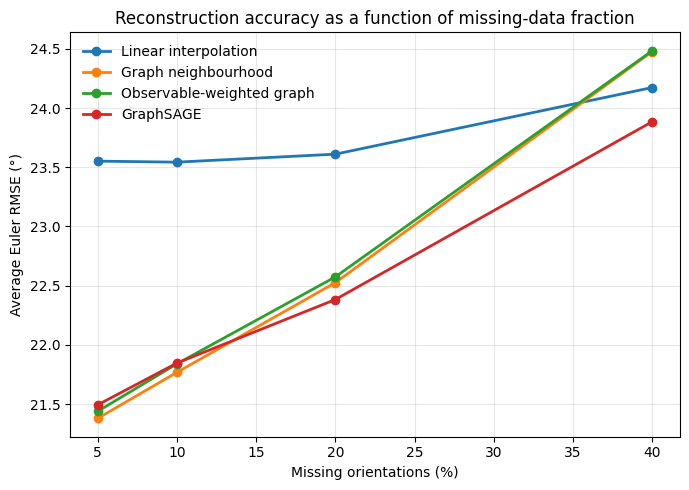

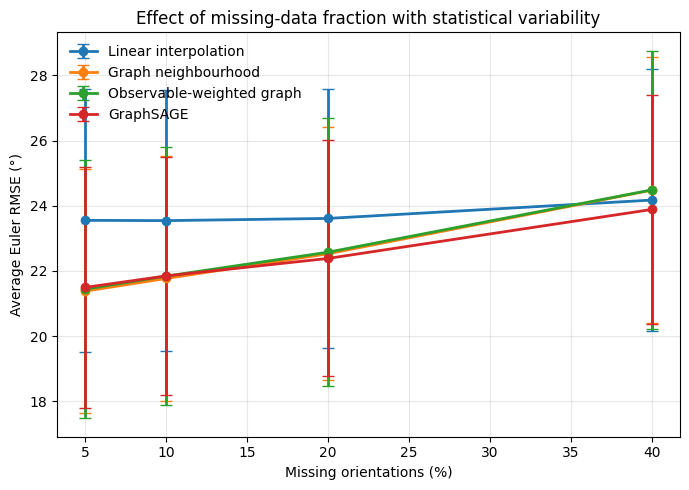

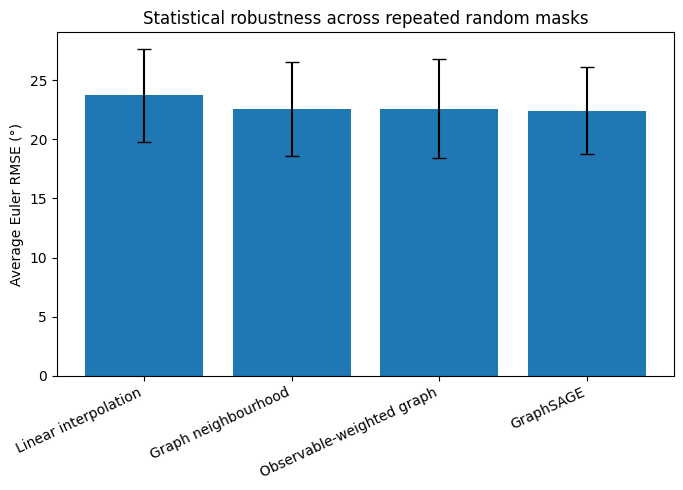

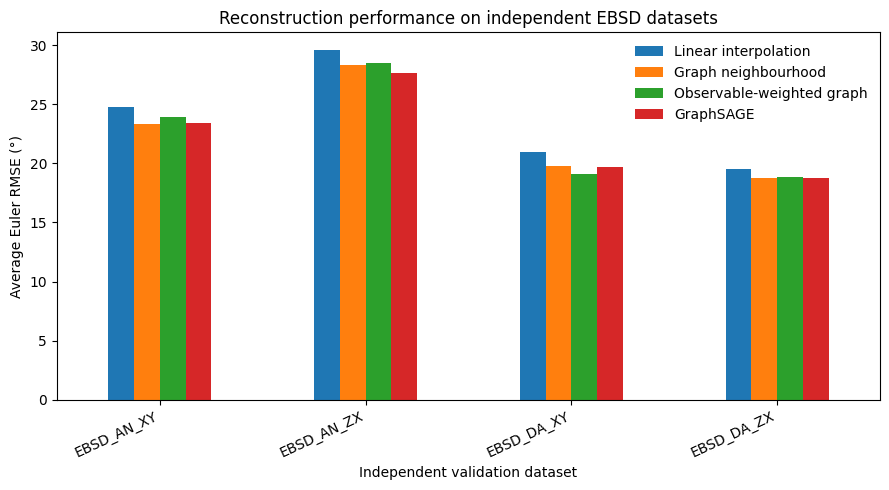

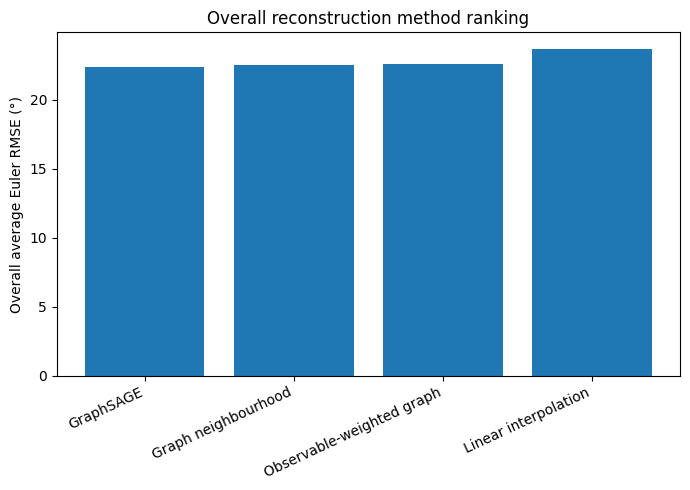

Done.
Figures saved to: /content/drive/MyDrive/EBSD Paper2/paper_figures_tables/figures
Tables saved to: /content/drive/MyDrive/EBSD Paper2/paper_figures_tables/tables


In [ ]:
# ============================================================
# Generate final manuscript figures and tables
# Figures 6–10 + Tables 4–5
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"

CSV_PATH = f"{PROJECT_DIR}/results/experiment_13_graphsage_new_datasets/Experiment_13_combined_baselines_plus_GraphSAGE.csv"

OUT_DIR = f"{PROJECT_DIR}/paper_figures_tables"
FIG_DIR = f"{OUT_DIR}/figures"
TABLE_DIR = f"{OUT_DIR}/tables"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# -----------------------------
# Load data
# -----------------------------
df = pd.read_csv(CSV_PATH)

# Cleaner method names
method_map = {
    "linear": "Linear interpolation",
    "graph_4_neighbour_mean": "Graph neighbourhood",
    "observable_weighted_graph": "Observable-weighted graph",
    "GraphSAGE_sincos": "GraphSAGE"
}

df["method_clean"] = df["method"].map(method_map)

method_order = [
    "Linear interpolation",
    "Graph neighbourhood",
    "Observable-weighted graph",
    "GraphSAGE"
]

# -----------------------------
# Summary data
# -----------------------------
summary = (
    df.groupby(["method_clean", "missing_percent"])
    .agg(
        mean_rmse=("Average_Euler_RMSE", "mean"),
        std_rmse=("Average_Euler_RMSE", "std"),
        mean_mae=("Average_Euler_MAE", "mean"),
        std_mae=("Average_Euler_MAE", "std"),
        n=("Average_Euler_RMSE", "count")
    )
    .reset_index()
)

overall = (
    df.groupby("method_clean")
    .agg(
        mean_rmse=("Average_Euler_RMSE", "mean"),
        std_rmse=("Average_Euler_RMSE", "std"),
        mean_mae=("Average_Euler_MAE", "mean"),
        std_mae=("Average_Euler_MAE", "std"),
        n=("Average_Euler_RMSE", "count")
    )
    .reset_index()
)

overall["method_clean"] = pd.Categorical(
    overall["method_clean"],
    categories=method_order,
    ordered=True
)
overall = overall.sort_values("method_clean")

# Save overall table
overall.to_csv(f"{TABLE_DIR}/Table_4_Statistical_Robustness.csv", index=False)

# -----------------------------
# Figure 6: Overall RMSE vs missing %
# -----------------------------
plt.figure(figsize=(7, 5))

for method in method_order:
    s = summary[summary["method_clean"] == method].sort_values("missing_percent")
    plt.plot(
        s["missing_percent"],
        s["mean_rmse"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Missing orientations (%)")
plt.ylabel("Average Euler RMSE (°)")
plt.title("Reconstruction accuracy as a function of missing-data fraction")
plt.grid(True, alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure_6_RMSE_vs_missing_fraction.png", dpi=600)
plt.savefig(f"{FIG_DIR}/Figure_6_RMSE_vs_missing_fraction.pdf")
plt.show()

# -----------------------------
# Figure 7: RMSE with error bars
# -----------------------------
plt.figure(figsize=(7, 5))

for method in method_order:
    s = summary[summary["method_clean"] == method].sort_values("missing_percent")
    plt.errorbar(
        s["missing_percent"],
        s["mean_rmse"],
        yerr=s["std_rmse"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.xlabel("Missing orientations (%)")
plt.ylabel("Average Euler RMSE (°)")
plt.title("Effect of missing-data fraction with statistical variability")
plt.grid(True, alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure_7_RMSE_errorbars_missing_fraction.png", dpi=600)
plt.savefig(f"{FIG_DIR}/Figure_7_RMSE_errorbars_missing_fraction.pdf")
plt.show()

# -----------------------------
# Figure 8: Statistical robustness by method
# -----------------------------
plt.figure(figsize=(7, 5))

plt.bar(
    overall["method_clean"],
    overall["mean_rmse"],
    yerr=overall["std_rmse"],
    capsize=5
)

plt.ylabel("Average Euler RMSE (°)")
plt.title("Statistical robustness across repeated random masks")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure_8_Statistical_robustness.png", dpi=600)
plt.savefig(f"{FIG_DIR}/Figure_8_Statistical_robustness.pdf")
plt.show()

# -----------------------------
# Figure 9: Independent validation datasets
# -----------------------------
validation_df = df[df["dataset"].str.startswith("EBSD_")].copy()

validation_summary = (
    validation_df.groupby(["dataset", "method_clean"])
    .agg(mean_rmse=("Average_Euler_RMSE", "mean"))
    .reset_index()
)

pivot_val = validation_summary.pivot(
    index="dataset",
    columns="method_clean",
    values="mean_rmse"
)

pivot_val = pivot_val[method_order]

pivot_val.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Average Euler RMSE (°)")
plt.xlabel("Independent validation dataset")
plt.title("Reconstruction performance on independent EBSD datasets")
plt.xticks(rotation=25, ha="right")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure_9_Independent_validation.png", dpi=600)
plt.savefig(f"{FIG_DIR}/Figure_9_Independent_validation.pdf")
plt.show()

pivot_val.to_csv(f"{TABLE_DIR}/Table_5_Independent_validation_results.csv")

# -----------------------------
# Figure 10: Overall method ranking
# -----------------------------
ranked = overall.sort_values("mean_rmse")

plt.figure(figsize=(7, 5))
plt.bar(
    ranked["method_clean"],
    ranked["mean_rmse"]
)

plt.ylabel("Overall average Euler RMSE (°)")
plt.title("Overall reconstruction method ranking")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/Figure_10_Overall_method_ranking.png", dpi=600)
plt.savefig(f"{FIG_DIR}/Figure_10_Overall_method_ranking.pdf")
plt.show()

# Save ranking table
ranked.to_csv(f"{TABLE_DIR}/Table_6_Overall_method_ranking.csv", index=False)

print("Done.")
print("Figures saved to:", FIG_DIR)
print("Tables saved to:", TABLE_DIR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.spatial.transform import Rotation
PROJECT_DIR = '/content/drive/MyDrive/EBSD Paper2'
DATA_DIR = f'{PROJECT_DIR}/datasets'
RESULTS_DIR = f'{PROJECT_DIR}/results/experiment_1_symmetry_completion'
MODEL_DIR = f'{RESULTS_DIR}/models'
LOG_DIR = f'{RESULTS_DIR}/logs'
FIG_DIR = f'{RESULTS_DIR}/figures'
PRED_DIR = f'{RESULTS_DIR}/predictions'
for d in [RESULTS_DIR,MODEL_DIR,LOG_DIR,FIG_DIR,PRED_DIR]: os.makedirs(d,exist_ok=True)
CROP_SIZE=256
GRAPHSAGE_EPOCHS=100
LEARNING_RATE=5e-4
HIDDEN_CHANNELS=128
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device)
if device.type!='cuda': raise RuntimeError('Enable a GPU in Colab before running 30 trainings.')


Mounted at /content/drive
Device: cuda


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/EBSD Paper2")
DATA_DIR = PROJECT_DIR / "datasets"

print("Project exists:", PROJECT_DIR.exists())
print("Datasets folder exists:", DATA_DIR.exists())

for file in sorted(DATA_DIR.glob("*.ctf")):
    print(file.name, f"({file.stat().st_size / 1e6:.1f} MB)")


Project exists: True
Datasets folder exists: False


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

# Search Google Drive for the original EBSD datasets
for name in [
    "EBSD_AN_XY.ctf",
    "EBSD_AN_ZX.ctf",
    "EBSD_DA_XY.ctf",
    "EBSD_DA_ZX.ctf"
]:
    matches = list(root.rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches[:5]:
            print("  FOUND:", path)
    else:
        print("  NOT FOUND")



EBSD_AN_XY.ctf:
  FOUND: /content/drive/MyDrive/EBSD Paper2/EBSD_AN_XY.ctf
  FOUND: /content/drive/MyDrive/EBSD Paper2 (1)/datasets/EBSD_AN_XY.ctf

EBSD_AN_ZX.ctf:
  FOUND: /content/drive/MyDrive/EBSD Paper2/EBSD_AN_ZX.ctf
  FOUND: /content/drive/MyDrive/EBSD Paper2 (1)/datasets/EBSD_AN_ZX.ctf

EBSD_DA_XY.ctf:
  FOUND: /content/drive/MyDrive/EBSD Paper2/EBSD_DA_XY.ctf
  FOUND: /content/drive/MyDrive/EBSD Paper2 (1)/datasets/EBSD_DA_XY.ctf

EBSD_DA_ZX.ctf:
  FOUND: /content/drive/MyDrive/EBSD Paper2/EBSD_DA_ZX.ctf
  FOUND: /content/drive/MyDrive/EBSD Paper2 (1)/datasets/EBSD_DA_ZX.ctf


In [ ]:

from pathlib import Path
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
DATA_DIR = PROJECT_DIR / "datasets"
RESULTS_DIR = PROJECT_DIR / "results" / "experiment_01_symmetry_aware"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = [
    "EBSD_AN_XY.ctf",
    "EBSD_AN_ZX.ctf",
    "EBSD_DA_XY.ctf",
    "EBSD_DA_ZX.ctf"
]

for name in DATASETS:
    path = DATA_DIR / name
    assert path.is_file(), f"Missing dataset: {path}"
    print(f"✓ {name}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDevice:", device)
print("Results directory:", RESULTS_DIR)


✓ EBSD_AN_XY.ctf
✓ EBSD_AN_ZX.ctf
✓ EBSD_DA_XY.ctf
✓ EBSD_DA_ZX.ctf

Device: cuda
Results directory: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware


In [ ]:

from pathlib import Path

roots = [
    Path("/content/drive/MyDrive/EBSD Paper2"),
    Path("/content/drive/MyDrive/EBSD Paper2 (1)")
]

for root in roots:
    checkpoints = [
        p for p in root.rglob("*.pt")
        if "graphsage" in p.name.lower()
    ]

    print(f"\n{root.name}: {len(checkpoints)} GraphSAGE checkpoints")

    for path in sorted(checkpoints):
        print(" ", path.relative_to(root))



EBSD Paper2: 0 GraphSAGE checkpoints

EBSD Paper2 (1): 252 GraphSAGE checkpoints
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse2_GraphSAGE_sincos_checkpoint.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse2_GraphSAGE_sincos_final.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse4_GraphSAGE_sincos_checkpoint.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse4_GraphSAGE_sincos_final.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse8_GraphSAGE_sincos_checkpoint.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_10_EBSD_crop256_sparse8_GraphSAGE_sincos_final.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_6b_EBSD_crop256_sparse2_GraphSAGE_sincos_checkpoint.pt
  results/experiment_10B_graphsage_sparse_scan/models/Figure_6b_EBSD_crop256_sparse2_GraphSAGE_sincos_final.pt
  results/

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
MODEL_DIR = (
    PROJECT_DIR
    / "results/experiment_13_graphsage_new_datasets/models"
)

required = {
    "EBSD_AN_ZX": [5, 10],
    "EBSD_AN_XY": [5, 10, 20, 40],
}

records = []

for dataset, levels in required.items():
    for missing in levels:
        for seed in range(1, 6):
            name = (
                f"{dataset}_crop256_missing{missing}"
                f"_seed{seed}_GraphSAGE_sincos_final.pt"
            )
            path = MODEL_DIR / name
            records.append({
                "dataset": dataset,
                "missing_pct": missing,
                "seed": seed,
                "exists": path.is_file(),
                "size_MB": round(path.stat().st_size / 1e6, 2)
                           if path.is_file() else None
            })

df = pd.DataFrame(records)

print(df.to_string(index=False))
print("\nCheckpoints found:", df["exists"].sum(), "/ 30")
print("All present:", df["exists"].all())


   dataset  missing_pct  seed  exists  size_MB
EBSD_AN_ZX            5     1    True     0.29
EBSD_AN_ZX            5     2    True     0.29
EBSD_AN_ZX            5     3    True     0.29
EBSD_AN_ZX            5     4    True     0.29
EBSD_AN_ZX            5     5    True     0.29
EBSD_AN_ZX           10     1    True     0.29
EBSD_AN_ZX           10     2    True     0.29
EBSD_AN_ZX           10     3    True     0.29
EBSD_AN_ZX           10     4    True     0.29
EBSD_AN_ZX           10     5    True     0.29
EBSD_AN_XY            5     1    True     0.29
EBSD_AN_XY            5     2    True     0.29
EBSD_AN_XY            5     3    True     0.29
EBSD_AN_XY            5     4    True     0.29
EBSD_AN_XY            5     5    True     0.29
EBSD_AN_XY           10     1    True     0.29
EBSD_AN_XY           10     2    True     0.29
EBSD_AN_XY           10     3    True     0.29
EBSD_AN_XY           10     4    True     0.29
EBSD_AN_XY           10     5    True     0.29
EBSD_AN_XY   

In [ ]:

import torch
from pathlib import Path

model_dir = (
    Path("/content/drive/MyDrive/EBSD Paper2 (1)")
    / "results/experiment_13_graphsage_new_datasets/models"
)

checkpoint = (
    model_dir /
    "EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos_final.pt"
)

# Load only checkpoints produced by your own trusted project.
try:
    obj = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=True
    )
except Exception as e:
    print("Safe checkpoint loading failed:", repr(e))
    raise

print("Checkpoint type:", type(obj).__name__)

if isinstance(obj, dict):
    print("\nTop-level keys:")
    for key, value in obj.items():
        if isinstance(value, torch.Tensor):
            print(key, tuple(value.shape))
        elif isinstance(value, dict):
            print(key, "dictionary with", len(value), "entries")
        else:
            print(key, type(value).__name__, repr(value)[:120])


Checkpoint type: OrderedDict

Top-level keys:
layer1.kernel (1, 1, 3, 3)
layer1.self_linear.weight (128, 11, 1, 1)
layer1.self_linear.bias (128,)
layer1.neigh_linear.weight (128, 11, 1, 1)
layer1.neigh_linear.bias (128,)
layer2.kernel (1, 1, 3, 3)
layer2.self_linear.weight (128, 128, 1, 1)
layer2.self_linear.bias (128,)
layer2.neigh_linear.weight (128, 128, 1, 1)
layer2.neigh_linear.bias (128,)
layer3.kernel (1, 1, 3, 3)
layer3.self_linear.weight (128, 128, 1, 1)
layer3.self_linear.bias (128,)
layer3.neigh_linear.weight (128, 128, 1, 1)
layer3.neigh_linear.bias (128,)
output.weight (6, 128, 1, 1)
output.bias (6,)


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

folders = [
    "results/experiment_13_graphsage_new_datasets",
    "results/experiment_11_statistical_validation",
    "results/experiment_01_symmetry_aware"
]

for folder in folders:
    root = project / folder
    print(f"\n--- {folder} ---")

    if not root.exists():
        print("Folder not found")
        continue

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".csv", ".json", ".npz"}
    )

    print("Result files:", len(files))

    for p in files[:30]:
        print(p.relative_to(project))



--- results/experiment_13_graphsage_new_datasets ---
Result files: 89
results/experiment_13_graphsage_new_datasets/Copy of Experiment_13_combined_baselines_plus_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/Experiment_13_GraphSAGE_IN_PROGRESS.csv
results/experiment_13_graphsage_new_datasets/Experiment_13_GraphSAGE_raw_results.csv
results/experiment_13_graphsage_new_datasets/Experiment_13_combined_baselines_plus_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/logs/EBSD_AN_XY_crop256_missing10_seed1_GraphSAGE_sincos_loss.csv
results/experiment_13_graphsage_new_datasets/logs/EBSD_AN_XY_crop256_missing10_seed2_GraphSAGE_sincos_loss.csv
results/experiment_13_graphsage_new_datasets/logs/EBSD_AN_XY_crop256_missing10_seed3_GraphSAGE_sincos_loss.csv
results/experiment_13_graphsage_new_datasets/logs/EBSD_AN_XY_crop256_missing10_seed4_GraphSAGE_sincos_loss.csv
results/experiment_13_graphsage_new_datasets/logs/EBSD_AN_XY_crop256_missing10_seed5_GraphSAGE_sincos_loss.csv
re

In [ ]:

import pandas as pd
from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

csv_files = [
    project / "results/experiment_13_graphsage_new_datasets"
    / "Experiment_13_GraphSAGE_raw_results.csv",

    project / "results/experiment_13_graphsage_new_datasets"
    / "Experiment_13_combined_baselines_plus_GraphSAGE.csv",

    project / "results/experiment_11_statistical_validation"
    / "Experiment_11_statistical_validation_raw_results.csv",
]

for path in csv_files:
    print("\n" + "=" * 70)
    print("FILE:", path.name)

    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))



FILE: Experiment_13_GraphSAGE_raw_results.csv
Rows: 80
Columns: ['dataset', 'file', 'crop_size', 'valid_pixels', 'missing_fraction', 'missing_percent', 'method', 'seed', 'epochs', 'learning_rate', 'hidden_channels', 'Euler1_MAE', 'Euler1_RMSE', 'Euler2_MAE', 'Euler2_RMSE', 'Euler3_MAE', 'Euler3_RMSE', 'Average_Euler_RMSE', 'Average_Euler_MAE']

First 3 rows:
   dataset           file crop_size  valid_pixels  missing_fraction  missing_percent           method  seed  epochs  learning_rate  hidden_channels  Euler1_MAE  Euler1_RMSE  Euler2_MAE  Euler2_RMSE  Euler3_MAE  Euler3_RMSE  Average_Euler_RMSE  Average_Euler_MAE
EBSD_AN_XY EBSD_AN_XY.ctf   256x256         58152              0.05                5 GraphSAGE_sincos     1     100         0.0005              128   18.458183    29.322192   17.290037    25.896858    7.553694    11.057958           22.092336          14.433971
EBSD_AN_XY EBSD_AN_XY.ctf   256x256         58152              0.05                5 GraphSAGE_sincos     2     10

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from itertools import product

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
source = (
    project / "results/experiment_13_graphsage_new_datasets"
    / "Experiment_13_combined_baselines_plus_GraphSAGE.csv"
)

df = pd.read_csv(source)

datasets = ["EBSD_AN_XY", "EBSD_AN_ZX", "EBSD_DA_XY", "EBSD_DA_ZX"]
levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]
methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

keys = ["dataset", "missing_percent", "seed", "method"]

expected = pd.MultiIndex.from_tuples(
    list(product(datasets, levels, seeds, methods)),
    names=keys
)

actual = pd.MultiIndex.from_frame(df[keys])

missing = expected.difference(actual)
unexpected = actual.difference(expected)
duplicates = df.duplicated(keys).sum()

metric_cols = [
    "Euler1_MAE", "Euler1_RMSE",
    "Euler2_MAE", "Euler2_RMSE",
    "Euler3_MAE", "Euler3_RMSE",
    "Average_Euler_RMSE", "Average_Euler_MAE"
]

metrics = df[metric_cols].apply(pd.to_numeric, errors="coerce")
invalid_rows = (~np.isfinite(metrics.to_numpy())).any(axis=1).sum()

print("Rows:", len(df))
print("Expected combinations:", len(expected))
print("Missing combinations:", len(missing))
print("Unexpected combinations:", len(unexpected))
print("Duplicate combinations:", duplicates)
print("Rows with invalid metrics:", invalid_rows)

print("\nMethod counts:")
print(df["method"].value_counts().to_string())

if len(missing):
    print("\nMissing combinations:")
    print(missing.tolist()[:20])

if len(unexpected):
    print("\nUnexpected combinations:")
    print(unexpected.tolist()[:20])

complete = (
    len(df) == len(expected)
    and len(missing) == 0
    and len(unexpected) == 0
    and duplicates == 0
    and invalid_rows == 0
)

print("\nCOMPLETE AND VALID MATRIX:", complete)


Rows: 320
Expected combinations: 320
Missing combinations: 0
Unexpected combinations: 0
Duplicate combinations: 0
Rows with invalid metrics: 0

Method counts:
method
linear                       80
graph_4_neighbour_mean       80
observable_weighted_graph    80
GraphSAGE_sincos             80

COMPLETE AND VALID MATRIX: True


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

keywords = [
    "symmetry", "disorientation", "misorientation",
    "euler", "graphsage"
]

files = [
    p for p in project.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".py", ".ipynb"}
    and ".ipynb_checkpoints" not in str(p)
]

print("Python files and notebooks:", len(files))

for p in sorted(files):
    try:
        content = p.read_text(
            encoding="utf-8", errors="replace"
        ).lower()
        matches = [k for k in keywords if k in content]

        if matches:
            print(
                p.relative_to(project),
                "|",
                ", ".join(matches)
            )
    except OSError:
        pass


Python files and notebooks: 3
ebsd_graph/io.py | euler


In [ ]:

!python "/content/experiment1_audit_existing_symmetry.py" \
    --root "/content/drive/MyDrive/EBSD Paper2 (1)" \
    --output "/content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/audit"


python3: can't open file '/content/experiment1_audit_existing_symmetry.py': [Errno 2] No such file or directory


In [ ]:

from pathlib import Path

script = Path("/content/experiment1_audit_existing_symmetry.py")

print("Script exists:", script.exists())

if script.exists():
    source = script.read_text(encoding="utf-8")

    source = source.replace(
        "parser.parse_args()",
        "parser.parse_known_args()[0]"
    )

    script.write_text(source, encoding="utf-8")
    print("Argument parsing fixed.")


Script exists: False


In [ ]:

from pathlib import Path

locations = [
    Path("/content"),
    Path("/content/drive/MyDrive/EBSD Paper2"),
    Path("/content/drive/MyDrive/EBSD Paper2 (1)")
]

matches = []

for root in locations:
    if root.exists():
        matches.extend(
            root.rglob("experiment1_audit_existing_symmetry.py")
        )

matches = sorted(set(matches))

if matches:
    print("Script found:")
    for path in matches:
        print(path)
else:
    print("SCRIPT NOT FOUND — upload required")


SCRIPT NOT FOUND — upload required


In [ ]:

from pathlib import Path
import itertools
import re
import numpy as np
import pandas as pd

# 1. Project locations
PROJECT_DIR = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
OUTPUT_DIR = PROJECT_DIR / "results" / "experiment_01_symmetry_aware" / "audit"

assert PROJECT_DIR.exists(), "Project directory not found. Mount Google Drive first."
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Expected experiment combinations
DATASETS = ["EBSD_AN_XY", "EBSD_AN_ZX", "EBSD_DA_XY", "EBSD_DA_ZX"]
METHODS = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]
LEVELS = [5, 10, 20, 40]
SEEDS = range(1, 6)

KEYS = ["dataset", "missing_percent", "seed", "method"]
METRICS = [
    "disorientation_mae",
    "disorientation_rmse",
    "disorientation_median"
]

# 3. Find existing symmetry-aware CSVs
found = []
skipped = []

for path in sorted(PROJECT_DIR.rglob("*.csv")):

    if OUTPUT_DIR in path.parents:
        continue

    name = path.name.lower()

    if "symmetry" not in name and "disorientation" not in name:
        continue

    try:
        df = pd.read_csv(path)
    except Exception as e:
        skipped.append((str(path), str(e)))
        continue

    required = METRICS + ["method", "seed"]

    if not set(required).issubset(df.columns):
        skipped.append((str(path), "Missing required columns"))
        continue

    # Identify dataset
    if "dataset" not in df.columns:
        matches = [d for d in DATASETS if d.lower() in name]

        if len(matches) != 1:
            skipped.append((str(path), "Cannot identify dataset"))
            continue

        df["dataset"] = matches[0]

    # Identify missing-data percentage
    if "missing_percent" not in df.columns:
        match = re.search(r"missing(5|10|20|40)(?!\d)", name)

        if match is None:
            skipped.append((str(path), "Cannot identify missing percentage"))
            continue

        df["missing_percent"] = int(match.group(1))

    # Convert numeric columns
    for col in ["seed", "missing_percent"] + METRICS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Keep valid experiment combinations
    df = df[
        df["dataset"].isin(DATASETS)
        & df["method"].isin(METHODS)
        & df["seed"].isin(SEEDS)
        & df["missing_percent"].isin(LEVELS)
    ].copy()

    df = df[np.isfinite(df[METRICS].to_numpy()).all(axis=1)]

    df["source_file"] = str(path.relative_to(PROJECT_DIR))

    found.append(df[KEYS + METRICS + ["source_file"]])

# 4. Combine candidate results
COLUMNS = KEYS + METRICS + ["source_file"]

all_rows = (
    pd.concat(found, ignore_index=True)
    if found else pd.DataFrame(columns=COLUMNS)
)

all_rows.to_csv(OUTPUT_DIR / "all_candidate_rows.csv", index=False)

# 5. Detect conflicting results
consistent = []
conflicts = []

for key, group in all_rows.groupby(KEYS):

    differences = {
        metric: group[metric].max() - group[metric].min()
        for metric in METRICS
    }

    if any(value > 1e-5 for value in differences.values()):
        conflicts.append({
            **dict(zip(KEYS, key)),
            "sources": "; ".join(group["source_file"]),
            "n_records": len(group),
            **{m + "_range": differences[m] for m in METRICS}
        })
    else:
        consistent.append(group.iloc[0].to_dict())

clean = pd.DataFrame(consistent, columns=COLUMNS)
conflict_df = pd.DataFrame(conflicts)

# 6. Check all 320 expected combinations
expected = pd.MultiIndex.from_tuples(
    list(itertools.product(DATASETS, LEVELS, SEEDS, METHODS)),
    names=KEYS
)

if len(clean):
    observed = pd.MultiIndex.from_frame(clean[KEYS])
else:
    observed = pd.MultiIndex.from_tuples([], names=KEYS)

missing = expected.difference(observed)
missing_df = pd.DataFrame(missing.tolist(), columns=KEYS)

# 7. Save audit reports
clean.to_csv(
    OUTPUT_DIR / "consistent_candidate_results.csv", index=False
)
conflict_df.to_csv(
    OUTPUT_DIR / "conflicting_combinations.csv", index=False
)
missing_df.to_csv(
    OUTPUT_DIR / "missing_or_conflicted_combinations.csv", index=False
)
pd.DataFrame(
    skipped, columns=["file", "reason"]
).to_csv(OUTPUT_DIR / "skipped_files.csv", index=False)

# 8. Print summary
print("=" * 55)
print("EXPERIMENT 1 — SYMMETRY-AWARE RESULTS AUDIT")
print("=" * 55)
print("Candidate rows:", len(all_rows))
print("Unique consistent combinations:", len(clean))
print("Conflicting combinations:", len(conflict_df))
print("Missing or conflicted:", len(missing_df), "of 320")
print("Files skipped:", len(skipped))

print("\nCompleted combinations by dataset:")
if len(clean):
    print(clean.groupby("dataset").size().to_string())
else:
    print("No matching results found.")

print("\nMissing combinations by dataset:")
if len(missing_df):
    print(missing_df.groupby("dataset").size().to_string())
else:
    print("None")

print("\nAudit saved to:")
print(OUTPUT_DIR)

print("\nNOTE: This checks existing CSV consistency only.")
print("It does not validate crystallographic conventions or predictions.")


EXPERIMENT 1 — SYMMETRY-AWARE RESULTS AUDIT
Candidate rows: 0
Unique consistent combinations: 0
Conflicting combinations: 0
Missing or conflicted: 320 of 320
Files skipped: 0

Completed combinations by dataset:
No matching results found.

Missing combinations by dataset:
dataset
EBSD_AN_XY    80
EBSD_AN_ZX    80
EBSD_DA_XY    80
EBSD_DA_ZX    80

Audit saved to:
/content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/audit

NOTE: This checks existing CSV consistency only.
It does not validate crystallographic conventions or predictions.


In [ ]:

from pathlib import Path
from collections import Counter

DRIVE_ROOT = Path("/content/drive/MyDrive")

keywords = [
    "symmetry",
    "disorientation",
    "five_seed",
    "all_missing_levels",
    "convention_audit"
]

matches = []

for path in DRIVE_ROOT.rglob("*"):
    if not path.is_file():
        continue

    filename = path.name.lower()

    if any(word in filename for word in keywords):
        matches.append(path)

print("=" * 60)
print("SEARCH FOR EXISTING SYMMETRY-AWARE RESULTS")
print("=" * 60)

print(f"\nTotal matching files: {len(matches)}")

for path in sorted(matches):
    print(path)

print("\nFile types:")
print(dict(Counter(p.suffix.lower() for p in matches)))


SEARCH FOR EXISTING SYMMETRY-AWARE RESULTS

Total matching files: 0

File types:
{}


In [ ]:

from pathlib import Path
from collections import Counter

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

checkpoints = list(project.rglob("*.pt"))
csv_files = list(project.rglob("*.csv"))
notebooks = list(project.rglob("*.ipynb"))
scripts = list(project.rglob("*.py"))

print("PROJECT INVENTORY")
print("=" * 55)
print("GraphSAGE checkpoints (.pt):", len(checkpoints))
print("CSV files:", len(csv_files))
print("Notebooks:", len(notebooks))
print("Python scripts:", len(scripts))

print("\nEXPERIMENT 13 RESULT FILES:")
for p in csv_files:
    if "experiment_13" in str(p).lower():
        print(p.relative_to(project))

print("\nPYTHON SCRIPTS:")
for p in scripts[:30]:
    print(p.relative_to(project))

print("\nCHECKPOINT EXAMPLES:")
for p in checkpoints[:10]:
    print(p.relative_to(project))


PROJECT INVENTORY
GraphSAGE checkpoints (.pt): 284
CSV files: 204
Notebooks: 0
Python scripts: 3

EXPERIMENT 13 RESULT FILES:
results/experiment_13_graphsage_new_datasets/Experiment_13_GraphSAGE_IN_PROGRESS.csv
results/experiment_13_graphsage_new_datasets/Experiment_13_GraphSAGE_raw_results.csv
results/experiment_13_graphsage_new_datasets/Experiment_13_combined_baselines_plus_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/Copy of Experiment_13_combined_baselines_plus_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/tables/Experiment_13_GraphSAGE_mean_std_summary.csv
results/experiment_13_graphsage_new_datasets/tables/Experiment_13_combined_mean_std_summary.csv
results/experiment_13_graphsage_new_datasets/tables/Experiment_13_best_method_by_dataset_with_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/tables/Experiment_13_overall_method_ranking_with_GraphSAGE.csv
results/experiment_13_graphsage_new_datasets/tables/Experiment_13_wilcoxon_tests_vs_GraphSAGE

In [ ]:

from pathlib import Path
from collections import Counter

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

# File formats commonly used for saved model predictions
extensions = {".npz", ".npy", ".pkl", ".pickle", ".parquet", ".h5", ".hdf5"}

files = [
    p for p in project.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("=" * 60)
print("SAVED PREDICTION / ARRAY FILE INVENTORY")
print("=" * 60)

print("Total candidate files:", len(files))
print("By extension:", dict(Counter(p.suffix.lower() for p in files)))

print("\nFILES:")
for p in sorted(files)[:100]:
    print(p.relative_to(project))

print("\nTotal listed:", min(len(files), 100))


SAVED PREDICTION / ARRAY FILE INVENTORY
Total candidate files: 0
By extension: {}

FILES:

Total listed: 0


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

notebooks = sorted(root.rglob("*.ipynb"))

print("NOTEBOOK SEARCH")
print("=" * 55)
print("Total notebooks:", len(notebooks))

for p in notebooks:
    name = p.name.lower()
    if any(k in name for k in ["ebsd", "graph", "experiment", "paper2"]):
        print(p)


NOTEBOOK SEARCH
Total notebooks: 11
/content/drive/MyDrive/Colab Notebooks/01_EBSDGraph_Dataset_Catalogue.ipynb
/content/drive/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb


In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "GraphSAGE",
    "SAGEConv",
    "edge_index",
    "sin",
    "cos",
    "missing_mask",
    "torch.load",
    "Euler",
    "orientation"
]

matches = []

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    found = [k for k in keywords if k.lower() in source.lower()]

    if found:
        matches.append((i, found, source))

print("=" * 60)
print("ORIGINAL NOTEBOOK — CODE SEARCH")
print("=" * 60)
print("Total cells:", len(notebook["cells"]))
print("Matching code cells:", len(matches))

for i, found, source in matches:
    print(f"\nCELL {i} | Keywords: {', '.join(found)}")
    print("-" * 50)

    lines = source.splitlines()

    for line in lines[:12]:
        print(line[:160])

    if len(lines) > 12:
        print(f"... ({len(lines) - 12} additional lines)")


ORIGINAL NOTEBOOK — CODE SEARCH
Total cells: 17
Matching code cells: 11

CELL 3 | Keywords: sin, missing_mask, Euler, orientation
--------------------------------------------------
# ============================================================
# Experiment 1: Missing-pixel reconstruction for EBSD .ctf maps
# Dataset: Figure_10_EBSD.ctf / Figure_6b_EBSD.ctf
# Baselines: nearest, linear, cubic interpolation
# Outputs: CSV metrics + reconstruction figures
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
... (277 additional lines)

CELL 5 | Keywords: Euler
--------------------------------------------------
io_code = r'''
import pandas as pd

def load_ctf(path):
    """
    Load Oxford/HKL .ctf EBSD file.

    Returns:
        df: pandas DataFrame with columns such as:
        Phase, X, Y, Bands, Error, Euler1, Euler2, Euler3, MAD, BC, BS
    """

... (33 additional lines)

CELL 7 | Key

In [ ]:

import json
from pathlib import Path

root = Path("/content/drive/MyDrive")

keywords = [
    "SAGEConv",
    "GraphSAGE",
    "torch_geometric",
    "GraphSAGE_sincos"
]

print("=" * 65)
print("SEARCHING NOTEBOOKS FOR GRAPHSAGE IMPLEMENTATION")
print("=" * 65)

for path in sorted(root.rglob("*.ipynb")):
    try:
        with open(path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        matches = []

        for i, cell in enumerate(notebook.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            found = [k for k in keywords if k.lower() in source.lower()]

            if found:
                matches.append((i, found))

        if matches:
            print("\nNOTEBOOK:", path)
            for i, found in matches:
                print(f"  Cell {i}: {', '.join(found)}")

    except Exception as e:
        print("Could not read:", path.name, str(e)[:100])

print("\nSearch complete.")


SEARCHING NOTEBOOKS FOR GRAPHSAGE IMPLEMENTATION

Search complete.


In [ ]:

from pathlib import Path
from collections import Counter
import torch

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
checkpoints = sorted(project.rglob("*.pt"))

print("=" * 60)
print("GRAPHSAGE CHECKPOINT AUDIT")
print("=" * 60)

print("Total checkpoint files:", len(checkpoints))

types = Counter()
examples = {}

for path in checkpoints:
    name = path.name.lower()

    if "final" in name:
        category = "final"
    elif "checkpoint" in name:
        category = "intermediate"
    else:
        category = "other"

    types[category] += 1
    examples.setdefault(category, path)

print("\nCheckpoint categories:")
for category, count in types.items():
    print(f"{category}: {count}")

print("\nEXAMPLE CHECKPOINT CONTENTS")

for category, path in examples.items():
    print(f"\n{category.upper()}: {path.name}")

    try:
        data = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print("Object type:", type(data).__name__)

        if isinstance(data, dict):
            print("Top-level keys:")
            for key in list(data.keys())[:20]:
                value = data[key]

                if isinstance(value, torch.Tensor):
                    print(f"  {key}: {tuple(value.shape)}")
                else:
                    print(f"  {key}: {type(value).__name__}")

    except Exception as e:
        print("Load error:", str(e)[:250])


GRAPHSAGE CHECKPOINT AUDIT
Total checkpoint files: 284

Checkpoint categories:
intermediate: 142
final: 142

EXAMPLE CHECKPOINT CONTENTS

INTERMEDIATE: Figure_10_EBSD_crop256_missing10_sincos_checkpoint.pt
Object type: OrderedDict
Top-level keys:
  layer1.kernel: (1, 1, 3, 3)
  layer1.self_linear.weight: (128, 11, 1, 1)
  layer1.self_linear.bias: (128,)
  layer1.neigh_linear.weight: (128, 11, 1, 1)
  layer1.neigh_linear.bias: (128,)
  layer2.kernel: (1, 1, 3, 3)
  layer2.self_linear.weight: (128, 128, 1, 1)
  layer2.self_linear.bias: (128,)
  layer2.neigh_linear.weight: (128, 128, 1, 1)
  layer2.neigh_linear.bias: (128,)
  layer3.kernel: (1, 1, 3, 3)
  layer3.self_linear.weight: (128, 128, 1, 1)
  layer3.self_linear.bias: (128,)
  layer3.neigh_linear.weight: (128, 128, 1, 1)
  layer3.neigh_linear.bias: (128,)
  output.weight: (6, 128, 1, 1)
  output.bias: (6,)

FINAL: Figure_10_EBSD_crop256_missing10_sincos_final.pt
Object type: OrderedDict
Top-level keys:
  layer1.kernel: (1, 1, 3, 3)

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

terms = [
    "self_linear",
    "neigh_linear",
    "class GraphSAGE",
    "class GraphSage",
    "class GraphSAGELayer",
    "class GraphSAGEModel"
]

extensions = {".py", ".txt", ".md"}

matches = []

for path in root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    try:
        source = path.read_text(
            encoding="utf-8", errors="ignore"
        )
    except Exception:
        continue

    found = [term for term in terms if term.lower() in source.lower()]

    if found:
        matches.append((path, found))

print("=" * 60)
print("CUSTOM GRAPHSAGE SOURCE-CODE SEARCH")
print("=" * 60)

print("Matching files:", len(matches))

for path, found in matches:
    print("\nFILE:", path)
    print("MATCHES:", ", ".join(found))


CUSTOM GRAPHSAGE SOURCE-CODE SEARCH
Matching files: 0


In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

results_file = (
    project
    / "results"
    / "experiment_13_graphsage_new_datasets"
    / "Experiment_13_GraphSAGE_raw_results.csv"
)

df = pd.read_csv(results_file)

print("=" * 60)
print("EXPERIMENT 13 — ORIGINAL CONFIGURATION")
print("=" * 60)

print("\nCSV columns:")
print(df.columns.tolist())

print("\nFirst three rows:")
print(df.head(3).to_string(index=False))

print("\nOther configuration or metadata files:")

extensions = {".json", ".yaml", ".yml", ".toml", ".ini"}

config_files = [
    p for p in project.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Files found:", len(config_files))

for p in config_files[:30]:
    print(p.relative_to(project))


EXPERIMENT 13 — ORIGINAL CONFIGURATION

CSV columns:
['dataset', 'file', 'crop_size', 'valid_pixels', 'missing_fraction', 'missing_percent', 'method', 'seed', 'epochs', 'learning_rate', 'hidden_channels', 'Euler1_MAE', 'Euler1_RMSE', 'Euler2_MAE', 'Euler2_RMSE', 'Euler3_MAE', 'Euler3_RMSE', 'Average_Euler_RMSE', 'Average_Euler_MAE']

First three rows:
   dataset           file crop_size  valid_pixels  missing_fraction  missing_percent           method  seed  epochs  learning_rate  hidden_channels  Euler1_MAE  Euler1_RMSE  Euler2_MAE  Euler2_RMSE  Euler3_MAE  Euler3_RMSE  Average_Euler_RMSE  Average_Euler_MAE
EBSD_AN_XY EBSD_AN_XY.ctf   256x256         58152              0.05                5 GraphSAGE_sincos     1     100         0.0005              128   18.458183    29.322192   17.290037    25.896858    7.553694    11.057958           22.092336          14.433971
EBSD_AN_XY EBSD_AN_XY.ctf   256x256         58152              0.05                5 GraphSAGE_sincos     2     100       

In [ ]:

import torch
from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

model_path = (
    project
    / "results/experiment_13_graphsage_new_datasets/models"
    / "EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos_final.pt"
)

assert model_path.exists(), "Expected model checkpoint not found."

state = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

print("MODEL:", model_path.name)
print("=" * 60)

for name, tensor in state.items():
    values = tensor.float()

    print(
        f"{name:38s}"
        f" shape={str(tuple(tensor.shape)):20s}"
        f" mean={values.mean().item(): .6f}"
        f" std={values.std(unbiased=False).item(): .6f}"
    )

print("\n3x3 aggregation kernels:")

for layer in ["layer1", "layer2", "layer3"]:
    key = f"{layer}.kernel"
    if key in state:
        print(f"\n{layer}:")
        print(state[key].squeeze().numpy())


MODEL: EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos_final.pt
layer1.kernel                          shape=(1, 1, 3, 3)         mean= 0.444444 std= 0.496904
layer1.self_linear.weight              shape=(128, 11, 1, 1)      mean= 0.007584 std= 0.176107
layer1.self_linear.bias                shape=(128,)               mean= 0.005800 std= 0.166261
layer1.neigh_linear.weight             shape=(128, 11, 1, 1)      mean= 0.003146 std= 0.176227
layer1.neigh_linear.bias               shape=(128,)               mean=-0.022294 std= 0.169203
layer2.kernel                          shape=(1, 1, 3, 3)         mean= 0.444444 std= 0.496904
layer2.self_linear.weight              shape=(128, 128, 1, 1)     mean= 0.001542 std= 0.053494
layer2.self_linear.bias                shape=(128,)               mean=-0.005321 std= 0.050921
layer2.neigh_linear.weight             shape=(128, 128, 1, 1)     mean= 0.001152 std= 0.053195
layer2.neigh_linear.bias               shape=(128,)               mean= 0.0036

In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
ctf_path = project / "datasets" / "EBSD_AN_XY.ctf"

# Find the tabular data header in the CTF file
with open(ctf_path, "r", errors="replace") as f:
    lines = f.readlines()

header_index = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("Phase")
    and "Euler1" in line
)

df = pd.read_csv(
    ctf_path,
    sep=r"\s+",
    skiprows=header_index,
    engine="python"
)

print("CTF DATA INSPECTION")
print("=" * 60)
print("Columns:", df.columns.tolist())
print("Rows:", len(df))

print("\nFirst five rows:")
print(df.head().to_string(index=False))

print("\nColumn ranges:")
print(df.describe().loc[["min", "max"]].to_string())

print("\nPhase counts:")
print(df["Phase"].value_counts().to_string())


CTF DATA INSPECTION
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
Rows: 840846

First five rows:
 Phase   X   Y  Bands  Error   Euler1   Euler2  Euler3    MAD  BC  BS
     1 0.0 0.0     12      0 105.4113  22.1175 13.5631 0.5492 152  90
     1 0.5 0.0     12      0 105.4884  22.1873 13.3400 0.5383 128  73
     0 1.0 0.0      0      3   0.0000   0.0000  0.0000 0.0000  75  43
     1 1.5 0.0     10      0   5.6549 119.1777 16.1643 0.5571  87  49
     0 2.0 0.0      0      3   0.0000   0.0000  0.0000 0.0000  61  38

Column ranges:
     Phase      X      Y  Bands  Error    Euler1    Euler2   Euler3     MAD     BC     BS
min    0.0    0.0    0.0    0.0    0.0    0.0000    0.0000   0.0000  0.0000   17.0   23.0
max    2.0  529.0  396.5   12.0    3.0  359.6922  179.9798  89.9974  1.9997  196.0  113.0

Phase counts:
Phase
1    762067
0     74570
2      4209


In [ ]:

from pathlib import Path
import numpy as np

ctf_path = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)/datasets/EBSD_AN_XY.ctf"
)

with open(ctf_path, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

header_index = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("Phase") and "Euler1" in line
)

print("CTF HEADER — PHASE AND CRYSTAL INFORMATION")
print("=" * 60)

for i, line in enumerate(lines[:header_index]):
    print(f"{i:02d}: {line.rstrip()}")

print("\nCROP VALIDATION")
print("=" * 60)

# Uses the dataframe loaded in the previous cell
x_values = np.sort(df["X"].unique())
y_values = np.sort(df["Y"].unique())

print("Unique X positions:", len(x_values))
print("Unique Y positions:", len(y_values))

# Candidate crop: first 256 positions in each direction
crop = df[
    df["X"].isin(x_values[:256])
    & df["Y"].isin(y_values[:256])
]

print("Crop rows:", len(crop))
print("Indexed pixels (Phase > 0):", int((crop["Phase"] > 0).sum()))
print("Expected Experiment 13 valid pixels:", 58152)
print(
    "Count matches:",
    int((crop["Phase"] > 0).sum()) == 58152
)


CTF HEADER — PHASE AND CRYSTAL INFORMATION
00: Channel Text File
01: Prj	CTPlain_7 XY (EBSD)
02: Author
03: JobMode	Grid
04: XCells	1059
05: YCells	794
06: XStep	0.5000
07: YStep	0.5000
08: AcqE1	0.0000
09: AcqE2	0.0000
10: AcqE3	0.0000
11: Euler angles refer to Sample Coordinate system (CS0)!	Mag	230.0000	Coverage	91	Device	0	KV	15.0000	TiltAngle	70.0513	TiltAxis	0	DetectorOrientationE1	0.3545	DetectorOrientationE2	90.8314	DetectorOrientationE3	0.1138	WorkingDistance	18.4022	InsertionDistance	187.4
12: Phases	2
13: 2.954;2.954;4.729	90.000;90.000;120.000	Ti-Hex	9	0			[Titanhex v3.cry]
14: 3.192;3.192;3.192	90.000;90.000;90.000	Titanium cubic	11	229			technique de l'ingenieur

CROP VALIDATION
Unique X positions: 1059
Unique Y positions: 794
Crop rows: 65536
Indexed pixels (Phase > 0): 58152
Expected Experiment 13 valid pixels: 58152
Count matches: True


In [ ]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(path, encoding="utf-8") as f:
    nb = json.load(f)

# Cell 16 contains observable-feature graph reconstruction
source = "".join(nb["cells"][16]["source"])
lines = source.splitlines()

keywords = [
    "default_rng",
    "RandomState",
    "np.random.seed",
    "choice(",
    "missing_mask",
    "feature",
    "normalize",
    "standard",
    "Euler1",
    "Euler2",
    "Euler3"
]

print("ORIGINAL PREPROCESSING — RELEVANT CODE")
print("=" * 60)

selected = set()

for i, line in enumerate(lines):
    if any(k.lower() in line.lower() for k in keywords):
        selected.update(range(max(0, i - 2), min(len(lines), i + 4)))

for i in sorted(selected):
    print(f"{i + 1:03d}: {lines[i]}")


ORIGINAL PREPROCESSING — RELEVANT CODE
001: # ============================================================
002: # Experiment 6: Observable-feature weighted graph reconstruction
003: # Does NOT use the true missing Euler angles for weighting
004: # Features used for weights: phase, BC, MAD, spatial adjacency
005: # Saves all results and figures to Google Drive
006: # ============================================================
007: 
044:     for i, line in enumerate(lines):
045:         stripped = line.strip()
046:         if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
047:             header_idx = i
048:             break
049: 
072:     return grid.values.astype(float)
073: 
074: def create_missing_mask(valid_mask, missing_fraction, seed=42):
075:     rng = np.random.default_rng(seed)
076:     candidates = np.argwhere(valid_mask)
077: 
078:     n_missing = int(len(candidates) * missing_fraction)
079:     selected = rng.choice(len(candi

In [ ]:

import numpy as np

valid_pixels = 58152
missing_levels = [0.05, 0.10, 0.20, 0.40]

print("EXPERIMENT 13 — EXPECTED MASK COUNTS")
print("=" * 50)

for fraction in missing_levels:
    n_missing = int(valid_pixels * fraction)

    print(
        f"{fraction * 100:>4.0f}% missing:"
        f" {n_missing:>6,} masked pixels"
    )

print("\nCandidate mask-generation procedure:")
print("rng = np.random.default_rng(seed)")
print("selected = rng.choice(n_valid, size=n_missing, replace=False)")


EXPERIMENT 13 — EXPECTED MASK COUNTS
   5% missing:  2,907 masked pixels
  10% missing:  5,815 masked pixels
  20% missing: 11,630 masked pixels
  40% missing: 23,260 masked pixels

Candidate mask-generation procedure:
rng = np.random.default_rng(seed)
selected = rng.choice(n_valid, size=n_missing, replace=False)


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

for filename in ["ebsd_graph/io.py", "ebsd_graph/visualization.py"]:
    path = project / filename

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("=" * 65)

    if not path.exists():
        print("File not found")
        continue

    source = path.read_text(encoding="utf-8")
    print(source[:15000])



FILE: ebsd_graph/io.py

import pandas as pd

def load_ctf(path):
    """
    Load Oxford/HKL .ctf EBSD file.

    Returns:
        df: pandas DataFrame with columns such as:
        Phase, X, Y, Bands, Error, Euler1, Euler2, Euler3, MAD, BC, BS
    """

    with open(path, "r", errors="ignore") as f:
        lines = f.readlines()

    header_idx = None

    for i, line in enumerate(lines):
        stripped = line.strip()

        # Correct CTF numeric data header usually starts exactly like this
        if stripped.startswith("Phase") and "X" in stripped and "Y" in stripped and "Euler1" in stripped:
            header_idx = i
            break

    if header_idx is None:
        raise ValueError("Could not locate CTF numeric data header.")

    columns = lines[header_idx].strip().split()

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_idx + 1,
        names=columns,
        engine="python"
    )

    return df


FILE: ebsd_graph/visualization.py

impor

In [ ]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(path, encoding="utf-8") as f:
    notebook = json.load(f)

terms = [
    "np.stack",
    "np.concatenate",
    "torch.stack",
    "torch.cat",
    "features",
    "feature_tensor",
    "input_channels",
    "sin(",
    "cos("
]

print("FEATURE CONSTRUCTION SEARCH")
print("=" * 60)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    matching = [
        j for j, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if not matching:
        continue

    print(f"\nCELL {i}")

    selected = set()

    for j in matching:
        selected.update(
            range(max(0, j - 3), min(len(lines), j + 5))
        )

    for j in sorted(selected):
        print(f"{j + 1:03d}: {lines[j][:180]}")


FEATURE CONSTRUCTION SEARCH

CELL 8
009: y_crop = y_unique[:512]
010: 
011: df_crop = df_valid[
012:     df_valid["X"].isin(x_crop) &
013:     df_valid["Y"].isin(y_crop)
014: ].copy()
015: 
016: print(df_crop.shape)
017: print(df_crop.head())

CELL 9
027: y_crop = y_unique[:512]
028: 
029: df_crop = df[
030:     df["X"].isin(x_crop) &
031:     df["Y"].isin(y_crop)
032: ].copy()
033: 
034: def dataframe_to_grid(df_in, value_col):
035:     grid = df_in.pivot(index="Y", columns="X", values=value_col)

CELL 10
166:     y_crop = y_unique[:crop_size]
167: 
168:     df_crop = df[
169:         df["X"].isin(x_crop) &
170:         df["Y"].isin(y_crop)
171:     ].copy()
172: 
173:     print("Crop rows:", len(df_crop))
174: 

CELL 11
181:     y_crop = y_unique[:crop_size]
182: 
183:     df_crop = df[
184:         df["X"].isin(x_crop) &
185:         df["Y"].isin(y_crop)
186:     ].copy()
187: 
188:     maps = {
189:         col: dataframe_to_grid(df_crop, col, x_crop, y_crop)

CELL 14
173:     y_cr

In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

log_path = (
    project
    / "results/experiment_13_graphsage_new_datasets/logs"
    / "EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos_loss.csv"
)

assert log_path.exists(), "Training log not found"

log = pd.read_csv(log_path)

print("GRAPHSAGE TRAINING LOG")
print("=" * 55)

print("\nColumns:")
print(log.columns.tolist())

print("\nFirst five rows:")
print(log.head().to_string(index=False))

print("\nLast five rows:")
print(log.tail().to_string(index=False))

print("\nNumber of epochs recorded:", len(log))


GRAPHSAGE TRAINING LOG

Columns:
['epoch', 'loss']

First five rows:
 epoch     loss
     1 0.520522
     2 0.481989
     3 0.447191
     4 0.415760
     5 0.386317

Last five rows:
 epoch     loss
    96 0.071634
    97 0.071431
    98 0.071239
    99 0.071067
   100 0.070894

Number of epochs recorded: 100


In [ ]:

from google.colab import files
from pathlib import Path
import pandas as pd
import shutil

uploaded = files.upload()

filename = "consistent_candidate_results.csv"
assert filename in uploaded, "Please select the recovered results CSV."

destination = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)/results/"
    "experiment_01_symmetry_aware/recovered_results.csv"
)

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(filename, destination)

df = pd.read_csv(destination)

assert len(df) == 230, f"Expected 230 rows, found {len(df)}"

print("Recovered results saved successfully.")
print("Rows:", len(df))
print("Location:", destination)
print("\nResults by dataset:")
print(df.groupby("dataset").size())


Saving consistent_candidate_results.csv to consistent_candidate_results.csv
Recovered results saved successfully.
Rows: 230
Location: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/recovered_results.csv

Results by dataset:
dataset
EBSD_AN_ZX    70
EBSD_DA_XY    80
EBSD_DA_ZX    80
dtype: int64


In [ ]:

print("RESULTS BY MISSING PERCENTAGE:")
print(df["missing_percent"].value_counts().sort_index())

print("\nRESULTS BY DATASET AND METHOD:")
print(
    pd.crosstab(
        df["dataset"],
        df["method"]
    )
)

print("\nCHECK FOR MISSING VALUES:")
print(
    df[
        ["disorientation_mae",
         "disorientation_rmse",
         "disorientation_median"]
    ].isna().sum()
)


RESULTS BY MISSING PERCENTAGE:
missing_percent
5     55
10    55
20    60
40    60
Name: count, dtype: int64

RESULTS BY DATASET AND METHOD:
method      GraphSAGE_sincos  graph_4_neighbour_mean  linear  \
dataset                                                        
EBSD_AN_ZX                10                      20      20   
EBSD_DA_XY                20                      20      20   
EBSD_DA_ZX                20                      20      20   

method      observable_weighted_graph  
dataset                                
EBSD_AN_ZX                         20  
EBSD_DA_XY                         20  
EBSD_DA_ZX                         20  

CHECK FOR MISSING VALUES:
disorientation_mae       0
disorientation_rmse      0
disorientation_median    0
dtype: int64


In [ ]:

import pandas as pd

path = (
    "/content/drive/MyDrive/EBSD Paper2 (1)/results/"
    "experiment_01_symmetry_aware/recovered_results.csv"
)

df = pd.read_csv(path)

print("DISORIENTATION SUMMARY (DEGREES):")
print(
    df[
        ["disorientation_mae",
         "disorientation_rmse",
         "disorientation_median"]
    ].describe().round(3)
)

print("\nMAXIMUM RMSE BY DATASET:")
print(
    df.groupby("dataset")["disorientation_rmse"]
      .max()
      .round(3)
)

print("\nSAMPLE GRAPHSAGE RESULTS:")
print(
    df[df["method"] == "GraphSAGE_sincos"]
      .head(5)
      .to_string(index=False)
)


DISORIENTATION SUMMARY (DEGREES):
       disorientation_mae  disorientation_rmse  disorientation_median
count             230.000              230.000                230.000
mean               22.342               32.811                 12.063
std                 7.443                6.437                 13.694
min                14.056               25.598                  0.249
25%                16.575               27.862                  0.305
50%                18.526               29.543                  0.471
75%                30.761               41.072                 27.580
max                39.474               45.037                 35.824

MAXIMUM RMSE BY DATASET:
dataset
EBSD_AN_ZX    45.037
EBSD_DA_XY    32.380
EBSD_DA_ZX    32.018
Name: disorientation_rmse, dtype: float64

SAMPLE GRAPHSAGE RESULTS:
   dataset  missing_percent  seed           method  disorientation_mae  disorientation_rmse  disorientation_median                                             source_file

In [ ]:

from pathlib import Path
import torch

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
models = project / "results/experiment_13_graphsage_new_datasets/models"

checkpoint = models / (
    "EBSD_AN_XY_crop256_missing5_seed1_GraphSAGE_sincos_final.pt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

weights = torch.load(
    checkpoint,
    map_location="cpu",
    weights_only=True
)

print("CHECKPOINT FOUND")
print("Number of tensors:", len(weights))

print("\nMODEL ARCHITECTURE:")
for name, tensor in weights.items():
    print(name, tuple(tensor.shape))


CHECKPOINT FOUND
Number of tensors: 17

MODEL ARCHITECTURE:
layer1.kernel (1, 1, 3, 3)
layer1.self_linear.weight (128, 11, 1, 1)
layer1.self_linear.bias (128,)
layer1.neigh_linear.weight (128, 11, 1, 1)
layer1.neigh_linear.bias (128,)
layer2.kernel (1, 1, 3, 3)
layer2.self_linear.weight (128, 128, 1, 1)
layer2.self_linear.bias (128,)
layer2.neigh_linear.weight (128, 128, 1, 1)
layer2.neigh_linear.bias (128,)
layer3.kernel (1, 1, 3, 3)
layer3.self_linear.weight (128, 128, 1, 1)
layer3.self_linear.bias (128,)
layer3.neigh_linear.weight (128, 128, 1, 1)
layer3.neigh_linear.bias (128,)
output.weight (6, 128, 1, 1)
output.bias (6,)


In [ ]:

from pathlib import Path

candidates = [
    Path("/content/drive/MyDrive/EBSD Paper2 (1)/EBSD_Paper2.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/EBSD_Paper2.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb"),
]

for path in candidates:
    print("FOUND" if path.exists() else "NOT FOUND", path)


NOT FOUND /content/drive/MyDrive/EBSD Paper2 (1)/EBSD_Paper2.ipynb
NOT FOUND /content/drive/MyDrive/Colab Notebooks/EBSD_Paper2.ipynb
FOUND /content/drive/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb


In [ ]:

import json

path = "/content/drive/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = ["GridGraphSAGE", "self_linear", "neigh_linear",
         "GraphSAGE_sincos", "torch.load"]

found = 0

for i, cell in enumerate(nb["cells"]):
    code = "".join(cell.get("source", []))
    matches = [t for t in terms if t.lower() in code.lower()]
    if matches:
        print(f"Cell {i}: {matches}")
        found += 1

print("\nGRAPH SEARCH COMPLETE")
print("Matching cells:", found)



GRAPH SEARCH COMPLETE
Matching cells: 0


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

print("SEARCHING PYTHON FILES")
print("=" * 50)

terms = [
    "GridGraphSAGE",
    "self_linear",
    "neigh_linear",
    "GraphSAGE_sincos",
    "SAGEConv"
]

matches = []

for path in project.rglob("*.py"):
    try:
        content = path.read_text(
            encoding="utf-8", errors="ignore"
        )
        found = [
            term for term in terms
            if term.lower() in content.lower()
        ]
        if found:
            matches.append(path)
            print("\nFOUND:", path)
            print("Matching terms:", found)
    except Exception as e:
        print("Could not read:", path, e)

print("\nSEARCH COMPLETE")
print("Python files containing GraphSAGE references:", len(matches))


SEARCHING PYTHON FILES

SEARCH COMPLETE
Python files containing GraphSAGE references: 0


In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

search_terms = [
    "GridGraphSAGE",
    "self_linear",
    "neigh_linear",
    "GraphSAGE_sincos",
    "torch.load"
]

print("GRAPHSAGE CODE SEARCH")
print("=" * 50)

matches = []

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    found = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]

    if found:
        matches.append(i)
        print(f"\nCell {i}: {', '.join(found)}")
        print(source[:400])
        print("-" * 50)

print("\nTotal matching cells:", len(matches))


GRAPHSAGE CODE SEARCH

Total matching cells: 0


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

terms = ["GridGraphSAGE", "self_linear", "neigh_linear"]

files_checked = 0
matches = 0

for path in project.rglob("*.py"):
    files_checked += 1
    content = path.read_text(
        encoding="utf-8", errors="ignore"
    )

    if any(term in content for term in terms):
        print("FOUND:", path)
        matches += 1

print("\nSEARCH COMPLETE")
print("Python files checked:", files_checked)
print("Matching files:", matches)



SEARCH COMPLETE
Python files checked: 3
Matching files: 0


In [ ]:

from google.colab import files
from pathlib import Path
import subprocess
import shutil

uploaded = files.upload()

filename = "experiment1_validate_graphsage.py"
assert filename in uploaded, "Please upload the validation script."

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
destination = project / "experiment1_validate_graphsage.py"

shutil.copy2(filename, destination)

print("Validation script saved to Google Drive.")
print("Running original GraphSAGE reproducibility test...\n")

result = subprocess.run(
    ["python", str(destination)],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr[-4000:])


Saving experiment1_validate_graphsage.py to experiment1_validate_graphsage.py
Validation script saved to Google Drive.
Running original GraphSAGE reproducibility test...

Original valid pixels: 58152 Evaluation pixels: 2907
Metric | Reproduced | Original | Absolute difference
Euler1_MAE              18.458183    18.458183     0.000000
Euler1_RMSE             29.322192    29.322192     0.000000
Euler2_MAE              17.290037    17.290037     0.000000
Euler2_RMSE             25.896858    25.896858     0.000000
Euler3_MAE               7.553693     7.553694     0.000000
Euler3_RMSE             11.057957    11.057958     0.000000
Average_Euler_RMSE      22.092336    22.092336     0.000000
Average_Euler_MAE       14.433971    14.433971     0.000000
REPRODUCTION CHECK: PASS
Saved validation report to: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation



In [ ]:

from google.colab import files
from pathlib import Path
import shutil
import subprocess

uploaded = files.upload()
filename = "experiment1_validate_all_graphsage.py"
assert filename in uploaded

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
destination = project / filename
shutil.copy2(filename, destination)

result = subprocess.run(
    ["python", str(destination)],
    capture_output=True,
    text=True
)

print(result.stdout[-8000:])

if result.returncode != 0:
    print("ERROR:", result.stderr[-3000:])


Saving experiment1_validate_all_graphsage.py to experiment1_validate_all_graphsage.py
EBSD_AN_XY missing= 5% seed=1: PASS (max difference=2.46702e-07)
EBSD_AN_XY missing= 5% seed=2: PASS (max difference=2.32924e-07)
EBSD_AN_XY missing= 5% seed=3: PASS (max difference=2.96896e-07)
EBSD_AN_XY missing= 5% seed=4: PASS (max difference=3.9597e-07)
EBSD_AN_XY missing= 5% seed=5: PASS (max difference=2.68026e-07)
EBSD_AN_XY missing=10% seed=1: PASS (max difference=1.1362e-07)
EBSD_AN_XY missing=10% seed=2: PASS (max difference=1.89915e-07)
EBSD_AN_XY missing=10% seed=3: PASS (max difference=2.21403e-07)
EBSD_AN_XY missing=10% seed=4: PASS (max difference=4.53139e-07)
EBSD_AN_XY missing=10% seed=5: PASS (max difference=2.9586e-07)
EBSD_AN_XY missing=20% seed=1: PASS (max difference=2.13039e-07)
EBSD_AN_XY missing=20% seed=2: PASS (max difference=1.85384e-07)
EBSD_AN_XY missing=20% seed=3: PASS (max difference=1.80567e-07)
EBSD_AN_XY missing=20% seed=4: PASS (max difference=2.75032e-07)
EBSD_AN

In [ ]:

from google.colab import files
from pathlib import Path
import subprocess
import shutil

uploaded = files.upload()

filename = "experiment1_validate_crystal_symmetry.py"
assert filename in uploaded, "Upload the validation script"

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
destination = project / filename

shutil.copy2(filename, destination)

result = subprocess.run(
    ["python", str(destination)],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr[-3000:])


Saving experiment1_validate_crystal_symmetry.py to experiment1_validate_crystal_symmetry.py
hexagonal_622 operators: 12 example angle: 60.517749 degrees
cubic_432 operators: 24 example angle: 33.832099 degrees
PASS hexagonal_622_order
PASS hexagonal_622_identity
PASS hexagonal_622_equivalent
PASS hexagonal_622_symmetric
PASS hexagonal_622_bounded
PASS hexagonal_622_left_invariance
PASS cubic_432_order
PASS cubic_432_identity
PASS cubic_432_equivalent
PASS cubic_432_symmetric
PASS cubic_432_bounded
PASS cubic_432_left_invariance
PASS euler_periodicity
PASS hexagonal_60deg
PASS cubic_90deg
ALL MATHEMATICAL CHECKS PASS: True
Report: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/symmetry_mathematical_sanity.json



In [ ]:

from pathlib import Path
import json

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
dataset_dir = project / "datasets"
report_dir = project / "results/experiment_01_symmetry_aware/validation"
report_dir.mkdir(parents=True, exist_ok=True)

report = {}

for name in ["EBSD_AN_XY", "EBSD_AN_ZX",
             "EBSD_DA_XY", "EBSD_DA_ZX"]:
    path = dataset_dir / f"{name}.ctf"
    assert path.exists(), f"Missing dataset: {path}"

    with path.open(encoding="utf-8", errors="replace") as f:
        header = []
        for line in f:
            if line.strip().startswith("Phase\tX\tY\t"):
                break
            header.append(line.rstrip())

    phase_lines = [
        line for line in header
        if "Ti-Hex" in line or "Titanium cubic" in line
    ]

    report[name] = phase_lines
    print(f"\n{name}")
    for line in phase_lines:
        print(" ", line)

output = report_dir / "ctf_phase_metadata.json"
output.write_text(json.dumps(report, indent=2))

print("\nPhase metadata saved:", output)



EBSD_AN_XY
  2.954;2.954;4.729	90.000;90.000;120.000	Ti-Hex	9	0			[Titanhex v3.cry]
  3.192;3.192;3.192	90.000;90.000;90.000	Titanium cubic	11	229			technique de l'ingenieur

EBSD_AN_ZX
  2.954;2.954;4.729	90.000;90.000;120.000	Ti-Hex	9	0			[Titanhex v3.cry]
  3.192;3.192;3.192	90.000;90.000;90.000	Titanium cubic	11	229			technique de l'ingenieur

EBSD_DA_XY
  2.954;2.954;4.729	90.000;90.000;120.000	Ti-Hex	9	0			[Titanhex v3.cry]
  3.192;3.192;3.192	90.000;90.000;90.000	Titanium cubic	11	229			technique de l'ingenieur

EBSD_DA_ZX
  2.954;2.954;4.729	90.000;90.000;120.000	Ti-Hex	9	0			[Titanhex v3.cry]
  3.192;3.192;3.192	90.000;90.000;90.000	Titanium cubic	11	229			technique de l'ingenieur

Phase metadata saved: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/ctf_phase_metadata.json


In [ ]:

from pathlib import Path
import pandas as pd
import json

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
datasets = ["EBSD_AN_XY", "EBSD_AN_ZX", "EBSD_DA_XY", "EBSD_DA_ZX"]

report = {}

for name in datasets:
    path = project / "datasets" / f"{name}.ctf"

    with path.open(encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.strip().startswith("Phase\tX\tY\t"):
                break
        else:
            raise ValueError(f"CTF data header not found: {name}")

        data = pd.read_csv(
            f, sep=r"\s+", engine="python",
            header=None, names=line.split()
        )

    # Same 256 x 256 spatial crop used in Experiment 13
    xs = sorted(data["X"].unique())[:256]
    ys = sorted(data["Y"].unique())[:256]
    crop = data[
        data["X"].isin(xs) & data["Y"].isin(ys)
    ]

    counts = crop["Phase"].value_counts().sort_index()
    report[name] = {str(k): int(v) for k, v in counts.items()}

    assert set(counts.index).issubset({0, 1, 2}), \
        f"Unexpected phase labels in {name}"

    print(f"\n{name}")
    print("Crop pixels:", len(crop))
    print("Phase counts:", report[name])

output = (
    project / "results/experiment_01_symmetry_aware/"
    "validation/phase_label_counts.json"
)
output.write_text(json.dumps(report, indent=2))

print("\nPHASE LABEL CHECK: PASS")
print("Report saved:", output)



EBSD_AN_XY
Crop pixels: 65536
Phase counts: {'0': 7384, '1': 57969, '2': 183}

EBSD_AN_ZX
Crop pixels: 65536
Phase counts: {'0': 3525, '1': 61521, '2': 490}

EBSD_DA_XY
Crop pixels: 65536
Phase counts: {'0': 958, '1': 62451, '2': 2127}

EBSD_DA_ZX
Crop pixels: 65536
Phase counts: {'0': 1107, '1': 63292, '2': 1137}

PHASE LABEL CHECK: PASS
Report saved: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/phase_label_counts.json


In [ ]:
"""Audit one historical GraphSAGE disorientation result, without overwriting it."""
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import torch
from scipy.spatial.transform import Rotation as R

PROJECT = Path('/content/drive/MyDrive/EBSD Paper2 (1)')
sys.path.insert(0, str(PROJECT))
from experiment1_validate_graphsage import (prepare_crop, create_missing_mask, euler_to_sincos,
    sincos_to_euler, GridGraphSAGE)

NAME='EBSD_AN_ZX'; PCT=20; SEED=1
outdir=PROJECT/'results/experiment_01_symmetry_aware/validation'
outdir.mkdir(parents=True,exist_ok=True)
existing=pd.read_csv(PROJECT/'results/experiment_01_symmetry_aware/recovered_results.csv')
ref=existing[(existing.dataset==NAME)&(existing.missing_percent==PCT)&(existing.seed==SEED)&(existing.method=='GraphSAGE_sincos')]
assert len(ref)==1, 'Expected one historical result'

maps, valid, _=prepare_crop(PROJECT/'datasets'/f'{NAME}.ctf',256)
missing=create_missing_mask(valid,PCT/100,SEED)
train_rng=np.random.default_rng(SEED+1000)
candidates=np.argwhere(valid & ~missing)
chosen=candidates[train_rng.choice(len(candidates),size=max(1,int(len(candidates)*0.10)),replace=False)]
train=np.zeros_like(valid,dtype=bool);train[chosen[:,0],chosen[:,1]]=True
hidden=missing|train;visible=valid&~hidden
angles=np.stack([maps[k] for k in ('Euler1','Euler2','Euler3')])
target=euler_to_sincos(*angles)
norm=lambda a:a/max(np.nanmax(a),1)
features=np.concatenate([np.where(hidden[None],0,target),norm(maps['Phase'])[None],norm(maps['BC'])[None],norm(maps['MAD'])[None],visible[None].astype(float),valid[None].astype(float)])
model=GridGraphSAGE(11,128,6).eval()
checkpoint=PROJECT/'results/experiment_13_graphsage_new_datasets/models'/f'{NAME}_crop256_missing{PCT}_seed{SEED}_GraphSAGE_sincos_final.pt'
model.load_state_dict(torch.load(checkpoint,map_location='cpu',weights_only=True),strict=True)
with torch.inference_mode():
    pred=model(torch.tensor(features,dtype=torch.float32)[None],torch.tensor(valid.astype(float),dtype=torch.float32)[None,None])[0].numpy()
predicted=sincos_to_euler(pred)

# For equal-phase pairs, minimize rotation distance under the proper symmetry group.
# Both active ZXZ and its inverse are evaluated to expose convention ambiguity.
def disorientation(a,b,group,chunk=2048):
    sym=R.create_group(group)
    result=[]
    for start in range(0,len(a),chunk):
        aa=R.from_euler('ZXZ',a[start:start+chunk],degrees=True)
        bb=R.from_euler('ZXZ',b[start:start+chunk],degrees=True)
        rel=aa.inv()*bb
        # Quaternion vectorization over all symmetry operations.
        vals=np.stack([(s.inv()*rel).magnitude() for s in sym],axis=0)
        result.append(np.rad2deg(vals.min(axis=0)))
    return np.concatenate(result)

phase=maps['Phase'].astype(int)
values=[]; phase_counts={}
for phase_id,group in [(1,'D6'),(2,'O')]:
    mask=missing&(phase==phase_id)
    phase_counts[str(phase_id)]=int(mask.sum())
    if not mask.any():continue
    actual=angles[:,mask].T
    estimated=predicted[:,mask].T
    values.append(disorientation(actual,estimated,group))
errors=np.concatenate(values)
computed={'disorientation_mae':float(errors.mean()),'disorientation_rmse':float(np.sqrt(np.mean(errors**2))),'disorientation_median':float(np.median(errors))}
historical={k:float(ref.iloc[0][k]) for k in computed}
difference={k:abs(computed[k]-historical[k]) for k in computed}
report={'dataset':NAME,'missing_percent':PCT,'seed':SEED,'method':'GraphSAGE_sincos','phase_counts':phase_counts,'calculation':'SciPy active intrinsic ZXZ, proper D6/O phase-specific disorientation','computed':computed,'historical':historical,'absolute_differences':difference,'matches_within_0_001_degrees':bool(all(v<0.001 for v in difference.values()))}
path=outdir/'historical_symmetry_comparison_AN_ZX_20_seed1.json'
path.write_text(json.dumps(report,indent=2))
print('PHASE COUNTS:',phase_counts)
for key in computed:
    print(f'{key:24s} computed={computed[key]:.6f} historical={historical[key]:.6f} difference={difference[key]:.6f}')
print('HISTORICAL COMPARISON MATCH:',report['matches_within_0_001_degrees'])
print('REPORT SAVED:',path)
print('NOTE: A mismatch calls for convention/method investigation, not overwriting historical results.')


PHASE COUNTS: {'1': 12300, '2': 102}
disorientation_mae       computed=35.644486 historical=35.644486 difference=0.000000
disorientation_rmse      computed=42.288563 historical=42.288563 difference=0.000000
disorientation_median    computed=32.167478 historical=32.167473 difference=0.000005
HISTORICAL COMPARISON MATCH: True
REPORT SAVED: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/historical_symmetry_comparison_AN_ZX_20_seed1.json
NOTE: A mismatch calls for convention/method investigation, not overwriting historical results.


In [ ]:

from pathlib import Path

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)/results/"
    "experiment_01_symmetry_aware"
)

required = [
    "recovered_results.csv",
    "validation/graphsage_all_80_reproduction.csv",
    "validation/symmetry_mathematical_sanity.json",
    "validation/ctf_phase_metadata.json",
    "validation/phase_label_counts.json",
    "validation/historical_symmetry_comparison_AN_ZX_20_seed1.json"
]

missing = [name for name in required if not (base / name).is_file()]

if missing:
    print("BACKUP CHECK INCOMPLETE")
    print("Missing files:", missing)
else:
    print("MILESTONE SAVED SUCCESSFULLY")
    print("SAFE TO TAKE YOUR 24-HOUR BREAK")
    print("Next task: verify two-sided symmetry convention")


MILESTONE SAVED SUCCESSFULLY
SAFE TO TAKE YOUR 24-HOUR BREAK
Next task: verify two-sided symmetry convention


In [ ]:

from google.colab import drive, files
from pathlib import Path
import shutil, subprocess

drive.mount("/content/drive", force_remount=False)

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
filename = "experiment1_verify_two_sided_symmetry.py"

uploaded = files.upload()
assert filename in uploaded, "Upload the downloaded Python script."

shutil.copy2(filename, project / filename)

result = subprocess.run(
    ["python", str(project / filename)],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr[-5000:])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving experiment1_verify_two_sided_symmetry.py to experiment1_verify_two_sided_symmetry.py

ERROR:
Traceback (most recent call last):
  File "/content/drive/MyDrive/EBSD Paper2 (1)/experiment1_verify_two_sided_symmetry.py", line 8, in <module>
    context=runpy.run_path(str(PROJECT/'experiment1_compare_recovered_disorientation.py'))
  File "<frozen runpy>", line 293, in run_path
  File "<frozen runpy>", line 261, in _get_code_from_file
FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/EBSD Paper2 (1)/experiment1_compare_recovered_disorientation.py'



In [ ]:

from pathlib import Path
import sys, json
import numpy as np
import torch
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
sys.path.insert(0, str(project))

from experiment1_validate_graphsage import (
    prepare_crop, create_missing_mask,
    euler_to_sincos, sincos_to_euler, GridGraphSAGE
)

# Reproduce the previously validated evaluation
name, pct, seed = "EBSD_AN_ZX", 20, 1
maps, valid, _ = prepare_crop(
    project / "datasets" / f"{name}.ctf", 256
)

missing = create_missing_mask(valid, pct / 100, seed)

rng = np.random.default_rng(seed + 1000)
candidates = np.argwhere(valid & ~missing)
chosen = candidates[
    rng.choice(
        len(candidates),
        size=max(1, int(len(candidates) * 0.10)),
        replace=False
    )
]

train = np.zeros_like(valid, dtype=bool)
train[chosen[:, 0], chosen[:, 1]] = True

hidden = missing | train
visible = valid & ~hidden

angles = np.stack([
    maps[k] for k in ("Euler1", "Euler2", "Euler3")
])

target = euler_to_sincos(*angles)
norm = lambda x: x / max(np.nanmax(x), 1)

features = np.concatenate([
    np.where(hidden[None], 0, target),
    norm(maps["Phase"])[None],
    norm(maps["BC"])[None],
    norm(maps["MAD"])[None],
    visible[None].astype(float),
    valid[None].astype(float)
])

model = GridGraphSAGE(11, 128, 6).eval()

checkpoint = (
    project / "results/experiment_13_graphsage_new_datasets/models"
    / f"{name}_crop256_missing{pct}_seed{seed}_GraphSAGE_sincos_final.pt"
)

model.load_state_dict(
    torch.load(checkpoint, map_location="cpu", weights_only=True),
    strict=True
)

with torch.inference_mode():
    pred = model(
        torch.tensor(features, dtype=torch.float32)[None],
        torch.tensor(valid.astype(float), dtype=torch.float32)[None, None]
    )[0].numpy()

predicted = sincos_to_euler(pred)

# Compare one-sided and full two-sided symmetry
def compare_symmetry(actual, estimated, group, chunk=256):
    sym = R.create_group(group)
    one_parts, two_parts = [], []

    for start in range(0, len(actual), chunk):
        a = R.from_euler(
            "ZXZ", actual[start:start + chunk], degrees=True
        )
        b = R.from_euler(
            "ZXZ", estimated[start:start + chunk], degrees=True
        )
        relative = a.inv() * b

        one = np.full(len(relative), np.inf)
        two = np.full(len(relative), np.inf)

        for left in sym:
            left_relative = left.inv() * relative
            one = np.minimum(one, left_relative.magnitude())

            for right in sym:
                angle = (left_relative * right).magnitude()
                two = np.minimum(two, angle)

        one_parts.append(np.rad2deg(one))
        two_parts.append(np.rad2deg(two))

    return np.concatenate(one_parts), np.concatenate(two_parts)

phase = maps["Phase"].astype(int)
one_all, two_all = [], []
phase_details = {}

for phase_id, group in [(1, "D6"), (2, "O")]:
    mask = missing & (phase == phase_id)
    if not mask.any():
        continue

    actual = angles[:, mask].T
    estimated = predicted[:, mask].T

    one, two = compare_symmetry(actual, estimated, group)

    assert np.all(two <= one + 1e-6)

    phase_details[str(phase_id)] = {
        "group": group,
        "pixels": int(len(one)),
        "changed_over_0_001": int(np.sum(one - two > 0.001)),
        "maximum_reduction_deg": float(np.max(one - two))
    }

    one_all.append(one)
    two_all.append(two)

one = np.concatenate(one_all)
two = np.concatenate(two_all)

def metrics(x):
    return {
        "MAE": float(x.mean()),
        "RMSE": float(np.sqrt(np.mean(x ** 2))),
        "median": float(np.median(x))
    }

equivalent = bool(np.allclose(one, two, atol=0.001, rtol=0))

report = {
    "dataset": name,
    "missing_percent": pct,
    "seed": seed,
    "method": "GraphSAGE_sincos",
    "one_sided": metrics(one),
    "two_sided": metrics(two),
    "phase_details": phase_details,
    "equivalent_within_0_001_deg": equivalent
}

out = (
    project / "results/experiment_01_symmetry_aware/validation"
    / "two_sided_symmetry_AN_ZX_20_seed1.json"
)
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(report, indent=2))

print("\n=== TWO-SIDED SYMMETRY VALIDATION ===")
print("One-sided:", report["one_sided"])
print("Two-sided:", report["two_sided"])
print("Phase details:", phase_details)
print(
    "TWO-SIDED EQUIVALENCE CHECK:",
    "PASS" if equivalent else "DIFFERENCE FOUND"
)
print("REPORT SAVED:", out)



=== TWO-SIDED SYMMETRY VALIDATION ===
One-sided: {'MAE': 35.64448554442386, 'RMSE': 42.288562504216465, 'median': 32.16747796830796}
Two-sided: {'MAE': 35.64448554442385, 'RMSE': 42.28856250421646, 'median': 32.16747796830796}
Phase details: {'1': {'group': 'D6', 'pixels': 12300, 'changed_over_0_001': 0, 'maximum_reduction_deg': 8.171241461241152e-14}, '2': {'group': 'O', 'pixels': 102, 'changed_over_0_001': 0, 'maximum_reduction_deg': 2.842170943040401e-14}}
TWO-SIDED EQUIVALENCE CHECK: PASS
REPORT SAVED: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/two_sided_symmetry_AN_ZX_20_seed1.json


In [ ]:
from pathlib import Path

name = "experiment1_compare_recovered_disorientation.py"

for folder in [
    Path("/content"),
    Path("/content/drive/MyDrive/EBSD Paper2 (1)")
]:
    path = folder / name
    print(path, "FOUND" if path.exists() else "NOT FOUND")

/content/experiment1_compare_recovered_disorientation.py NOT FOUND
/content/drive/MyDrive/EBSD Paper2 (1)/experiment1_compare_recovered_disorientation.py NOT FOUND


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
from itertools import product

drive.mount("/content/drive")

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
folder = project / "results/experiment_01_symmetry_aware"

df = pd.read_csv(folder / "recovered_results.csv")

datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]
levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]
methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

keys = ["dataset", "missing_percent", "seed", "method"]

expected = pd.DataFrame(
    product(datasets, levels, seeds, methods),
    columns=keys
)

remaining = expected.merge(
    df[keys].drop_duplicates(),
    on=keys,
    how="left",
    indicator=True
)

remaining = remaining[
    remaining["_merge"] == "left_only"
][keys]

assert not df.duplicated(keys).any(), "Duplicate recovered results"
assert len(df) + len(remaining) == 320, "Unexpected result count"

print("Recovered:", len(df))
print("Remaining:", len(remaining))
print("\nMissing evaluations by dataset and method:")
print(remaining.groupby(["dataset", "method"]).size().to_string())

remaining.to_csv(folder / "remaining_90.csv", index=False)
print("\nRESUME CHECK: PASS")


Mounted at /content/drive
Recovered: 230
Remaining: 90

Missing evaluations by dataset and method:
dataset     method                   
EBSD_AN_XY  GraphSAGE_sincos             20
            graph_4_neighbour_mean       20
            linear                       20
            observable_weighted_graph    20
EBSD_AN_ZX  GraphSAGE_sincos             10

RESUME CHECK: PASS


In [ ]:

from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import torch
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
sys.path.insert(0, str(project))

from experiment1_validate_graphsage import (
    prepare_crop, create_missing_mask, euler_to_sincos,
    sincos_to_euler, GridGraphSAGE
)

folder = project / "results/experiment_01_symmetry_aware"
remaining = pd.read_csv(folder / "remaining_90.csv")
recovered = pd.read_csv(folder / "recovered_results.csv")

jobs = remaining[
    remaining.method == "GraphSAGE_sincos"
].copy()

output = folder / "missing_graphsage_30.csv"
previous = pd.read_csv(output) if output.exists() else pd.DataFrame()

def disorientation(actual, predicted, group):
    symmetry = R.create_group(group)
    result = []

    for start in range(0, len(actual), 2048):
        a = R.from_euler("ZXZ", actual[start:start+2048], degrees=True)
        b = R.from_euler("ZXZ", predicted[start:start+2048], degrees=True)
        relative = a.inv() * b

        errors = np.stack([
            (s.inv() * relative).magnitude() for s in symmetry
        ])
        result.append(np.rad2deg(errors.min(axis=0)))

    return np.concatenate(result)

# Cache each dataset's crop to avoid repeated CTF loading
cache = {}

for job in jobs.itertuples(index=False):
    name = job.dataset
    pct = int(job.missing_percent)
    seed = int(job.seed)

    if len(previous) and (
        (previous.dataset == name) &
        (previous.missing_percent == pct) &
        (previous.seed == seed)
    ).any():
        print("SKIP:", name, pct, seed, flush=True)
        continue

    start_time = time.time()

    if name not in cache:
        cache[name] = prepare_crop(
            project / "datasets" / f"{name}.ctf", 256
        )

    maps, valid, _ = cache[name]
    missing = create_missing_mask(valid, pct / 100, seed)

    rng = np.random.default_rng(seed + 1000)
    candidates = np.argwhere(valid & ~missing)
    chosen = candidates[
        rng.choice(
            len(candidates),
            size=max(1, int(len(candidates) * 0.10)),
            replace=False
        )
    ]

    train = np.zeros_like(valid, dtype=bool)
    train[chosen[:, 0], chosen[:, 1]] = True

    hidden = missing | train
    visible = valid & ~hidden

    angles = np.stack([
        maps[k] for k in ("Euler1", "Euler2", "Euler3")
    ])
    target = euler_to_sincos(*angles)

    norm = lambda x: x / max(np.nanmax(x), 1)

    features = np.concatenate([
        np.where(hidden[None], 0, target),
        norm(maps["Phase"])[None],
        norm(maps["BC"])[None],
        norm(maps["MAD"])[None],
        visible[None].astype(float),
        valid[None].astype(float)
    ])

    checkpoint = (
        project / "results/experiment_13_graphsage_new_datasets/models"
        / f"{name}_crop256_missing{pct}_seed{seed}"
          "_GraphSAGE_sincos_final.pt"
    )

    assert checkpoint.exists(), f"Missing checkpoint: {checkpoint}"

    model = GridGraphSAGE(11, 128, 6).eval()
    model.load_state_dict(
        torch.load(checkpoint, map_location="cpu", weights_only=True),
        strict=True
    )

    with torch.inference_mode():
        prediction = model(
            torch.tensor(features, dtype=torch.float32)[None],
            torch.tensor(
                valid.astype(float), dtype=torch.float32
            )[None, None]
        )[0].numpy()

    predicted = sincos_to_euler(prediction)
    phase = maps["Phase"].astype(int)

    errors = []

    for phase_id, group in [(1, "D6"), (2, "O")]:
        mask = missing & (phase == phase_id)
        if mask.any():
            errors.append(
                disorientation(
                    angles[:, mask].T,
                    predicted[:, mask].T,
                    group
                )
            )

    errors = np.concatenate(errors)
    assert len(errors) == int(missing.sum())
    assert np.isfinite(errors).all()

    record = {
        "dataset": name,
        "missing_percent": pct,
        "seed": seed,
        "method": "GraphSAGE_sincos",
        "disorientation_mae": float(errors.mean()),
        "disorientation_rmse": float(
            np.sqrt(np.mean(errors ** 2))
        ),
        "disorientation_median": float(np.median(errors)),
        "source_file": "missing_graphsage_30.csv"
    }

    previous = pd.concat([
        previous, pd.DataFrame([record])
    ], ignore_index=True)

    previous.to_csv(output, index=False)

    print(
        f"SAVED {len(previous)}/30 | {name} | "
        f"{pct}% | seed {seed} | "
        f"MAE {record['disorientation_mae']:.4f}° | "
        f"{time.time()-start_time:.1f}s",
        flush=True
    )

assert len(previous) == 30
assert not previous.duplicated(
    ["dataset", "missing_percent", "seed", "method"]
).any()

combined = pd.concat([recovered, previous], ignore_index=True)
assert len(combined) == 260
assert not combined.duplicated(
    ["dataset", "missing_percent", "seed", "method"]
).any()

print("\nGRAPHSAGE COMPLETION: PASS")
print("Total available results:", len(combined), "/ 320")
print("Remaining classical baseline evaluations: 60")
print("Saved:", output)


SAVED 1/30 | EBSD_AN_XY | 5% | seed 1 | MAE 26.9791° | 20.1s
SAVED 2/30 | EBSD_AN_XY | 5% | seed 2 | MAE 25.7236° | 1.1s
SAVED 3/30 | EBSD_AN_XY | 5% | seed 3 | MAE 27.3279° | 1.1s
SAVED 4/30 | EBSD_AN_XY | 5% | seed 4 | MAE 27.6533° | 1.0s
SAVED 5/30 | EBSD_AN_XY | 5% | seed 5 | MAE 25.8670° | 1.1s
SAVED 6/30 | EBSD_AN_XY | 10% | seed 1 | MAE 27.5245° | 1.3s
SAVED 7/30 | EBSD_AN_XY | 10% | seed 2 | MAE 27.1739° | 1.4s
SAVED 8/30 | EBSD_AN_XY | 10% | seed 3 | MAE 27.8340° | 1.4s
SAVED 9/30 | EBSD_AN_XY | 10% | seed 4 | MAE 28.6207° | 1.4s
SAVED 10/30 | EBSD_AN_XY | 10% | seed 5 | MAE 27.1258° | 1.2s
SAVED 11/30 | EBSD_AN_XY | 20% | seed 1 | MAE 28.5854° | 1.3s
SAVED 12/30 | EBSD_AN_XY | 20% | seed 2 | MAE 28.6307° | 1.4s
SAVED 13/30 | EBSD_AN_XY | 20% | seed 3 | MAE 29.0737° | 1.3s
SAVED 14/30 | EBSD_AN_XY | 20% | seed 4 | MAE 30.1413° | 1.3s
SAVED 15/30 | EBSD_AN_XY | 20% | seed 5 | MAE 28.2169° | 1.4s
SAVED 16/30 | EBSD_AN_XY | 40% | seed 1 | MAE 31.5707° | 1.6s
SAVED 17/30 | EBSD_AN

In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
folder = project / "results/experiment_01_symmetry_aware"
filename = "EBSD_AN_XY_classical_all_levels_five_seeds.csv"

matches = list(project.rglob(filename))
print("Matching files found:", len(matches))

if matches:
    source = matches[0]
    df = pd.read_csv(source)

    keys = ["dataset", "missing_percent", "seed", "method"]
    metrics = [
        "disorientation_mae",
        "disorientation_rmse",
        "disorientation_median"
    ]

    expected_methods = {
        "linear",
        "graph_4_neighbour_mean",
        "observable_weighted_graph"
    }

    valid = (
        len(df) == 60
        and not df.duplicated(keys).any()
        and df[metrics].notna().all().all()
        and set(df.dataset) == {"EBSD_AN_XY"}
        and set(df.method) == expected_methods
        and set(df.missing_percent) == {5, 10, 20, 40}
        and set(df.seed) == {1, 2, 3, 4, 5}
    )

    print("Source:", source)
    print("Rows:", len(df))
    print("STRUCTURAL CHECK:", "PASS" if valid else "FAIL")

    if valid:
        recovered = pd.read_csv(folder / "recovered_results.csv")
        graphsage = pd.read_csv(folder / "missing_graphsage_30.csv")

        df["source_file"] = filename
        combined = pd.concat(
            [recovered, graphsage, df],
            ignore_index=True
        )

        assert len(combined) == 320
        assert not combined.duplicated(keys).any()

        output = folder / "combined_320_pending_final_validation.csv"
        combined.to_csv(output, index=False)

        print("COMBINED DATASET:", len(combined), "/ 320")
        print("Saved:", output)
        print("STATUS: Ready for numerical validation")
else:
    print("FILE NOT FOUND IN DRIVE")
    print("No results were modified.")


Matching files found: 0
FILE NOT FOUND IN DRIVE
No results were modified.


In [ ]:

from google.colab import files
from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
folder = project / "results/experiment_01_symmetry_aware"

filename = "EBSD_AN_XY_classical_all_levels_five_seeds.csv"
uploaded = files.upload()
assert filename in uploaded, "Upload the classical results CSV."

df = pd.read_csv(filename)
keys = ["dataset", "missing_percent", "seed", "method"]
metrics = [
    "disorientation_mae",
    "disorientation_rmse",
    "disorientation_median"
]

expected = {
    ("EBSD_AN_XY", pct, seed, method)
    for pct in [5, 10, 20, 40]
    for seed in range(1, 6)
    for method in [
        "linear",
        "graph_4_neighbour_mean",
        "observable_weighted_graph"
    ]
}

actual = set(map(tuple, df[keys].itertuples(index=False, name=None)))

assert len(df) == 60
assert not df.duplicated(keys).any()
assert actual == expected
assert df[metrics].notna().all().all()
assert (df[metrics] >= 0).all().all()

recovered = pd.read_csv(folder / "recovered_results.csv")
graphsage = pd.read_csv(folder / "missing_graphsage_30.csv")

df["source_file"] = filename

combined = pd.concat(
    [recovered, graphsage, df],
    ignore_index=True
)

assert len(combined) == 320
assert not combined.duplicated(keys).any()
assert combined[metrics].notna().all().all()

df.to_csv(folder / filename, index=False)

output = folder / "combined_320_pending_final_validation.csv"
combined.to_csv(output, index=False)

print("CLASSICAL RESULTS: 60/60")
print("GRAPHSAGE RESULTS: 30/30")
print("RECOVERED RESULTS: 230/230")
print("TOTAL:", len(combined), "/320")
print("STRUCTURAL VALIDATION: PASS")
print("NUMERICAL VALIDATION: PENDING")
print("SAVED:", output)


Saving EBSD_AN_XY_classical_all_levels_five_seeds.csv to EBSD_AN_XY_classical_all_levels_five_seeds.csv
CLASSICAL RESULTS: 60/60
GRAPHSAGE RESULTS: 30/30
RECOVERED RESULTS: 230/230
TOTAL: 320 /320
STRUCTURAL VALIDATION: PASS
NUMERICAL VALIDATION: PENDING
SAVED: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/combined_320_pending_final_validation.csv


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import json

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
folder = project / "results/experiment_01_symmetry_aware"
df = pd.read_csv(folder / "combined_320_pending_final_validation.csv")

keys = ["dataset", "missing_percent", "seed", "method"]
metrics = [
    "disorientation_mae",
    "disorientation_rmse",
    "disorientation_median"
]

# Mathematical and structural checks
assert len(df) == 320
assert not df.duplicated(keys).any()
assert np.isfinite(df[metrics].to_numpy(dtype=float)).all()
assert (df[metrics] >= 0).all().all()
assert (df[metrics] <= 180 + 1e-6).all().all()
assert (df.disorientation_rmse >= df.disorientation_mae - 1e-8).all()

counts = df.groupby(["dataset", "missing_percent", "method"]).size()
assert len(counts) == 64
assert (counts == 5).all()

# Verify imported baseline evaluation counts against original
# indexed-pixel counts and the established missing-mask procedure.
indexed = 57969 + 183
classical = pd.read_csv(
    folder / "EBSD_AN_XY_classical_all_levels_five_seeds.csv"
)
if "n" in classical.columns:
    expected_n = {
        pct: int(np.floor(indexed * pct / 100))
        for pct in [5, 10, 20, 40]
    }
    actual_n = classical.groupby("missing_percent")["n"].unique()
    for pct, values in actual_n.items():
        assert len(values) == 1
        assert int(values[0]) == expected_n[int(pct)], (
            f"Unexpected evaluation count at {pct}%: {values}"
        )
    print("CLASSICAL PIXEL COUNTS: PASS", expected_n)

# Compare imported results with older files where available.
matches = []
for path in project.rglob("*.csv"):
    if path == folder / "combined_320_pending_final_validation.csv":
        continue
    if path.name in {
        "recovered_results.csv",
        "missing_graphsage_30.csv",
        "EBSD_AN_XY_classical_all_levels_five_seeds.csv"
    }:
        continue

    try:
        old = pd.read_csv(path)
        if not set(keys + metrics).issubset(old.columns):
            continue
        overlap = classical.merge(old, on=keys, suffixes=("_new", "_old"))
        if len(overlap):
            differences = [
                abs(overlap[f"{m}_new"] - overlap[f"{m}_old"]).max()
                for m in metrics
            ]
            matches.append({
                "file": str(path.relative_to(project)),
                "overlapping_rows": len(overlap),
                "maximum_metric_difference": float(max(differences))
            })
    except (OSError, ValueError, KeyError, pd.errors.ParserError):
        continue

report = {
    "total_rows": len(df),
    "unique_combinations": len(df[keys].drop_duplicates()),
    "mathematical_checks": "PASS",
    "classical_overlap_comparisons": matches
}

report_path = folder / "validation/final_numerical_audit.json"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(json.dumps(report, indent=2))

print("\n320-ROW NUMERICAL CHECK: PASS")
print("Historical classical overlaps found:", len(matches))
for item in matches[:15]:
    print(item)
print("AUDIT SAVED:", report_path)


CLASSICAL PIXEL COUNTS: PASS {5: 2907, 10: 5815, 20: 11630, 40: 23260}

320-ROW NUMERICAL CHECK: PASS
Historical classical overlaps found: 0
AUDIT SAVED: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/validation/final_numerical_audit.json


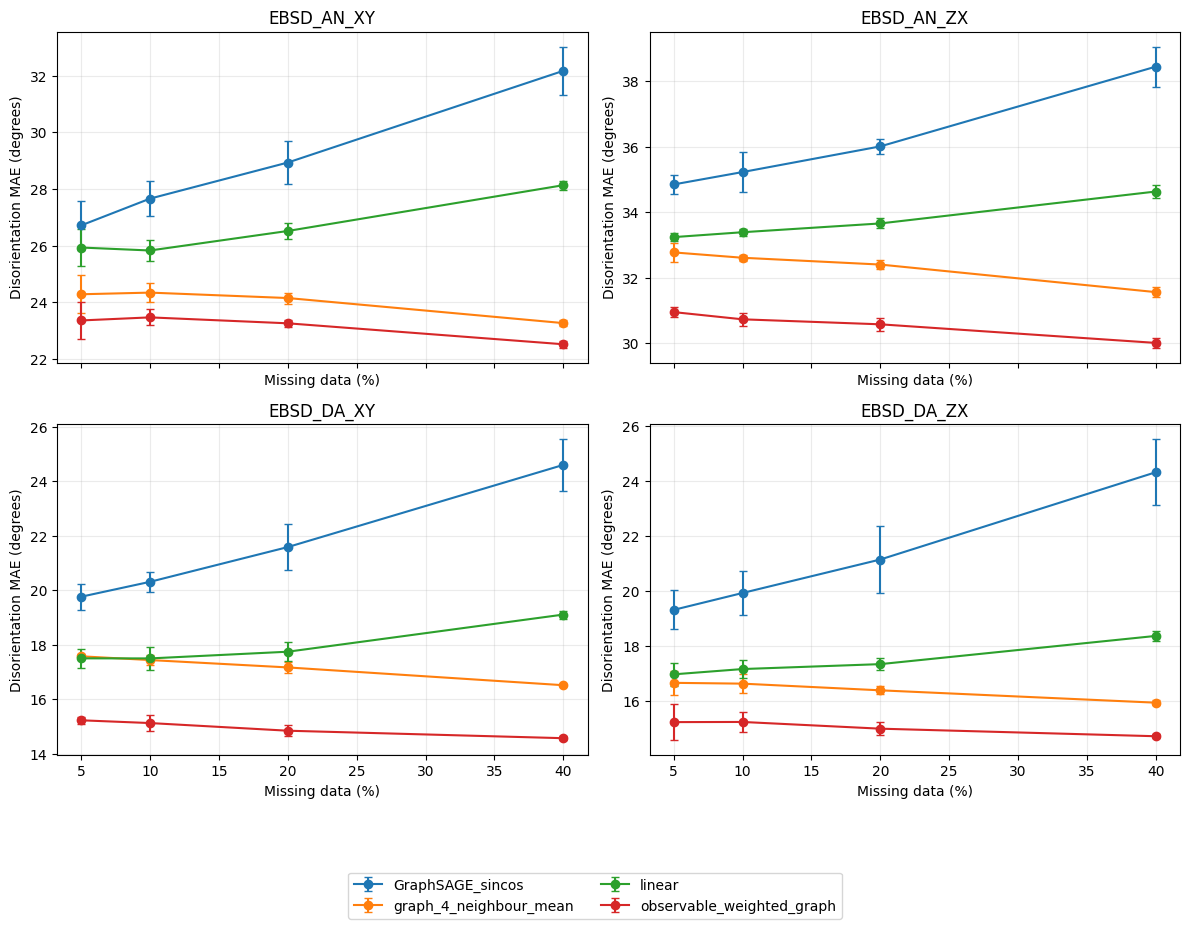


=== EXPERIMENT 1 STATISTICAL ANALYSIS ===
Evaluations: 320
Summary groups: 64
Paired comparisons: 48

GraphSAGE lower-MAE seed counts (out of 80 per baseline):
baseline
graph_4_neighbour_mean       0
linear                       0
observable_weighted_graph    0

Mean paired MAE difference (GraphSAGE minus baseline):
baseline
graph_4_neighbour_mean       4.455
linear                       2.998
observable_weighted_graph    6.011

Holm-adjusted paired t-test comparisons with p < 0.05:
48 of 48

FILES SAVED:
figure_1_disorientation_mae.pdf
figure_1_disorientation_mae.png
table_1_mean_sd_all_metrics.csv
table_2_disorientation_mae_mean_sd.csv
table_3_paired_method_comparisons.csv

STATISTICAL ANALYSIS: COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, wilcoxon
from statsmodels.stats.multitest import multipletests

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
folder = project / "results/experiment_01_symmetry_aware"
out = folder / "final_analysis"
out.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    folder / "combined_320_pending_final_validation.csv"
)

keys = ["dataset", "missing_percent", "seed", "method"]
metrics = [
    "disorientation_mae",
    "disorientation_rmse",
    "disorientation_median"
]

assert len(df) == 320
assert not df.duplicated(keys).any()
assert np.isfinite(df[metrics].to_numpy(dtype=float)).all()

# 1. Mean and standard deviation over five seeds
summary = (
    df.groupby(
        ["dataset", "missing_percent", "method"]
    )[metrics]
    .agg(["mean", "std", "count"])
)

assert (summary.xs("count", level=1, axis=1) == 5).all().all()

summary.columns = [
    f"{metric}_{stat}" for metric, stat in summary.columns
]
summary = summary.reset_index()

summary.to_csv(
    out / "table_1_mean_sd_all_metrics.csv",
    index=False
)

# 2. Publication-readable MAE table
summary["MAE_mean_SD"] = summary.apply(
    lambda r: (
        f"{r['disorientation_mae_mean']:.2f} ± "
        f"{r['disorientation_mae_std']:.2f}"
    ),
    axis=1
)

mae_table = summary.pivot(
    index=["dataset", "missing_percent"],
    columns="method",
    values="MAE_mean_SD"
)

mae_table.to_csv(
    out / "table_2_disorientation_mae_mean_sd.csv"
)

# 3. Paired comparisons across identical dataset/level/seed
baseline_methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph"
]

comparisons = []

for (dataset, pct), group in df.groupby(
    ["dataset", "missing_percent"]
):
    pivot = group.pivot(
        index="seed",
        columns="method",
        values="disorientation_mae"
    )

    graph = pivot["GraphSAGE_sincos"].sort_index()

    for method in baseline_methods:
        baseline = pivot[method].sort_index()
        difference = graph - baseline

        assert len(difference) == 5
        assert difference.notna().all()

        t_stat, p_t = ttest_rel(graph, baseline)

        # Exploratory nonparametric paired comparison
        if np.allclose(difference, 0):
            p_w = 1.0
        else:
            p_w = wilcoxon(
                difference,
                zero_method="wilcox",
                alternative="two-sided",
                method="exact"
            ).pvalue

        comparisons.append({
            "dataset": dataset,
            "missing_percent": pct,
            "baseline": method,
            "n_paired_seeds": 5,
            "graphsage_mae_mean": graph.mean(),
            "baseline_mae_mean": baseline.mean(),
            "difference_graphsage_minus_baseline": difference.mean(),
            "paired_difference_sd": difference.std(ddof=1),
            "graphsage_lower_error_seeds": int((difference < 0).sum()),
            "paired_t_p_uncorrected": p_t,
            "wilcoxon_p_uncorrected": p_w
        })

comparison_df = pd.DataFrame(comparisons)

# Holm correction over all 48 planned comparisons
for test in [
    "paired_t_p_uncorrected",
    "wilcoxon_p_uncorrected"
]:
    comparison_df[test.replace("_uncorrected", "_holm")] = (
        multipletests(
            comparison_df[test].to_numpy(),
            method="holm"
        )[1]
    )

comparison_df.to_csv(
    out / "table_3_paired_method_comparisons.csv",
    index=False
)

# 4. Plot mean MAE ± SD by missing-data level
fig, axes = plt.subplots(
    2, 2, figsize=(12, 9), sharex=True
)

for ax, dataset in zip(axes.flat, sorted(df.dataset.unique())):
    part = summary[summary.dataset == dataset]

    for method in sorted(df.method.unique()):
        sub = part[part.method == method].sort_values(
            "missing_percent"
        )
        ax.errorbar(
            sub.missing_percent,
            sub.disorientation_mae_mean,
            yerr=sub.disorientation_mae_std,
            marker="o",
            capsize=3,
            label=method
        )

    ax.set_title(dataset)
    ax.set_xlabel("Missing data (%)")
    ax.set_ylabel("Disorientation MAE (degrees)")
    ax.grid(alpha=0.25)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.035)
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
fig.savefig(
    out / "figure_1_disorientation_mae.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    out / "figure_1_disorientation_mae.pdf",
    bbox_inches="tight"
)
plt.show()

# 5. Print concise findings
print("\n=== EXPERIMENT 1 STATISTICAL ANALYSIS ===")
print("Evaluations:", len(df))
print("Summary groups:", len(summary))
print("Paired comparisons:", len(comparison_df))

wins = (
    comparison_df
    .groupby("baseline")["graphsage_lower_error_seeds"]
    .sum()
)

print("\nGraphSAGE lower-MAE seed counts (out of 80 per baseline):")
print(wins.to_string())

print("\nMean paired MAE difference (GraphSAGE minus baseline):")
print(
    comparison_df.groupby("baseline")[
        "difference_graphsage_minus_baseline"
    ].mean().round(3).to_string()
)

print("\nHolm-adjusted paired t-test comparisons with p < 0.05:")
print(
    (comparison_df.paired_t_p_holm < 0.05).sum(),
    "of", len(comparison_df)
)

print("\nFILES SAVED:")
for p in sorted(out.iterdir()):
    print(p.name)

print("\nSTATISTICAL ANALYSIS: COMPLETE")


In [ ]:
from pathlib import Path
from google.colab import files

folder = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)/results/"
    "experiment_01_symmetry_aware/final_analysis"
)

print("Folder exists:", folder.exists())

if folder.exists():
    print("Files:", [p.name for p in folder.iterdir()])
    files.download(str(folder / "table_1_mean_sd_all_metrics.csv"))

Folder exists: True
Files: ['table_1_mean_sd_all_metrics.csv', 'table_2_disorientation_mae_mean_sd.csv', 'table_3_paired_method_comparisons.csv', 'figure_1_disorientation_mae.png', 'figure_1_disorientation_mae.pdf']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PROJECT: /content/drive/MyDrive/EBSD Paper2 (1)
OUTPUT: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/reference_segmentation

Processing EBSD_AN_XY...
   5° | 5,807 grains | median size 2.0 px
  10° | 5,594 grains | median size 2.0 px
  15° | 5,423 grains | median size 2.0 px

Processing EBSD_AN_ZX...
   5° | 10,906 grains | median size 1.0 px
  10° | 10,544 grains | median size 1.0 px
  15° | 10,169 grains | median size 1.0 px

Processing EBSD_DA_XY...
   5° | 3,041 grains | median size 2.0 px
  10° | 2,846 grains | median size 2.0 px
  15° | 2,750 grains | median size 2.0 px

Processing EBSD_DA_ZX...
   5° | 2,804 grains | median size 3.0 px
  10° | 2,686 grains | median size 3.0 px
  15° | 2,619 grains | median size 3.0 px


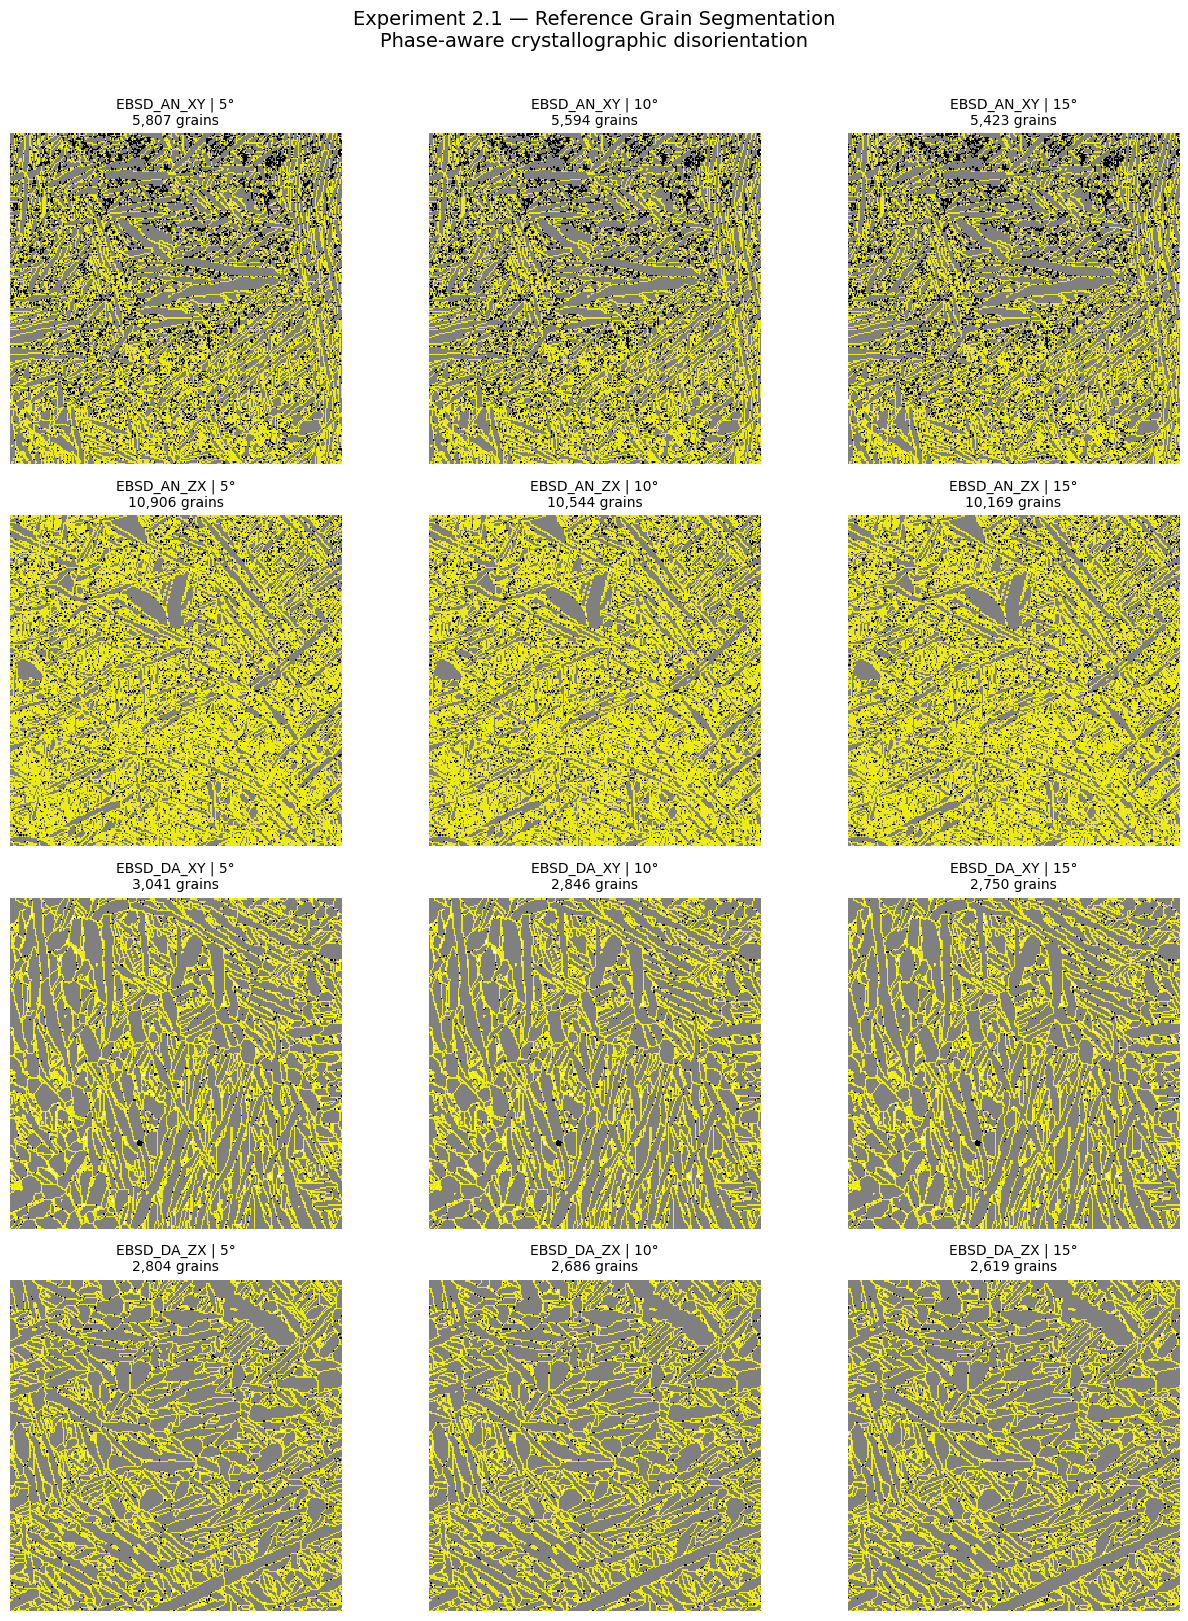


EXPERIMENT 2.1 RESULTS
   dataset  threshold_deg  indexed_pixels  grain_count  median_grain_pixels  mean_grain_pixels  grains_1_to_4_pixels  grains_5_to_20_pixels  grains_over_20_pixels
EBSD_AN_XY              5           58152         5807                  2.0          10.014121                  3780                   1401                    626
EBSD_AN_XY             10           58152         5594                  2.0          10.395424                  3649                   1348                    597
EBSD_AN_XY             15           58152         5423                  2.0          10.723216                  3531                   1309                    583
EBSD_AN_ZX              5           62011        10906                  1.0           5.685953                  8519                   1821                    566
EBSD_AN_ZX             10           62011        10544                  1.0           5.881165                  8244                   1751                    54

In [ ]:

# ============================================================
# EXPERIMENT 2.1 — REFERENCE GRAIN SEGMENTATION
# Four EBSD datasets | 256x256 crops | 5°, 10°, 15°
# Phase-aware crystallographic disorientation
# ============================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.transform import Rotation as R
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------
# 1. PROJECT SETUP
# ------------------------------------------------------------

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

assert project.exists(), f"Project folder not found: {project}"

sys.path.insert(0, str(project))

from experiment1_validate_graphsage import prepare_crop

out = (
    project
    / "results"
    / "experiment_02_small_grains"
    / "reference_segmentation"
)

out.mkdir(parents=True, exist_ok=True)

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

thresholds = [5, 10, 15]

# Proper rotational symmetry groups
symmetry = {
    1: R.create_group("D6"),  # Hexagonal titanium
    2: R.create_group("O")    # Cubic titanium
}

print("PROJECT:", project)
print("OUTPUT:", out)

# ------------------------------------------------------------
# 2. PHASE-AWARE GRAIN SEGMENTATION
# ------------------------------------------------------------

def segment_grains(maps, threshold):

    phase = np.asarray(maps["Phase"]).astype(int)

    h, w = phase.shape
    valid = np.isin(phase, [1, 2])

    eulers = np.stack(
        [
            maps["Euler1"],
            maps["Euler2"],
            maps["Euler3"]
        ],
        axis=-1
    )

    # Store flat pixel-index connections
    rows = []
    cols = []

    # Four-neighbour connectivity:
    # right and down; reverse edges added explicitly
    for dy, dx in [(0, 1), (1, 0)]:

        y1 = slice(0, h - dy)
        x1 = slice(0, w - dx)

        y2 = slice(dy, h)
        x2 = slice(dx, w)

        phase_a = phase[y1, x1]
        phase_b = phase[y2, x2]

        euler_a = eulers[y1, x1]
        euler_b = eulers[y2, x2]

        same_phase = (
            (phase_a == phase_b)
            & np.isin(phase_a, [1, 2])
        )

        for phase_id, group in symmetry.items():

            yy, xx = np.where(
                same_phase & (phase_a == phase_id)
            )

            if len(yy) == 0:
                continue

            orientation_a = R.from_euler(
                "ZXZ",
                euler_a[yy, xx],
                degrees=True
            )

            orientation_b = R.from_euler(
                "ZXZ",
                euler_b[yy, xx],
                degrees=True
            )

            relative = (
                orientation_a.inv() * orientation_b
            )

            minimum_angle = np.full(
                len(yy),
                np.inf,
                dtype=float
            )

            # Minimise over phase-specific crystal symmetry
            for s in group:

                angle = (
                    s.inv() * relative
                ).magnitude()

                minimum_angle = np.minimum(
                    minimum_angle,
                    angle
                )

            angle_degrees = np.rad2deg(minimum_angle)

            keep = angle_degrees <= threshold

            yy = yy[keep]
            xx = xx[keep]

            if len(yy) == 0:
                continue

            # Flat indices in the original 256x256 image
            i = (yy * w + xx).astype(np.int64)

            j = (
                (yy + dy) * w + (xx + dx)
            ).astype(np.int64)

            # IMPORTANT FIX:
            # Add individual integer indices, not NumPy arrays
            rows.extend(i.tolist())
            rows.extend(j.tolist())

            cols.extend(j.tolist())
            cols.extend(i.tolist())

    # --------------------------------------------------------
    # 3. SPARSE ADJACENCY MATRIX
    # --------------------------------------------------------

    n = h * w

    adjacency = coo_matrix(
        (
            np.ones(len(rows), dtype=np.uint8),
            (
                np.asarray(rows, dtype=np.int64),
                np.asarray(cols, dtype=np.int64)
            )
        ),
        shape=(n, n)
    ).tocsr()

    # --------------------------------------------------------
    # 4. CONNECTED COMPONENTS
    # --------------------------------------------------------

    _, labels = connected_components(
        adjacency,
        directed=False
    )

    labels = labels.reshape(h, w).astype(np.int32)

    # Exclude unindexed pixels
    labels[~valid] = -1

    # Renumber indexed grains consecutively
    unique_labels = np.unique(labels[valid])

    labels[valid] = np.searchsorted(
        unique_labels,
        labels[valid]
    )

    return labels

# ------------------------------------------------------------
# 5. PROCESS ALL FOUR DATASETS
# ------------------------------------------------------------

records = []

fig, axes = plt.subplots(
    len(datasets),
    len(thresholds),
    figsize=(13, 16)
)

for row, name in enumerate(datasets):

    print(f"\nProcessing {name}...", flush=True)

    ctf_path = (
        project / "datasets" / f"{name}.ctf"
    )

    assert ctf_path.exists(), (
        f"Dataset not found: {ctf_path}"
    )

    maps, original_valid, _ = prepare_crop(
        ctf_path,
        256
    )

    phase = np.asarray(maps["Phase"]).astype(int)
    valid = np.isin(phase, [1, 2])

    assert phase.shape == (256, 256)

    for col, threshold in enumerate(thresholds):

        labels = segment_grains(
            maps,
            threshold
        )

        # Ensure every indexed pixel has a grain label
        assert np.all(labels[valid] >= 0)
        assert np.all(labels[~valid] == -1)

        sizes = np.bincount(
            labels[valid]
        )

        grain_count = len(sizes)

        assert sizes.sum() == valid.sum()
        assert grain_count > 0

        # ----------------------------------------------------
        # 6. GRAIN SIZE STATISTICS
        # ----------------------------------------------------

        record = {
            "dataset": name,
            "threshold_deg": threshold,
            "indexed_pixels": int(valid.sum()),
            "grain_count": int(grain_count),
            "median_grain_pixels": float(
                np.median(sizes)
            ),
            "mean_grain_pixels": float(
                np.mean(sizes)
            ),
            "grains_1_to_4_pixels": int(
                ((sizes >= 1) & (sizes <= 4)).sum()
            ),
            "grains_5_to_20_pixels": int(
                ((sizes >= 5) & (sizes <= 20)).sum()
            ),
            "grains_over_20_pixels": int(
                (sizes > 20).sum()
            )
        }

        records.append(record)

        # Save labels for subsequent experiments
        np.savez_compressed(
            out / (
                f"{name}_threshold"
                f"{threshold}_labels.npz"
            ),
            labels=labels,
            grain_sizes=sizes
        )

        # ----------------------------------------------------
        # 7. BOUNDARY VISUALISATION
        # ----------------------------------------------------

        boundaries = np.zeros(
            labels.shape,
            dtype=bool
        )

        # Only boundaries between indexed grains
        boundaries[:, 1:] |= (
            valid[:, 1:]
            & valid[:, :-1]
            & (labels[:, 1:] != labels[:, :-1])
        )

        boundaries[1:, :] |= (
            valid[1:, :]
            & valid[:-1, :]
            & (labels[1:, :] != labels[:-1, :])
        )

        ax = axes[row, col]

        ax.imshow(
            phase,
            cmap="gray",
            vmin=0,
            vmax=2,
            interpolation="nearest"
        )

        overlay = np.ma.masked_where(
            ~boundaries,
            boundaries.astype(float)
        )

        ax.imshow(
            overlay,
            cmap="autumn",
            alpha=0.85,
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        ax.set_title(
            f"{name} | {threshold}°\n"
            f"{grain_count:,} grains",
            fontsize=10
        )

        ax.axis("off")

        print(
            f"  {threshold:2d}° | "
            f"{grain_count:,} grains | "
            f"median size {np.median(sizes):.1f} px",
            flush=True
        )

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

summary = pd.DataFrame(records)

summary_path = (
    out / "reference_grain_segmentation_sensitivity.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

fig.suptitle(
    "Experiment 2.1 — Reference Grain Segmentation\n"
    "Phase-aware crystallographic disorientation",
    fontsize=14,
    y=1.01
)

fig.tight_layout()

figure_path = (
    out / "reference_grain_segmentation_sensitivity.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

assert len(summary) == 12

assert summary.groupby(
    "dataset"
).size().eq(3).all()

assert summary[
    "indexed_pixels"
].gt(0).all()

print("\n" + "=" * 65)
print("EXPERIMENT 2.1 RESULTS")
print("=" * 65)

print(
    summary.to_string(index=False)
)

print("\nSEGMENTATION SENSITIVITY: COMPLETE")
print("12/12 dataset-threshold combinations processed")

print("\nFILES SAVED:")
print(summary_path)
print(figure_path)

print("\nEXPERIMENT 2.1: PASS")


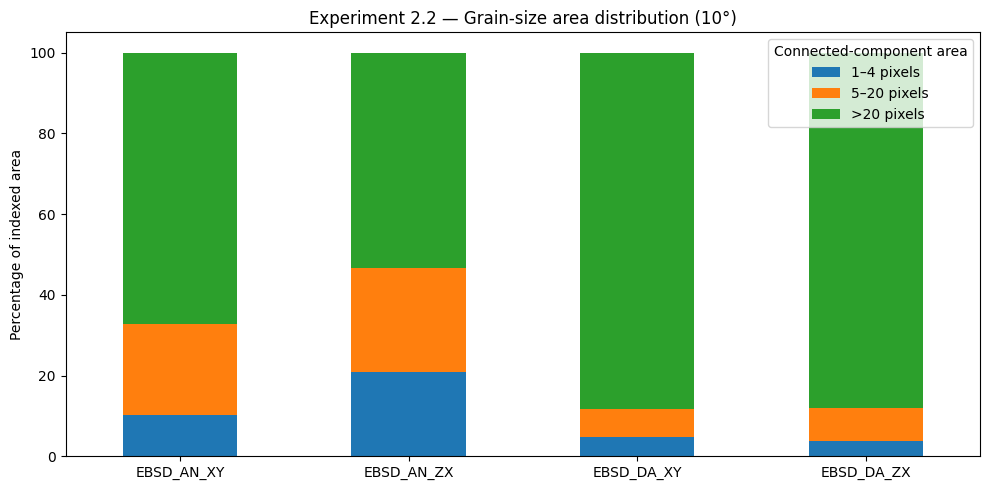


=== EXPERIMENT 2.2 RESULTS ===
   dataset    category  grain_count  grain_fraction_percent  indexed_area_percent
EBSD_AN_XY  1–4 pixels         3649                   65.23                 10.34
EBSD_AN_XY 5–20 pixels         1348                   24.10                 22.49
EBSD_AN_XY  >20 pixels          597                   10.67                 67.17
EBSD_AN_ZX  1–4 pixels         8244                   78.19                 20.76
EBSD_AN_ZX 5–20 pixels         1751                   16.61                 25.90
EBSD_AN_ZX  >20 pixels          549                    5.21                 53.35
EBSD_DA_XY  1–4 pixels         1902                   66.83                  4.80
EBSD_DA_XY 5–20 pixels          450                   15.81                  6.92
EBSD_DA_XY  >20 pixels          494                   17.36                 88.28
EBSD_DA_ZX  1–4 pixels         1576                   58.67                  3.86
EBSD_DA_ZX 5–20 pixels          502                   18.69       

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
base = project / "results/experiment_02_small_grains"
source = base / "reference_segmentation"
out = base / "grain_size_quality"
out.mkdir(parents=True, exist_ok=True)

datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]

records = []
grain_records = []

for name in datasets:
    path = source / f"{name}_threshold10_labels.npz"
    assert path.exists(), f"Missing segmentation: {path}"

    with np.load(path) as data:
        labels = data["labels"]
        sizes = data["grain_sizes"]

    valid = labels >= 0
    assert sizes.sum() == valid.sum()
    assert len(sizes) == len(np.unique(labels[valid]))

    categories = {
        "1–4 pixels": (sizes >= 1) & (sizes <= 4),
        "5–20 pixels": (sizes >= 5) & (sizes <= 20),
        ">20 pixels": sizes > 20
    }

    for category, mask in categories.items():
        count = int(mask.sum())
        area = int(sizes[mask].sum())

        records.append({
            "dataset": name,
            "category": category,
            "grain_count": count,
            "grain_fraction_percent": 100 * count / len(sizes),
            "indexed_area_pixels": area,
            "indexed_area_percent": 100 * area / valid.sum()
        })

    for grain_id, size in enumerate(sizes):
        grain_records.append({
            "dataset": name,
            "grain_id": grain_id,
            "area_pixels": int(size)
        })

summary = pd.DataFrame(records)
grain_table = pd.DataFrame(grain_records)

summary.to_csv(out / "grain_size_area_fractions.csv", index=False)
grain_table.to_csv(out / "individual_grain_areas.csv", index=False)

# Plot area fraction by category
fig, ax = plt.subplots(figsize=(10, 5))

pivot = summary.pivot(
    index="dataset",
    columns="category",
    values="indexed_area_percent"
)

pivot = pivot[["1–4 pixels", "5–20 pixels", ">20 pixels"]]
pivot.plot(kind="bar", stacked=True, ax=ax)

ax.set_ylabel("Percentage of indexed area")
ax.set_xlabel("")
ax.set_title("Experiment 2.2 — Grain-size area distribution (10°)")
ax.legend(title="Connected-component area")
ax.tick_params(axis="x", rotation=0)

fig.tight_layout()
fig.savefig(
    out / "grain_size_area_distribution.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()

print("\n=== EXPERIMENT 2.2 RESULTS ===")
print(
    summary[
        ["dataset", "category", "grain_count",
         "grain_fraction_percent", "indexed_area_percent"]
    ].round(2).to_string(index=False)
)

print("\nAREA-FRACTION CHECK:")
print(
    summary.groupby("dataset")[
        "indexed_area_percent"
    ].sum().round(6).to_string()
)

assert np.allclose(
    summary.groupby("dataset")["indexed_area_percent"].sum(),
    100.0
)

print("\nEXPERIMENT 2.2: PASS")
print("FILES SAVED:", out)


In [ ]:

from pathlib import Path
from collections import Counter
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
results = project / "results"

extensions = {".npy", ".npz", ".pt", ".pth", ".csv"}

# Search likely prediction directories, not model checkpoints
candidates = [
    p for p in results.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensions
    and (
        "prediction" in str(p).lower()
        or "reconstruction" in p.name.lower()
    )
    and "models" not in p.parts
]

print("=== EXPERIMENT 2.3 — PREDICTION INVENTORY ===")
print("Candidate files:", len(candidates))

print("\nFiles by extension:")
print(dict(Counter(p.suffix.lower() for p in candidates)))

print("\nFiles by parent folder:")
for folder, count in Counter(
    str(p.parent.relative_to(project)) for p in candidates
).most_common(15):
    print(f"{count:5d}  {folder}")

print("\nFirst 30 candidate files:")
for p in sorted(candidates)[:30]:
    print(p.relative_to(project))

inventory = pd.DataFrame([
    {
        "relative_path": str(p.relative_to(project)),
        "extension": p.suffix.lower(),
        "size_bytes": p.stat().st_size
    }
    for p in candidates
])

out = results / "experiment_02_small_grains"
out.mkdir(parents=True, exist_ok=True)

inventory.to_csv(
    out / "prediction_inventory.csv",
    index=False
)

print("\nINVENTORY COMPLETE")
print("Saved:", out / "prediction_inventory.csv")


=== EXPERIMENT 2.3 — PREDICTION INVENTORY ===
Candidate files: 0

Files by extension:
{}

Files by parent folder:

First 30 candidate files:

INVENTORY COMPLETE
Saved: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/prediction_inventory.csv


In [ ]:

from pathlib import Path
import pandas as pd

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
results = project / "results"

models = sorted(
    (results / "experiment_13_graphsage_new_datasets/models")
    .glob("*GraphSAGE_sincos_final.pt")
)

notebooks = sorted(project.rglob("*.ipynb"))
scripts = sorted(project.rglob("*.py"))

print("=== EXPERIMENT 2.3 — RECONSTRUCTION READINESS ===")
print("GraphSAGE checkpoints:", len(models))
print("Python scripts:", len(scripts))
print("Notebooks:", len(notebooks))

print("\nAvailable notebooks:")
for p in notebooks[:15]:
    print(p.relative_to(project))

print("\nScripts potentially containing baseline implementations:")
keywords = [
    "linear", "interpolat", "weighted",
    "neighbour", "neighbor", "baseline"
]

found = []
for p in scripts:
    try:
        content = p.read_text(errors="ignore").lower()
        if any(k in content for k in keywords):
            found.append(str(p.relative_to(project)))
    except OSError:
        pass

for name in found[:30]:
    print(name)

print("\nREADINESS CHECK COMPLETE")


=== EXPERIMENT 2.3 — RECONSTRUCTION READINESS ===
GraphSAGE checkpoints: 80
Python scripts: 7
Notebooks: 0

Available notebooks:

Scripts potentially containing baseline implementations:
experiment1_validate_graphsage.py

READINESS CHECK COMPLETE


In [ ]:

from pathlib import Path
import sys
import numpy as np
import torch

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
sys.path.insert(0, str(project))

from experiment1_validate_graphsage import (
    prepare_crop, create_missing_mask,
    euler_to_sincos, sincos_to_euler, GridGraphSAGE
)

name, pct, seed = "EBSD_AN_ZX", 20, 1

maps, valid, _ = prepare_crop(
    project / "datasets" / f"{name}.ctf", 256
)

missing = create_missing_mask(valid, pct / 100, seed)

rng = np.random.default_rng(seed + 1000)
candidates = np.argwhere(valid & ~missing)
chosen = candidates[
    rng.choice(
        len(candidates),
        size=max(1, int(len(candidates) * 0.10)),
        replace=False
    )
]

train = np.zeros_like(valid, dtype=bool)
train[chosen[:, 0], chosen[:, 1]] = True

hidden = missing | train
visible = valid & ~hidden

angles = np.stack([
    maps[k] for k in ("Euler1", "Euler2", "Euler3")
])

target = euler_to_sincos(*angles)
norm = lambda x: x / max(np.nanmax(x), 1)

features = np.concatenate([
    np.where(hidden[None], 0, target),
    norm(maps["Phase"])[None],
    norm(maps["BC"])[None],
    norm(maps["MAD"])[None],
    visible[None].astype(float),
    valid[None].astype(float)
])

checkpoint = (
    project / "results/experiment_13_graphsage_new_datasets/models"
    / f"{name}_crop256_missing{pct}_seed{seed}"
      "_GraphSAGE_sincos_final.pt"
)

assert checkpoint.exists(), f"Checkpoint missing: {checkpoint}"

model = GridGraphSAGE(11, 128, 6).eval()
model.load_state_dict(
    torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=True
    )
)

with torch.inference_mode():
    prediction = model(
        torch.tensor(features, dtype=torch.float32)[None],
        torch.tensor(
            valid.astype(float),
            dtype=torch.float32
        )[None, None]
    )[0].numpy()

predicted_euler = sincos_to_euler(prediction)

out = (
    project / "results/experiment_02_small_grains"
    / "predictions/GraphSAGE_sincos"
)
out.mkdir(parents=True, exist_ok=True)

destination = out / f"{name}_missing{pct}_seed{seed}.npz"

np.savez_compressed(
    destination,
    predicted_euler=predicted_euler,
    true_euler=angles,
    phase=np.asarray(maps["Phase"]).astype(np.int16),
    valid_mask=valid,
    missing_mask=missing,
    train_mask=train
)

# Verify the saved file
with np.load(destination) as saved:
    assert saved["missing_mask"].sum() == missing.sum()
    assert np.isfinite(saved["predicted_euler"]).all()
    print("Prediction shape:", saved["predicted_euler"].shape)
    print("Evaluation pixels:", int(saved["missing_mask"].sum()))

print("GRAPHSAGE PREDICTION RECONSTRUCTION: PASS")
print("SAVED:", destination)


Prediction shape: (3, 256, 256)
Evaluation pixels: 12402
GRAPHSAGE PREDICTION RECONSTRUCTION: PASS
SAVED: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/predictions/GraphSAGE_sincos/EBSD_AN_ZX_missing20_seed1.npz


In [ ]:

from pathlib import Path
import numpy as np
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")

path = (
    project / "results/experiment_02_small_grains"
    / "predictions/GraphSAGE_sincos"
    / "EBSD_AN_ZX_missing20_seed1.npz"
)

with np.load(path) as data:
    predicted = data["predicted_euler"]
    actual = data["true_euler"]
    phase = data["phase"]
    missing = data["missing_mask"]

errors = []

for phase_id, group_name in [(1, "D6"), (2, "O")]:
    mask = missing & (phase == phase_id)
    if not mask.any():
        continue

    true_rot = R.from_euler(
        "ZXZ", actual[:, mask].T, degrees=True
    )
    pred_rot = R.from_euler(
        "ZXZ", predicted[:, mask].T, degrees=True
    )

    relative = true_rot.inv() * pred_rot
    symmetry = R.create_group(group_name)

    minimum = np.full(len(relative), np.inf)
    for s in symmetry:
        minimum = np.minimum(
            minimum,
            (s.inv() * relative).magnitude()
        )

    errors.append(np.rad2deg(minimum))

errors = np.concatenate(errors)

mae = float(errors.mean())
rmse = float(np.sqrt(np.mean(errors ** 2)))
median = float(np.median(errors))

print("=== SAVED PREDICTION VALIDATION ===")
print(f"MAE:    {mae:.6f}°")
print(f"RMSE:   {rmse:.6f}°")
print(f"Median: {median:.6f}°")

assert abs(mae - 35.644486) < 0.001
assert abs(rmse - 42.288563) < 0.001
assert abs(median - 32.167478) < 0.001

print("SAVED PREDICTION VALIDATION: PASS")


=== SAVED PREDICTION VALIDATION ===
MAE:    35.644486°
RMSE:   42.288563°
Median: 32.167478°
SAVED PREDICTION VALIDATION: PASS


In [ ]:

from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import torch
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
sys.path.insert(0, str(project))

from experiment1_validate_graphsage import (
    prepare_crop, create_missing_mask, euler_to_sincos,
    sincos_to_euler, GridGraphSAGE
)

base = project / "results/experiment_02_small_grains"
out = base / "predictions/GraphSAGE_sincos"
out.mkdir(parents=True, exist_ok=True)

reference = pd.read_csv(
    project / "results/experiment_01_symmetry_aware"
    / "combined_320_pending_final_validation.csv"
)
reference = reference[
    reference.method == "GraphSAGE_sincos"
].copy()

assert len(reference) == 80
assert not reference.duplicated(
    ["dataset", "missing_percent", "seed"]
).any()

groups = {1: R.create_group("D6"), 2: R.create_group("O")}

def evaluate_prediction(actual, predicted, phase, missing):
    errors = []
    for phase_id, group in groups.items():
        mask = missing & (phase == phase_id)
        if not mask.any():
            continue

        for indices in np.array_split(
            np.flatnonzero(mask.ravel()),
            max(1, int(np.ceil(mask.sum() / 2048)))
        ):
            a = actual.reshape(3, -1)[:, indices].T
            b = predicted.reshape(3, -1)[:, indices].T
            relative = (
                R.from_euler("ZXZ", a, degrees=True).inv()
                * R.from_euler("ZXZ", b, degrees=True)
            )
            minimum = np.full(len(indices), np.inf)
            for s in group:
                minimum = np.minimum(
                    minimum, (s.inv() * relative).magnitude()
                )
            errors.append(np.rad2deg(minimum))

    values = np.concatenate(errors)
    return {
        "disorientation_mae": float(values.mean()),
        "disorientation_rmse": float(
            np.sqrt(np.mean(values ** 2))
        ),
        "disorientation_median": float(np.median(values))
    }

cache = {}
audit = []
start = time.time()

for row in reference.itertuples(index=False):
    name = row.dataset
    pct = int(row.missing_percent)
    seed = int(row.seed)

    destination = out / f"{name}_missing{pct}_seed{seed}.npz"

    if name not in cache:
        cache[name] = prepare_crop(
            project / "datasets" / f"{name}.ctf", 256
        )

    maps, valid, _ = cache[name]
    phase = np.asarray(maps["Phase"]).astype(np.int16)
    missing = create_missing_mask(valid, pct / 100, seed)

    angles = np.stack([
        maps[k] for k in ("Euler1", "Euler2", "Euler3")
    ])

    if destination.exists():
        with np.load(destination) as saved:
            assert np.array_equal(saved["missing_mask"], missing)
            assert np.array_equal(saved["phase"], phase)
            assert np.allclose(saved["true_euler"], angles)
            predicted = saved["predicted_euler"].copy()
        action = "VERIFIED EXISTING"
    else:
        rng = np.random.default_rng(seed + 1000)
        candidates = np.argwhere(valid & ~missing)
        chosen = candidates[
            rng.choice(
                len(candidates),
                size=max(1, int(len(candidates) * 0.10)),
                replace=False
            )
        ]

        train = np.zeros_like(valid, dtype=bool)
        train[chosen[:, 0], chosen[:, 1]] = True

        hidden = missing | train
        visible = valid & ~hidden

        target = euler_to_sincos(*angles)
        norm = lambda x: x / max(np.nanmax(x), 1)

        features = np.concatenate([
            np.where(hidden[None], 0, target),
            norm(maps["Phase"])[None],
            norm(maps["BC"])[None],
            norm(maps["MAD"])[None],
            visible[None].astype(float),
            valid[None].astype(float)
        ])

        checkpoint = (
            project
            / "results/experiment_13_graphsage_new_datasets/models"
            / f"{name}_crop256_missing{pct}_seed{seed}"
              "_GraphSAGE_sincos_final.pt"
        )
        assert checkpoint.exists(), f"Missing: {checkpoint}"

        model = GridGraphSAGE(11, 128, 6).eval()
        model.load_state_dict(
            torch.load(
                checkpoint, map_location="cpu",
                weights_only=True
            ),
            strict=True
        )

        with torch.inference_mode():
            output = model(
                torch.tensor(features, dtype=torch.float32)[None],
                torch.tensor(
                    valid.astype(float), dtype=torch.float32
                )[None, None]
            )[0].numpy()

        predicted = sincos_to_euler(output)
        action = "GENERATED"

    assert predicted.shape == (3, 256, 256)
    assert np.isfinite(predicted).all()

    metrics = evaluate_prediction(
        angles, predicted, phase, missing
    )

    differences = {
        key: abs(metrics[key] - float(getattr(row, key)))
        for key in metrics
    }
    maximum_difference = max(differences.values())

    # Do not save a new prediction if it fails validation
    assert maximum_difference < 0.001, (
        f"Experiment 1 mismatch: {name}, {pct}%, "
        f"seed {seed}, differences={differences}"
    )

    if action == "GENERATED":
        np.savez_compressed(
            destination,
            predicted_euler=predicted,
            true_euler=angles,
            phase=phase,
            valid_mask=valid,
            missing_mask=missing,
            train_mask=train
        )

    audit.append({
        "dataset": name,
        "missing_percent": pct,
        "seed": seed,
        "action": action,
        "maximum_metric_difference_deg": maximum_difference,
        **metrics
    })

    # Save progress after every configuration
    pd.DataFrame(audit).to_csv(
        base / "graphsage_prediction_validation.csv",
        index=False
    )

    print(
        f"{len(audit):02d}/80 {action}: "
        f"{name} {pct}% seed {seed} | "
        f"MAE={metrics['disorientation_mae']:.4f}° | "
        f"max difference={maximum_difference:.7f}°",
        flush=True
    )

assert len(audit) == 80
assert len(list(out.glob("*.npz"))) >= 80

print("\n=== EXPERIMENT 2.3 PREDICTION RESULTS ===")
print("Prediction maps:", len(audit), "/ 80")
print(
    "Maximum difference from Experiment 1:",
    max(x["maximum_metric_difference_deg"] for x in audit)
)
print("Elapsed minutes:", round((time.time()-start)/60, 2))
print("GRAPHSAGE PREDICTION BATCH: PASS")
print("Saved to:", out)


01/80 VERIFIED EXISTING: EBSD_AN_ZX 20% seed 1 | MAE=35.6445° | max difference=0.0000046°
02/80 GENERATED: EBSD_AN_ZX 20% seed 2 | MAE=35.9118° | max difference=0.0000023°
03/80 GENERATED: EBSD_AN_ZX 20% seed 3 | MAE=36.0547° | max difference=0.0000062°
04/80 GENERATED: EBSD_AN_ZX 20% seed 4 | MAE=36.1380° | max difference=0.0000032°
05/80 GENERATED: EBSD_AN_ZX 20% seed 5 | MAE=36.2691° | max difference=0.0000029°
06/80 GENERATED: EBSD_AN_ZX 40% seed 1 | MAE=38.1969° | max difference=0.0000014°
07/80 GENERATED: EBSD_AN_ZX 40% seed 2 | MAE=37.8688° | max difference=0.0000019°
08/80 GENERATED: EBSD_AN_ZX 40% seed 3 | MAE=38.2338° | max difference=0.0000054°
09/80 GENERATED: EBSD_AN_ZX 40% seed 4 | MAE=39.4744° | max difference=0.0000107°
10/80 GENERATED: EBSD_AN_ZX 40% seed 5 | MAE=38.4205° | max difference=0.0000012°
11/80 GENERATED: EBSD_DA_XY 5% seed 1 | MAE=19.1476° | max difference=0.0000056°
12/80 GENERATED: EBSD_DA_XY 5% seed 2 | MAE=19.8521° | max difference=0.0000049°
13/80 GENE

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
base = project / "results/experiment_02_small_grains"

pred_dir = base / "predictions/GraphSAGE_sincos"
seg_dir = base / "reference_segmentation"
out_dir = base / "small_grain_accuracy"
out_dir.mkdir(parents=True, exist_ok=True)

groups = {
    1: R.create_group("D6"),
    2: R.create_group("O")
}

bins = [
    ("1-4", 1, 4),
    ("5-20", 5, 20),
    (">20", 21, np.inf)
]

def disorientation_errors(actual, predicted, phase, selected):
    errors = []

    for phase_id, symmetry in groups.items():
        indices = np.flatnonzero(
            (selected & (phase == phase_id)).ravel()
        )

        for chunk in np.array_split(
            indices,
            max(1, int(np.ceil(len(indices) / 2048)))
        ):
            if len(chunk) == 0:
                continue

            a = actual.reshape(3, -1)[:, chunk].T
            b = predicted.reshape(3, -1)[:, chunk].T

            relative = (
                R.from_euler("ZXZ", a, degrees=True).inv()
                * R.from_euler("ZXZ", b, degrees=True)
            )

            minimum = np.full(len(chunk), np.inf)
            for s in symmetry:
                minimum = np.minimum(
                    minimum,
                    (s.inv() * relative).magnitude()
                )

            errors.append(np.rad2deg(minimum))

    return np.concatenate(errors) if errors else np.array([])

rows = []
files = sorted(pred_dir.glob("*.npz"))
assert len(files) == 80, f"Expected 80 maps, found {len(files)}"

for i, path in enumerate(files, 1):
    stem = path.stem
    name, remainder = stem.split("_missing")
    pct_text, seed_text = remainder.split("_seed")
    pct, seed = int(pct_text), int(seed_text)

    seg_path = seg_dir / f"{name}_threshold10_labels.npz"
    assert seg_path.exists(), f"Missing segmentation: {seg_path}"

    with np.load(path) as data:
        predicted = data["predicted_euler"]
        actual = data["true_euler"]
        phase = data["phase"]
        missing = data["missing_mask"]
        valid = data["valid_mask"]

    with np.load(seg_path) as data:
        labels = data["labels"]
        grain_sizes = data["grain_sizes"]

    assert labels.shape == missing.shape == (256, 256)
    assert np.array_equal(labels >= 0, valid & (phase > 0))
    assert len(grain_sizes) == int(labels.max()) + 1

    pixel_size = np.zeros(labels.shape, dtype=np.int32)
    indexed = labels >= 0
    pixel_size[indexed] = grain_sizes[labels[indexed]]

    evaluation = missing & valid & indexed
    total_count = int(evaluation.sum())
    counted = 0

    for bin_name, lower, upper in bins:
        selected = (
            evaluation
            & (pixel_size >= lower)
            & (pixel_size <= upper)
        )

        errors = disorientation_errors(
            actual, predicted, phase, selected
        )

        n = len(errors)
        counted += n

        rows.append({
            "dataset": name,
            "missing_percent": pct,
            "seed": seed,
            "method": "GraphSAGE_sincos",
            "reference_threshold_deg": 10,
            "grain_size_bin": bin_name,
            "n_missing_pixels": n,
            "missing_pixel_fraction": (
                n / total_count if total_count else np.nan
            ),
            "disorientation_mae": (
                float(errors.mean()) if n else np.nan
            ),
            "disorientation_rmse": (
                float(np.sqrt(np.mean(errors**2))) if n else np.nan
            ),
            "disorientation_median": (
                float(np.median(errors)) if n else np.nan
            )
        })

    assert counted == total_count, (
        f"Bin coverage failed: {name}, {pct}%, seed {seed}"
    )

    if i % 10 == 0:
        print(f"Processed {i}/80 prediction maps", flush=True)

df = pd.DataFrame(rows)
assert len(df) == 240
assert df["n_missing_pixels"].sum() > 0

detail_path = out_dir / "graphsage_size_stratified_240.csv"
df.to_csv(detail_path, index=False)

# First average over seeds within each dataset and missingness level.
# Then give the 16 dataset × missingness configurations equal weight.
config_means = (
    df.groupby(
        ["dataset", "missing_percent", "grain_size_bin"],
        as_index=False
    )
    .agg(
        mean_mae=("disorientation_mae", "mean"),
        mean_rmse=("disorientation_rmse", "mean"),
        mean_pixel_count=("n_missing_pixels", "mean")
    )
)

summary = (
    config_means.groupby("grain_size_bin", as_index=False)
    .agg(
        mean_mae=("mean_mae", "mean"),
        sd_across_configurations=("mean_mae", "std"),
        mean_rmse=("mean_rmse", "mean"),
        mean_missing_pixels=("mean_pixel_count", "mean")
    )
)

summary["grain_size_bin"] = pd.Categorical(
    summary["grain_size_bin"],
    categories=["1-4", "5-20", ">20"],
    ordered=True
)
summary = summary.sort_values("grain_size_bin")

summary.to_csv(
    out_dir / "graphsage_grain_size_summary.csv",
    index=False
)
config_means.to_csv(
    out_dir / "graphsage_configuration_means.csv",
    index=False
)

print("\n=== EXPERIMENT 2.3A RESULTS ===")
print(summary.round(3).to_string(index=False))
print("\nConfigurations:", len(files))
print("Size-stratified rows:", len(df))
print("Grain-size coverage: PASS")
print("Saved results to:", out_dir)
print("EXPERIMENT 2.3A: COMPLETE")


Processed 10/80 prediction maps
Processed 20/80 prediction maps
Processed 30/80 prediction maps
Processed 40/80 prediction maps
Processed 50/80 prediction maps
Processed 60/80 prediction maps
Processed 70/80 prediction maps
Processed 80/80 prediction maps

=== EXPERIMENT 2.3A RESULTS ===
grain_size_bin  mean_mae  sd_across_configurations  mean_rmse  mean_missing_pixels
           1-4    53.035                     3.496     56.591             1151.150
          5-20    37.507                     2.470     42.911             1828.400
           >20    21.434                     3.840     28.018             8699.762

Configurations: 80
Size-stratified rows: 240
Grain-size coverage: PASS
Saved results to: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/small_grain_accuracy
EXPERIMENT 2.3A: COMPLETE


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)"
    "/results/experiment_02_small_grains/small_grain_accuracy"
)

df = pd.read_csv(base / "graphsage_size_stratified_240.csv")

# One row per dataset, missingness, seed and size bin
wide = df.pivot(
    index=["dataset", "missing_percent", "seed"],
    columns="grain_size_bin",
    values="disorientation_mae"
)

assert wide.shape == (80, 3)
assert wide.notna().all().all()

wide["small_minus_large"] = wide["1-4"] - wide[">20"]
wide["medium_minus_large"] = wide["5-20"] - wide[">20"]

# Average paired differences over seeds within each configuration
config = (
    wide.groupby(level=["dataset", "missing_percent"])
    .mean()
    .reset_index()
)

config["ordered_pattern"] = (
    (config["1-4"] > config["5-20"])
    & (config["5-20"] > config[">20"])
)

print("=== GRAIN-SIZE CONSISTENCY CHECK ===")
print(
    config[
        ["dataset", "missing_percent", "1-4", "5-20",
         ">20", "small_minus_large", "ordered_pattern"]
    ].round(2).to_string(index=False)
)

print("\nConfigurations with strictly decreasing error:",
      int(config["ordered_pattern"].sum()), "/ 16")

print("Mean paired small-minus-large difference:",
      round(config["small_minus_large"].mean(), 3), "degrees")

print("Range of paired differences:",
      round(config["small_minus_large"].min(), 3),
      "to",
      round(config["small_minus_large"].max(), 3),
      "degrees")

print("\nPer-dataset summary:")
print(
    config.groupby("dataset")[
        ["1-4", "5-20", ">20", "small_minus_large"]
    ].mean().round(2).to_string()
)

config.to_csv(
    base / "graphsage_size_effect_consistency.csv",
    index=False
)

print("\nCONSISTENCY ANALYSIS: COMPLETE")


=== GRAIN-SIZE CONSISTENCY CHECK ===
   dataset  missing_percent   1-4  5-20   >20  small_minus_large  ordered_pattern
EBSD_AN_XY                5 55.16 33.50 20.24              34.92             True
EBSD_AN_XY               10 54.81 34.24 21.30              33.51             True
EBSD_AN_XY               20 55.60 35.94 22.47              33.13             True
EBSD_AN_XY               40 56.34 38.77 26.23              30.10             True
EBSD_AN_ZX                5 57.00 38.55 24.08              32.92             True
EBSD_AN_ZX               10 57.00 38.71 24.86              32.14             True
EBSD_AN_ZX               20 57.21 39.72 25.87              31.35             True
EBSD_AN_ZX               40 57.40 42.18 29.15              28.25             True
EBSD_DA_XY                5 48.63 37.19 16.78              31.85             True
EBSD_DA_XY               10 49.57 37.69 17.30              32.27             True
EBSD_DA_XY               20 49.31 38.71 18.72              30

In [ ]:

from pathlib import Path
import numpy as np
from scipy.spatial.transform import Rotation as R
from sklearn.metrics import precision_recall_fscore_support

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)"
    "/results/experiment_02_small_grains"
)

path = (
    base / "predictions/GraphSAGE_sincos"
    / "EBSD_AN_ZX_missing20_seed1.npz"
)

with np.load(path) as d:
    actual = d["true_euler"]
    predicted = d["predicted_euler"]
    phase = d["phase"]
    valid = d["valid_mask"]
    missing = d["missing_mask"]

# Combine observed ground truth with predicted missing orientations
completed = actual.copy()
completed[:, missing] = predicted[:, missing]

def pairwise_disorientation(angles, y1, x1, y2, x2, group):
    a = R.from_euler(
        "ZXZ", angles[:, y1, x1].T, degrees=True
    )
    b = R.from_euler(
        "ZXZ", angles[:, y2, x2].T, degrees=True
    )
    relative = a.inv() * b
    minimum = np.full(len(relative), np.inf)

    for s in group:
        minimum = np.minimum(
            minimum, (s.inv() * relative).magnitude()
        )

    return np.rad2deg(minimum)

edge_results = []

for dy, dx in [(0, 1), (1, 0)]:
    h, w = valid.shape
    y, x = np.indices((h - dy, w - dx))
    y2, x2 = y + dy, x + dx

    eligible = (
        valid[y, x]
        & valid[y2, x2]
        & (phase[y, x] == phase[y2, x2])
        & (phase[y, x] > 0)
        & (missing[y, x] | missing[y2, x2])
    )

    for phase_id, group_name in [(1, "D6"), (2, "O")]:
        selected = eligible & (phase[y, x] == phase_id)
        yy, xx = y[selected], x[selected]
        yy2, xx2 = y2[selected], x2[selected]

        if len(yy) == 0:
            continue

        group = R.create_group(group_name)

        for start in range(0, len(yy), 2048):
            sl = slice(start, start + 2048)

            true_angle = pairwise_disorientation(
                actual, yy[sl], xx[sl],
                yy2[sl], xx2[sl], group
            )
            predicted_angle = pairwise_disorientation(
                completed, yy[sl], xx[sl],
                yy2[sl], xx2[sl], group
            )

            edge_results.append((
                true_angle >= 10,
                predicted_angle >= 10
            ))

assert edge_results, "No eligible boundary edges"

reference = np.concatenate([a for a, b in edge_results])
reconstructed = np.concatenate([b for a, b in edge_results])

precision, recall, f1, _ = precision_recall_fscore_support(
    reference,
    reconstructed,
    average="binary",
    zero_division=0
)

tp = int(np.sum(reference & reconstructed))
fp = int(np.sum(~reference & reconstructed))
fn = int(np.sum(reference & ~reconstructed))
tn = int(np.sum(~reference & ~reconstructed))

print("=== EXPERIMENT 2.3B — PILOT ===")
print("Eligible neighbour edges:", len(reference))
print("Reference boundary edges:", int(reference.sum()))
print("Reconstructed boundary edges:", int(reconstructed.sum()))
print("True positives:", tp)
print("False positives:", fp)
print("False negatives:", fn)
print("True negatives:", tn)
print(f"Boundary precision: {precision:.4f}")
print(f"Boundary recall:    {recall:.4f}")
print(f"Boundary F1:        {f1:.4f}")
print("PILOT BOUNDARY ANALYSIS: COMPLETE")


=== EXPERIMENT 2.3B — PILOT ===
Eligible neighbour edges: 41562
Reference boundary edges: 16504
Reconstructed boundary edges: 34553
True positives: 15975
False positives: 18578
False negatives: 529
True negatives: 6480
Boundary precision: 0.4623
Boundary recall:    0.9679
Boundary F1:        0.6258
PILOT BOUNDARY ANALYSIS: COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R
from time import perf_counter

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)"
    "/results/experiment_02_small_grains"
)
pred_dir = base / "predictions/GraphSAGE_sincos"
out_dir = base / "boundary_preservation"
out_dir.mkdir(parents=True, exist_ok=True)
output = out_dir / "graphsage_boundary_metrics_80.csv"

symmetries = {
    1: R.create_group("D6"),
    2: R.create_group("O")
}

def edge_disorientation(angles, first, second, symmetry):
    flat = angles.reshape(3, -1)
    result = np.empty(len(first), dtype=float)

    for start in range(0, len(first), 2048):
        stop = min(start + 2048, len(first))
        a = R.from_euler(
            "ZXZ", flat[:, first[start:stop]].T, degrees=True
        )
        b = R.from_euler(
            "ZXZ", flat[:, second[start:stop]].T, degrees=True
        )
        relative = a.inv() * b
        minimum = np.full(stop - start, np.inf)

        for s in symmetry:
            minimum = np.minimum(
                minimum, (s.inv() * relative).magnitude()
            )

        result[start:stop] = np.rad2deg(minimum)

    return result

files = sorted(pred_dir.glob("*.npz"))
assert len(files) == 80, f"Expected 80 files, found {len(files)}"

records = []
start_time = perf_counter()

for number, path in enumerate(files, 1):
    name, suffix = path.stem.split("_missing")
    pct_text, seed_text = suffix.split("_seed")
    pct, seed = int(pct_text), int(seed_text)

    with np.load(path) as d:
        actual = d["true_euler"]
        predicted = d["predicted_euler"]
        phase = d["phase"]
        valid = d["valid_mask"].astype(bool)
        missing = d["missing_mask"].astype(bool)

    completed = actual.copy()
    completed[:, missing] = predicted[:, missing]

    tp = fp = fn = tn = 0

    for dy, dx in [(0, 1), (1, 0)]:
        h, w = valid.shape
        yy, xx = np.indices((h-dy, w-dx))
        yy2, xx2 = yy + dy, xx + dx

        eligible = (
            valid[yy, xx] & valid[yy2, xx2]
            & (phase[yy, xx] == phase[yy2, xx2])
            & (phase[yy, xx] > 0)
            & (missing[yy, xx] | missing[yy2, xx2])
        )

        for phase_id, symmetry in symmetries.items():
            selected = eligible & (phase[yy, xx] == phase_id)

            first = np.ravel_multi_index(
                (yy[selected], xx[selected]), (h, w)
            )
            second = np.ravel_multi_index(
                (yy2[selected], xx2[selected]), (h, w)
            )

            if not len(first):
                continue

            reference_edges = (
                edge_disorientation(
                    actual, first, second, symmetry
                ) >= 10
            )
            reconstructed_edges = (
                edge_disorientation(
                    completed, first, second, symmetry
                ) >= 10
            )

            tp += int(np.sum(reference_edges & reconstructed_edges))
            fp += int(np.sum(~reference_edges & reconstructed_edges))
            fn += int(np.sum(reference_edges & ~reconstructed_edges))
            tn += int(np.sum(~reference_edges & ~reconstructed_edges))

    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn else np.nan
    )

    records.append({
        "dataset": name,
        "missing_percent": pct,
        "seed": seed,
        "threshold_deg": 10,
        "eligible_edges": tp + fp + fn + tn,
        "reference_boundary_edges": tp + fn,
        "reconstructed_boundary_edges": tp + fp,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "boundary_count_ratio": (
            (tp + fp) / (tp + fn) if tp + fn else np.nan
        )
    })

    pd.DataFrame(records).to_csv(output, index=False)

    if number % 10 == 0 or number == 1:
        print(f"Processed {number}/80 configurations", flush=True)

df = pd.DataFrame(records)

# Verify the previously reported pilot
pilot = df[
    (df.dataset == "EBSD_AN_ZX")
    & (df.missing_percent == 20)
    & (df.seed == 1)
].iloc[0]

assert (pilot[["TP", "FP", "FN", "TN"]].to_numpy()
        == [15975, 18578, 529, 6480]).all(), (
    "Pilot metrics do not match; investigate before interpreting."
)

# Average seeds within configurations, then configurations equally
config = df.groupby(
    ["dataset", "missing_percent"], as_index=False
)[["precision", "recall", "f1", "boundary_count_ratio"]].mean()

summary = config[
    ["precision", "recall", "f1", "boundary_count_ratio"]
].agg(["mean", "std", "min", "max"])

config.to_csv(
    out_dir / "graphsage_boundary_configuration_means.csv",
    index=False
)
summary.to_csv(
    out_dir / "graphsage_boundary_summary.csv"
)

print("\n=== EXPERIMENT 2.3B — ALL 80 CONFIGURATIONS ===")
print(summary.round(4).to_string())

print("\nPer-dataset means:")
print(
    config.groupby("dataset")[
        ["precision", "recall", "f1", "boundary_count_ratio"]
    ].mean().round(4).to_string()
)

print("\nConfigurations with excess reconstructed boundaries:",
      int((config.boundary_count_ratio > 1).sum()), "/16")

print("Elapsed minutes:",
      round((perf_counter()-start_time)/60, 2))
print("PILOT REPRODUCTION: PASS")
print("BOUNDARY ANALYSIS: COMPLETE")


Processed 1/80 configurations
Processed 10/80 configurations
Processed 20/80 configurations
Processed 30/80 configurations
Processed 40/80 configurations
Processed 50/80 configurations
Processed 60/80 configurations
Processed 70/80 configurations
Processed 80/80 configurations

=== EXPERIMENT 2.3B — ALL 80 CONFIGURATIONS ===
      precision  recall      f1  boundary_count_ratio
mean     0.3460  0.9711  0.5050                2.9609
std      0.0800  0.0097  0.0862                0.6914
min      0.2219  0.9512  0.3606                2.0695
max      0.4712  0.9823  0.6353                4.3585

Per-dataset means:
            precision  recall      f1  boundary_count_ratio
dataset                                                    
EBSD_AN_XY     0.3615  0.9681  0.5259                2.6916
EBSD_AN_ZX     0.4591  0.9674  0.6226                2.1088
EBSD_DA_XY     0.2664  0.9759  0.4175                3.7204
EBSD_DA_ZX     0.2970  0.9730  0.4541                3.3229

Configurations with ex

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R
from time import perf_counter

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)"
    "/results/experiment_02_small_grains"
)
pred_dir = base / "predictions/GraphSAGE_sincos"
out_dir = base / "boundary_preservation"
out_dir.mkdir(parents=True, exist_ok=True)

thresholds = (5, 10, 15)
symmetries = {
    1: R.create_group("D6"),
    2: R.create_group("O")
}

def edge_angles(angles, first, second, symmetry):
    flat = angles.reshape(3, -1)
    result = np.empty(len(first), dtype=float)

    for start in range(0, len(first), 2048):
        stop = min(start + 2048, len(first))
        a = R.from_euler(
            "ZXZ", flat[:, first[start:stop]].T, degrees=True
        )
        b = R.from_euler(
            "ZXZ", flat[:, second[start:stop]].T, degrees=True
        )
        relative = a.inv() * b
        minimum = np.full(stop - start, np.inf)

        for s in symmetry:
            minimum = np.minimum(
                minimum, (s.inv() * relative).magnitude()
            )
        result[start:stop] = np.rad2deg(minimum)

    return result

files = sorted(pred_dir.glob("*.npz"))
assert len(files) == 80

records = []
start_time = perf_counter()

for i, path in enumerate(files, 1):
    name, suffix = path.stem.split("_missing")
    pct_text, seed_text = suffix.split("_seed")
    pct, seed = int(pct_text), int(seed_text)

    with np.load(path) as d:
        actual = d["true_euler"]
        predicted = d["predicted_euler"]
        phase = d["phase"]
        valid = d["valid_mask"].astype(bool)
        missing = d["missing_mask"].astype(bool)

    completed = actual.copy()
    completed[:, missing] = predicted[:, missing]

    counts = {
        t: {"TP": 0, "FP": 0, "FN": 0, "TN": 0}
        for t in thresholds
    }

    h, w = valid.shape

    for dy, dx in [(0, 1), (1, 0)]:
        yy, xx = np.indices((h-dy, w-dx))
        yy2, xx2 = yy + dy, xx + dx

        eligible = (
            valid[yy, xx] & valid[yy2, xx2]
            & (phase[yy, xx] == phase[yy2, xx2])
            & (phase[yy, xx] > 0)
            & (missing[yy, xx] | missing[yy2, xx2])
        )

        for phase_id, symmetry in symmetries.items():
            selected = eligible & (phase[yy, xx] == phase_id)

            first = np.ravel_multi_index(
                (yy[selected], xx[selected]), (h, w)
            )
            second = np.ravel_multi_index(
                (yy2[selected], xx2[selected]), (h, w)
            )
            if not len(first):
                continue

            ref_angle = edge_angles(
                actual, first, second, symmetry
            )
            rec_angle = edge_angles(
                completed, first, second, symmetry
            )

            for t in thresholds:
                ref = ref_angle >= t
                rec = rec_angle >= t
                c = counts[t]

                c["TP"] += int(np.sum(ref & rec))
                c["FP"] += int(np.sum(~ref & rec))
                c["FN"] += int(np.sum(ref & ~rec))
                c["TN"] += int(np.sum(~ref & ~rec))

    for t, c in counts.items():
        tp, fp, fn, tn = (
            c["TP"], c["FP"], c["FN"], c["TN"]
        )

        records.append({
            "dataset": name,
            "missing_percent": pct,
            "seed": seed,
            "threshold_deg": t,
            **c,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "f1": (
                2 * tp / (2 * tp + fp + fn)
                if 2 * tp + fp + fn else np.nan
            ),
            "boundary_count_ratio": (
                (tp + fp) / (tp + fn)
                if tp + fn else np.nan
            )
        })

    if i % 20 == 0:
        print(f"Processed {i}/80 maps", flush=True)

df = pd.DataFrame(records)
assert len(df) == 240

# Cross-check against the previously validated 10-degree analysis
previous = pd.read_csv(
    out_dir / "graphsage_boundary_metrics_80.csv"
)
check = df[df.threshold_deg == 10].merge(
    previous,
    on=["dataset", "missing_percent", "seed"],
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(check) == 80
for metric in ["TP", "FP", "FN", "TN"]:
    assert (
        check[f"{metric}_new"] == check[f"{metric}_old"]
    ).all(), f"10-degree mismatch: {metric}"

df.to_csv(
    out_dir / "graphsage_boundary_threshold_sensitivity_240.csv",
    index=False
)

config = (
    df.groupby(
        ["threshold_deg", "dataset", "missing_percent"],
        as_index=False
    )[["precision", "recall", "f1", "boundary_count_ratio"]]
    .mean()
)

summary = (
    config.groupby("threshold_deg")
    .agg(
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        boundary_ratio=("boundary_count_ratio", "mean"),
        configurations_with_excess=(
            "boundary_count_ratio",
            lambda x: int((x > 1).sum())
        )
    )
)

summary.to_csv(
    out_dir / "graphsage_boundary_threshold_summary.csv"
)

print("\n=== BOUNDARY THRESHOLD SENSITIVITY ===")
print(summary.round(4).to_string())
print("\n10-degree previous analysis: MATCHED")
print("Elapsed minutes:", round((perf_counter()-start_time)/60, 2))
print("EXPERIMENT 2.3C: COMPLETE")


Processed 20/80 maps
Processed 40/80 maps
Processed 60/80 maps
Processed 80/80 maps

=== BOUNDARY THRESHOLD SENSITIVITY ===
               precision  recall      f1  boundary_ratio  configurations_with_excess
threshold_deg                                                                       
5                 0.2867  0.9903  0.4373          3.7890                          16
10                0.3460  0.9711  0.5050          2.9609                          16
15                0.3911  0.9464  0.5499          2.4942                          16

10-degree previous analysis: MATCHED
Elapsed minutes: 3.33
EXPERIMENT 2.3C: COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)"
    "/results/experiment_02_small_grains"
)
pred_dir = base / "predictions/GraphSAGE_sincos"
seg_dir = base / "reference_segmentation"
out_dir = base / "small_grain_accuracy"
out_dir.mkdir(parents=True, exist_ok=True)

symmetries = {1: R.create_group("D6"), 2: R.create_group("O")}

def angles_between(orientations, first, second, symmetry):
    flat = orientations.reshape(3, -1)
    output = np.empty(len(first), dtype=float)

    for start in range(0, len(first), 2048):
        stop = min(start + 2048, len(first))
        a = R.from_euler(
            "ZXZ", flat[:, first[start:stop]].T, degrees=True
        )
        b = R.from_euler(
            "ZXZ", flat[:, second[start:stop]].T, degrees=True
        )
        rel = a.inv() * b
        minimum = np.full(stop - start, np.inf)

        for s in symmetry:
            minimum = np.minimum(
                minimum, (s.inv() * rel).magnitude()
            )
        output[start:stop] = np.rad2deg(minimum)

    return output

files = sorted(pred_dir.glob("*.npz"))
assert len(files) == 80

records = []

for number, path in enumerate(files, 1):
    name, suffix = path.stem.split("_missing")
    pct_text, seed_text = suffix.split("_seed")
    pct, seed = int(pct_text), int(seed_text)

    with np.load(path) as d:
        actual = d["true_euler"]
        predicted = d["predicted_euler"]
        phase = d["phase"]
        valid = d["valid_mask"].astype(bool)
        missing = d["missing_mask"].astype(bool)

    with np.load(
        seg_dir / f"{name}_threshold10_labels.npz"
    ) as d:
        labels = d["labels"]
        grain_sizes = d["grain_sizes"]

    assert np.array_equal(labels >= 0, valid & (phase > 0))

    sizes = np.zeros(labels.shape, dtype=np.int32)
    indexed = labels >= 0
    sizes[indexed] = grain_sizes[labels[indexed]]

    completed = actual.copy()
    completed[:, missing] = predicted[:, missing]

    counts = {
        label: {"TP": 0, "FP": 0, "FN": 0, "TN": 0}
        for label in ["1-4", "5-20", ">20"]
    }

    h, w = valid.shape

    for dy, dx in [(0, 1), (1, 0)]:
        yy, xx = np.indices((h-dy, w-dx))
        yy2, xx2 = yy + dy, xx + dx

        eligible = (
            valid[yy, xx] & valid[yy2, xx2]
            & (phase[yy, xx] == phase[yy2, xx2])
            & (phase[yy, xx] > 0)
            & (missing[yy, xx] | missing[yy2, xx2])
        )

        smaller_size = np.minimum(
            sizes[yy, xx], sizes[yy2, xx2]
        )

        for phase_id, symmetry in symmetries.items():
            phase_mask = eligible & (phase[yy, xx] == phase_id)

            for label, low, high in [
                ("1-4", 1, 4),
                ("5-20", 5, 20),
                (">20", 21, np.inf)
            ]:
                selected = (
                    phase_mask
                    & (smaller_size >= low)
                    & (smaller_size <= high)
                )

                first = np.ravel_multi_index(
                    (yy[selected], xx[selected]), (h, w)
                )
                second = np.ravel_multi_index(
                    (yy2[selected], xx2[selected]), (h, w)
                )

                if not len(first):
                    continue

                ref = angles_between(
                    actual, first, second, symmetry
                ) >= 10
                rec = angles_between(
                    completed, first, second, symmetry
                ) >= 10

                c = counts[label]
                c["TP"] += int(np.sum(ref & rec))
                c["FP"] += int(np.sum(~ref & rec))
                c["FN"] += int(np.sum(ref & ~rec))
                c["TN"] += int(np.sum(~ref & ~rec))

    for label, c in counts.items():
        tp, fp, fn, tn = (
            c["TP"], c["FP"], c["FN"], c["TN"]
        )
        records.append({
            "dataset": name,
            "missing_percent": pct,
            "seed": seed,
            "size_bin": label,
            **c,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "f1": (
                2*tp / (2*tp + fp + fn)
                if 2*tp + fp + fn else np.nan
            ),
            "boundary_ratio": (
                (tp + fp)/(tp + fn)
                if tp + fn else np.nan
            )
        })

    if number % 20 == 0:
        print(f"Processed {number}/80 maps", flush=True)

df = pd.DataFrame(records)
assert len(df) == 240

# Ensure the three size bins reproduce the validated overall counts
previous = pd.read_csv(
    base / "boundary_preservation"
    / "graphsage_boundary_metrics_80.csv"
)
reconstructed = df.groupby(
    ["dataset", "missing_percent", "seed"],
    as_index=False
)[["TP", "FP", "FN", "TN"]].sum()

merged = reconstructed.merge(
    previous,
    on=["dataset", "missing_percent", "seed"],
    suffixes=("_size", "_overall"),
    validate="one_to_one"
)
assert len(merged) == 80
for key in ["TP", "FP", "FN", "TN"]:
    assert (
        merged[f"{key}_size"] == merged[f"{key}_overall"]
    ).all(), f"Size-bin coverage mismatch: {key}"

df.to_csv(
    out_dir / "graphsage_size_stratified_boundaries_240.csv",
    index=False
)

config = df.groupby(
    ["dataset", "missing_percent", "size_bin"],
    as_index=False
)[["precision", "recall", "f1", "boundary_ratio"]].mean()

summary = config.groupby("size_bin")[
    ["precision", "recall", "f1", "boundary_ratio"]
].agg(["mean", "std"])

summary = summary.reindex(["1-4", "5-20", ">20"])

summary.to_csv(
    out_dir / "graphsage_size_stratified_boundary_summary.csv"
)

print("\n=== SMALL-COMPONENT BOUNDARY ANALYSIS ===")
print(summary.round(4).to_string())
print("\nOverall boundary counts: REPRODUCED")
print("Size-stratified boundary analysis: COMPLETE")


Processed 20/80 maps
Processed 40/80 maps
Processed 60/80 maps
Processed 80/80 maps

=== SMALL-COMPONENT BOUNDARY ANALYSIS ===
         precision          recall              f1         boundary_ratio        
              mean     std    mean     std    mean     std           mean     std
size_bin                                                                         
1-4         0.7965  0.0490  0.9499  0.0147  0.8656  0.0297         1.1971  0.0797
5-20        0.4696  0.0304  0.9794  0.0106  0.6342  0.0280         2.0947  0.1317
>20         0.1818  0.0366  0.9832  0.0094  0.3051  0.0518         5.6421  1.1102

Overall boundary counts: REPRODUCED
Size-stratified boundary analysis: COMPLETE


In [ ]:

from pathlib import Path
import ast

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
script = project / "experiment1_validate_graphsage.py"

source = script.read_text(encoding="utf-8")
tree = ast.parse(source)
lines = source.splitlines()

keywords = (
    "linear", "interpol", "weighted", "neigh",
    "baseline", "reconstruct", "inpaint", "graph"
)

print("=== BASELINE IMPLEMENTATION INSPECTION ===")
print("Script:", script)
print("Total lines:", len(lines))

print("\nDefined functions and classes:")
for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
        print(f"{node.lineno:4d}  {node.name}")

print("\nRelevant source lines:")
matches = [
    i for i, line in enumerate(lines)
    if any(word in line.lower() for word in keywords)
]
shown = set()
for i in matches[:35]:
    for j in range(max(0, i-1), min(len(lines), i+2)):
        if j not in shown:
            print(f"{j+1:4d}: {lines[j][:180]}")
            shown.add(j)

print("\nINSPECTION COMPLETE")


=== BASELINE IMPLEMENTATION INSPECTION ===
Script: /content/drive/MyDrive/EBSD Paper2 (1)/experiment1_validate_graphsage.py
Total lines: 188

Defined functions and classes:
  10  load_ctf
  27  dataframe_to_grid
  32  prepare_crop
  68  create_missing_mask
  78  angular_error_deg
  82  compute_metrics
  95  euler_to_sincos
 100  sincos_to_euler
 106  GridGraphSAGELayer
 125  GridGraphSAGE
 140  validate_one

Relevant source lines:
   1: # Experiment 1: validate original GraphSAGE inference without retraining.
   2: # Extracted from Experiment 13 source in EBSD_Paper2.ipynb.
  81: 
  82: def compute_metrics(original_deg, reconstructed_deg, eval_mask):
  83:     out = {}
  84:     for i, col in enumerate(["Euler1", "Euler2", "Euler3"]):
  85:         err = angular_error_deg(original_deg[i], reconstructed_deg[i])
  86:         values = err[eval_mask]
 105: 
 106: class GridGraphSAGELayer(nn.Module):
 107:     def __init__(self, in_channels, out_channels):
 108:         super().__init__()


In [ ]:

from pathlib import Path
from collections import Counter

root = Path("/content/drive/MyDrive")

extensions = {".py", ".ipynb", ".txt", ".md"}
terms = [
    "observable_weighted_graph",
    "graph_4_neighbour_mean",
    "GraphSAGE_sincos",
    "EBSD_Paper2"
]

matches = []
scanned = 0
skipped = 0

for path in root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    try:
        # Avoid very large notebooks and generated files
        if path.stat().st_size > 25_000_000:
            skipped += 1
            continue

        content = path.read_text(
            encoding="utf-8", errors="ignore"
        )
        scanned += 1

        found = [
            term for term in terms
            if term.lower() in content.lower()
        ]

        if found:
            matches.append({
                "path": str(path),
                "terms": ", ".join(found),
                "size_kb": round(path.stat().st_size / 1024, 1)
            })

    except (OSError, PermissionError):
        skipped += 1

print("=== ORIGINAL BASELINE SOURCE SEARCH ===")
print("Files scanned:", scanned)
print("Files skipped:", skipped)
print("Matching files:", len(matches))

for item in matches[:40]:
    print("\nFILE:", item["path"])
    print("MATCHES:", item["terms"])
    print("SIZE:", item["size_kb"], "KB")

print("\nSOURCE SEARCH COMPLETE")


=== ORIGINAL BASELINE SOURCE SEARCH ===
Files scanned: 27
Files skipped: 0
Matching files: 7

FILE: /content/drive/MyDrive/Colab Notebooks/scrap metal calssification.ipynb
MATCHES: observable_weighted_graph, GraphSAGE_sincos, EBSD_Paper2
SIZE: 6568.2 KB

FILE: /content/drive/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
MATCHES: observable_weighted_graph, graph_4_neighbour_mean
SIZE: 1200.1 KB

FILE: /content/drive/MyDrive/EBSD Paper2 (1)/experiment1_validate_graphsage.py
MATCHES: GraphSAGE_sincos, EBSD_Paper2
SIZE: 8.2 KB

FILE: /content/drive/MyDrive/EBSD Paper2 (1)/experiment1_validate_all_graphsage.py
MATCHES: GraphSAGE_sincos
SIZE: 4.1 KB

FILE: /content/drive/MyDrive/EBSD Paper2 (1)/experiment1_verify_two_sided_symmetry.py
MATCHES: GraphSAGE_sincos
SIZE: 3.1 KB

FILE: /content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_07C_master_comparison/Experiment_07C_summary_notes.txt
MATCHES: GraphSAGE_sincos
SIZE: 1.8 KB

FILE: /content/drive/MyDrive/EBSD Paper2 (

In [ ]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive/Colab Notebooks")

notebooks = [
    root / "EBSD_Paper2_Experiment_Working_Copy.ipynb",
    root / "scrap metal calssification.ipynb"
]

terms = [
    "observable_weighted_graph",
    "graph_4_neighbour_mean",
    "linear",
    "griddata",
    "interpolate"
]

print("=== ORIGINAL BASELINE CODE EXTRACTION ===")

for notebook in notebooks:
    print("\n" + "=" * 70)
    print("NOTEBOOK:", notebook.name)

    with open(notebook, encoding="utf-8") as f:
        nb = json.load(f)

    matches = []

    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        found = [
            term for term in terms
            if term.lower() in source.lower()
        ]

        if found:
            matches.append((i, source, found))

    print("Matching code cells:", len(matches))

    for i, source, found in matches[:12]:
        print("\n" + "-" * 60)
        print("CELL INDEX:", i)
        print("MATCHES:", ", ".join(found))
        print("SOURCE LENGTH:", len(source), "characters")

        # Show up to 100 lines from each matching cell
        lines = source.splitlines()
        for j, line in enumerate(lines[:100], 1):
            print(f"{j:3d}: {line[:180]}")

        if len(lines) > 100:
            print(f"... {len(lines)-100} additional lines omitted")

print("\nBASELINE SOURCE EXTRACTION COMPLETE")


=== ORIGINAL BASELINE CODE EXTRACTION ===

NOTEBOOK: EBSD_Paper2_Experiment_Working_Copy.ipynb
Matching code cells: 8

------------------------------------------------------------
CELL INDEX: 3
MATCHES: linear, griddata, interpolate
SOURCE LENGTH: 8387 characters
  1: # ============================================================
  2: # Experiment 1: Missing-pixel reconstruction for EBSD .ctf maps
  3: # Dataset: Figure_10_EBSD.ctf / Figure_6b_EBSD.ctf
  4: # Baselines: nearest, linear, cubic interpolation
  5: # Outputs: CSV metrics + reconstruction figures
  6: # ============================================================
  7: 
  8: from google.colab import drive
  9: drive.mount('/content/drive')
 10: 
 11: import os
 12: import numpy as np
 13: import pandas as pd
 14: import matplotlib.pyplot as plt
 15: from scipy.interpolate import griddata
 16: from sklearn.metrics import mean_absolute_error, mean_squared_error
 17: 
 18: # =====================================================

In [ ]:

from pathlib import Path
import json
import ast

notebook = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook, encoding="utf-8") as f:
    nb = json.load(f)

target_cells = [9, 10, 11, 16]

print("=== EXACT BASELINE FUNCTION EXTRACTION ===")

for cell_index in target_cells:
    cell = nb["cells"][cell_index]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 65)
    print("CELL:", cell_index)

    try:
        tree = ast.parse(source)
    except SyntaxError as exc:
        print("Parsing issue:", exc)
        continue

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            name = node.name.lower()

            if any(term in name for term in [
                "reconstruct", "interpol", "weighted",
                "neighbour", "neighbor"
            ]):
                lines = source.splitlines()
                code = "\n".join(
                    lines[node.lineno - 1:node.end_lineno]
                )

                print(f"\nFUNCTION: {node.name}")
                print(code)

    print("\nRelevant invocation lines:")
    for number, line in enumerate(source.splitlines(), 1):
        if (
            "reconstruct(" in line
            or "method=" in line
            or "sigma=" in line
            or "max_iters=" in line
        ):
            print(f"{number}: {line[:200]}")

print("\nFUNCTION EXTRACTION COMPLETE")


=== EXACT BASELINE FUNCTION EXTRACTION ===

CELL: 9

FUNCTION: reconstruct_grid
def reconstruct_grid(original_grid, valid_mask, missing_mask, method="nearest"):
    yy, xx = np.indices(original_grid.shape)

    known_mask = valid_mask & (~missing_mask)
    target_mask = missing_mask

    points_known = np.column_stack((xx[known_mask], yy[known_mask]))
    values_known = original_grid[known_mask]

    points_target = np.column_stack((xx[target_mask], yy[target_mask]))

    reconstructed = original_grid.copy()

    reconstructed[target_mask] = griddata(
        points_known,
        values_known,
        points_target,
        method=method
    )

    if np.isnan(reconstructed[target_mask]).any():
        nan_target = target_mask & np.isnan(reconstructed)

        points_nan = np.column_stack((xx[nan_target], yy[nan_target]))

        reconstructed[nan_target] = griddata(
            points_known,
            values_known,
            points_nan,
            method="nearest"
        )

 

In [ ]:

from pathlib import Path
import sys, json, ast
import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from scipy.spatial.transform import Rotation as R

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
sys.path.insert(0, str(project))

from experiment1_validate_graphsage import (
    prepare_crop, create_missing_mask
)

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with notebook_path.open(encoding="utf-8") as f:
    notebook = json.load(f)

specifications = {
    "linear": (9, "reconstruct_grid"),
    "graph_4_neighbour_mean": (
        11, "graph_neighbour_reconstruct"
    ),
    "observable_weighted_graph": (
        16, "observable_weighted_graph_reconstruct"
    )
}

namespace = {"np": np, "griddata": griddata}

for method, (cell_index, function_name) in specifications.items():
    source = "".join(notebook["cells"][cell_index]["source"])
    tree = ast.parse(source)

    matches = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == function_name
    ]
    assert len(matches) == 1, (method, len(matches))

    function_module = ast.Module(
        body=matches,
        type_ignores=[]
    )
    ast.fix_missing_locations(function_module)

    exec(
        compile(function_module, str(notebook_path), "exec"),
        namespace
    )

    print("Recovered:", method, "->", function_name)

# Pilot configuration
name = "EBSD_AN_XY"
pct = 5
seed = 1

maps, valid, _ = prepare_crop(
    project / "datasets" / f"{name}.ctf", 256
)
missing = create_missing_mask(valid, pct / 100, seed)

angles = np.stack([
    maps["Euler1"], maps["Euler2"], maps["Euler3"]
])

phase = maps["Phase"]
bc = maps["BC"]
mad = maps["MAD"]

predictions = {}

for method, (_, function_name) in specifications.items():
    function = namespace[function_name]
    channels = []

    for i in range(3):
        if method == "linear":
            reconstructed = function(
                angles[i], valid, missing, method="linear"
            )
        elif method == "graph_4_neighbour_mean":
            reconstructed = function(
                angles[i], valid, missing, max_iters=20
            )
        else:
            reconstructed = function(
                angles[i], valid, missing,
                phase, bc, mad,
                sigma_bc=25.0,
                sigma_mad=1.0,
                phase_bonus=2.0,
                max_iters=20
            )

        channels.append(reconstructed)

    predictions[method] = np.stack(channels)

# Symmetry-aware disorientation, evaluated only at
# artificially missing, originally indexed pixels.
def disorientation_errors(true_angles, predicted_angles, phase, mask):
    result = []

    for phase_id, group in [
        (1, R.create_group("D6")),
        (2, R.create_group("O"))
    ]:
        selected = mask & (phase == phase_id)
        if not selected.any():
            continue

        true_rot = R.from_euler(
            "ZXZ", true_angles[:, selected].T, degrees=True
        )
        pred_rot = R.from_euler(
            "ZXZ", predicted_angles[:, selected].T, degrees=True
        )

        relative = true_rot.inv() * pred_rot
        minimum = np.full(selected.sum(), np.inf)

        for symmetry in group:
            minimum = np.minimum(
                minimum,
                (symmetry.inv() * relative).magnitude()
            )

        result.extend(np.rad2deg(minimum).tolist())

    return np.asarray(result)

reference_path = (
    project / "results/experiment_01_symmetry_aware/"
    "combined_320_pending_final_validation.csv"
)

reference = pd.read_csv(reference_path)

print("\n=== PILOT REPRODUCTION VALIDATION ===")

rows = []

for method, prediction in predictions.items():
    errors = disorientation_errors(
        angles, prediction, phase, missing & valid
    )

    observed_mae = float(np.mean(errors))

    historical = reference[
        (reference["dataset"] == name)
        & (reference["missing_percent"] == pct)
        & (reference["seed"] == seed)
        & (reference["method"] == method)
    ]

    assert len(historical) == 1, (
        "Historical reference row not found:", method
    )

    # Discover the relevant historical column rather than
    # silently assuming its exact name.
    candidates = [
        col for col in historical.columns
        if "disorientation" in col.lower()
        and "mae" in col.lower()
        and pd.api.types.is_numeric_dtype(reference[col])
    ]

    print(method, "candidate reference columns:", candidates)

    if len(candidates) != 1:
        print(
            "Manual column selection required for", method,
            "- available columns:",
            reference.columns.tolist()
        )
        continue

    historical_mae = float(historical.iloc[0][candidates[0]])
    difference = abs(observed_mae - historical_mae)

    rows.append({
        "method": method,
        "reproduced_mae_deg": observed_mae,
        "historical_mae_deg": historical_mae,
        "absolute_difference_deg": difference,
        "match_within_0_01_deg": difference < 0.01
    })

comparison = pd.DataFrame(rows)

print("\n=== REPRODUCTION COMPARISON ===")
print(comparison.to_string(index=False))

if len(comparison) == 3 and comparison[
    "match_within_0_01_deg"
].all():
    print("\nPILOT VALIDATION: PASS")
else:
    print("\nPILOT VALIDATION: NOT YET CONFIRMED")

print("\nNo baseline prediction files saved yet.")


Recovered: linear -> reconstruct_grid
Recovered: graph_4_neighbour_mean -> graph_neighbour_reconstruct
Recovered: observable_weighted_graph -> observable_weighted_graph_reconstruct
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels
    Iteration 1: filled 2904 pixels
    Iteration 2: filled 2 pixels
    Iteration 3: filled 0 pixels

=== PILOT REPRODUCTION VALIDATION ===
linear candidate reference columns: ['disorientation_mae']
graph_4_neighbour_mean candidate reference columns: ['disorientation_mae']
observable_weighted_graph candidat

In [ ]:

print("COLAB RUNTIME WORKING", flush=True)
print("2 + 2 =", 2 + 2, flush=True)


COLAB RUNTIME WORKING
2 + 2 = 4


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import time
import contextlib
import io

project = Path("/content/drive/MyDrive/EBSD Paper2 (1)")
base = project / "results/experiment_02_small_grains"
prediction_root = base / "predictions"
reference_path = (
    project / "results/experiment_01_symmetry_aware"
    / "combined_320_pending_final_validation.csv"
)

historical = pd.read_csv(reference_path)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph"
]

# Confirm that the functions and evaluator from the pilot
# are still available in this Colab runtime.
for required in [
    "namespace", "specifications",
    "disorientation_errors",
    "prepare_crop", "create_missing_mask"
]:
    assert required in globals(), (
        f"Missing {required}. Run the successful pilot cell first."
    )

# All 80 configurations must exist for each method.
expected = historical[
    historical["method"].isin(methods)
].copy()

assert len(expected) == 240
assert not expected.duplicated(
    ["dataset", "missing_percent", "seed", "method"]
).any()

start = time.time()
audit = []

for (name, pct, seed), group in expected.groupby(
    ["dataset", "missing_percent", "seed"],
    sort=True
):
    maps, valid, _ = prepare_crop(
        project / "datasets" / f"{name}.ctf", 256
    )
    missing = create_missing_mask(
        valid, int(pct) / 100, int(seed)
    )

    angles = np.stack([
        maps["Euler1"], maps["Euler2"], maps["Euler3"]
    ])

    for method in methods:
        function_name = specifications[method][1]
        function = namespace[function_name]
        channels = []

        for i in range(3):
            # Suppress repetitive iteration messages from
            # the unchanged original notebook functions.
            with contextlib.redirect_stdout(io.StringIO()):
                if method == "linear":
                    reconstructed = function(
                        angles[i], valid, missing,
                        method="linear"
                    )
                elif method == "graph_4_neighbour_mean":
                    reconstructed = function(
                        angles[i], valid, missing,
                        max_iters=20
                    )
                else:
                    reconstructed = function(
                        angles[i], valid, missing,
                        maps["Phase"], maps["BC"], maps["MAD"],
                        sigma_bc=25.0,
                        sigma_mad=1.0,
                        phase_bonus=2.0,
                        max_iters=20
                    )

            channels.append(reconstructed)

        prediction = np.stack(channels)

        errors = disorientation_errors(
            angles, prediction, maps["Phase"],
            missing & valid
        )
        reproduced_mae = float(np.mean(errors))

        match = group[group["method"] == method]
        assert len(match) == 1

        historical_mae = float(
            match.iloc[0]["disorientation_mae"]
        )
        difference = abs(reproduced_mae - historical_mae)

        # Stop rather than save an unvalidated reconstruction.
        assert difference < 0.01, (
            f"Validation failed: {name}, {pct}%, "
            f"seed {seed}, {method}: difference={difference}"
        )

        output_dir = prediction_root / method
        output_dir.mkdir(parents=True, exist_ok=True)

        output = (
            output_dir
            / f"{name}_missing{pct}_seed{seed}.npz"
        )

        np.savez_compressed(
            output,
            predicted_euler=prediction,
            true_euler=angles,
            phase=maps["Phase"],
            valid_mask=valid,
            missing_mask=missing
        )

        audit.append({
            "dataset": name,
            "missing_percent": int(pct),
            "seed": int(seed),
            "method": method,
            "reproduced_mae": reproduced_mae,
            "historical_mae": historical_mae,
            "absolute_difference": difference,
            "prediction_file": str(output)
        })

    if len(audit) % 60 == 0:
        print(
            f"Validated and saved {len(audit)}/240 maps",
            flush=True
        )

audit_df = pd.DataFrame(audit)
assert len(audit_df) == 240

audit_file = (
    base / "classical_baseline_prediction_validation.csv"
)
audit_df.to_csv(audit_file, index=False)

print("\n=== CLASSICAL BASELINE VALIDATION ===")
print("Prediction maps saved:", len(audit_df))
print(
    "Maximum absolute MAE difference:",
    audit_df["absolute_difference"].max()
)
print(
    "All 240 predictions validated:",
    bool((audit_df["absolute_difference"] < 0.01).all())
)
print(
    "Elapsed minutes:",
    round((time.time() - start) / 60, 2)
)
print("Audit file:", audit_file)
print("\nEXPERIMENT 2.3E — RECONSTRUCTION COMPLETE")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_01_symmetry_aware/combined_320_pending_final_validation.csv'

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")
project = root / "EBSD Paper2 (1)"

print("=== GOOGLE DRIVE ===", flush=True)
print("MyDrive accessible:", root.is_dir(), flush=True)
print("Project accessible:", project.is_dir(), flush=True)

if not project.is_dir():
    print("STOP: Project folder unavailable. Check Drive mount.")
else:
    print("\n=== EXPERIMENT FILE LOCATIONS ===", flush=True)

    names = [
        "combined_320_pending_final_validation.csv",
        "EBSD_AN_XY_threshold10_labels.npz",
        "classical_baseline_prediction_validation.csv",
        "graphsage_size_stratified_240.csv"
    ]

    for name in names:
        print(f"\nSearching for: {name}", flush=True)
        matches = list(project.rglob(name))

        if matches:
            for path in matches:
                print("FOUND:", path, flush=True)
        else:
            print("NOT FOUND", flush=True)

    print("\n=== PREDICTION FOLDERS ===", flush=True)
    for path in project.rglob("predictions"):
        if path.is_dir():
            print("FOUND:", path, flush=True)
            print("Methods:", [
                p.name for p in path.iterdir() if p.is_dir()
            ], flush=True)

    print("\nDIAGNOSTIC COMPLETE", flush=True)


=== GOOGLE DRIVE ===
MyDrive accessible: True
Project accessible: True

=== EXPERIMENT FILE LOCATIONS ===

Searching for: combined_320_pending_final_validation.csv
NOT FOUND

Searching for: EBSD_AN_XY_threshold10_labels.npz
NOT FOUND

Searching for: classical_baseline_prediction_validation.csv
NOT FOUND

Searching for: graphsage_size_stratified_240.csv
NOT FOUND

=== PREDICTION FOLDERS ===

DIAGNOSTIC COMPLETE


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("=== GOOGLE DRIVE ROOT ===", flush=True)

if not root.is_dir():
    print("ERROR: MyDrive is unavailable")
else:
    print("\nTop-level folders:", flush=True)
    for item in sorted(root.iterdir()):
        print(
            "[DIR]" if item.is_dir() else "[FILE]",
            item.name,
            flush=True
        )

    print("\n=== EBSD PROJECT CANDIDATES ===", flush=True)

    candidates = [
        p for p in root.iterdir()
        if p.is_dir() and (
            "EBSD" in p.name.upper()
            or "PAPER2" in p.name.upper()
        )
    ]

    for folder in candidates:
        print("\nPROJECT:", folder, flush=True)

        for item in sorted(folder.iterdir()):
            print(
                "  [DIR]" if item.is_dir() else "  [FILE]",
                item.name,
                flush=True
            )

        for relative in [
            "project",
            "project/results",
            "results",
            "datasets"
        ]:
            path = folder / relative
            print(
                f"  {relative}:",
                "EXISTS" if path.exists() else "MISSING",
                flush=True
            )

print("\n=== CHECK COMPLETE ===", flush=True)


=== GOOGLE DRIVE ROOT ===

Top-level folders:
[DIR] EBSD Paper2 (1)

=== EBSD PROJECT CANDIDATES ===

PROJECT: /content/drive/MyDrive/EBSD Paper2 (1)
  [DIR] results
  project: MISSING
  project/results: MISSING
  results: EXISTS
  datasets: MISSING

=== CHECK COMPLETE ===


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

for name in ["EBSD Paper2", "EBSD Paper2 (1)"]:
    folder = root / name
    print(f"\n=== {name} ===", flush=True)
    print("Exists:", folder.exists(), flush=True)

    if folder.exists():
        for item in sorted(folder.iterdir()):
            print(" ", item.name, flush=True)

        results = folder / "results"
        if results.is_dir():
            print("\nResults contents:", flush=True)
            for item in sorted(results.iterdir()):
                print(" ", item.name, flush=True)

print("\nCHECK COMPLETE", flush=True)



=== EBSD Paper2 ===
Exists: False

=== EBSD Paper2 (1) ===
Exists: True
  results

Results contents:
  experiment_02_small_grains

CHECK COMPLETE


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("=== PROJECT DIRECTORY CHECK ===")

for name in ["EBSD Paper2", "EBSD Paper2 (1)"]:
    folder = root / name
    print(f"\n{name}: {folder.exists()}")

    if folder.exists():
        print("Contents:")
        for item in sorted(folder.iterdir()):
            print(" ", item.name)

        results = folder / "results"
        if results.exists():
            print("\nResults subfolders:")
            for item in sorted(results.iterdir()):
                print(" ", item.name)

print("\n=== CHECK COMPLETE ===")


=== PROJECT DIRECTORY CHECK ===

EBSD Paper2: False

EBSD Paper2 (1): True
Contents:
  results

Results subfolders:
  experiment_02_small_grains

=== CHECK COMPLETE ===


In [ ]:

from pathlib import Path

base = Path(
    "/content/drive/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains"
)

print("=== EXPERIMENT 2 FILE AUDIT ===", flush=True)

for path in sorted(base.rglob("*")):
    if path.is_dir():
        print("DIR:", path.relative_to(base), flush=True)
    elif path.suffix in [".npz", ".csv"]:
        print("FILE:", path.relative_to(base), flush=True)

print("\n=== VALIDATION FILE CHECK ===")

audit = base / "classical_baseline_prediction_validation.csv"
print("Validation CSV exists:", audit.exists())

predictions = base / "predictions"
print("Predictions folder exists:", predictions.exists())

if predictions.is_dir():
    for method in sorted(predictions.iterdir()):
        if method.is_dir():
            count = len(list(method.glob("*.npz")))
            print(f"{method.name}: {count} prediction maps")

print("\nAUDIT COMPLETE")


=== EXPERIMENT 2 FILE AUDIT ===
DIR: small_grain_accuracy

=== VALIDATION FILE CHECK ===
Validation CSV exists: False
Predictions folder exists: False

AUDIT COMPLETE


In [ ]:

from google.colab import drive
from pathlib import Path

# Use a new mount location without disturbing /content/drive
mount_point = "/content/drive_recovery"

drive.mount(mount_point)

root = Path(mount_point) / "MyDrive"

print("\n=== GOOGLE DRIVE CONNECTION ===")
print("MyDrive accessible:", root.is_dir())

print("\n=== PROJECT FOLDERS ===")
for folder in sorted(root.iterdir()):
    print(folder.name)

print("\n=== EXPERIMENT 2 RESULTS ===")

for name in ["EBSD Paper2", "EBSD Paper2 (1)"]:
    base = root / name / "results" / "experiment_02_small_grains"

    if base.is_dir():
        print("\nFound:", base)

        for item in sorted(base.iterdir()):
            print(" ", item.name)

        audit = base / "classical_baseline_prediction_validation.csv"
        print("Validation CSV found:", audit.is_file())

        prediction_folders = [
            p for p in base.rglob("predictions") if p.is_dir()
        ]

        for folder in prediction_folders:
            print(
                "Prediction maps:",
                len(list(folder.rglob("*.npz")))
            )

print("\nCHECK COMPLETE")


Mounted at /content/drive_recovery

=== GOOGLE DRIVE CONNECTION ===
MyDrive accessible: True

=== PROJECT FOLDERS ===
105L_Aquarium_Shopping_Checklist_With_Guppies_copy.pdf
77-09132022113416 bank statement.pdf
AI Metallography Demo - ECCV Demo Track.pdf
AWS Databases.gdoc
Adobe Scan 31 Dec 2024 (3).pdf
Analytics.gdoc
Cashflows 2018-2019.gsheet
Colab Notebooks
Compose & Stack.gdoc
Contribution_306_under review.gdoc
Contribution_306_under review.pdf
Copy of BLANK CONSENT FORM.gdoc
Copy of Copy of micrographs.zip
Coronavirus (COVID-19) records (1).pdf
Deployment.gdoc
Docker Commands.gdoc
Docker Components.gdoc
Docker Containers.gdoc
Docker Enterprise.gdoc
Docker Final.gdoc
Docker Flag Summary.gdoc
Docker Flags.gdoc
Docker Images.gdoc
Docker Logging.gdoc
Docker Networking.gdoc
Docker SWARM.gdoc
Docker Security.gdoc
Docker Services.gdoc
Docker Stack.gdoc
Docker Volume & Persistent data.gdoc
Docker.gdoc
Dockerfile.gdoc
EBS EFS.gdoc
EBSD Paper2
EBSD Paper2 (1)
EBSDGraph_Major_Revision_Paper1


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

print("=== PREDICTION MAPS ===")
predictions = base / "predictions"

for folder in sorted(predictions.iterdir()):
    if folder.is_dir():
        files = sorted(folder.glob("*.npz"))
        print(f"{folder.name}: {len(files)} maps")
        if files:
            with np.load(files[0]) as d:
                print("  Arrays:", d.files)

print("\n=== REFERENCE SEGMENTATION ===")
seg = base / "reference_segmentation"
for file in sorted(seg.glob("*.npz"))[:8]:
    print(file.name)
    with np.load(file) as d:
        print("  Arrays:", d.files)

print("\n=== PREVIOUS SIZE-STRATIFIED RESULTS ===")
accuracy = base / "small_grain_accuracy"

for file in sorted(accuracy.glob("*.csv")):
    print("\n", file.name)
    df = pd.read_csv(file)
    print("  Rows:", len(df))
    print("  Columns:", df.columns.tolist())

print("\nFILE STRUCTURE CHECK COMPLETE")


=== PREDICTION MAPS ===
GraphSAGE_sincos: 80 maps
  Arrays: ['predicted_euler', 'true_euler', 'phase', 'valid_mask', 'missing_mask', 'train_mask']
graph_4_neighbour_mean: 80 maps
  Arrays: ['predicted_euler', 'true_euler', 'phase', 'valid_mask', 'missing_mask']
linear: 80 maps
  Arrays: ['predicted_euler', 'true_euler', 'phase', 'valid_mask', 'missing_mask']
observable_weighted_graph: 80 maps
  Arrays: ['predicted_euler', 'true_euler', 'phase', 'valid_mask', 'missing_mask']

=== REFERENCE SEGMENTATION ===
EBSD_AN_XY_threshold10_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_AN_XY_threshold15_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_AN_XY_threshold5_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_AN_ZX_threshold10_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_AN_ZX_threshold15_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_AN_ZX_threshold5_labels.npz
  Arrays: ['labels', 'grain_sizes']
EBSD_DA_XY_threshold10_labels.npz
  Arrays: ['labels', 'grain_sizes']
E

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R
import time

start_time = time.time()

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

pred_dir = base / "predictions"
seg_dir = base / "reference_segmentation"
out_dir = base / "small_grain_accuracy"

assert pred_dir.is_dir()
assert seg_dir.is_dir()
assert out_dir.is_dir()

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]

symmetries = {
    1: R.create_group("D6"),
    2: R.create_group("O")
}

def disorientation_map(true_euler, pred_euler, phase, mask):
    """Return phase-symmetry-aware errors at evaluated pixels."""
    errors = np.full(phase.shape, np.nan, dtype=np.float64)

    true_flat = true_euler.reshape(3, -1)
    pred_flat = pred_euler.reshape(3, -1)
    phase_flat = phase.ravel()
    mask_flat = mask.ravel()
    error_flat = errors.ravel()

    for phase_id, symmetry in symmetries.items():
        indices = np.flatnonzero(
            mask_flat & (phase_flat == phase_id)
        )

        for offset in range(0, len(indices), 4096):
            batch = indices[offset:offset + 4096]

            a = R.from_euler(
                "ZXZ", true_flat[:, batch].T, degrees=True
            )
            b = R.from_euler(
                "ZXZ", pred_flat[:, batch].T, degrees=True
            )

            relative = a.inv() * b
            minimum = np.full(len(batch), np.inf)

            for s in symmetry:
                minimum = np.minimum(
                    minimum,
                    (s.inv() * relative).magnitude()
                )

            error_flat[batch] = np.rad2deg(minimum)

    return errors

size_bins = [
    ("1-4", 1, 4),
    ("5-20", 5, 20),
    (">20", 21, np.inf)
]

rows = []
processed = 0

for dataset in datasets:
    seg_path = (
        seg_dir / f"{dataset}_threshold10_labels.npz"
    )
    assert seg_path.exists(), seg_path

    with np.load(seg_path) as d:
        labels = d["labels"]
        grain_sizes = d["grain_sizes"]

    component_size = np.zeros(
        labels.shape, dtype=np.int32
    )
    eligible = labels >= 0
    component_size[eligible] = grain_sizes[labels[eligible]]

    for pct in [5, 10, 20, 40]:
        for seed in range(1, 6):
            for method in methods:
                file = (
                    pred_dir / method /
                    f"{dataset}_missing{pct}_seed{seed}.npz"
                )
                assert file.exists(), file

                with np.load(file) as d:
                    true_euler = d["true_euler"]
                    predicted_euler = d["predicted_euler"]
                    phase = d["phase"]
                    valid = d["valid_mask"].astype(bool)
                    missing = d["missing_mask"].astype(bool)

                eval_mask = valid & missing & eligible

                assert labels.shape == phase.shape
                assert true_euler.shape == predicted_euler.shape
                assert true_euler.shape == (3, *phase.shape)

                errors = disorientation_map(
                    true_euler,
                    predicted_euler,
                    phase,
                    eval_mask
                )

                assert np.isfinite(errors[eval_mask]).all(), (
                    dataset, pct, seed, method
                )

                for size_name, lower, upper in size_bins:
                    selected = (
                        eval_mask
                        & (component_size >= lower)
                        & (component_size <= upper)
                    )
                    values = errors[selected]

                    assert len(values) > 0, (
                        dataset, pct, seed, method, size_name
                    )

                    rows.append({
                        "dataset": dataset,
                        "missing_percent": pct,
                        "seed": seed,
                        "method": method,
                        "reference_threshold_deg": 10,
                        "grain_size_bin": size_name,
                        "n_missing_pixels": len(values),
                        "disorientation_mae": float(values.mean()),
                        "disorientation_rmse": float(
                            np.sqrt(np.mean(values ** 2))
                        ),
                        "disorientation_median": float(
                            np.median(values)
                        )
                    })

                processed += 1
                if processed % 80 == 0:
                    print(
                        f"Processed {processed}/320 maps",
                        flush=True
                    )

df = pd.DataFrame(rows)
assert len(df) == 960

# Validate GraphSAGE against the previously saved 240 rows.
historical = pd.read_csv(
    out_dir / "graphsage_size_stratified_240.csv"
)

keys = [
    "dataset", "missing_percent",
    "seed", "grain_size_bin"
]

new_gs = df[df.method == "GraphSAGE_sincos"]

comparison = new_gs.merge(
    historical,
    on=keys,
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(comparison) == 240

differences = np.abs(
    comparison["disorientation_mae_new"]
    - comparison["disorientation_mae_old"]
)

max_difference = float(differences.max())

print("\n=== GRAPHSAGE REPRODUCTION ===")
print("Compared rows:", len(comparison))
print("Maximum MAE difference:", max_difference)

# Require close agreement before saving final results.
assert max_difference < 0.01, (
    "GraphSAGE validation failed",
    max_difference
)

# Average five seeds within each dataset/missingness
# configuration, then weight all 16 configurations equally.
config = df.groupby(
    [
        "dataset", "missing_percent",
        "method", "grain_size_bin"
    ],
    as_index=False
).agg(
    mean_mae=("disorientation_mae", "mean"),
    mean_rmse=("disorientation_rmse", "mean"),
    mean_pixel_count=("n_missing_pixels", "mean")
)

summary = config.groupby(
    ["method", "grain_size_bin"],
    as_index=False
).agg(
    mean_mae=("mean_mae", "mean"),
    sd_across_configurations=("mean_mae", "std"),
    mean_rmse=("mean_rmse", "mean")
)

df.to_csv(
    out_dir / "all_methods_size_stratified_960.csv",
    index=False
)
config.to_csv(
    out_dir / "all_methods_size_configuration_means.csv",
    index=False
)
summary.to_csv(
    out_dir / "all_methods_size_summary.csv",
    index=False
)

print("\n=== EXPERIMENT 2.3E: ORIENTATION MAE (DEGREES) ===")

table = summary.pivot(
    index="method",
    columns="grain_size_bin",
    values="mean_mae"
).reindex(
    index=methods,
    columns=["1-4", "5-20", ">20"]
)

print(table.round(3).to_string())

print("\nSaved all 960 size-stratified rows.")
print(
    "Elapsed minutes:",
    round((time.time() - start_time) / 60, 2)
)
print("EXPERIMENT 2.3E — STEP 4 COMPLETE")


Processed 80/320 maps
Processed 160/320 maps
Processed 240/320 maps
Processed 320/320 maps

=== GRAPHSAGE REPRODUCTION ===
Compared rows: 240
Maximum MAE difference: 1.4210854715202004e-14

=== EXPERIMENT 2.3E: ORIENTATION MAE (DEGREES) ===
grain_size_bin                1-4    5-20     >20
method                                           
linear                     51.403  35.194  18.088
graph_4_neighbour_mean     51.231  33.209  16.576
observable_weighted_graph  49.422  30.514  15.216
GraphSAGE_sincos           53.035  37.507  21.434

Saved all 960 size-stratified rows.
Elapsed minutes: 9.99
EXPERIMENT 2.3E — STEP 4 COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

dataset = "EBSD_AN_XY"
missing_percent = 5
seed = 1

pred_file = (
    base / "predictions" / "GraphSAGE_sincos"
    / f"{dataset}_missing{missing_percent}_seed{seed}.npz"
)

seg_file = (
    base / "reference_segmentation"
    / f"{dataset}_threshold10_labels.npz"
)

previous_file = (
    base / "small_grain_accuracy"
    / "graphsage_size_stratified_boundaries_240.csv"
)

for path in [pred_file, seg_file, previous_file]:
    assert path.is_file(), f"Missing: {path}"

with np.load(pred_file) as d:
    true_euler = d["true_euler"]
    predicted_euler = d["predicted_euler"]
    phase = d["phase"]
    valid_mask = d["valid_mask"].astype(bool)
    missing_mask = d["missing_mask"].astype(bool)

with np.load(seg_file) as d:
    labels = d["labels"]
    grain_sizes = d["grain_sizes"]

previous = pd.read_csv(previous_file)

pilot = previous[
    (previous["dataset"] == dataset)
    & (previous["missing_percent"] == missing_percent)
    & (previous["seed"] == seed)
]

print("=== BOUNDARY COMPARISON PILOT ===")
print("Dataset:", dataset)
print("Missingness:", missing_percent, "%")
print("Seed:", seed)
print("Euler array shape:", true_euler.shape)
print("Phase array shape:", phase.shape)
print("Reference labels shape:", labels.shape)
print("Missing pixels:", int((valid_mask & missing_mask).sum()))

print("\nPreviously validated GraphSAGE boundary metrics:")
print(
    pilot[
        [
            "size_bin", "TP", "FP", "FN", "TN",
            "precision", "recall", "f1", "boundary_ratio"
        ]
    ].to_string(index=False)
)

assert len(pilot) == 3, (
    "Expected three component-size categories"
)

print("\nPILOT DATA CHECK COMPLETE")


=== BOUNDARY COMPARISON PILOT ===
Dataset: EBSD_AN_XY
Missingness: 5 %
Seed: 1
Euler array shape: (3, 256, 256)
Phase array shape: (256, 256)
Reference labels shape: (256, 256)
Missing pixels: 2907

Previously validated GraphSAGE boundary metrics:
size_bin   TP   FP  FN   TN  precision   recall       f1  boundary_ratio
     1-4 1004  214  48    5   0.824302 0.954373 0.884581        1.157795
    5-20  990 1115   9  235   0.470309 0.990991 0.637887        2.107107
     >20  676 2950   4 3021   0.186431 0.994118 0.313980        5.332353

PILOT DATA CHECK COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R
import time

start_time = time.time()

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)
pred_dir = base / "predictions"
seg_dir = base / "reference_segmentation"
out_dir = base / "boundary_preservation"
out_dir.mkdir(parents=True, exist_ok=True)

historical = pd.read_csv(
    base / "small_grain_accuracy"
    / "graphsage_size_stratified_boundaries_240.csv"
)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]
datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]
bins = ["1-4", "5-20", ">20"]
symmetries = {
    1: R.create_group("D6"),
    2: R.create_group("O")
}

def edge_disorientation(euler_a, euler_b, phases):
    """Symmetry-aware edge misorientation, in degrees."""
    result = np.full(len(phases), np.nan)

    for phase_id, group in symmetries.items():
        selected = np.flatnonzero(phases == phase_id)

        for offset in range(0, len(selected), 4096):
            idx = selected[offset:offset + 4096]

            a = R.from_euler(
                "ZXZ", euler_a[idx], degrees=True
            )
            b = R.from_euler(
                "ZXZ", euler_b[idx], degrees=True
            )
            relative = a.inv() * b

            minimum = np.full(len(idx), np.inf)
            for symmetry in group:
                minimum = np.minimum(
                    minimum,
                    (symmetry.inv() * relative).magnitude()
                )

            result[idx] = np.rad2deg(minimum)

    return result

def calculate_boundaries(dataset, pct, seed, method):
    file = (
        pred_dir / method /
        f"{dataset}_missing{pct}_seed{seed}.npz"
    )

    with np.load(file) as d:
        true = d["true_euler"]
        predicted = d["predicted_euler"]
        phase = d["phase"]
        valid = d["valid_mask"].astype(bool)
        missing = d["missing_mask"].astype(bool)

    with np.load(
        seg_dir / f"{dataset}_threshold10_labels.npz"
    ) as d:
        labels = d["labels"]
        grain_sizes = d["grain_sizes"]

    assert true.shape == predicted.shape
    assert true.shape == (3, *phase.shape)

    # Preserve observed pixels; reconstruct missing pixels.
    reconstructed = true.copy()
    reconstructed[:, missing & valid] = (
        predicted[:, missing & valid]
    )

    sizes = np.zeros(labels.shape, dtype=np.int32)
    eligible = labels >= 0
    sizes[eligible] = grain_sizes[labels[eligible]]

    results = {
        b: {"TP": 0, "FP": 0, "FN": 0, "TN": 0}
        for b in bins
    }

    for axis in [0, 1]:
        if axis == 0:
            a = (slice(None, -1), slice(None))
            b = (slice(1, None), slice(None))
        else:
            a = (slice(None), slice(None, -1))
            b = (slice(None), slice(1, None))

        eligible_edges = (
            valid[a] & valid[b]
            & (phase[a] == phase[b])
            & (phase[a] > 0)
            & (labels[a] >= 0)
            & (labels[b] >= 0)
            & (missing[a] | missing[b])
        )

        yy, xx = np.where(eligible_edges)
        if len(yy) == 0:
            continue

        if axis == 0:
            y1, x1 = yy, xx
            y2, x2 = yy + 1, xx
        else:
            y1, x1 = yy, xx
            y2, x2 = yy, xx + 1

        phase_edges = phase[y1, x1]
        edge_sizes = np.minimum(
            sizes[y1, x1], sizes[y2, x2]
        )

        true_a = true[:, y1, x1].T
        true_b = true[:, y2, x2].T
        pred_a = reconstructed[:, y1, x1].T
        pred_b = reconstructed[:, y2, x2].T

        reference_boundary = (
            edge_disorientation(
                true_a, true_b, phase_edges
            ) > 10.0
        )
        predicted_boundary = (
            edge_disorientation(
                pred_a, pred_b, phase_edges
            ) > 10.0
        )

        for label, low, high in [
            ("1-4", 1, 4),
            ("5-20", 5, 20),
            (">20", 21, np.inf)
        ]:
            selected = (
                (edge_sizes >= low)
                & (edge_sizes <= high)
            )

            t = reference_boundary[selected]
            p = predicted_boundary[selected]
            counts = results[label]

            counts["TP"] += int(np.sum(t & p))
            counts["FP"] += int(np.sum(~t & p))
            counts["FN"] += int(np.sum(t & ~p))
            counts["TN"] += int(np.sum(~t & ~p))

    rows = []
    for label, counts in results.items():
        TP, FP, FN, TN = [
            counts[k] for k in ["TP", "FP", "FN", "TN"]
        ]

        precision = TP / (TP + FP) if TP + FP else np.nan
        recall = TP / (TP + FN) if TP + FN else np.nan
        f1 = (
            2 * TP / (2 * TP + FP + FN)
            if 2 * TP + FP + FN else np.nan
        )
        boundary_ratio = (
            (TP + FP) / (TP + FN)
            if TP + FN else np.nan
        )

        rows.append({
            "dataset": dataset,
            "missing_percent": pct,
            "seed": seed,
            "method": method,
            "size_bin": label,
            "TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "boundary_ratio": boundary_ratio
        })

    return rows

# First reproduce the previously validated pilot.
pilot = pd.DataFrame(
    calculate_boundaries(
        "EBSD_AN_XY", 5, 1, "GraphSAGE_sincos"
    )
)

old_pilot = historical[
    (historical.dataset == "EBSD_AN_XY")
    & (historical.missing_percent == 5)
    & (historical.seed == 1)
]

pilot_check = pilot.merge(
    old_pilot,
    on=["dataset", "missing_percent", "seed", "size_bin"],
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(pilot_check) == 3

for metric in ["TP", "FP", "FN", "TN"]:
    assert (
        pilot_check[f"{metric}_new"]
        == pilot_check[f"{metric}_old"]
    ).all(), f"Pilot mismatch in {metric}"

print("PILOT VALIDATION PASSED — exact boundary counts reproduced")

# Now calculate all 320 maps.
rows = []
processed = 0

for dataset in datasets:
    for pct in [5, 10, 20, 40]:
        for seed in range(1, 6):
            for method in methods:
                rows.extend(
                    calculate_boundaries(
                        dataset, pct, seed, method
                    )
                )
                processed += 1

                if processed % 40 == 0:
                    print(
                        f"Processed {processed}/320 maps",
                        flush=True
                    )

df = pd.DataFrame(rows)
assert len(df) == 960

# Validate all historical GraphSAGE counts.
gs = df[df.method == "GraphSAGE_sincos"]

check = gs.merge(
    historical,
    on=["dataset", "missing_percent", "seed", "size_bin"],
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(check) == 240

for metric in ["TP", "FP", "FN", "TN"]:
    assert (
        check[f"{metric}_new"]
        == check[f"{metric}_old"]
    ).all(), f"Historical mismatch: {metric}"

print("\nAll 240 historical GraphSAGE boundary rows reproduced.")

# Average seeds within configurations, then average
# all 16 dataset/missingness configurations equally.
config = df.groupby(
    ["dataset", "missing_percent", "method", "size_bin"],
    as_index=False
)[["precision", "recall", "f1", "boundary_ratio"]].mean()

summary = config.groupby(
    ["method", "size_bin"],
    as_index=False
).agg(
    mean_precision=("precision", "mean"),
    mean_recall=("recall", "mean"),
    mean_f1=("f1", "mean"),
    mean_boundary_ratio=("boundary_ratio", "mean"),
    sd_f1=("f1", "std")
)

df.to_csv(
    out_dir / "all_methods_size_stratified_boundaries_960.csv",
    index=False
)
config.to_csv(
    out_dir / "all_methods_boundary_configuration_means.csv",
    index=False
)
summary.to_csv(
    out_dir / "all_methods_boundary_summary.csv",
    index=False
)

print("\n=== BOUNDARY F1 BY COMPONENT SIZE ===")
print(
    summary.pivot(
        index="method",
        columns="size_bin",
        values="mean_f1"
    ).reindex(
        index=methods,
        columns=bins
    ).round(4).to_string()
)

print("\n=== PREDICTED/REFERENCE BOUNDARY RATIO ===")
print(
    summary.pivot(
        index="method",
        columns="size_bin",
        values="mean_boundary_ratio"
    ).reindex(
        index=methods,
        columns=bins
    ).round(4).to_string()
)

print("\nElapsed minutes:", round(
    (time.time() - start_time) / 60, 2
))
print("EXPERIMENT 2.3E — STEP 5 COMPLETE")


PILOT VALIDATION PASSED — exact boundary counts reproduced
Processed 40/320 maps
Processed 80/320 maps
Processed 120/320 maps
Processed 160/320 maps
Processed 200/320 maps
Processed 240/320 maps
Processed 280/320 maps
Processed 320/320 maps

All 240 historical GraphSAGE boundary rows reproduced.

=== BOUNDARY F1 BY COMPONENT SIZE ===
size_bin                      1-4    5-20     >20
method                                           
linear                     0.8505  0.6886  0.4370
graph_4_neighbour_mean     0.8443  0.6657  0.3968
observable_weighted_graph  0.8389  0.6812  0.4328
GraphSAGE_sincos           0.8656  0.6342  0.3051

=== PREDICTED/REFERENCE BOUNDARY RATIO ===
size_bin                      1-4    5-20     >20
method                                           
linear                     1.1337  1.7820  3.5338
graph_4_neighbour_mean     1.1333  1.8564  3.8986
observable_weighted_graph  1.1142  1.7613  3.4353
GraphSAGE_sincos           1.1971  2.0947  5.6421

Elapsed minutes: 11

In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

expected = {
    "small_grain_accuracy/all_methods_size_stratified_960.csv": 960,
    "small_grain_accuracy/all_methods_size_configuration_means.csv": 192,
    "small_grain_accuracy/all_methods_size_summary.csv": 12,
    "boundary_preservation/all_methods_size_stratified_boundaries_960.csv": 960,
    "boundary_preservation/all_methods_boundary_configuration_means.csv": 192,
    "boundary_preservation/all_methods_boundary_summary.csv": 12
}

print("=== FINAL GOOGLE DRIVE SAVE VERIFICATION ===")

all_passed = True

for relative, expected_rows in expected.items():
    path = base / relative

    if not path.is_file():
        print("MISSING:", relative)
        all_passed = False
        continue

    actual_rows = len(pd.read_csv(path))
    passed = actual_rows == expected_rows
    all_passed &= passed

    print(
        "PASS" if passed else "CHECK",
        relative,
        f"({actual_rows}/{expected_rows} rows)"
    )

print("\nALL FINAL RESULTS VERIFIED:", all_passed)


=== FINAL GOOGLE DRIVE SAVE VERIFICATION ===
PASS small_grain_accuracy/all_methods_size_stratified_960.csv (960/960 rows)
PASS small_grain_accuracy/all_methods_size_configuration_means.csv (192/192 rows)
PASS small_grain_accuracy/all_methods_size_summary.csv (12/12 rows)
PASS boundary_preservation/all_methods_size_stratified_boundaries_960.csv (960/960 rows)
PASS boundary_preservation/all_methods_boundary_configuration_means.csv (192/192 rows)
PASS boundary_preservation/all_methods_boundary_summary.csv (12/12 rows)

ALL FINAL RESULTS VERIFIED: True


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json
from datetime import datetime, timezone

# Use the existing recovery mount if available.
root = Path("/content/drive_recovery/MyDrive")

if not root.is_dir():
    drive.mount("/content/drive_recovery")

assert root.is_dir(), "Google Drive is not accessible."

base = (
    root / "EBSD Paper2 (1)"
    / "results" / "experiment_02_small_grains"
)

orientation_path = (
    base / "small_grain_accuracy"
    / "all_methods_size_stratified_960.csv"
)
boundary_path = (
    base / "boundary_preservation"
    / "all_methods_size_stratified_boundaries_960.csv"
)

assert orientation_path.is_file(), orientation_path
assert boundary_path.is_file(), boundary_path

orientation = pd.read_csv(orientation_path)
boundary = pd.read_csv(boundary_path)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]
datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]
size_bins = ["1-4", "5-20", ">20"]
missing_levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

checks = {}

def record(name, condition):
    passed = bool(condition)
    checks[name] = passed
    print(
        ("PASS" if passed else "FAIL") + " — " + name,
        flush=True
    )

print("=== EXPERIMENT 2.4A — FINAL STATISTICAL AUDIT ===")

record("Orientation row count = 960", len(orientation) == 960)
record("Boundary row count = 960", len(boundary) == 960)

keys = [
    "dataset", "missing_percent", "seed",
    "method", "grain_size_bin"
]
boundary_keys = [
    "dataset", "missing_percent", "seed",
    "method", "size_bin"
]

record(
    "No duplicate orientation keys",
    not orientation.duplicated(keys).any()
)
record(
    "No duplicate boundary keys",
    not boundary.duplicated(boundary_keys).any()
)

expected = pd.MultiIndex.from_product(
    [datasets, missing_levels, seeds, methods, size_bins],
    names=keys
)

actual_orientation = pd.MultiIndex.from_frame(
    orientation[keys]
)
actual_boundary = pd.MultiIndex.from_frame(
    boundary[boundary_keys].rename(
        columns={"size_bin": "grain_size_bin"}
    )
)

record(
    "Complete orientation configuration coverage",
    len(actual_orientation) == len(expected)
    and actual_orientation.difference(expected).empty
    and expected.difference(actual_orientation).empty
)
record(
    "Complete boundary configuration coverage",
    len(actual_boundary) == len(expected)
    and actual_boundary.difference(expected).empty
    and expected.difference(actual_boundary).empty
)

record(
    "Positive orientation pixel counts",
    (orientation["n_missing_pixels"] > 0).all()
)
record(
    "Finite orientation errors within 0–180 degrees",
    np.isfinite(
        orientation[
            ["disorientation_mae", "disorientation_rmse",
             "disorientation_median"]
        ].to_numpy()
    ).all()
    and orientation[
        ["disorientation_mae", "disorientation_rmse",
         "disorientation_median"]
    ].ge(0).all().all()
    and orientation[
        ["disorientation_mae", "disorientation_rmse",
         "disorientation_median"]
    ].le(180 + 1e-8).all().all()
)

record(
    "RMSE >= MAE",
    (
        orientation["disorientation_rmse"]
        >= orientation["disorientation_mae"] - 1e-8
    ).all()
)

counts = boundary[["TP", "FP", "FN", "TN"]]
record(
    "Boundary confusion counts nonnegative",
    counts.ge(0).all().all()
    and np.isfinite(counts.to_numpy()).all()
)

record(
    "Boundary precision/recall/F1 within 0–1",
    boundary[["precision", "recall", "f1"]]
    .ge(0).all().all()
    and boundary[["precision", "recall", "f1"]]
    .le(1).all().all()
)

tp = boundary["TP"].to_numpy()
fp = boundary["FP"].to_numpy()
fn = boundary["FN"].to_numpy()

calculated_f1 = np.divide(
    2 * tp,
    2 * tp + fp + fn,
    out=np.full(len(tp), np.nan, dtype=float),
    where=(2 * tp + fp + fn) > 0
)

record(
    "Boundary F1 agrees with confusion counts",
    np.allclose(
        calculated_f1,
        boundary["f1"].to_numpy(),
        atol=1e-10,
        equal_nan=True
    )
)

# Recalculate configuration-equal summaries.
orient_config = orientation.groupby(
    ["dataset", "missing_percent", "method", "grain_size_bin"],
    as_index=False
)["disorientation_mae"].mean()

orient_summary = orient_config.groupby(
    ["method", "grain_size_bin"],
    as_index=False
)["disorientation_mae"].mean()

boundary_config = boundary.groupby(
    ["dataset", "missing_percent", "method", "size_bin"],
    as_index=False
)[["f1", "boundary_ratio"]].mean()

boundary_summary = boundary_config.groupby(
    ["method", "size_bin"],
    as_index=False
)[["f1", "boundary_ratio"]].mean()

print("\n=== ORIENTATION MAE (DEGREES) ===")
print(
    orient_summary.pivot(
        index="method",
        columns="grain_size_bin",
        values="disorientation_mae"
    ).reindex(
        index=methods, columns=size_bins
    ).round(3).to_string()
)

print("\n=== BOUNDARY F1 ===")
print(
    boundary_summary.pivot(
        index="method",
        columns="size_bin",
        values="f1"
    ).reindex(
        index=methods, columns=size_bins
    ).round(4).to_string()
)

print("\n=== AUDIT STATUS ===")
passed = sum(checks.values())
print(f"Checks passed: {passed}/{len(checks)}")

# Save the audit, including any failures.
audit_dir = base / "final_publication_analysis"
audit_dir.mkdir(parents=True, exist_ok=True)

report = {
    "audit": "Experiment 2.4A",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "orientation_rows": len(orientation),
    "boundary_rows": len(boundary),
    "checks": checks,
    "all_passed": all(checks.values())
}

report_path = audit_dir / "experiment_2_final_audit.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("Audit report saved:", report_path)

if not all(checks.values()):
    print("AUDIT REQUIRES INVESTIGATION")
else:
    print("EXPERIMENT 2.4A — AUDIT PASSED")


Mounted at /content/drive_recovery
=== EXPERIMENT 2.4A — FINAL STATISTICAL AUDIT ===
PASS — Orientation row count = 960
PASS — Boundary row count = 960
PASS — No duplicate orientation keys
PASS — No duplicate boundary keys
PASS — Complete orientation configuration coverage
PASS — Complete boundary configuration coverage
PASS — Positive orientation pixel counts
PASS — Finite orientation errors within 0–180 degrees
PASS — RMSE >= MAE
PASS — Boundary confusion counts nonnegative
PASS — Boundary precision/recall/F1 within 0–1
PASS — Boundary F1 agrees with confusion counts

=== ORIENTATION MAE (DEGREES) ===
grain_size_bin                1-4    5-20     >20
method                                           
linear                     51.403  35.194  18.088
graph_4_neighbour_mean     51.231  33.209  16.576
observable_weighted_graph  49.422  30.514  15.216
GraphSAGE_sincos           53.035  37.507  21.434

=== BOUNDARY F1 ===
size_bin                      1-4    5-20     >20
method            

=== EXPERIMENT 2.4B — PUBLICATION FIGURES ===


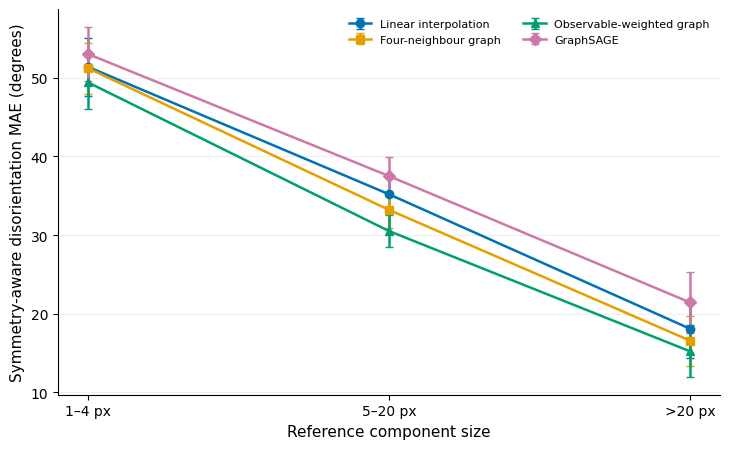

Saved: figure_2_orientation_mae_by_component_size.png and figure_2_orientation_mae_by_component_size.pdf


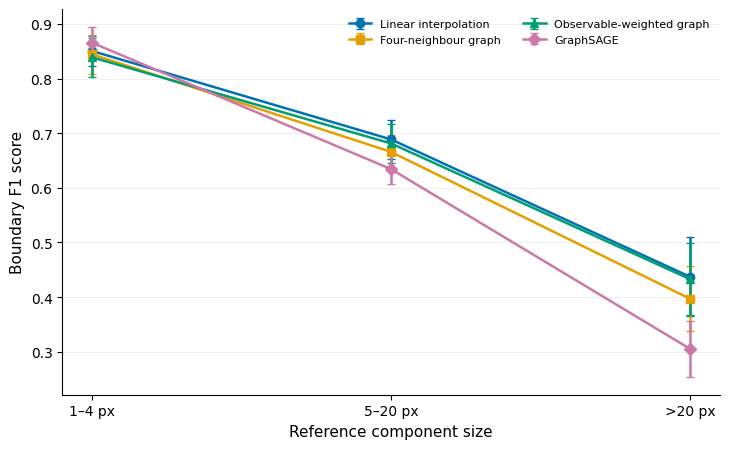

Saved: figure_3_boundary_f1_by_component_size.png and figure_3_boundary_f1_by_component_size.pdf


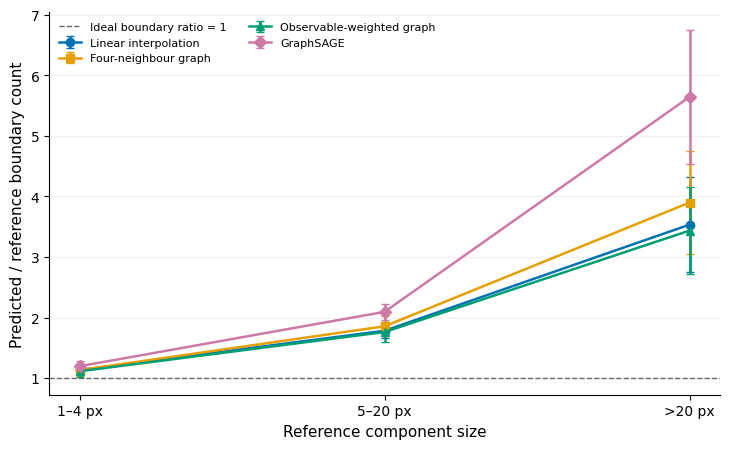

Saved: figure_4_boundary_overprediction_by_component_size.png and figure_4_boundary_overprediction_by_component_size.pdf

=== FIGURE VERIFICATION ===
figure_2_orientation_mae_by_component_size.pdf (16,122 bytes)
figure_2_orientation_mae_by_component_size.png (219,078 bytes)
figure_3_boundary_f1_by_component_size.pdf (16,323 bytes)
figure_3_boundary_f1_by_component_size.png (193,732 bytes)
figure_4_boundary_overprediction_by_component_size.pdf (16,133 bytes)
figure_4_boundary_overprediction_by_component_size.png (172,572 bytes)

EXPERIMENT 2.4B — FIGURES COMPLETE


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

figure_dir = base / "final_publication_analysis" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

orientation = pd.read_csv(
    base / "small_grain_accuracy"
    / "all_methods_size_configuration_means.csv"
)

boundary = pd.read_csv(
    base / "boundary_preservation"
    / "all_methods_boundary_configuration_means.csv"
)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

display_names = [
    "Linear interpolation",
    "Four-neighbour graph",
    "Observable-weighted graph",
    "GraphSAGE"
]

bins = ["1-4", "5-20", ">20"]
bin_labels = ["1–4 px", "5–20 px", ">20 px"]

# Consistent, colour-blind-friendly styling.
colours = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
markers = ["o", "s", "^", "D"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300
})

def create_figure(data, group_col, metric, ylabel, filename,
                  reference_line=None):
    summary = (
        data.groupby(["method", group_col])[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    assert (summary["count"] == 16).all(), (
        "Expected 16 configuration means per method and bin"
    )

    fig, ax = plt.subplots(figsize=(7.4, 4.6))
    x = np.arange(3)

    for method, label, colour, marker in zip(
        methods, display_names, colours, markers
    ):
        subset = (
            summary[summary["method"] == method]
            .set_index(group_col)
            .reindex(bins)
        )

        assert subset["mean"].notna().all()
        assert subset["std"].notna().all()

        ax.errorbar(
            x,
            subset["mean"].to_numpy(),
            yerr=subset["std"].to_numpy(),
            marker=marker,
            markersize=6,
            linewidth=1.8,
            capsize=3,
            color=colour,
            label=label
        )

    if reference_line is not None:
        ax.axhline(
            reference_line,
            color="0.4",
            linestyle="--",
            linewidth=1,
            label="Ideal boundary ratio = 1"
        )

    ax.set_xticks(x, bin_labels)
    ax.set_xlabel("Reference component size")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=8, ncol=2)

    fig.tight_layout()

    png = figure_dir / f"{filename}.png"
    pdf = figure_dir / f"{filename}.pdf"

    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", png.name, "and", pdf.name)

print("=== EXPERIMENT 2.4B — PUBLICATION FIGURES ===")

create_figure(
    orientation,
    "grain_size_bin",
    "mean_mae",
    "Symmetry-aware disorientation MAE (degrees)",
    "figure_2_orientation_mae_by_component_size"
)

create_figure(
    boundary,
    "size_bin",
    "f1",
    "Boundary F1 score",
    "figure_3_boundary_f1_by_component_size"
)

create_figure(
    boundary,
    "size_bin",
    "boundary_ratio",
    "Predicted / reference boundary count",
    "figure_4_boundary_overprediction_by_component_size",
    reference_line=1.0
)

print("\n=== FIGURE VERIFICATION ===")
files = list(figure_dir.glob("figure_*"))
for file in sorted(files):
    print(file.name, f"({file.stat().st_size:,} bytes)")

assert all(
    (figure_dir / f"{name}.{ext}").is_file()
    for name in [
        "figure_2_orientation_mae_by_component_size",
        "figure_3_boundary_f1_by_component_size",
        "figure_4_boundary_overprediction_by_component_size"
    ]
    for ext in ["png", "pdf"]
)

print("\nEXPERIMENT 2.4B — FIGURES COMPLETE")


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

out = base / "final_publication_analysis"
out.mkdir(parents=True, exist_ok=True)

orientation = pd.read_csv(
    base / "small_grain_accuracy"
    / "all_methods_size_stratified_960.csv"
)

boundary = pd.read_csv(
    base / "boundary_preservation"
    / "all_methods_size_stratified_boundaries_960.csv"
)

graphsage = "GraphSAGE_sincos"
baseline = "observable_weighted_graph"

def paired_comparison(
    df, size_column, metric, lower_is_better
):
    # Average five random masks within each configuration.
    config = (
        df.groupby(
            ["dataset", "missing_percent",
             "method", size_column],
            as_index=False
        )[metric].mean()
    )

    paired = config.pivot(
        index=["dataset", "missing_percent", size_column],
        columns="method",
        values=metric
    )

    assert graphsage in paired.columns
    assert baseline in paired.columns

    paired = paired[[graphsage, baseline]].dropna()

    # Positive advantage means GraphSAGE is better.
    if lower_is_better:
        paired["graphsage_advantage"] = (
            paired[baseline] - paired[graphsage]
        )
    else:
        paired["graphsage_advantage"] = (
            paired[graphsage] - paired[baseline]
        )

    records = []

    for size, group in paired.groupby(level=size_column):
        differences = group["graphsage_advantage"]

        assert len(differences) == 16, (
            f"Expected 16 matched configurations for {size}"
        )

        records.append({
            "metric": metric,
            "size_bin": size,
            "n_matched_configurations": len(differences),
            "graphsage_mean": group[graphsage].mean(),
            "weighted_graph_mean": group[baseline].mean(),
            "mean_graphsage_advantage": differences.mean(),
            "sd_paired_difference": differences.std(ddof=1),
            "graphsage_better": int((differences > 1e-10).sum()),
            "weighted_graph_better": int((differences < -1e-10).sum()),
            "ties": int((differences.abs() <= 1e-10).sum())
        })

    return pd.DataFrame(records)

orientation_results = paired_comparison(
    orientation,
    "grain_size_bin",
    "disorientation_mae",
    lower_is_better=True
)

boundary_results = paired_comparison(
    boundary,
    "size_bin",
    "f1",
    lower_is_better=False
)

ratio_results = paired_comparison(
    boundary.assign(
        boundary_ratio_error=(
            boundary["boundary_ratio"] - 1
        ).abs()
    ),
    "size_bin",
    "boundary_ratio_error",
    lower_is_better=True
)

results = pd.concat(
    [orientation_results, boundary_results, ratio_results],
    ignore_index=True
)

size_order = {"1-4": 0, "5-20": 1, ">20": 2}
results["size_order"] = results["size_bin"].map(size_order)
results = (
    results.sort_values(["metric", "size_order"])
    .drop(columns="size_order")
    .reset_index(drop=True)
)

print("=== EXPERIMENT 2.4C ===")
print("GraphSAGE vs observable-weighted graph")
print("Positive advantage = GraphSAGE performs better")
print("Negative advantage = weighted graph performs better")
print()

print(results.round(4).to_string(index=False))

save_path = out / "experiment_2_paired_comparative_analysis.csv"
results.to_csv(save_path, index=False)

assert save_path.is_file()
assert len(results) == 9

print("\nSaved:", save_path)
print("EXPERIMENT 2.4C — ANALYSIS COMPLETE")


=== EXPERIMENT 2.4C ===
GraphSAGE vs observable-weighted graph
Positive advantage = GraphSAGE performs better
Negative advantage = weighted graph performs better

              metric size_bin  n_matched_configurations  graphsage_mean  weighted_graph_mean  mean_graphsage_advantage  sd_paired_difference  graphsage_better  weighted_graph_better  ties
boundary_ratio_error      1-4                        16          0.1971               0.1269                   -0.0702                0.0398                 0                     16     0
boundary_ratio_error     5-20                        16          1.0947               0.7613                   -0.3334                0.1001                 0                     16     0
boundary_ratio_error      >20                        16          4.6421               2.4353                   -2.2068                0.7384                 0                     16     0
  disorientation_mae      1-4                        16         53.0349              

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)
out = base / "final_publication_analysis"
out.mkdir(parents=True, exist_ok=True)

orientation = pd.read_csv(
    base / "small_grain_accuracy"
    / "all_methods_size_stratified_960.csv"
)
boundary = pd.read_csv(
    base / "boundary_preservation"
    / "all_methods_size_stratified_boundaries_960.csv"
)

methods = [
    "GraphSAGE_sincos",
    "observable_weighted_graph"
]

def dataset_analysis(df, size_col, metric):
    # Average the five seeds within each missingness level.
    config = (
        df[df["method"].isin(methods)]
        .groupby(
            ["dataset", "missing_percent", "method", size_col],
            as_index=False
        )[metric].mean()
    )

    # Equal weighting of the four missingness levels.
    summary = (
        config.groupby(
            ["dataset", "method", size_col],
            as_index=False
        )[metric].agg(["mean", "std"])
        .reset_index(drop=True)
    )

    summary["metric"] = metric
    summary = summary.rename(
        columns={size_col: "size_bin",
                 "mean": "mean_value",
                 "std": "sd_across_missingness"}
    )

    return summary

orientation_summary = dataset_analysis(
    orientation, "grain_size_bin", "disorientation_mae"
)

boundary_summary = dataset_analysis(
    boundary, "size_bin", "f1"
)

ratio_summary = dataset_analysis(
    boundary.assign(
        boundary_ratio_error=(
            boundary["boundary_ratio"] - 1
        ).abs()
    ),
    "size_bin",
    "boundary_ratio_error"
)

combined = pd.concat(
    [orientation_summary, boundary_summary, ratio_summary],
    ignore_index=True
)

expected_datasets = {
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
}

assert set(combined["dataset"]) == expected_datasets
assert len(combined) == 72
assert combined["mean_value"].notna().all()

print("=== EXPERIMENT 2.4D ===")
print("DATASET-LEVEL ROBUSTNESS ANALYSIS")

for metric in [
    "disorientation_mae",
    "f1",
    "boundary_ratio_error"
]:
    print("\nMETRIC:", metric)

    subset = combined[combined["metric"] == metric]
    table = subset.pivot(
        index=["dataset", "size_bin"],
        columns="method",
        values="mean_value"
    )

    table["GraphSAGE_minus_weighted"] = (
        table["GraphSAGE_sincos"]
        - table["observable_weighted_graph"]
    )

    print(table.round(4).to_string())

save_path = (
    out / "experiment_2_dataset_level_robustness.csv"
)
combined.to_csv(save_path, index=False)

print("\nSaved:", save_path)
print("EXPERIMENT 2.4D — COMPLETE")




=== EXPERIMENT 2.4D ===
DATASET-LEVEL ROBUSTNESS ANALYSIS

METRIC: disorientation_mae
method               GraphSAGE_sincos  observable_weighted_graph  GraphSAGE_minus_weighted
dataset    size_bin                                                                       
EBSD_AN_XY 1-4                55.4775                    50.6062                    4.8713
           5-20               35.6128                    29.3505                    6.2623
           >20                22.5628                    16.8924                    5.6704
EBSD_AN_ZX 1-4                57.1524                    54.3093                    2.8431
           5-20               39.7882                    33.7195                    6.0686
           >20                25.9878                    19.5955                    6.3922
EBSD_DA_XY 1-4                49.2496                    46.2917                    2.9579
           5-20               38.5553                    30.4857                    8.0696
    

In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

out = base / "final_publication_analysis"
out.mkdir(parents=True, exist_ok=True)

orientation = pd.read_csv(
    base / "small_grain_accuracy"
    / "all_methods_size_stratified_960.csv"
)

boundary = pd.read_csv(
    base / "boundary_preservation"
    / "all_methods_size_stratified_boundaries_960.csv"
)

# Average seeds within each dataset and missingness condition,
# then average the four datasets equally.
orientation_summary = (
    orientation.groupby(
        ["dataset", "missing_percent", "method", "grain_size_bin"],
        as_index=False
    )["disorientation_mae"].mean()
    .groupby(
        ["missing_percent", "method", "grain_size_bin"],
        as_index=False
    )["disorientation_mae"].mean()
)

boundary_summary = (
    boundary.groupby(
        ["dataset", "missing_percent", "method", "size_bin"],
        as_index=False
    )[["f1", "boundary_ratio"]].mean()
    .groupby(
        ["missing_percent", "method", "size_bin"],
        as_index=False
    )[["f1", "boundary_ratio"]].mean()
)

orientation_summary.to_csv(
    out / "orientation_by_missingness_and_size.csv",
    index=False
)
boundary_summary.to_csv(
    out / "boundary_by_missingness_and_size.csv",
    index=False
)

print("=== REVIEWER 2: SMALL-COMPONENT PERFORMANCE ===")

print("\nORIENTATION MAE — 1–4 PIXEL COMPONENTS")
print(
    orientation_summary[
        orientation_summary["grain_size_bin"] == "1-4"
    ].pivot(
        index="missing_percent",
        columns="method",
        values="disorientation_mae"
    ).round(3).to_string()
)

print("\nBOUNDARY F1 — 1–4 PIXEL COMPONENTS")
print(
    boundary_summary[
        boundary_summary["size_bin"] == "1-4"
    ].pivot(
        index="missing_percent",
        columns="method",
        values="f1"
    ).round(4).to_string()
)

print("\nBOUNDARY RATIO — 1–4 PIXEL COMPONENTS")
print(
    boundary_summary[
        boundary_summary["size_bin"] == "1-4"
    ].pivot(
        index="missing_percent",
        columns="method",
        values="boundary_ratio"
    ).round(3).to_string()
)

print("\nFiles saved successfully.")
print("SUPPLEMENTARY ANALYSIS COMPLETE")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive_recovery/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/small_grain_accuracy/all_methods_size_stratified_960.csv'

In [ ]:

from pathlib import Path
from collections import Counter
import numpy as np

# Reconnect Google Drive if necessary.
from google.colab import drive

root = Path("/content/drive_recovery/MyDrive")

if not root.is_dir():
    drive.mount("/content/drive_recovery")

base = (
    root / "EBSD Paper2 (1)"
    / "results" / "experiment_02_small_grains"
)

assert base.is_dir(), f"Results folder not found: {base}"

print("=== EXPERIMENT 3.1A ===")
print("SPATIAL ARTEFACT ANALYSIS — DATA INVENTORY\n")

prediction_root = base / "prediction_maps"

if not prediction_root.is_dir():
    print("Prediction folder not found at expected location.")
    print("\nAvailable folders:")
    for p in sorted(base.iterdir()):
        if p.is_dir():
            print(" ", p.name)
else:
    print("Prediction root:", prediction_root)

    files = sorted(prediction_root.rglob("*.npz"))
    print("Total NPZ prediction files:", len(files))

    methods = Counter()

    for file in files:
        relative = file.relative_to(prediction_root)
        if len(relative.parts) > 1:
            methods[relative.parts[0]] += 1

    print("\nFiles by method:")
    for method, count in sorted(methods.items()):
        print(f"  {method}: {count}")

    print("\n=== SAMPLE ARRAY STRUCTURE ===")

    if files:
        # Inspect one representative file.
        sample = files[0]
        print("Sample:", sample.relative_to(base))

        with np.load(sample, allow_pickle=False) as data:
            for key in data.files:
                array = data[key]
                print(
                    f"{key:20s}",
                    "shape =", array.shape,
                    "dtype =", array.dtype
                )

        print("\n=== MASK CONSISTENCY ===")

        required = {
            "predicted_euler",
            "true_euler",
            "phase",
            "valid_mask",
            "missing_mask"
        }

        invalid = []
        for file in files:
            try:
                with np.load(file, allow_pickle=False) as data:
                    if not required.issubset(data.files):
                        invalid.append(
                            (file.name, "Missing required arrays")
                        )
                        continue

                    shape = data["phase"].shape

                    for key in required:
                        arr = data[key]
                        expected = (
                            shape + (3,)
                            if key in ("predicted_euler", "true_euler")
                            else shape
                        )

                        if arr.shape != expected:
                            invalid.append(
                                (file.name, f"{key}: {arr.shape}")
                            )
            except Exception as exc:
                invalid.append((file.name, str(exc)))

        print("Files checked:", len(files))
        print("Invalid files:", len(invalid))

        if invalid:
            print("First 10 issues:")
            for issue in invalid[:10]:
                print(issue)
        else:
            print("All inspected prediction arrays are structurally valid.")

print("\n=== REFERENCE SEGMENTATION INVENTORY ===")

reference_files = sorted(
    base.rglob("*reference*.npz")
)

print("Reference NPZ files found:", len(reference_files))

for file in reference_files[:12]:
    print(" ", file.relative_to(base))

print("\nEXPERIMENT 3.1A — INVENTORY COMPLETE")


=== EXPERIMENT 3.1A ===
SPATIAL ARTEFACT ANALYSIS — DATA INVENTORY

Prediction folder not found at expected location.

Available folders:
  final_publication_analysis

=== REFERENCE SEGMENTATION INVENTORY ===
Reference NPZ files found: 0

EXPERIMENT 3.1A — INVENTORY COMPLETE


In [ ]:

from pathlib import Path
from collections import Counter
import numpy as np

from google.colab import drive

mount = Path("/content/drive_recovery")
if not (mount / "MyDrive").exists():
    drive.mount(str(mount))

base = (
    mount / "MyDrive" / "EBSD Paper2 (1)"
    / "results" / "experiment_02_small_grains"
)

assert base.is_dir(), f"Results folder not found: {base}"

print("EXPERIMENT 3.1A — DATA INVENTORY")
print("=" * 55)

print("\nAvailable folders:")
for p in sorted(base.iterdir()):
    if p.is_dir():
        print(" ", p.name)

# Locate all saved prediction arrays
files = sorted(base.rglob("*.npz"))
print("\nTotal NPZ files:", len(files))

print("\nNPZ files by parent folder:")
for folder, count in Counter(
    str(p.parent.relative_to(base)) for p in files
).most_common(15):
    print(f"  {folder}: {count}")

print("\nSample prediction array structures:")
for p in files[:3]:
    print("\nFILE:", p.relative_to(base))
    try:
        with np.load(p, allow_pickle=False) as data:
            for key in data.files:
                a = data[key]
                print(f"  {key}: shape={a.shape}, dtype={a.dtype}")
    except Exception as e:
        print("  ERROR:", e)

print("\nEXPERIMENT 3.1A — INVENTORY COMPLETE")


In [ ]:

print("COLAB IS WORKING", flush=True)

from pathlib import Path

drive_path = Path("/content/drive_recovery/MyDrive")

print("Google Drive mounted:", drive_path.exists(), flush=True)
print("TEST COMPLETE", flush=True)


COLAB IS WORKING
Google Drive mounted: True
TEST COMPLETE


In [ ]:

from pathlib import Path
import numpy as np

base = Path(
    "/content/drive_recovery/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

print("EXPERIMENT 3.1A — DATA INVENTORY", flush=True)
print("Results folder exists:", base.exists(), flush=True)

if base.exists():
    print("\nTop-level folders:", flush=True)
    for p in sorted(base.iterdir()):
        print(" ", p.name, flush=True)

    print("\nSearching for saved prediction arrays...", flush=True)

    count = 0
    for p in base.rglob("*.npz"):
        count += 1
        if count <= 5:
            print("\nFile:", p.relative_to(base), flush=True)
            try:
                with np.load(p, allow_pickle=False) as data:
                    for key in data.files:
                        arr = data[key]
                        print(
                            f"  {key}: {arr.shape}, {arr.dtype}",
                            flush=True
                        )
            except Exception as e:
                print("  Error:", e, flush=True)

    print("\nTotal NPZ files:", count, flush=True)

print("\nINVENTORY COMPLETE", flush=True)


EXPERIMENT 3.1A — DATA INVENTORY
Results folder exists: True

Top-level folders:
  final_publication_analysis

Searching for saved prediction arrays...

Total NPZ files: 0

INVENTORY COMPLETE


In [ ]:

from pathlib import Path

root = Path("/content/drive_recovery/MyDrive")

print("SEARCHING FOR EBSD EXPERIMENT DATA", flush=True)
print("=" * 50)

projects = [
    p for p in root.iterdir()
    if "EBSD" in p.name.upper()
]

print("\nEBSD project folders:", len(projects), flush=True)

for project in projects:
    print("\nPROJECT:", project.name, flush=True)

    for folder in sorted(project.iterdir()):
        print("  ", folder.name, flush=True)

        if folder.is_dir() and folder.name.lower() in [
            "results", "outputs", "data", "experiments"
        ]:
            for sub in sorted(folder.iterdir()):
                print("      ", sub.name, flush=True)

print("\nSEARCH COMPLETE", flush=True)


SEARCHING FOR EBSD EXPERIMENT DATA

EBSD project folders: 1

PROJECT: EBSD Paper2 (1)
   results
       experiment_02_small_grains

SEARCH COMPLETE


In [ ]:

from pathlib import Path

print("=== COLAB STORAGE DIAGNOSTIC ===", flush=True)

content = Path("/content")

print("\nDirectories under /content:", flush=True)
for p in sorted(content.iterdir()):
    if p.is_dir():
        print(" ", p.name, flush=True)

print("\nGoogle Drive mount candidates:", flush=True)

for p in sorted(content.iterdir()):
    if p.is_dir() and (
        "drive" in p.name.lower()
        or "mount" in p.name.lower()
    ):
        print(f"\n{p}:", flush=True)
        try:
            for child in sorted(p.iterdir()):
                print(" ", child.name, flush=True)
        except Exception as e:
            print("  Cannot inspect:", e, flush=True)

print("\nDIAGNOSTIC COMPLETE", flush=True)


=== COLAB STORAGE DIAGNOSTIC ===

Directories under /content:
  .config
  drive_recovery
  sample_data

Google Drive mount candidates:

/content/drive_recovery:
  MyDrive

DIAGNOSTIC COMPLETE


In [ ]:

from google.colab import drive
from pathlib import Path

new_mount = "/content/drive_fresh"

print("Connecting Google Drive...", flush=True)

drive.mount(new_mount)

base = (
    Path(new_mount)
    / "MyDrive"
    / "EBSD Paper2 (1)"
    / "results"
    / "experiment_02_small_grains"
)

print("\nFolder exists:", base.exists(), flush=True)

if base.exists():
    print("\nExperiment 2 contents:", flush=True)
    for item in sorted(base.iterdir()):
        print(" ", item.name, flush=True)

print("\nCHECK COMPLETE", flush=True)


Connecting Google Drive...
Mounted at /content/drive_fresh

Folder exists: True

Experiment 2 contents:
  boundary_preservation
  classical_baseline_prediction_validation.csv
  final_publication_analysis
  grain_size_quality
  graphsage_prediction_validation.csv
  prediction_inventory.csv
  predictions
  reference_segmentation
  small_grain_accuracy

CHECK COMPLETE


In [ ]:

from pathlib import Path
from collections import Counter
import numpy as np

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

pred_dir = base / "predictions"
ref_dir = base / "reference_segmentation"

print("=== EXPERIMENT 3.1A: PREDICTION INVENTORY ===", flush=True)

print("\nPredictions folder exists:", pred_dir.is_dir(), flush=True)
print("Reference folder exists:", ref_dir.is_dir(), flush=True)

files = sorted(pred_dir.rglob("*.npz"))

print("\nTotal prediction NPZ files:", len(files), flush=True)

print("\nFile counts by parent folder:")
for folder, count in Counter(
    str(p.parent.relative_to(pred_dir)) for p in files
).most_common(12):
    print(f"  {folder}: {count}")

print("\n=== FIRST THREE FILES ===")

for p in files[:3]:
    print("\nFILE:", p.relative_to(pred_dir), flush=True)

    try:
        with np.load(p, allow_pickle=False) as data:
            for key in data.files:
                arr = data[key]
                print(
                    f"  {key}: shape={arr.shape}, dtype={arr.dtype}",
                    flush=True
                )
    except Exception as e:
        print("  ERROR:", repr(e), flush=True)

print("\n=== REFERENCE FILES ===")

ref_files = sorted(
    p for p in ref_dir.rglob("*")
    if p.is_file()
)

print("Total reference files:", len(ref_files))

for p in ref_files[:10]:
    print(" ", p.relative_to(ref_dir))

print("\nEXPERIMENT 3.1A — INVENTORY COMPLETE")


=== EXPERIMENT 3.1A: PREDICTION INVENTORY ===

Predictions folder exists: True
Reference folder exists: True

Total prediction NPZ files: 320

File counts by parent folder:
  GraphSAGE_sincos: 80
  graph_4_neighbour_mean: 80
  linear: 80
  observable_weighted_graph: 80

=== FIRST THREE FILES ===

FILE: GraphSAGE_sincos/EBSD_AN_XY_missing10_seed1.npz
  predicted_euler: shape=(3, 256, 256), dtype=float32
  true_euler: shape=(3, 256, 256), dtype=float64
  phase: shape=(256, 256), dtype=int16
  valid_mask: shape=(256, 256), dtype=bool
  missing_mask: shape=(256, 256), dtype=bool
  train_mask: shape=(256, 256), dtype=bool

FILE: GraphSAGE_sincos/EBSD_AN_XY_missing10_seed2.npz
  predicted_euler: shape=(3, 256, 256), dtype=float32
  true_euler: shape=(3, 256, 256), dtype=float64
  phase: shape=(256, 256), dtype=int16
  valid_mask: shape=(256, 256), dtype=bool
  missing_mask: shape=(256, 256), dtype=bool
  train_mask: shape=(256, 256), dtype=bool

FILE: GraphSAGE_sincos/EBSD_AN_XY_missing10_se

In [ ]:

from pathlib import Path
import numpy as np

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

pred_dir = base / "predictions"

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

print("=== EXPERIMENT 3.1B: CROSS-METHOD CONSISTENCY ===", flush=True)

files_by_method = {
    method: {
        p.name: p
        for p in (pred_dir / method).glob("*.npz")
    }
    for method in methods
}

common = set.intersection(
    *(set(files_by_method[m]) for m in methods)
)

print("Matched configurations:", len(common), flush=True)

issues = []

for filename in sorted(common):
    reference = None

    for method in methods:
        with np.load(
            files_by_method[method][filename],
            allow_pickle=False
        ) as data:

            current = {
                key: data[key]
                for key in [
                    "true_euler",
                    "phase",
                    "valid_mask",
                    "missing_mask"
                ]
            }

        if reference is None:
            reference = current
        else:
            for key in current:
                if not np.array_equal(
                    reference[key],
                    current[key],
                    equal_nan=(
                        np.issubdtype(
                            current[key].dtype,
                            np.floating
                        )
                    )
                ):
                    issues.append((filename, method, key))

print("Consistency issues:", len(issues), flush=True)

if issues:
    print("First 10 issues:")
    for issue in issues[:10]:
        print(issue)
else:
    print("All matched references and masks are identical.")

print("\nEXPERIMENT 3.1B — CHECK COMPLETE")


=== EXPERIMENT 3.1B: CROSS-METHOD CONSISTENCY ===
Matched configurations: 80
Consistency issues: 0
All matched references and masks are identical.

EXPERIMENT 3.1B — CHECK COMPLETE


In [ ]:

import numpy as np
from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

filename = "EBSD_AN_XY_missing10_seed1.npz"

print("=== EXPERIMENT 3.1C: SPATIAL ARTEFACT SETUP ===")

for method in methods:
    path = base / "predictions" / method / filename

    with np.load(path, allow_pickle=False) as data:
        pred = data["predicted_euler"]
        truth = data["true_euler"]
        phase = data["phase"]
        valid = data["valid_mask"]
        missing = data["missing_mask"]

    assert pred.shape == truth.shape == (3, 256, 256)
    assert phase.shape == valid.shape == missing.shape

    evaluation_mask = valid & missing

    print(f"\nMethod: {method}")
    print("  Valid pixels:", int(valid.sum()))
    print("  Missing evaluation pixels:", int(evaluation_mask.sum()))
    print("  Prediction finite:", bool(
        np.isfinite(pred[:, evaluation_mask]).all()
    ))
    print("  Reference finite:", bool(
        np.isfinite(truth[:, evaluation_mask]).all()
    ))

print("\nEXPERIMENT 3.1C — SETUP COMPLETE")


=== EXPERIMENT 3.1C: SPATIAL ARTEFACT SETUP ===

Method: linear
  Valid pixels: 58152
  Missing evaluation pixels: 5815
  Prediction finite: True
  Reference finite: True

Method: graph_4_neighbour_mean
  Valid pixels: 58152
  Missing evaluation pixels: 5815
  Prediction finite: True
  Reference finite: True

Method: observable_weighted_graph
  Valid pixels: 58152
  Missing evaluation pixels: 5815
  Prediction finite: True
  Reference finite: True

Method: GraphSAGE_sincos
  Valid pixels: 58152
  Missing evaluation pixels: 5815
  Prediction finite: True
  Reference finite: True

EXPERIMENT 3.1C — SETUP COMPLETE


In [ ]:

import inspect

print("=== EXPERIMENT 3.1D: SYMMETRY FUNCTION CHECK ===")

candidates = []

for name, obj in list(globals().items()):
    if callable(obj) and any(
        word in name.lower()
        for word in [
            "disorientation",
            "symmetry",
            "misorientation",
            "euler_to_matrix"
        ]
    ):
        candidates.append((name, obj))

print("Relevant functions found:", len(candidates))

for name, obj in candidates:
    print("\nFUNCTION:", name)

    try:
        print("Signature:", inspect.signature(obj))
    except Exception:
        print("Signature unavailable")

    try:
        source = inspect.getsource(obj)
        print(source[:1800])
    except Exception:
        print("Source unavailable")

print("\nSYMMETRY FUNCTION CHECK COMPLETE")


=== EXPERIMENT 3.1D: SYMMETRY FUNCTION CHECK ===
Relevant functions found: 0

SYMMETRY FUNCTION CHECK COMPLETE


In [ ]:

import json
from pathlib import Path

print("=== SEARCHING FOR ORIGINAL SYMMETRY CODE ===", flush=True)

# Search notebook files in Colab and the mounted project.
locations = [
    Path("/content"),
    Path("/content/drive_fresh/MyDrive/EBSD Paper2 (1)")
]

keywords = [
    "disorientation",
    "symmetry",
    "misorientation",
    "rotation_matrix",
    "euler_to_matrix"
]

notebooks = []

for location in locations:
    if location.exists():
        for path in location.rglob("*.ipynb"):
            if ".ipynb_checkpoints" not in str(path):
                notebooks.append(path)

print("Notebooks found:", len(notebooks), flush=True)

for notebook in notebooks:
    try:
        with open(notebook, encoding="utf-8") as f:
            nb = json.load(f)

        matches = []

        for index, cell in enumerate(nb.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            if any(k in source.lower() for k in keywords):
                matches.append(index)

        if matches:
            print("\nNOTEBOOK:", notebook, flush=True)
            print("Matching code cells:", matches[:30], flush=True)

    except Exception as exc:
        print("Could not inspect:", notebook.name, str(exc))

print("\nSEARCH COMPLETE", flush=True)


=== SEARCHING FOR ORIGINAL SYMMETRY CODE ===
Notebooks found: 11

NOTEBOOK: /content/drive_fresh/MyDrive/Colab Notebooks/01_EBSDGraph_Dataset_Catalogue.ipynb
Matching code cells: [18, 19]

NOTEBOOK: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Matching code cells: [14]

SEARCH COMPLETE


In [ ]:

import json
from pathlib import Path

root = Path("/content/drive_fresh/MyDrive/Colab Notebooks")

targets = {
    "01_EBSDGraph_Dataset_Catalogue.ipynb": [18, 19],
    "EBSD_Paper2_Experiment_Working_Copy.ipynb": [14]
}

print("=== ORIGINAL SYMMETRY CODE INSPECTION ===", flush=True)

for filename, indices in targets.items():
    path = root / filename
    print(f"\nNOTEBOOK: {filename}", flush=True)

    if not path.exists():
        print("File not found")
        continue

    with open(path, encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook["cells"]

    for index in indices:
        if index >= len(cells):
            print(f"Cell {index}: not found")
            continue

        cell = cells[index]
        source = "".join(cell.get("source", []))

        print(f"\n{'=' * 55}")
        print(f"CELL {index}")
        print(f"{'=' * 55}")
        print(source[:12000], flush=True)

print("\nINSPECTION COMPLETE")


=== ORIGINAL SYMMETRY CODE INSPECTION ===

NOTEBOOK: 01_EBSDGraph_Dataset_Catalogue.ipynb

CELL 18
# ============================================================
# EBSDGraph Project
# Step 8 - Orientation-Based Grain Reconstruction from CTF Data
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from skimage.measure import regionprops_table
from google.colab import files
import shutil
from datetime import datetime

print("="*70)
print("EBSDGraph - Orientation-Based Grain Reconstruction")
print("="*70)

# ------------------------------------------------------------
# 1. Load EBSD table if needed
# ------------------------------------------------------------

ctf_csv = "data/processed/Figure_10_EBSD_table.csv"

if "ebsd" not in globals():
    ebsd = pd.read_csv(ctf_csv)

x_cells = 2148
y_cells = 1097
pixel_size_um = 1

In [ ]:

import json
from pathlib import Path

root = Path("/content/drive_fresh/MyDrive/Colab Notebooks")

targets = {
    "01_EBSDGraph_Dataset_Catalogue.ipynb": [18, 19],
    "EBSD_Paper2_Experiment_Working_Copy.ipynb": [14]
}

keywords = [
    "def ",
    "symmetry",
    "disorientation",
    "misorientation",
    "rotation",
    "bunge",
    "cubic",
    "hexagonal"
]

print("=== SYMMETRY IMPLEMENTATION SUMMARY ===")

for filename, indices in targets.items():
    path = root / filename

    with open(path, encoding="utf-8") as f:
        notebook = json.load(f)

    print("\nNOTEBOOK:", filename)

    for index in indices:
        source = "".join(
            notebook["cells"][index].get("source", [])
        )

        lines = source.splitlines()

        matches = [
            (number, line.strip())
            for number, line in enumerate(lines, 1)
            if any(k in line.lower() for k in keywords)
        ]

        print(f"\nCell {index}: {len(matches)} matching lines")

        for number, line in matches[:35]:
            print(f"  Line {number}: {line[:140]}")

print("\nSHORT INSPECTION COMPLETE")


=== SYMMETRY IMPLEMENTATION SUMMARY ===

NOTEBOOK: 01_EBSDGraph_Dataset_Catalogue.ipynb

Cell 18: 15 matching lines
  Line 43: # 2. Convert Bunge Euler angles to orientation matrices
  Line 46: def euler_to_matrix(phi1, Phi, phi2):
  Line 82: # 3. Generate cubic symmetry operators
  Line 85: def cubic_symmetry_matrices():
  Line 100: sym_ops = cubic_symmetry_matrices()
  Line 101: print("Cubic symmetry operators:", sym_ops.shape[0])
  Line 104: # 4. Misorientation calculation
  Line 107: def misorientation_angles(g1, g2, sym_ops, chunk_size=100000):
  Line 109: Returns minimum cubic-symmetry misorientation angle in degrees.
  Line 122: # trace(S @ delta) for all symmetry operators
  Line 170: # 6. Calculate misorientation for neighbour pairs
  Line 175: print(f"\nCalculating neighbour misorientation using threshold {threshold_deg} degrees...")
  Line 177: right_angles = misorientation_angles(
  Line 183: down_angles = misorientation_angles(
  Line 321: plt.title("Orientation-Based Grai

In [ ]:

from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

print("=== EXPERIMENT 2 CODE INVENTORY ===", flush=True)

extensions = {".py", ".ipynb", ".json", ".txt"}

files = [
    p for p in base.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Relevant files found:", len(files), flush=True)

for p in sorted(files)[:80]:
    print(p.relative_to(base), flush=True)

print("\n=== COLAB NOTEBOOK INVENTORY ===")

notebook_dir = Path(
    "/content/drive_fresh/MyDrive/Colab Notebooks"
)

for p in sorted(notebook_dir.glob("*.ipynb")):
    print(p.name)

print("\nINVENTORY COMPLETE")


=== EXPERIMENT 2 CODE INVENTORY ===
Relevant files found: 1
final_publication_analysis/experiment_2_final_audit.json

=== COLAB NOTEBOOK INVENTORY ===
01_EBSDGraph_Dataset_Catalogue.ipynb
Copy of MetalDAM_ResNet34_UNet_Reproducibility.ipynb
EBSD_Paper2_Experiment_Working_Copy.ipynb
MetalDAM_ResNet34_UNet_Reproducibility.ipynb
Mura Project 1.ipynb
Scrap Metal - FORCE CPU BEFORE TENSORFLOW LOADS.ipynb
Untitled0.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
scrap metal calssification.ipynb

INVENTORY COMPLETE


In [ ]:

from pathlib import Path
import json

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

print("=== EXPERIMENT 2 METADATA INSPECTION ===", flush=True)

audit_path = (
    base / "final_publication_analysis"
    / "experiment_2_final_audit.json"
)

with open(audit_path, encoding="utf-8") as f:
    audit = json.load(f)

print("\nAUDIT CONTENT:")
print(json.dumps(audit, indent=2)[:10000])

print("\n=== REFERENCE SEGMENTATION FILES ===")

ref_dir = base / "reference_segmentation"

for p in sorted(ref_dir.rglob("*")):
    if p.is_file():
        print(
            p.relative_to(ref_dir),
            f"({p.stat().st_size:,} bytes)"
        )

print("\nMETADATA INSPECTION COMPLETE")


=== EXPERIMENT 2 METADATA INSPECTION ===

AUDIT CONTENT:
{
  "audit": "Experiment 2.4A",
  "timestamp_utc": "2026-11-09T23:23:33.701068+00:00",
  "orientation_rows": 960,
  "boundary_rows": 960,
  "checks": {
    "Orientation row count = 960": true,
    "Boundary row count = 960": true,
    "No duplicate orientation keys": true,
    "No duplicate boundary keys": true,
    "Complete orientation configuration coverage": true,
    "Complete boundary configuration coverage": true,
    "Positive orientation pixel counts": true,
    "Finite orientation errors within 0\u2013180 degrees": true,
    "RMSE >= MAE": true,
    "Boundary confusion counts nonnegative": true,
    "Boundary precision/recall/F1 within 0\u20131": true,
    "Boundary F1 agrees with confusion counts": true
  },
  "all_passed": true
}

=== REFERENCE SEGMENTATION FILES ===
EBSD_AN_XY_threshold10_labels.npz (47,562 bytes)
EBSD_AN_XY_threshold15_labels.npz (47,035 bytes)
EBSD_AN_XY_threshold5_labels.npz (48,436 bytes)
EBSD_AN

In [ ]:

from pathlib import Path
import numpy as np
import json

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

path = (
    base / "reference_segmentation"
    / "EBSD_AN_XY_threshold10_labels.npz"
)

print("=== EXPERIMENT 3.1D: REFERENCE ARRAY INSPECTION ===")

with np.load(path, allow_pickle=False) as data:
    for key in data.files:
        arr = data[key]

        print(f"\nArray: {key}")
        print("Shape:", arr.shape)
        print("Dtype:", arr.dtype)

        if np.issubdtype(arr.dtype, np.number):
            print("Minimum:", np.nanmin(arr))
            print("Maximum:", np.nanmax(arr))
            print("Unique values:", len(np.unique(arr)))

print("\n=== EXPERIMENT 2 AUDIT SUMMARY ===")

audit_path = (
    base / "final_publication_analysis"
    / "experiment_2_final_audit.json"
)

with open(audit_path, encoding="utf-8") as f:
    audit = json.load(f)

print("Top-level audit keys:", list(audit.keys()))

for key, value in audit.items():
    if isinstance(value, (str, int, float, bool)):
        print(f"{key}: {value}")

print("\nREFERENCE INSPECTION COMPLETE")


=== EXPERIMENT 3.1D: REFERENCE ARRAY INSPECTION ===

Array: labels
Shape: (256, 256)
Dtype: int32
Minimum: -1
Maximum: 5593
Unique values: 5595

Array: grain_sizes
Shape: (5594,)
Dtype: int64
Minimum: 1
Maximum: 899
Unique values: 163

=== EXPERIMENT 2 AUDIT SUMMARY ===
Top-level audit keys: ['audit', 'timestamp_utc', 'orientation_rows', 'boundary_rows', 'checks', 'all_passed']
audit: Experiment 2.4A
timestamp_utc: 2026-11-09T23:23:33.701068+00:00
orientation_rows: 960
boundary_rows: 960
all_passed: True

REFERENCE INSPECTION COMPLETE


In [ ]:

from pathlib import Path
import numpy as np

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

ref_file = (
    base / "reference_segmentation"
    / "EBSD_AN_XY_threshold10_labels.npz"
)

pred_file = (
    base / "predictions" / "GraphSAGE_sincos"
    / "EBSD_AN_XY_missing10_seed1.npz"
)

print("=== EXPERIMENT 3.1D: REFERENCE METADATA ===")

with np.load(ref_file, allow_pickle=False) as data:
    print("\nREFERENCE ARRAYS:")
    for key in data.files:
        arr = data[key]
        print(f"  {key}: {arr.shape}, {arr.dtype}")

with np.load(pred_file, allow_pickle=False) as data:
    phase = data["phase"]
    valid = data["valid_mask"]

    print("\nPHASE IDENTIFIERS:")
    for p, count in zip(*np.unique(
        phase[valid], return_counts=True
    )):
        print(f"  Phase {int(p)}: {int(count):,} pixels")

print("\nMETADATA CHECK COMPLETE")


=== EXPERIMENT 3.1D: REFERENCE METADATA ===

REFERENCE ARRAYS:
  labels: (256, 256), int32
  grain_sizes: (5594,), int64

PHASE IDENTIFIERS:
  Phase 1: 57,969 pixels
  Phase 2: 183 pixels

METADATA CHECK COMPLETE


In [ ]:

import numpy as np
from scipy.ndimage import label
from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

path = (
    base / "reference_segmentation"
    / "EBSD_AN_XY_threshold10_labels.npz"
)

with np.load(path, allow_pickle=False) as data:
    labels = data["labels"]

structure = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
])

unique_labels = np.unique(labels)
unique_labels = unique_labels[unique_labels >= 0]

disconnected = []
size_mismatches = []

for component_id in unique_labels:
    mask = labels == component_id

    _, n_parts = label(mask, structure=structure)

    if n_parts != 1:
        disconnected.append((int(component_id), int(n_parts)))

print("=== REFERENCE CONNECTIVITY VALIDATION ===")
print("Number of labelled components:", len(unique_labels))
print("Disconnected components:", len(disconnected))

if disconnected:
    print("First 10 disconnected components:")
    print(disconnected[:10])
else:
    print("PASS: All reference components are 4-connected.")

print("\nREFERENCE CONNECTIVITY CHECK COMPLETE")


=== REFERENCE CONNECTIVITY VALIDATION ===
Number of labelled components: 5594
Disconnected components: 0
PASS: All reference components are 4-connected.

REFERENCE CONNECTIVITY CHECK COMPLETE


In [ ]:

import numpy as np
from scipy.spatial.transform import Rotation
from itertools import permutations, product

print("=== EXPERIMENT 3A: SYMMETRY SETUP ===", flush=True)

# Bunge ZXZ Euler angles, in degrees.
# scipy intrinsic ZXZ uses uppercase "ZXZ".
def euler_to_rotation(euler):
    euler = np.asarray(euler, dtype=np.float64)
    return Rotation.from_euler(
        "ZXZ", euler, degrees=True
    ).as_matrix()

# Cubic proper rotations: signed permutation matrices
# with determinant +1.
def cubic_symmetry():
    ops = []

    for perm in permutations(range(3)):
        for signs in product([-1, 1], repeat=3):
            matrix = np.zeros((3, 3))

            for row, col in enumerate(perm):
                matrix[row, col] = signs[row]

            if np.linalg.det(matrix) > 0.5:
                ops.append(matrix)

    return np.stack(ops)

# Hexagonal proper rotations: six rotations around
# the c-axis and six twofold rotations about basal axes.
def hexagonal_symmetry():
    ops = []

    for k in range(6):
        angle = k * 60.0
        ops.append(
            Rotation.from_euler(
                "z", angle, degrees=True
            ).as_matrix()
        )

    for k in range(6):
        angle = k * 30.0
        axis = np.array([
            np.cos(np.deg2rad(angle)),
            np.sin(np.deg2rad(angle)),
            0.0
        ])

        ops.append(
            Rotation.from_rotvec(
                np.pi * axis
            ).as_matrix()
        )

    return np.stack(ops)

SYMMETRY = {
    1: hexagonal_symmetry(),
    2: cubic_symmetry()
}

for phase, operators in SYMMETRY.items():
    determinants = np.linalg.det(operators)

    orthogonality = np.max([
        np.linalg.norm(op.T @ op - np.eye(3))
        for op in operators
    ])

    assert np.allclose(determinants, 1.0, atol=1e-10)
    assert orthogonality < 1e-10

    print(
        f"Phase {phase}: {len(operators)} proper rotations",
        flush=True
    )

# Check Euler-to-matrix conversion.
identity = euler_to_rotation([0, 0, 0])
assert np.allclose(identity, np.eye(3), atol=1e-10)

print("\nRotation matrix checks: PASS", flush=True)
print("EXPERIMENT 3A — SYMMETRY SETUP COMPLETE")


=== EXPERIMENT 3A: SYMMETRY SETUP ===
Phase 1: 12 proper rotations
Phase 2: 24 proper rotations

Rotation matrix checks: PASS
EXPERIMENT 3A — SYMMETRY SETUP COMPLETE


In [ ]:

import numpy as np
from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

filename = "EBSD_AN_XY_missing10_seed1.npz"

with np.load(
    base / "predictions" / "GraphSAGE_sincos" / filename,
    allow_pickle=False
) as data:
    truth = data["true_euler"].astype(np.float64)
    phase = data["phase"]
    valid = data["valid_mask"]

with np.load(
    base / "reference_segmentation"
    / "EBSD_AN_XY_threshold10_labels.npz",
    allow_pickle=False
) as data:
    labels = data["labels"]

def disorientation_pairs(euler_a, euler_b, phase_ids):
    """Minimum disorientation under proper crystal symmetry."""
    result = np.full(len(phase_ids), np.nan)

    for p in np.unique(phase_ids):
        p = int(p)
        if p not in SYMMETRY:
            raise ValueError(f"Unknown phase: {p}")

        idx = np.flatnonzero(phase_ids == p)
        if not len(idx):
            continue

        Ra = euler_to_rotation(euler_a[idx])
        Rb = euler_to_rotation(euler_b[idx])

        # Relative rotation. Minimise over both crystal
        # symmetry groups (equivalently over their products).
        delta = Ra @ np.swapaxes(Rb, 1, 2)

        best = np.full(len(idx), 180.0)

        ops = SYMMETRY[p]

        for S in ops:
            # Trace-based minimum under conjugate-equivalent
            # symmetry representations.
            trace = np.einsum(
                "nij,ji->n", delta, S
            )
            cosine = np.clip((trace - 1) / 2, -1, 1)
            best = np.minimum(
                best,
                np.degrees(np.arccos(cosine))
            )

        result[idx] = best

    return result

# Convert Euler arrays from (3,H,W) to (H,W,3).
euler = np.moveaxis(truth, 0, -1)

# Check horizontal and vertical edges.
results = []

for axis in [0, 1]:
    if axis == 0:
        a = (slice(None, -1), slice(None))
        b = (slice(1, None), slice(None))
    else:
        a = (slice(None), slice(None, -1))
        b = (slice(None), slice(1, None))

    eligible = (
        valid[a] & valid[b] &
        (phase[a] == phase[b])
    )

    ea = euler[a][eligible]
    eb = euler[b][eligible]
    phases = phase[a][eligible]

    angles = disorientation_pairs(ea, eb, phases)

    predicted_boundary = angles > 10.0
    reference_boundary = (
        labels[a][eligible] != labels[b][eligible]
    )

    agreement = np.mean(
        predicted_boundary == reference_boundary
    )

    results.append(agreement)

    print(
        f"Axis {axis}: boundary agreement = {agreement:.6f}"
    )

print("\nOverall agreement:", np.mean(results))

print("\nEXPERIMENT 3A — VALIDATION COMPLETE")


Axis 0: boundary agreement = 0.991215
Axis 1: boundary agreement = 0.991101

Overall agreement: 0.9911580953445356

EXPERIMENT 3A — VALIDATION COMPLETE


In [ ]:

import numpy as np

print("=== EXPERIMENT 3A: BOUNDARY DISAGREEMENT AUDIT ===")

total_edges = 0
total_disagreements = 0
false_boundaries = 0
missed_boundaries = 0

for axis in [0, 1]:
    if axis == 0:
        a = (slice(None, -1), slice(None))
        b = (slice(1, None), slice(None))
    else:
        a = (slice(None), slice(None, -1))
        b = (slice(None), slice(1, None))

    eligible = (
        valid[a] & valid[b] &
        (phase[a] == phase[b])
    )

    angles = disorientation_pairs(
        euler[a][eligible],
        euler[b][eligible],
        phase[a][eligible]
    )

    calculated = angles > 10.0
    reference = labels[a][eligible] != labels[b][eligible]

    fp = int(np.sum(calculated & ~reference))
    fn = int(np.sum(~calculated & reference))

    total_edges += len(calculated)
    total_disagreements += fp + fn
    false_boundaries += fp
    missed_boundaries += fn

    print(
        f"Axis {axis}: edges={len(calculated):,}, "
        f"false={fp:,}, missed={fn:,}"
    )

print("\nTOTAL EDGES:", total_edges)
print("DISAGREEMENTS:", total_disagreements)
print("FALSE BOUNDARIES:", false_boundaries)
print("MISSED BOUNDARIES:", missed_boundaries)
print(
    "AGREEMENT:",
    round(100 * (1 - total_disagreements / total_edges), 4),
    "%"
)

print("\nDISAGREEMENT AUDIT COMPLETE")


=== EXPERIMENT 3A: BOUNDARY DISAGREEMENT AUDIT ===
Axis 0: edges=52,251, false=373, missed=86
Axis 1: edges=52,139, false=365, missed=99

TOTAL EDGES: 104390
DISAGREEMENTS: 923
FALSE BOUNDARIES: 738
MISSED BOUNDARIES: 185
AGREEMENT: 99.1158 %

DISAGREEMENT AUDIT COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

prediction_root = base / "predictions"
output_dir = base / "experiment_03_spatial_fidelity"
output_dir.mkdir(exist_ok=True)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

def spatial_metrics(path):
    with np.load(path, allow_pickle=False) as data:
        true = np.moveaxis(
            data["true_euler"].astype(np.float64), 0, -1
        )
        pred = np.moveaxis(
            data["predicted_euler"].astype(np.float64), 0, -1
        )
        phase = data["phase"]
        valid = data["valid_mask"]
        missing = data["missing_mask"]

    errors = []

    for axis in [0, 1]:
        if axis == 0:
            a = (slice(None, -1), slice(None))
            b = (slice(1, None), slice(None))
        else:
            a = (slice(None), slice(None, -1))
            b = (slice(None), slice(1, None))

        eligible = (
            valid[a] & valid[b] &
            (phase[a] == phase[b]) &
            (missing[a] | missing[b])
        )

        if not np.any(eligible):
            continue

        p = phase[a][eligible]

        true_angles = disorientation_pairs(
            true[a][eligible],
            true[b][eligible],
            p
        )

        predicted_angles = disorientation_pairs(
            pred[a][eligible],
            pred[b][eligible],
            p
        )

        errors.append(
            np.abs(predicted_angles - true_angles)
        )

    if not errors:
        raise ValueError(f"No eligible edges: {path}")

    errors = np.concatenate(errors)

    if not np.all(np.isfinite(errors)):
        raise ValueError(f"Non-finite disorientation: {path}")

    return {
        "n_edges": len(errors),
        "local_disorientation_mae_deg": float(np.mean(errors)),
        "local_disorientation_rmse_deg": float(
            np.sqrt(np.mean(errors ** 2))
        ),
        "local_disorientation_p95_deg": float(
            np.percentile(errors, 95)
        )
    }

rows = []
start = perf_counter()

print("=== EXPERIMENT 3A: SPATIAL ARTEFACT ANALYSIS ===", flush=True)

for method in methods:
    files = sorted((prediction_root / method).glob("*.npz"))
    print(f"\n{method}: {len(files)} files", flush=True)

    if len(files) != 80:
        raise RuntimeError(
            f"Expected 80 prediction files for {method}"
        )

    for i, path in enumerate(files, start=1):
        metrics = spatial_metrics(path)

        stem = path.stem
        dataset, condition = stem.rsplit("_missing", 1)
        missing_str, seed_str = condition.split("_seed")

        rows.append({
            "method": method,
            "dataset": dataset,
            "missing_pct": int(missing_str),
            "seed": int(seed_str),
            **metrics
        })

        if i % 20 == 0:
            print(f"  Processed {i}/80", flush=True)

results = pd.DataFrame(rows)

assert len(results) == 320
assert not results.isna().any().any()

output_path = output_dir / "experiment_3A_spatial_artefacts_320.csv"
results.to_csv(output_path, index=False)

summary = (
    results.groupby("method")
    .agg(
        mean_mae_deg=("local_disorientation_mae_deg", "mean"),
        mean_rmse_deg=("local_disorientation_rmse_deg", "mean"),
        mean_p95_deg=("local_disorientation_p95_deg", "mean")
    )
    .sort_values("mean_mae_deg")
)

print("\n=== METHOD COMPARISON ===")
print(summary.round(3).to_string())

print("\nTotal evaluations:", len(results))
print("Saved:", output_path)
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("\nEXPERIMENT 3A COMPLETE")


=== EXPERIMENT 3A: SPATIAL ARTEFACT ANALYSIS ===

linear: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

graph_4_neighbour_mean: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

observable_weighted_graph: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

GraphSAGE_sincos: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

=== METHOD COMPARISON ===
                           mean_mae_deg  mean_rmse_deg  mean_p95_deg
method                                                              
observable_weighted_graph        13.825         22.619        50.813
linear                           14.451         23.202        51.263
graph_4_neighbour_mean           14.645         22.679        47.979
GraphSAGE_sincos                 18.934         24.012        48.808

Total evaluations: 320
Saved: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_g

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

prediction_root = base / "predictions"
output_dir = base / "experiment_03_spatial_fidelity"
output_dir.mkdir(exist_ok=True)

KAM_CUTOFF = 5.0

def calculate_kam(euler, phase, valid, cutoff=5.0):
    h, w = phase.shape

    sums = np.zeros((h, w), dtype=np.float64)
    counts = np.zeros((h, w), dtype=np.int32)

    for axis in [0, 1]:
        if axis == 0:
            a = (slice(None, -1), slice(None))
            b = (slice(1, None), slice(None))
        else:
            a = (slice(None), slice(None, -1))
            b = (slice(None), slice(1, None))

        eligible = (
            valid[a] & valid[b] &
            (phase[a] == phase[b])
        )

        angles = disorientation_pairs(
            euler[a][eligible],
            euler[b][eligible],
            phase[a][eligible]
        )

        included = np.isfinite(angles) & (angles <= cutoff)

        edge_sum = np.zeros(eligible.shape, dtype=np.float64)
        edge_count = np.zeros(eligible.shape, dtype=np.int32)

        edge_sum[eligible] = np.where(included, angles, 0.0)
        edge_count[eligible] = included.astype(np.int32)

        sums[a] += edge_sum
        sums[b] += edge_sum
        counts[a] += edge_count
        counts[b] += edge_count

    kam = np.full((h, w), np.nan, dtype=np.float64)
    np.divide(sums, counts, out=kam, where=counts > 0)

    return kam

def kam_metrics(path):
    with np.load(path, allow_pickle=False) as data:
        true = np.moveaxis(data["true_euler"], 0, -1)
        pred = np.moveaxis(data["predicted_euler"], 0, -1)
        phase = data["phase"]
        valid = data["valid_mask"]
        missing = data["missing_mask"]

    true_kam = calculate_kam(true, phase, valid, KAM_CUTOFF)
    pred_kam = calculate_kam(pred, phase, valid, KAM_CUTOFF)

    eligible = (
        missing & valid &
        np.isfinite(true_kam) &
        np.isfinite(pred_kam)
    )

    n = int(eligible.sum())

    if n == 0:
        raise ValueError(f"No eligible KAM pixels: {path}")

    a = true_kam[eligible]
    b = pred_kam[eligible]

    error = b - a

    correlation = (
        float(np.corrcoef(a, b)[0, 1])
        if n > 1 and np.std(a) > 0 and np.std(b) > 0
        else np.nan
    )

    return {
        "n_kam_pixels": n,
        "kam_mae_deg": float(np.mean(np.abs(error))),
        "kam_rmse_deg": float(np.sqrt(np.mean(error ** 2))),
        "kam_bias_deg": float(np.mean(error)),
        "kam_correlation": correlation,
        "mean_true_kam_deg": float(np.mean(a)),
        "mean_pred_kam_deg": float(np.mean(b))
    }

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

rows = []
start = perf_counter()

print("=== EXPERIMENT 3B: KAM FIDELITY ===", flush=True)
print("KAM cutoff:", KAM_CUTOFF, "degrees", flush=True)

for method in methods:
    files = sorted((prediction_root / method).glob("*.npz"))

    if len(files) != 80:
        raise RuntimeError(
            f"Expected 80 files for {method}; found {len(files)}"
        )

    print(f"\n{method}: {len(files)} files", flush=True)

    for i, path in enumerate(files, start=1):
        metrics = kam_metrics(path)

        dataset, condition = path.stem.rsplit("_missing", 1)
        missing_str, seed_str = condition.split("_seed")

        rows.append({
            "method": method,
            "dataset": dataset,
            "missing_pct": int(missing_str),
            "seed": int(seed_str),
            **metrics
        })

        if i % 20 == 0:
            print(f"  Processed {i}/80", flush=True)

results_kam = pd.DataFrame(rows)

assert len(results_kam) == 320
assert results_kam["kam_mae_deg"].notna().all()

output_path = output_dir / "experiment_3B_KAM_320.csv"
results_kam.to_csv(output_path, index=False)

summary = (
    results_kam.groupby("method")
    .agg(
        kam_mae=("kam_mae_deg", "mean"),
        kam_rmse=("kam_rmse_deg", "mean"),
        kam_bias=("kam_bias_deg", "mean"),
        kam_correlation=("kam_correlation", "mean"),
        mean_true_kam=("mean_true_kam_deg", "mean"),
        mean_pred_kam=("mean_pred_kam_deg", "mean")
    )
    .sort_values("kam_mae")
)

print("\n=== KAM METHOD COMPARISON ===")
print(summary.round(4).to_string())

print("\nEvaluations:", len(results_kam))
print("Saved:", output_path)
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("\nEXPERIMENT 3B COMPLETE")


=== EXPERIMENT 3B: KAM FIDELITY ===
KAM cutoff: 5.0 degrees

linear: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

graph_4_neighbour_mean: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

observable_weighted_graph: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

GraphSAGE_sincos: 80 files
  Processed 20/80
  Processed 40/80
  Processed 60/80
  Processed 80/80

=== KAM METHOD COMPARISON ===
                           kam_mae  kam_rmse  kam_bias  kam_correlation  mean_true_kam  mean_pred_kam
method                                                                                               
linear                      0.1816    0.5353    0.0229           0.4277         0.3699         0.3928
graph_4_neighbour_mean      0.1860    0.4917   -0.0180           0.4202         0.3657         0.3477
observable_weighted_graph   0.3154    0.8293    0.1226           0.2560         0.3637         0

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains/"
    "experiment_03_spatial_fidelity"
)

spatial = pd.read_csv(base / "experiment_3A_spatial_artefacts_320.csv")
kam = pd.read_csv(base / "experiment_3B_KAM_320.csv")

keys = ["method", "dataset", "missing_pct", "seed"]

assert len(spatial) == len(kam) == 320
assert not spatial.duplicated(keys).any()
assert not kam.duplicated(keys).any()

combined = spatial.merge(
    kam, on=keys, validate="one_to_one"
)

assert len(combined) == 320

combined.to_csv(
    base / "experiment_3_combined_320.csv",
    index=False
)

metrics = [
    "local_disorientation_mae_deg",
    "kam_mae_deg",
    "kam_correlation"
]

print("=== EXPERIMENT 3C: MISSINGNESS COMPARISON ===")

for metric in metrics:
    print(f"\n{metric}")

    table = combined.pivot_table(
        index="missing_pct",
        columns="method",
        values=metric,
        aggfunc="mean"
    )

    print(table.round(4).to_string())

print("\n=== PAIRED METHOD COMPARISONS ===")

comparisons = [
    ("observable_weighted_graph", "linear"),
    ("observable_weighted_graph", "graph_4_neighbour_mean"),
    ("observable_weighted_graph", "GraphSAGE_sincos"),
    ("linear", "graph_4_neighbour_mean")
]

rows = []

for metric in metrics[:2]:
    for method_a, method_b in comparisons:
        subset = combined[
            combined.method.isin([method_a, method_b])
        ]

        pivot = subset.pivot(
            index=["dataset", "missing_pct", "seed"],
            columns="method",
            values=metric
        ).dropna()

        assert len(pivot) == 80

        differences = pivot[method_a] - pivot[method_b]

        stat, p = wilcoxon(
            differences,
            alternative="two-sided",
            zero_method="wilcox"
        )

        rows.append({
            "metric": metric,
            "method_a": method_a,
            "method_b": method_b,
            "n_pairs": len(differences),
            "mean_difference_a_minus_b": differences.mean(),
            "median_difference": differences.median(),
            "p_raw": p
        })

stats = pd.DataFrame(rows)

stats["p_holm"] = multipletests(
    stats["p_raw"],
    method="holm"
)[1]

stats.to_csv(
    base / "experiment_3_paired_statistics.csv",
    index=False
)

print(
    stats.round(6).to_string(index=False)
)

print("\n=== FINAL DATA AUDIT ===")
print("Combined evaluations:", len(combined))
print("Methods:", combined.method.nunique())
print("Datasets:", combined.dataset.nunique())
print("Missingness levels:", sorted(combined.missing_pct.unique()))
print("Seeds:", sorted(combined.seed.unique()))
print("Paired statistical comparisons:", len(stats))

print("\nEXPERIMENT 3C NUMERICAL ANALYSIS COMPLETE")


=== EXPERIMENT 3C: MISSINGNESS COMPARISON ===

local_disorientation_mae_deg
method       GraphSAGE_sincos  graph_4_neighbour_mean   linear  observable_weighted_graph
missing_pct                                                                              
5                     19.0502                 14.3195  13.9319                    13.3209
10                    19.0295                 14.4174  14.0259                    13.5005
20                    18.8255                 14.6005  14.3713                    13.8030
40                    18.8322                 15.2431  15.4758                    14.6763

kam_mae_deg
method       GraphSAGE_sincos  graph_4_neighbour_mean  linear  observable_weighted_graph
missing_pct                                                                             
5                      2.9549                  0.1633  0.1567                     0.3233
10                     2.9442                  0.1683  0.1611                     0.3208
20             

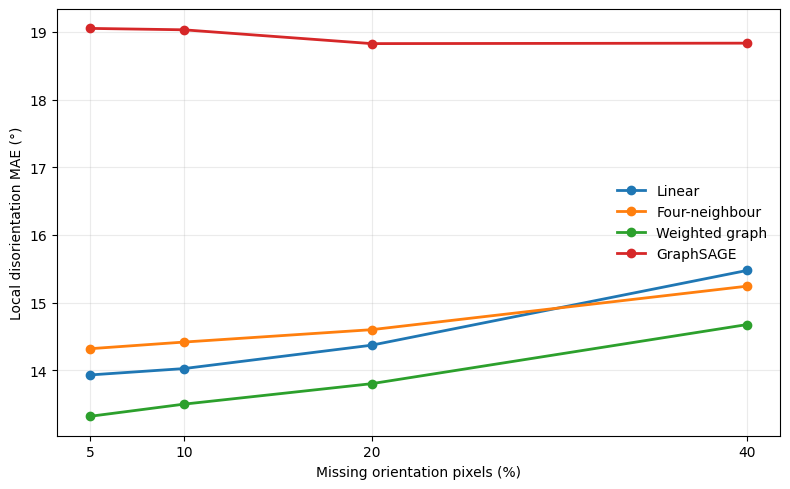

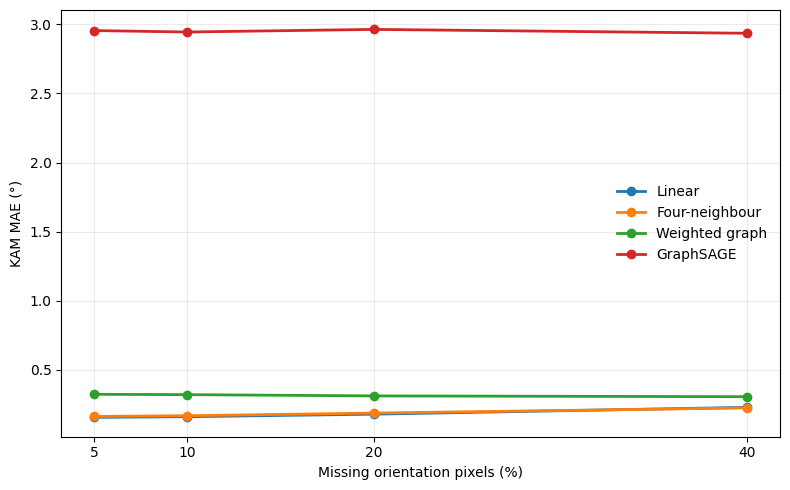


=== DATASET-LEVEL ROBUSTNESS ===

local_disorientation_mae_deg
method       linear  graph_4_neighbour_mean  observable_weighted_graph  GraphSAGE_sincos
dataset                                                                                 
EBSD_AN_XY  15.8185                 15.7139                    15.2783           20.1071
EBSD_AN_ZX  20.4403                 20.5458                    19.7377           24.3436
EBSD_DA_XY  10.8450                 11.4088                    10.1256           15.6634
EBSD_DA_ZX  10.7010                 10.9120                    10.1590           15.6233

Best method by dataset:
  EBSD_AN_XY: Weighted graph
  EBSD_AN_ZX: Weighted graph
  EBSD_DA_XY: Weighted graph
  EBSD_DA_ZX: Weighted graph

Win counts:
observable_weighted_graph    4

kam_mae_deg
method      linear  graph_4_neighbour_mean  observable_weighted_graph  GraphSAGE_sincos
dataset                                                                                
EBSD_AN_XY  0.2038          

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains/"
    "experiment_03_spatial_fidelity"
)

df = pd.read_csv(base / "experiment_3_combined_320.csv")

figdir = base / "figures"
figdir.mkdir(exist_ok=True)

methods = [
    "linear",
    "graph_4_neighbour_mean",
    "observable_weighted_graph",
    "GraphSAGE_sincos"
]

labels = {
    "linear": "Linear",
    "graph_4_neighbour_mean": "Four-neighbour",
    "observable_weighted_graph": "Weighted graph",
    "GraphSAGE_sincos": "GraphSAGE"
}

metrics = [
    (
        "local_disorientation_mae_deg",
        "Local disorientation MAE (°)",
        "experiment_3_local_disorientation.png"
    ),
    (
        "kam_mae_deg",
        "KAM MAE (°)",
        "experiment_3_kam_fidelity.png"
    )
]

# Generate publication figures
for metric, ylabel, filename in metrics:

    grouped = (
        df.groupby(["missing_pct", "method"])[metric]
        .mean()
        .unstack()
        .reindex(columns=methods)
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    for method in methods:
        ax.plot(
            grouped.index,
            grouped[method],
            marker="o",
            linewidth=2,
            label=labels[method]
        )

    ax.set_xlabel("Missing orientation pixels (%)")
    ax.set_ylabel(ylabel)
    ax.set_xticks([5, 10, 20, 40])
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)

    fig.tight_layout()

    fig.savefig(figdir / filename, dpi=300)
    fig.savefig(
        figdir / filename.replace(".png", ".pdf")
    )

    plt.show()
    plt.close(fig)

# Dataset-level robustness
print("\n=== DATASET-LEVEL ROBUSTNESS ===")

for metric, _, _ in metrics:

    print(f"\n{metric}")

    dataset_means = (
        df.groupby(["dataset", "method"])[metric]
        .mean()
        .unstack()
        .reindex(columns=methods)
    )

    print(dataset_means.round(4).to_string())

    winners = dataset_means.idxmin(axis=1)

    print("\nBest method by dataset:")

    for dataset, winner in winners.items():
        print(f"  {dataset}: {labels[winner]}")

    print("\nWin counts:")
    print(winners.value_counts().to_string())

    dataset_means.to_csv(
        base / f"dataset_robustness_{metric}.csv"
    )

# Final audit
print("\n=== FINAL OUTPUT AUDIT ===")

required = [
    "experiment_3A_spatial_artefacts_320.csv",
    "experiment_3B_KAM_320.csv",
    "experiment_3_combined_320.csv",
    "experiment_3_paired_statistics.csv"
]

all_present = True

for filename in required:
    path = base / filename
    exists = path.exists()
    all_present &= exists

    print(
        "PASS" if exists else "MISSING",
        filename
    )

print("\nFigures generated:", len(list(figdir.glob("*"))))

if all_present:
    print("\nEXPERIMENT 3 FINAL FIGURES COMPLETE")
else:
    print("\nWARNING: Some outputs are missing")


In [ ]:

import inspect

print("=== EXPERIMENT 4: AVAILABLE RECONSTRUCTION FUNCTIONS ===")

keywords = [
    "reconstruct", "interpolat", "graphsage",
    "weighted_graph", "missing_mask"
]

found = []

for name, obj in list(globals().items()):
    if not inspect.isfunction(obj):
        continue

    if any(word in name.lower() for word in keywords):
        found.append(name)
        print(f"\n{name}")
        print("Signature:", inspect.signature(obj))

if not found:
    print("No reconstruction functions found in current runtime.")

print("\nFUNCTION CHECK COMPLETE")


=== EXPERIMENT 4: AVAILABLE RECONSTRUCTION FUNCTIONS ===
No reconstruction functions found in current runtime.

FUNCTION CHECK COMPLETE


In [ ]:

import json
from pathlib import Path

root = Path("/content/drive_fresh/MyDrive")

keywords = [
    "def weighted_graph_reconstruct",
    "def graph_reconstruct",
    "def reconstruct",
    "class GraphSAGE",
    "class SAGE",
    "SAGEConv",
    "LinearNDInterpolator",
    "griddata(",
    "def create_missing_mask"
]

print("=== EXPERIMENT 4: ORIGINAL CODE SEARCH ===")

notebooks = list(root.rglob("*.ipynb"))
print("Notebooks found:", len(notebooks))

matches = []

for notebook in notebooks:
    try:
        with open(notebook, encoding="utf-8") as f:
            data = json.load(f)

        for index, cell in enumerate(data.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            hits = [
                keyword for keyword in keywords
                if keyword.lower() in source.lower()
            ]

            if hits:
                matches.append({
                    "notebook": str(notebook),
                    "cell": index,
                    "keywords": hits
                })

    except Exception as exc:
        print("Skipped:", notebook.name, str(exc)[:100])

for item in matches:
    print("\nNotebook:", item["notebook"])
    print("Cell:", item["cell"])
    print("Matches:", ", ".join(item["keywords"]))

print("\nMatching cells:", len(matches))
print("CODE SEARCH COMPLETE")


=== EXPERIMENT 4: ORIGINAL CODE SEARCH ===
Notebooks found: 11

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 3
Matches: def reconstruct, griddata(, def create_missing_mask

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 9
Matches: def reconstruct, griddata(, def create_missing_mask

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 10
Matches: def reconstruct, griddata(, def create_missing_mask

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 11
Matches: def create_missing_mask

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 14
Matches: def weighted_graph_reconstruct, def create_missing_mask

Notebook: /content/drive_fresh/MyDrive/Colab Notebooks/EBSD_Paper2_Experiment_Working_Copy.ipynb
Cell: 16
Matches: def cre

In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive_fresh/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

print("=== EXPERIMENT 4: RECOVERED RECONSTRUCTION CODE ===")

for index in [9, 10, 11, 14, 16]:
    cell = notebook["cells"][index]

    source = "".join(cell.get("source", []))

    print("\n" + "=" * 65)
    print(f"CELL {index}")
    print("=" * 65)

    print(source[:12000])

    if len(source) > 12000:
        print(
            f"\n[Output truncated: "
            f"{len(source)} characters in cell]"
        )

print("\nRECONSTRUCTION CODE INSPECTION COMPLETE")


=== EXPERIMENT 4: RECOVERED RECONSTRUCTION CODE ===

CELL 9
# ============================================================
# Experiment 1: Missing-pixel EBSD reconstruction baseline
# Safe version: handles original NaNs/unindexed gaps
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import griddata
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_DIR = "/content/drive/MyDrive/EBSD Paper2"
RESULTS_DIR = f"{PROJECT_DIR}/results/experiment_01_missing_pixels"
FIG_DIR = f"{RESULTS_DIR}/figures"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

df_valid = df[df["Phase"] > 0].copy()

x_unique = np.sort(df["X"].unique())
y_unique = np.sort(df["Y"].unique())

x_crop = x_unique[:512]
y_crop = y_unique[:512]

df_crop = df[
    df["X"].isin(x_crop) &
    df["Y"].isin(y_crop)
].copy()

def dataframe_to_grid(df_in, value_col):

In [ ]:

import ast
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive_fresh/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

print("=== EXPERIMENT 4: RECONSTRUCTION FUNCTION SUMMARY ===")

for index in [9, 10, 11, 14, 16]:
    source = "".join(notebook["cells"][index].get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError as exc:
        print(f"\nCell {index}: parsing issue: {exc}")
        continue

    functions = [
        node for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ]

    print(f"\nCELL {index}")

    if not functions:
        print("  No top-level function definitions")

    for node in functions:
        args = [arg.arg for arg in node.args.args]

        print(f"  Function: {node.name}")
        print(f"  Parameters: {args}")
        print(f"  Lines: {node.lineno}–{node.end_lineno}")

print("\nFUNCTION SUMMARY COMPLETE")


=== EXPERIMENT 4: RECONSTRUCTION FUNCTION SUMMARY ===

CELL 9
  Function: dataframe_to_grid
  Parameters: ['df_in', 'value_col']
  Lines: 34–37
  Function: create_missing_mask
  Parameters: ['valid_mask', 'missing_fraction', 'seed']
  Lines: 49–60
  Function: reconstruct_grid
  Parameters: ['original_grid', 'valid_mask', 'missing_mask', 'method']
  Lines: 62–94
  Function: compute_metrics
  Parameters: ['original', 'reconstructed', 'missing_mask']
  Lines: 96–105

CELL 10
  Function: load_ctf
  Parameters: ['path']
  Lines: 41–66
  Function: dataframe_to_grid
  Parameters: ['df_in', 'value_col', 'x_crop', 'y_crop']
  Lines: 72–75
  Function: create_missing_mask
  Parameters: ['valid_mask', 'missing_fraction', 'seed']
  Lines: 77–88
  Function: reconstruct_grid
  Parameters: ['original_grid', 'valid_mask', 'missing_mask', 'method']
  Lines: 90–122
  Function: compute_metrics
  Parameters: ['original', 'reconstructed', 'missing_mask']
  Lines: 124–133

CELL 11
  Function: load_ctf
  Para

=== EXPERIMENT 4A: STRUCTURED MISSINGNESS ===

Generated masks: 80
Datasets: 4
Missingness levels: [np.int64(5), np.int64(10), np.int64(20), np.int64(40)]
Seeds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

=== CLUSTER STRUCTURE ===
             n_missing_components  largest_component_pixels
missing_pct                                                
5                            19.1                     780.4
10                           28.4                    1398.2
20                           32.8                    2651.2
40                           31.0                    7332.6


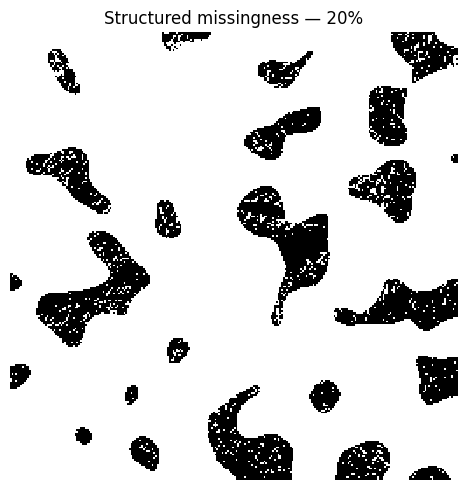


Saved inventory: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/experiment_04_structured_missingness/experiment_4A_mask_inventory.csv
Saved example figure: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/experiment_04_structured_missingness/experiment_4A_example_mask.png

EXPERIMENT 4A COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, label
from pathlib import Path

root = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

prediction_root = root / "predictions" / "linear"
output = root / "experiment_04_structured_missingness"
mask_dir = output / "masks"
mask_dir.mkdir(parents=True, exist_ok=True)

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

missing_levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

def clustered_mask(valid, percentage, seed, sigma=8.0):
    rng = np.random.default_rng(seed)

    noise = rng.normal(size=valid.shape)
    field = gaussian_filter(
        noise, sigma=sigma, mode="reflect"
    )

    indices = np.flatnonzero(valid)
    n_missing = round(len(indices) * percentage / 100)

    scores = field.ravel()[indices]

    # Select exactly the requested number of valid pixels.
    selected = indices[np.argpartition(
        scores, -n_missing
    )[-n_missing:]]

    mask = np.zeros(valid.shape, dtype=bool)
    mask.ravel()[selected] = True

    return mask

rows = []

print("=== EXPERIMENT 4A: STRUCTURED MISSINGNESS ===")

for dataset in datasets:

    source = (
        prediction_root /
        f"{dataset}_missing10_seed1.npz"
    )

    with np.load(source, allow_pickle=False) as data:
        valid = data["valid_mask"]

    for percentage in missing_levels:
        for seed in seeds:

            mask = clustered_mask(
                valid, percentage, seed, sigma=8.0
            )

            name = (
                f"{dataset}_clustered"
                f"_missing{percentage}_seed{seed}.npz"
            )

            np.savez_compressed(
                mask_dir / name,
                missing_mask=mask,
                valid_mask=valid
            )

            # Four-connected missing regions
            structure = np.array([
                [0, 1, 0],
                [1, 1, 1],
                [0, 1, 0]
            ])

            components, n_components = label(
                mask, structure=structure
            )

            sizes = np.bincount(
                components[mask],
                minlength=n_components + 1
            )[1:]

            rows.append({
                "dataset": dataset,
                "missing_pct": percentage,
                "seed": seed,
                "n_valid": int(valid.sum()),
                "n_missing": int(mask.sum()),
                "actual_missing_pct":
                    100 * mask.sum() / valid.sum(),
                "n_missing_components": n_components,
                "largest_component_pixels":
                    int(sizes.max()) if len(sizes) else 0
            })

results4a = pd.DataFrame(rows)

csv_path = output / "experiment_4A_mask_inventory.csv"
results4a.to_csv(csv_path, index=False)

print("\nGenerated masks:", len(results4a))
print("Datasets:", results4a.dataset.nunique())
print("Missingness levels:", sorted(
    results4a.missing_pct.unique()
))
print("Seeds:", sorted(results4a.seed.unique()))

print("\n=== CLUSTER STRUCTURE ===")
print(
    results4a.groupby("missing_pct")[
        ["n_missing_components", "largest_component_pixels"]
    ].mean().round(1).to_string()
)

# Example structured mask
example = np.load(
    mask_dir /
    "EBSD_AN_XY_clustered_missing20_seed1.npz"
)["missing_mask"]

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(example, cmap="gray_r", interpolation="nearest")
ax.set_title("Structured missingness — 20%")
ax.axis("off")
fig.tight_layout()

figure_path = output / "experiment_4A_example_mask.png"
fig.savefig(figure_path, dpi=300)
plt.show()
plt.close(fig)

print("\nSaved inventory:", csv_path)
print("Saved example figure:", figure_path)
print("\nEXPERIMENT 4A COMPLETE")


In [ ]:

import ast
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive_fresh/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

wanted = {
    "weighted_graph_reconstruct",
    "observable_weighted_graph_reconstruct",
    "create_missing_mask",
    "dataframe_to_grid"
}

loaded = set()

for cell in notebook["cells"]:
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name in wanted:
            module = ast.Module(body=[node], type_ignores=[])
            ast.fix_missing_locations(module)

            exec(
                compile(module, str(notebook_path), "exec"),
                globals()
            )

            loaded.add(node.name)

print("=== EXPERIMENT 4B: FUNCTIONS LOADED ===")

for name in sorted(loaded):
    print("LOADED:", name)

print("\nOriginal function definitions loaded:", len(loaded))
print("EXPERIMENT 4B SETUP COMPLETE")


=== EXPERIMENT 4B: FUNCTIONS LOADED ===
LOADED: create_missing_mask
LOADED: dataframe_to_grid
LOADED: observable_weighted_graph_reconstruct
LOADED: weighted_graph_reconstruct

Original function definitions loaded: 4
EXPERIMENT 4B SETUP COMPLETE


In [ ]:

import numpy as np
import inspect
from pathlib import Path

root = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

dataset = "EBSD_AN_XY"
missing_pct = 20
seed = 1

prediction_file = (
    root / "predictions" / "linear" /
    f"{dataset}_missing10_seed1.npz"
)

mask_file = (
    root / "experiment_04_structured_missingness" /
    "masks" /
    f"{dataset}_clustered_missing{missing_pct}_seed{seed}.npz"
)

with np.load(prediction_file, allow_pickle=False) as data:
    true_euler = data["true_euler"].astype(np.float64)
    phase = data["phase"]
    valid = data["valid_mask"]

with np.load(mask_file, allow_pickle=False) as data:
    missing = data["missing_mask"]

assert true_euler.shape[0] == 3
assert missing.shape == valid.shape
assert not np.any(missing & ~valid)

print("=== EXPERIMENT 4B: PILOT RECONSTRUCTION ===")
print("Dataset:", dataset)
print("Missingness:", missing_pct, "%")
print("Valid pixels:", int(valid.sum()))
print("Missing pixels:", int(missing.sum()))

# Identify the exact original function signature.
signature = inspect.signature(
    observable_weighted_graph_reconstruct
)

print("\nOriginal reconstruction parameters:")
print(signature)

# The original method requires band contrast (BC)
# and mean angular deviation (MAD) arrays.
# These are not included in the prediction NPZ.
# Do not substitute fabricated values.

required = [
    "target_grid",
    "valid_mask",
    "missing_mask",
    "phase_grid",
    "bc_grid",
    "mad_grid"
]

print("\nRequired original inputs:")
for name in required:
    print(" ", name)

print("\nAvailable:")
print("  Euler orientation grids: YES")
print("  Phase grid: YES")
print("  Valid mask: YES")
print("  Clustered missing mask: YES")
print("  BC grid: NOT YET LOADED")
print("  MAD grid: NOT YET LOADED")

print("\nPILOT INPUT PREPARATION COMPLETE")


=== EXPERIMENT 4B: PILOT RECONSTRUCTION ===
Dataset: EBSD_AN_XY
Missingness: 20 %
Valid pixels: 58152
Missing pixels: 11630

Original reconstruction parameters:
(target_grid, valid_mask, missing_mask, phase_grid, bc_grid, mad_grid, sigma_bc=25.0, sigma_mad=1.0, phase_bonus=2.0, max_iters=20)

Required original inputs:
  target_grid
  valid_mask
  missing_mask
  phase_grid
  bc_grid
  mad_grid

Available:
  Euler orientation grids: YES
  Phase grid: YES
  Valid mask: YES
  Clustered missing mask: YES
  BC grid: NOT YET LOADED
  MAD grid: NOT YET LOADED

PILOT INPUT PREPARATION COMPLETE


In [ ]:

from pathlib import Path

root = Path("/content/drive_fresh/MyDrive")

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

print("=== EXPERIMENT 4B: ORIGINAL EBSD INPUTS ===")

ctf_files = list(root.rglob("*.ctf"))

print("CTF files found:", len(ctf_files))

for dataset in datasets:
    matches = [
        p for p in ctf_files
        if dataset.lower() in p.stem.lower()
        or dataset.replace("EBSD_", "").lower() in p.stem.lower()
    ]

    print(f"\n{dataset}")

    if matches:
        for path in matches[:5]:
            print("  FOUND:", path)
    else:
        print("  No direct filename match")

print("\n=== CTF COLUMN CHECK ===")

for path in ctf_files[:10]:
    try:
        with open(path, encoding="utf-8", errors="replace") as f:
            header = []
            for _ in range(50):
                line = f.readline()
                if not line:
                    break
                if "Euler1" in line and "Phase" in line:
                    header = line.strip().split()
                    break

        if header:
            print("\n", path.name)
            print("Columns:", header)
            print("BC available:", "BC" in header)
            print("MAD available:", "MAD" in header)

    except Exception as exc:
        print("Skipped:", path.name, str(exc)[:80])

print("\nORIGINAL EBSD INPUT CHECK COMPLETE")


=== EXPERIMENT 4B: ORIGINAL EBSD INPUTS ===
CTF files found: 12

EBSD_AN_XY
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2/EBSD_AN_XY.ctf
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/datasets/EBSD_AN_XY.ctf

EBSD_AN_ZX
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2/EBSD_AN_ZX.ctf
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/datasets/EBSD_AN_ZX.ctf

EBSD_DA_XY
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2/EBSD_DA_XY.ctf
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/datasets/EBSD_DA_XY.ctf

EBSD_DA_ZX
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2/EBSD_DA_ZX.ctf
  FOUND: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/datasets/EBSD_DA_ZX.ctf

=== CTF COLUMN CHECK ===

 Figure_10_EBSD.ctf
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
BC available: True
MAD available: True

 Figure_6b_EBSD.ctf
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
BC available: Tru

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter

root = Path("/content/drive_fresh/MyDrive")
base = root / "EBSD Paper2 (1)/results/experiment_02_small_grains"
dataset = "EBSD_AN_XY"
pct, seed = 20, 1

ctf_matches = list(root.rglob(f"{dataset}.ctf"))
assert len(ctf_matches) >= 1, "Original CTF file not found"
ctf_path = ctf_matches[0]

pred_path = (
    base / "predictions" / "linear" /
    f"{dataset}_missing10_seed1.npz"
)
mask_path = (
    base / "experiment_04_structured_missingness/masks" /
    f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
)

with np.load(pred_path) as d:
    truth = d["true_euler"].astype(np.float64)
    phase = d["phase"]
    valid = d["valid_mask"]

with np.load(mask_path) as d:
    missing = d["missing_mask"]

# Locate CTF tabular header.
with open(ctf_path, encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

header_line = next(
    i for i, line in enumerate(lines)
    if "Euler1" in line and "Phase" in line and "MAD" in line
)

ctf = pd.read_csv(
    ctf_path,
    sep=r"\s+",
    skiprows=header_line,
    engine="python"
)

# Reconstruct grid from physical scan coordinates.
x_values = np.sort(ctf["X"].unique())
y_values = np.sort(ctf["Y"].unique())

assert len(x_values) >= 256 and len(y_values) >= 256

# Use the first 256 × 256 scan positions.
# This must match the existing cropped prediction grid.
ctf = ctf[
    ctf["X"].isin(x_values[:256]) &
    ctf["Y"].isin(y_values[:256])
].copy()

assert len(ctf) == 256 * 256, (
    f"Unexpected crop size: {len(ctf)}"
)

ctf = ctf.sort_values(["Y", "X"])

bc = ctf["BC"].to_numpy().reshape(256, 256)
mad = ctf["MAD"].to_numpy().reshape(256, 256)
ctf_phase = ctf["Phase"].to_numpy().reshape(256, 256)

# Critical alignment check.
phase_agreement = np.mean(ctf_phase[valid] == phase[valid])
print("Phase alignment:", round(phase_agreement, 6))
assert phase_agreement > 0.999, "CTF crop misaligned"

print("\n=== EXPERIMENT 4B: PILOT ===")
print("Dataset:", dataset)
print("Missing pixels:", int(missing.sum()))

# Original function expects one scalar orientation channel.
# Reconstruct each Bunge Euler channel independently.
predicted = np.array(truth, copy=True)

start = perf_counter()

for channel in range(3):
    print(f"Reconstructing Euler channel {channel + 1}/3", flush=True)

    reconstructed = observable_weighted_graph_reconstruct(
        target_grid=truth[channel],
        valid_mask=valid,
        missing_mask=missing,
        phase_grid=phase,
        bc_grid=bc,
        mad_grid=mad,
        sigma_bc=25.0,
        sigma_mad=1.0,
        phase_bonus=2.0,
        max_iters=20
    )

    predicted[channel, missing] = reconstructed[missing]

assert np.all(np.isfinite(predicted[:, missing]))

output = (
    base / "experiment_04_structured_missingness" /
    "predictions" / "observable_weighted_graph"
)
output.mkdir(parents=True, exist_ok=True)

saved_path = output / f"{dataset}_clustered_missing{pct}_seed{seed}.npz"

np.savez_compressed(
    saved_path,
    predicted_euler=predicted,
    true_euler=truth,
    phase=phase,
    valid_mask=valid,
    missing_mask=missing
)

print("\nPilot reconstruction saved:", saved_path)
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("EXPERIMENT 4B PILOT COMPLETE")


Phase alignment: 1.0

=== EXPERIMENT 4B: PILOT ===
Dataset: EBSD_AN_XY
Missing pixels: 11630
Reconstructing Euler channel 1/3
    Iteration 1: filled 1520 pixels
    Iteration 2: filled 1427 pixels
    Iteration 3: filled 1316 pixels
    Iteration 4: filled 1190 pixels
    Iteration 5: filled 1104 pixels
    Iteration 6: filled 988 pixels
    Iteration 7: filled 858 pixels
    Iteration 8: filled 734 pixels
    Iteration 9: filled 654 pixels
    Iteration 10: filled 536 pixels
    Iteration 11: filled 436 pixels
    Iteration 12: filled 329 pixels
    Iteration 13: filled 215 pixels
    Iteration 14: filled 141 pixels
    Iteration 15: filled 95 pixels
    Iteration 16: filled 41 pixels
    Iteration 17: filled 20 pixels
    Iteration 18: filled 9 pixels
    Iteration 19: filled 6 pixels
    Iteration 20: filled 0 pixels
Reconstructing Euler channel 2/3
    Iteration 1: filled 1520 pixels
    Iteration 2: filled 1427 pixels
    Iteration 3: filled 1316 pixels
    Iteration 4: filled 11

In [ ]:

import numpy as np

print("=== EXPERIMENT 4B: PILOT VALIDATION ===")

# Compare CTF Euler angles with the reference orientation
# grid using the same coordinate crop as the pilot.
ctf_euler = np.stack([
    ctf["Euler1"].to_numpy().reshape(256, 256),
    ctf["Euler2"].to_numpy().reshape(256, 256),
    ctf["Euler3"].to_numpy().reshape(256, 256)
])

# Circular Euler differences account for 360-degree wrapping.
diff = (
    (ctf_euler - truth + 180.0) % 360.0
) - 180.0

channel_mae = np.mean(
    np.abs(diff[:, valid]), axis=1
)

print("\nCTF-to-reference Euler alignment:")
for i, mae in enumerate(channel_mae, 1):
    print(f"  Euler {i} MAE: {mae:.6f} degrees")

print("\nPhase alignment:", round(phase_agreement, 6))

# Reload the saved pilot prediction.
with np.load(saved_path, allow_pickle=False) as d:
    pilot_pred = d["predicted_euler"]
    pilot_true = d["true_euler"]
    pilot_missing = d["missing_mask"]

assert np.array_equal(pilot_missing, missing)
assert np.all(np.isfinite(pilot_pred[:, missing]))

pilot_diff = (
    (pilot_pred - pilot_true + 180.0) % 360.0
) - 180.0

print("\nPilot reconstruction:")
print("  Missing pixels:", int(missing.sum()))
print(
    "  Circular Euler MAE:",
    round(float(np.mean(np.abs(pilot_diff[:, missing]))), 4),
    "degrees"
)

aligned = bool(
    np.all(channel_mae < 0.01)
    and phase_agreement > 0.999
)

print("\nCTF alignment:", "PASS" if aligned else "REQUIRES CORRECTION")

if not aligned:
    print(
        "Do not use the pilot as a publication result "
        "until coordinate alignment is corrected."
    )

print("\nPILOT VALIDATION COMPLETE")


=== EXPERIMENT 4B: PILOT VALIDATION ===

CTF-to-reference Euler alignment:
  Euler 1 MAE: 0.000000 degrees
  Euler 2 MAE: 0.000000 degrees
  Euler 3 MAE: 0.000000 degrees

Phase alignment: 1.0

Pilot reconstruction:
  Missing pixels: 11630
  Circular Euler MAE: 31.0749 degrees

CTF alignment: PASS

PILOT VALIDATION COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter
from contextlib import redirect_stdout
import io

# ============================================================
# EXPERIMENT 4B — FULL STRUCTURED MISSINGNESS RECONSTRUCTION
# ============================================================

root = Path("/content/drive_fresh/MyDrive")

project = root / "EBSD Paper2 (1)"

base = (
    project / "results" /
    "experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"

ctf_dir = project / "datasets"
mask_dir = exp4 / "masks"

out_dir = (
    exp4 / "predictions" /
    "observable_weighted_graph"
)

out_dir.mkdir(parents=True, exist_ok=True)

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

assert callable(
    observable_weighted_graph_reconstruct
), "Original reconstruction function is not loaded."

rows = []
start = perf_counter()

print(
    "=== EXPERIMENT 4B: FULL RECONSTRUCTION ===",
    flush=True
)

# ============================================================
# PROCESS EACH EBSD DATASET
# ============================================================

for dataset in datasets:

    source = (
        base / "predictions" / "linear" /
        f"{dataset}_missing10_seed1.npz"
    )

    with np.load(source, allow_pickle=False) as d:
        truth = d["true_euler"].astype(np.float64)
        phase = d["phase"]
        valid = d["valid_mask"]

    # FIX: Use the active project's CTF file directly.
    # This avoids ambiguity from duplicate Drive folders.
    ctf_path = ctf_dir / f"{dataset}.ctf"

    assert ctf_path.is_file(), (
        f"CTF file not found: {ctf_path}"
    )

    print(
        f"\nLoading dataset: {dataset}",
        flush=True
    )

    # --------------------------------------------------------
    # READ ORIGINAL CTF DATA
    # --------------------------------------------------------

    with open(
        ctf_path,
        encoding="utf-8",
        errors="replace"
    ) as f:
        lines = f.readlines()

    header_line = next(
        i for i, line in enumerate(lines)
        if (
            "Euler1" in line
            and "Phase" in line
            and "MAD" in line
        )
    )

    ctf = pd.read_csv(
        ctf_path,
        sep=r"\s+",
        skiprows=header_line,
        engine="python"
    )

    # --------------------------------------------------------
    # ALIGN CTF WITH THE ORIGINAL 256 x 256 EBSD GRID
    # --------------------------------------------------------

    h, w = valid.shape

    assert (h, w) == (256, 256)

    xs = np.sort(ctf["X"].unique())[:w]
    ys = np.sort(ctf["Y"].unique())[:h]

    crop = (
        ctf[
            ctf["X"].isin(xs) &
            ctf["Y"].isin(ys)
        ]
        .sort_values(["Y", "X"])
    )

    assert len(crop) == h * w, (
        f"Unexpected crop size for {dataset}: "
        f"{len(crop)}"
    )

    ctf_euler = np.stack([
        crop[f"Euler{i}"]
        .to_numpy()
        .reshape(h, w)
        for i in [1, 2, 3]
    ])

    alignment_error = (
        (ctf_euler - truth + 180.0) % 360.0
    ) - 180.0

    max_alignment_error = float(
        np.max(
            np.abs(alignment_error[:, valid])
        )
    )

    ctf_phase = (
        crop["Phase"]
        .to_numpy()
        .reshape(h, w)
    )

    assert np.array_equal(
        ctf_phase[valid],
        phase[valid]
    ), f"Phase alignment failed: {dataset}"

    assert max_alignment_error < 0.01, (
        f"Euler alignment failed for {dataset}: "
        f"{max_alignment_error:.6f} degrees"
    )

    bc = (
        crop["BC"]
        .to_numpy(dtype=np.float64)
        .reshape(h, w)
    )

    mad = (
        crop["MAD"]
        .to_numpy(dtype=np.float64)
        .reshape(h, w)
    )

    assert np.all(np.isfinite(bc[valid]))
    assert np.all(np.isfinite(mad[valid]))

    print(
        f"  CTF alignment: PASS "
        f"(max Euler error {max_alignment_error:.6f}°)",
        flush=True
    )

    # --------------------------------------------------------
    # RECONSTRUCT ALL 20 MASKS PER DATASET
    # --------------------------------------------------------

    completed = 0

    for pct in levels:

        for seed in seeds:

            filename = (
                f"{dataset}_clustered_"
                f"missing{pct}_seed{seed}.npz"
            )

            mask_path = mask_dir / filename
            pred_path = out_dir / filename

            assert mask_path.is_file(), (
                f"Missing structured mask: {mask_path}"
            )

            with np.load(
                mask_path,
                allow_pickle=False
            ) as d:
                missing = d["missing_mask"]

                if "valid_mask" in d.files:
                    assert np.array_equal(
                        d["valid_mask"],
                        valid
                    )

            assert missing.shape == valid.shape
            assert not np.any(missing & ~valid)

            expected_n = round(
                int(valid.sum()) * pct / 100
            )

            assert missing.sum() == expected_n

            # ------------------------------------------------
            # REUSE VALID EXISTING PREDICTIONS
            # ------------------------------------------------

            reuse = False

            if pred_path.exists():

                try:
                    with np.load(
                        pred_path,
                        allow_pickle=False
                    ) as d:

                        saved_pred = d["predicted_euler"]

                        reuse = (
                            saved_pred.shape == truth.shape
                            and np.array_equal(
                                d["missing_mask"],
                                missing
                            )
                            and np.array_equal(
                                d["true_euler"],
                                truth
                            )
                            and np.array_equal(
                                d["phase"],
                                phase
                            )
                            and np.array_equal(
                                d["valid_mask"],
                                valid
                            )
                            and np.all(
                                np.isfinite(
                                    saved_pred[:, missing]
                                )
                            )
                        )

                except Exception:
                    reuse = False

            # ------------------------------------------------
            # RUN ORIGINAL RECONSTRUCTION ALGORITHM
            # ------------------------------------------------

            if reuse:

                with np.load(
                    pred_path,
                    allow_pickle=False
                ) as d:
                    predicted = (
                        d["predicted_euler"].copy()
                    )

            else:

                predicted = truth.copy()

                for channel in range(3):

                    # Suppress iteration logs.
                    with redirect_stdout(
                        io.StringIO()
                    ):

                        reconstructed = (
                            observable_weighted_graph_reconstruct(
                                target_grid=truth[channel],
                                valid_mask=valid,
                                missing_mask=missing,
                                phase_grid=phase,
                                bc_grid=bc,
                                mad_grid=mad,
                                sigma_bc=25.0,
                                sigma_mad=1.0,
                                phase_bonus=2.0,
                                max_iters=20
                            )
                        )

                    predicted[channel, missing] = (
                        reconstructed[missing]
                    )

                assert np.all(
                    np.isfinite(
                        predicted[:, missing]
                    )
                ), (
                    f"Non-finite predictions: "
                    f"{dataset}, {pct}%, seed {seed}"
                )

                np.savez_compressed(
                    pred_path,
                    predicted_euler=predicted,
                    true_euler=truth,
                    phase=phase,
                    valid_mask=valid,
                    missing_mask=missing
                )

            # ------------------------------------------------
            # CALCULATE CIRCULAR EULER ERROR
            # ------------------------------------------------

            circular_error = (
                (predicted - truth + 180.0) % 360.0
            ) - 180.0

            mae = float(
                np.mean(
                    np.abs(
                        circular_error[:, missing]
                    )
                )
            )

            rows.append({
                "dataset": dataset,
                "missing_pct": pct,
                "seed": seed,
                "method": "observable_weighted_graph",
                "n_missing": int(missing.sum()),
                "circular_euler_mae_deg": mae
            })

            completed += 1

        print(
            f"  Missingness {pct}%: "
            f"5/5 seeds complete",
            flush=True
        )

    print(
        f"  {dataset}: {completed}/20 masks complete",
        flush=True
    )

# ============================================================
# SAVE AND SUMMARISE RESULTS
# ============================================================

results4b = pd.DataFrame(rows)

assert len(results4b) == 80
assert results4b["circular_euler_mae_deg"].notna().all()

csv_path = (
    exp4 / "experiment_4B_weighted_graph_80.csv"
)

results4b.to_csv(
    csv_path,
    index=False
)

summary = (
    results4b.groupby("missing_pct")[
        "circular_euler_mae_deg"
    ]
    .agg(["mean", "std", "min", "max"])
)

print("\n=== CLUSTERED MISSINGNESS RESULTS ===")

print(
    summary.round(3).to_string()
)

print("\n=== FINAL AUDIT ===")

print("Datasets:", results4b.dataset.nunique())
print("Missingness levels:", sorted(
    results4b.missing_pct.unique()
))
print("Seeds:", sorted(results4b.seed.unique()))
print("Total reconstructions:", len(results4b))

saved_files = list(out_dir.glob("*.npz"))

print("Prediction files:", len(saved_files))
print("Results CSV:", csv_path)

print(
    "Elapsed seconds:",
    round(perf_counter() - start, 1)
)

print("\nEXPERIMENT 4B COMPLETE")


=== EXPERIMENT 4B: FULL RECONSTRUCTION ===

Loading dataset: EBSD_AN_XY
  CTF alignment: PASS (max Euler error 0.000000°)
  Missingness 5%: 5/5 seeds complete
  Missingness 10%: 5/5 seeds complete
  Missingness 20%: 5/5 seeds complete
  Missingness 40%: 5/5 seeds complete
  EBSD_AN_XY: 20/20 masks complete

Loading dataset: EBSD_AN_ZX
  CTF alignment: PASS (max Euler error 0.000000°)
  Missingness 5%: 5/5 seeds complete
  Missingness 10%: 5/5 seeds complete
  Missingness 20%: 5/5 seeds complete
  Missingness 40%: 5/5 seeds complete
  EBSD_AN_ZX: 20/20 masks complete

Loading dataset: EBSD_DA_XY
  CTF alignment: PASS (max Euler error 0.000000°)
  Missingness 5%: 5/5 seeds complete
  Missingness 10%: 5/5 seeds complete
  Missingness 20%: 5/5 seeds complete
  Missingness 40%: 5/5 seeds complete
  EBSD_DA_XY: 20/20 masks complete

Loading dataset: EBSD_DA_ZX
  CTF alignment: PASS (max Euler error 0.000000°)
  Missingness 5%: 5/5 seeds complete
  Missingness 10%: 5/5 seeds complete
  Missin

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"

random_dir = base / "predictions" / "observable_weighted_graph"
clustered_dir = exp4 / "predictions" / "observable_weighted_graph"

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

rows = []

print("=== EXPERIMENT 4C: RANDOM VS CLUSTERED ===")

for dataset in datasets:
    for pct in [5, 10, 20, 40]:
        for seed in [1, 2, 3, 4, 5]:

            files = {
                "random": (
                    random_dir /
                    f"{dataset}_missing{pct}_seed{seed}.npz"
                ),
                "clustered": (
                    clustered_dir /
                    f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
                )
            }

            for pattern, path in files.items():
                with np.load(path, allow_pickle=False) as d:
                    truth = d["true_euler"]
                    predicted = d["predicted_euler"]
                    phase = d["phase"]
                    valid = d["valid_mask"]
                    missing = d["missing_mask"]

                eligible = missing & valid

                true_angles = np.moveaxis(truth, 0, -1)[eligible]
                pred_angles = np.moveaxis(predicted, 0, -1)[eligible]

                errors = disorientation_pairs(
                    true_angles,
                    pred_angles,
                    phase[eligible]
                )

                assert np.all(np.isfinite(errors))

                rows.append({
                    "dataset": dataset,
                    "missing_pct": pct,
                    "seed": seed,
                    "pattern": pattern,
                    "n_pixels": int(eligible.sum()),
                    "disorientation_mae_deg": float(
                        np.mean(errors)
                    ),
                    "disorientation_median_deg": float(
                        np.median(errors)
                    ),
                    "disorientation_p95_deg": float(
                        np.percentile(errors, 95)
                    )
                })

    print(f"  {dataset}: complete", flush=True)

results = pd.DataFrame(rows)

assert len(results) == 160

results.to_csv(
    exp4 / "experiment_4C_random_vs_clustered_160.csv",
    index=False
)

print("\n=== MEAN DISORIENTATION BY MISSINGNESS ===")

table = results.pivot_table(
    index="missing_pct",
    columns="pattern",
    values="disorientation_mae_deg",
    aggfunc="mean"
)

table["clustered_minus_random"] = (
    table["clustered"] - table["random"]
)

print(table.round(3).to_string())

paired = results.pivot(
    index=["dataset", "missing_pct", "seed"],
    columns="pattern",
    values="disorientation_mae_deg"
)

differences = paired["clustered"] - paired["random"]

stat, p = wilcoxon(differences)

print("\n=== PAIRED COMPARISON ===")
print("Pairs:", len(differences))
print("Mean difference:", round(differences.mean(), 4), "degrees")
print("Median difference:", round(differences.median(), 4), "degrees")
print("Wilcoxon p-value:", f"{p:.8g}")

print("\n=== DATASET-LEVEL DIFFERENCES ===")

dataset_differences = (
    differences.groupby(level="dataset")
    .mean()
)

print(dataset_differences.round(4).to_string())

print("\nEXPERIMENT 4C COMPLETE")


=== EXPERIMENT 4C: RANDOM VS CLUSTERED ===
  EBSD_AN_XY: complete
  EBSD_AN_ZX: complete
  EBSD_DA_XY: complete
  EBSD_DA_ZX: complete

=== MEAN DISORIENTATION BY MISSINGNESS ===
pattern      clustered  random  clustered_minus_random
missing_pct                                           
5               31.781  17.608                  14.173
10              32.469  17.602                  14.867
20              34.510  17.422                  17.088
40              36.335  17.153                  19.182

=== PAIRED COMPARISON ===
Pairs: 80
Mean difference: 16.3274 degrees
Median difference: 16.2199 degrees
Wilcoxon p-value: 7.8495265e-15

=== DATASET-LEVEL DIFFERENCES ===
dataset
EBSD_AN_XY    16.4914
EBSD_AN_ZX    15.2926
EBSD_DA_XY    16.6328
EBSD_DA_ZX    16.8929

EXPERIMENT 4C COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
from pathlib import Path
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"

mask_dir = exp4 / "masks"
output_dir = exp4 / "predictions" / "linear"
output_dir.mkdir(parents=True, exist_ok=True)

datasets = [
    "EBSD_AN_XY",
    "EBSD_AN_ZX",
    "EBSD_DA_XY",
    "EBSD_DA_ZX"
]

pct = 20
seeds = [1, 2, 3, 4, 5]

rows = []
start = perf_counter()

print("=== EXPERIMENT 4D: LINEAR INTERPOLATION ===")

for dataset in datasets:

    source = (
        base / "predictions" / "linear" /
        f"{dataset}_missing10_seed1.npz"
    )

    with np.load(source, allow_pickle=False) as d:
        truth = d["true_euler"].astype(np.float64)
        phase = d["phase"]
        valid = d["valid_mask"]

    yy, xx = np.indices(valid.shape)
    coords = np.column_stack((yy.ravel(), xx.ravel()))

    for seed in seeds:

        filename = (
            f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
        )

        with np.load(mask_dir / filename, allow_pickle=False) as d:
            missing = d["missing_mask"]

        observed = valid & ~missing

        observed_coords = coords[observed.ravel()]
        missing_coords = coords[missing.ravel()]

        predicted = truth.copy()

        for channel in range(3):

            observed_values = truth[channel, observed]

            interpolated = griddata(
                observed_coords,
                observed_values,
                missing_coords,
                method="linear"
            )

            # Fill points outside the convex hull.
            unresolved = ~np.isfinite(interpolated)

            if np.any(unresolved):
                nearest = griddata(
                    observed_coords,
                    observed_values,
                    missing_coords[unresolved],
                    method="nearest"
                )
                interpolated[unresolved] = nearest

            predicted[channel, missing] = interpolated

        assert np.all(np.isfinite(predicted[:, missing]))
        assert np.array_equal(
            predicted[:, observed],
            truth[:, observed]
        )

        save_path = output_dir / filename

        np.savez_compressed(
            save_path,
            predicted_euler=predicted,
            true_euler=truth,
            phase=phase,
            valid_mask=valid,
            missing_mask=missing
        )

        circular_error = (
            (predicted - truth + 180) % 360
        ) - 180

        rows.append({
            "dataset": dataset,
            "missing_pct": pct,
            "seed": seed,
            "method": "linear",
            "circular_euler_mae_deg": float(
                np.mean(np.abs(circular_error[:, missing]))
            )
        })

    print(f"{dataset}: 5/5 complete", flush=True)

results = pd.DataFrame(rows)

results.to_csv(
    exp4 / "experiment_4D_linear_20pct_pilot.csv",
    index=False
)

print("\n=== PILOT RESULTS ===")
print(
    results.groupby("dataset")[
        "circular_euler_mae_deg"
    ].mean().round(3).to_string()
)

print("\nReconstructions:", len(results))
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("EXPERIMENT 4D LINEAR PILOT COMPLETE")


=== EXPERIMENT 4D: LINEAR INTERPOLATION ===
EBSD_AN_XY: 5/5 complete
EBSD_AN_ZX: 5/5 complete
EBSD_DA_XY: 5/5 complete
EBSD_DA_ZX: 5/5 complete

=== PILOT RESULTS ===
dataset
EBSD_AN_XY    31.577
EBSD_AN_ZX    32.449
EBSD_DA_XY    28.264
EBSD_DA_ZX    26.658

Reconstructions: 20
Elapsed seconds: 167.6
EXPERIMENT 4D LINEAR PILOT COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from pathlib import Path
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"
mask_dir = exp4 / "masks"
out_dir = exp4 / "predictions" / "linear"
out_dir.mkdir(parents=True, exist_ok=True)

datasets = ["EBSD_AN_XY", "EBSD_AN_ZX", "EBSD_DA_XY", "EBSD_DA_ZX"]
levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

rows = []
reused = 0
computed = 0
start = perf_counter()

print("=== EXPERIMENT 4D: FULL LINEAR RECONSTRUCTION ===")

for dataset in datasets:
    source = (
        base / "predictions" / "linear" /
        f"{dataset}_missing10_seed1.npz"
    )

    with np.load(source, allow_pickle=False) as d:
        truth = d["true_euler"].astype(np.float64)
        phase = d["phase"]
        valid = d["valid_mask"]

    yy, xx = np.indices(valid.shape)
    coords = np.column_stack((yy.ravel(), xx.ravel()))

    for pct in levels:
        for seed in seeds:
            filename = (
                f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
            )

            with np.load(mask_dir / filename, allow_pickle=False) as d:
                missing = d["missing_mask"]
                assert np.array_equal(d["valid_mask"], valid)

            assert not np.any(missing & ~valid)
            assert int(missing.sum()) == round(
                int(valid.sum()) * pct / 100
            )

            observed = valid & ~missing
            pred_path = out_dir / filename
            reuse = False

            if pred_path.exists():
                try:
                    with np.load(pred_path, allow_pickle=False) as d:
                        p = d["predicted_euler"]
                        reuse = (
                            p.shape == truth.shape
                            and np.array_equal(d["true_euler"], truth)
                            and np.array_equal(d["phase"], phase)
                            and np.array_equal(d["valid_mask"], valid)
                            and np.array_equal(d["missing_mask"], missing)
                            and np.array_equal(
                                p[:, observed], truth[:, observed]
                            )
                            and np.all(np.isfinite(p[:, missing]))
                        )
                        if reuse:
                            predicted = p.copy()
                except Exception:
                    reuse = False

            if reuse:
                reused += 1
            else:
                predicted = truth.copy()
                observed_coords = coords[observed.ravel()]
                missing_coords = coords[missing.ravel()]

                for channel in range(3):
                    values = truth[channel, observed]

                    interpolated = griddata(
                        observed_coords,
                        values,
                        missing_coords,
                        method="linear"
                    )

                    unresolved = ~np.isfinite(interpolated)

                    if np.any(unresolved):
                        interpolated[unresolved] = griddata(
                            observed_coords,
                            values,
                            missing_coords[unresolved],
                            method="nearest"
                        )

                    predicted[channel, missing] = interpolated

                assert np.all(np.isfinite(predicted[:, missing]))
                assert np.array_equal(
                    predicted[:, observed], truth[:, observed]
                )

                np.savez_compressed(
                    pred_path,
                    predicted_euler=predicted,
                    true_euler=truth,
                    phase=phase,
                    valid_mask=valid,
                    missing_mask=missing
                )
                computed += 1

            circular_error = (
                (predicted - truth + 180.0) % 360.0
            ) - 180.0

            rows.append({
                "dataset": dataset,
                "missing_pct": pct,
                "seed": seed,
                "method": "linear",
                "n_missing": int(missing.sum()),
                "circular_euler_mae_deg": float(
                    np.mean(np.abs(circular_error[:, missing]))
                )
            })

        print(f"{dataset}: {pct}% complete", flush=True)

results = pd.DataFrame(rows)
assert len(results) == 80

csv_path = exp4 / "experiment_4D_linear_80.csv"
results.to_csv(csv_path, index=False)

print("\n=== LINEAR INTERPOLATION RESULTS ===")
print(
    results.groupby("missing_pct")[
        "circular_euler_mae_deg"
    ].agg(["mean", "std"]).round(3).to_string()
)

print("\n=== FINAL AUDIT ===")
print("Total evaluations:", len(results))
print("Existing predictions reused:", reused)
print("New predictions computed:", computed)
print("Prediction files:", len(list(out_dir.glob("*.npz"))))
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("Saved:", csv_path)
print("\nEXPERIMENT 4D LINEAR COMPLETE")


=== EXPERIMENT 4D: FULL LINEAR RECONSTRUCTION ===
EBSD_AN_XY: 5% complete
EBSD_AN_XY: 10% complete
EBSD_AN_XY: 20% complete
EBSD_AN_XY: 40% complete
EBSD_AN_ZX: 5% complete
EBSD_AN_ZX: 10% complete
EBSD_AN_ZX: 20% complete
EBSD_AN_ZX: 40% complete
EBSD_DA_XY: 5% complete
EBSD_DA_XY: 10% complete
EBSD_DA_XY: 20% complete
EBSD_DA_XY: 40% complete
EBSD_DA_ZX: 5% complete
EBSD_DA_ZX: 10% complete
EBSD_DA_ZX: 20% complete
EBSD_DA_ZX: 40% complete

=== LINEAR INTERPOLATION RESULTS ===
               mean    std
missing_pct               
5            27.872  3.339
10           28.511  2.849
20           29.737  2.644
40           30.464  2.443

=== FINAL AUDIT ===
Total evaluations: 80
Existing predictions reused: 20
New predictions computed: 60
Prediction files: 80
Elapsed seconds: 368.2
Saved: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/experiment_04_structured_missingness/experiment_4D_linear_80.csv

EXPERIMENT 4D LINEAR COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)
exp4 = base / "experiment_04_structured_missingness"
mask_dir = exp4 / "masks"
out_dir = exp4 / "predictions" / "graph_4_neighbour_mean"
out_dir.mkdir(parents=True, exist_ok=True)

datasets = ["EBSD_AN_XY", "EBSD_AN_ZX", "EBSD_DA_XY", "EBSD_DA_ZX"]
levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

def reconstruct_four_neighbour(truth, valid, missing, max_iters=100):
    """Iterative 4-neighbour mean; observed pixels remain fixed."""
    predicted = truth.copy()
    observed = valid & ~missing

    # Initialize missing pixels from observed-channel mean.
    for channel in range(3):
        predicted[channel, missing] = np.mean(
            truth[channel, observed]
        )

    for _ in range(max_iters):
        old = predicted.copy()

        sums = np.zeros_like(predicted)
        counts = np.zeros(valid.shape, dtype=np.float64)

        # Vertical neighbours
        edge = valid[:-1, :] & valid[1:, :]
        sums[:, 1:, :] += old[:, :-1, :] * edge
        sums[:, :-1, :] += old[:, 1:, :] * edge
        counts[1:, :] += edge
        counts[:-1, :] += edge

        # Horizontal neighbours
        edge = valid[:, :-1] & valid[:, 1:]
        sums[:, :, 1:] += old[:, :, :-1] * edge
        sums[:, :, :-1] += old[:, :, 1:] * edge
        counts[:, 1:] += edge
        counts[:, :-1] += edge

        update = missing & (counts > 0)

        predicted[:, update] = (
            sums[:, update] / counts[update]
        )

        predicted[:, observed] = truth[:, observed]

        change = np.max(
            np.abs(predicted[:, missing] - old[:, missing])
        )

        if change < 1e-5:
            break

    return predicted

rows = []
start = perf_counter()

print("=== EXPERIMENT 4E: FOUR-NEIGHBOUR RECONSTRUCTION ===")

for dataset in datasets:
    source = (
        base / "predictions" / "linear" /
        f"{dataset}_missing10_seed1.npz"
    )

    with np.load(source, allow_pickle=False) as d:
        truth = d["true_euler"].astype(np.float64)
        phase = d["phase"]
        valid = d["valid_mask"]

    for pct in levels:
        for seed in seeds:
            filename = (
                f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
            )

            with np.load(mask_dir / filename, allow_pickle=False) as d:
                missing = d["missing_mask"]
                assert np.array_equal(d["valid_mask"], valid)

            observed = valid & ~missing
            pred_path = out_dir / filename

            reuse = False
            if pred_path.exists():
                try:
                    with np.load(pred_path, allow_pickle=False) as d:
                        p = d["predicted_euler"]
                        reuse = (
                            p.shape == truth.shape
                            and np.array_equal(d["true_euler"], truth)
                            and np.array_equal(d["phase"], phase)
                            and np.array_equal(d["missing_mask"], missing)
                            and np.array_equal(d["valid_mask"], valid)
                            and np.all(np.isfinite(p[:, missing]))
                            and np.array_equal(
                                p[:, observed], truth[:, observed]
                            )
                        )
                        if reuse:
                            predicted = p.copy()
                except Exception:
                    reuse = False

            if not reuse:
                predicted = reconstruct_four_neighbour(
                    truth, valid, missing, max_iters=100
                )

                assert np.all(np.isfinite(predicted[:, missing]))
                assert np.array_equal(
                    predicted[:, observed], truth[:, observed]
                )

                np.savez_compressed(
                    pred_path,
                    predicted_euler=predicted,
                    true_euler=truth,
                    phase=phase,
                    valid_mask=valid,
                    missing_mask=missing
                )

            circular_error = (
                (predicted - truth + 180) % 360
            ) - 180

            rows.append({
                "dataset": dataset,
                "missing_pct": pct,
                "seed": seed,
                "method": "graph_4_neighbour_mean",
                "n_missing": int(missing.sum()),
                "circular_euler_mae_deg": float(
                    np.mean(np.abs(circular_error[:, missing]))
                )
            })

        print(f"{dataset}: {pct}% complete", flush=True)

results4e = pd.DataFrame(rows)
assert len(results4e) == 80

csv_path = exp4 / "experiment_4E_four_neighbour_80.csv"
results4e.to_csv(csv_path, index=False)

print("\n=== FOUR-NEIGHBOUR RESULTS ===")
print(
    results4e.groupby("missing_pct")[
        "circular_euler_mae_deg"
    ].agg(["mean", "std"]).round(3).to_string()
)

print("\nReconstructions:", len(results4e))
print("Prediction files:", len(list(out_dir.glob("*.npz"))))
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("Saved:", csv_path)
print("\nEXPERIMENT 4E COMPLETE")


=== EXPERIMENT 4E: FOUR-NEIGHBOUR RECONSTRUCTION ===
EBSD_AN_XY: 5% complete
EBSD_AN_XY: 10% complete
EBSD_AN_XY: 20% complete
EBSD_AN_XY: 40% complete
EBSD_AN_ZX: 5% complete
EBSD_AN_ZX: 10% complete
EBSD_AN_ZX: 20% complete
EBSD_AN_ZX: 40% complete
EBSD_DA_XY: 5% complete
EBSD_DA_XY: 10% complete
EBSD_DA_XY: 20% complete
EBSD_DA_XY: 40% complete
EBSD_DA_ZX: 5% complete
EBSD_DA_ZX: 10% complete
EBSD_DA_ZX: 20% complete
EBSD_DA_ZX: 40% complete

=== FOUR-NEIGHBOUR RESULTS ===
               mean    std
missing_pct               
5            26.089  2.509
10           26.740  2.310
20           27.757  2.013
40           28.678  1.889

Reconstructions: 80
Prediction files: 80
Elapsed seconds: 135.0
Saved: /content/drive_fresh/MyDrive/EBSD Paper2 (1)/results/experiment_02_small_grains/experiment_04_structured_missingness/experiment_4E_four_neighbour_80.csv

EXPERIMENT 4E COMPLETE


=== EXPERIMENT 4F: FINAL SYMMETRY-AWARE COMPARISON ===
EBSD_AN_XY: complete
EBSD_AN_ZX: complete
EBSD_DA_XY: complete
EBSD_DA_ZX: complete

=== MEAN DISORIENTATION MAE ===
method       Four-neighbour  Linear interpolation  Weighted graph
missing_pct                                                      
5                    36.923                36.894          31.781
10                   37.645                37.337          32.469
20                   39.033                39.075          34.510
40                   40.177                39.572          36.335

=== OVERALL METHOD RANKING ===
                        mean    std
method                             
Weighted graph        33.774  5.202
Linear interpolation  38.219  3.773
Four-neighbour        38.445  3.282

=== PAIRED WILCOXON COMPARISONS ===
            method_a             method_b  mean_difference_deg  median_difference_deg  wilcoxon_p
      Weighted graph Linear interpolation            -4.445789              -4.624345

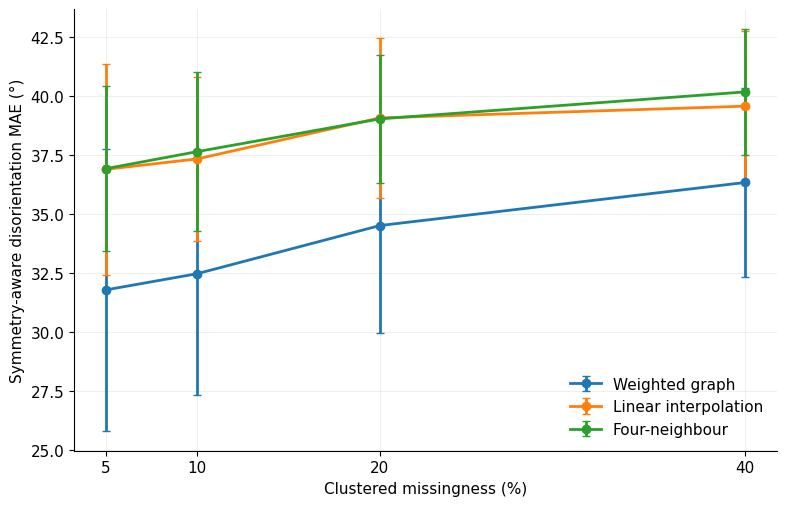


=== FINAL AUDIT ===
Evaluations: 240
Methods: 3
Datasets: 4
Missingness levels: 4
Seeds: 5
Elapsed seconds: 38.2

EXPERIMENT 4F COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import wilcoxon
from time import perf_counter

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"
fig_dir = exp4 / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

methods = {
    "Weighted graph": "observable_weighted_graph",
    "Linear interpolation": "linear",
    "Four-neighbour": "graph_4_neighbour_mean"
}

datasets = [
    "EBSD_AN_XY", "EBSD_AN_ZX",
    "EBSD_DA_XY", "EBSD_DA_ZX"
]
levels = [5, 10, 20, 40]
seeds = [1, 2, 3, 4, 5]

assert callable(disorientation_pairs), (
    "Run the Experiment 3 symmetry functions first."
)

rows = []
start = perf_counter()

print("=== EXPERIMENT 4F: FINAL SYMMETRY-AWARE COMPARISON ===")

for dataset in datasets:
    for pct in levels:
        for seed in seeds:
            filename = (
                f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
            )

            for method, folder in methods.items():
                path = exp4 / "predictions" / folder / filename

                with np.load(path, allow_pickle=False) as d:
                    truth = d["true_euler"]
                    predicted = d["predicted_euler"]
                    phase = d["phase"]
                    valid = d["valid_mask"]
                    missing = d["missing_mask"]

                eligible = valid & missing

                true_angles = np.moveaxis(
                    truth, 0, -1
                )[eligible]

                pred_angles = np.moveaxis(
                    predicted, 0, -1
                )[eligible]

                errors = disorientation_pairs(
                    true_angles,
                    pred_angles,
                    phase[eligible]
                )

                assert np.all(np.isfinite(errors))

                rows.append({
                    "dataset": dataset,
                    "missing_pct": pct,
                    "seed": seed,
                    "method": method,
                    "n_pixels": int(eligible.sum()),
                    "disorientation_mae_deg": float(
                        np.mean(errors)
                    ),
                    "disorientation_median_deg": float(
                        np.median(errors)
                    ),
                    "disorientation_p95_deg": float(
                        np.percentile(errors, 95)
                    )
                })

    print(f"{dataset}: complete", flush=True)

results = pd.DataFrame(rows)
assert len(results) == 240

results.to_csv(
    exp4 / "experiment_4F_final_240.csv",
    index=False
)

print("\n=== MEAN DISORIENTATION MAE ===")
summary = results.pivot_table(
    index="missing_pct",
    columns="method",
    values="disorientation_mae_deg",
    aggfunc="mean"
)
print(summary.round(3).to_string())

print("\n=== OVERALL METHOD RANKING ===")
ranking = results.groupby("method")[
    "disorientation_mae_deg"
].agg(["mean", "std"]).sort_values("mean")
print(ranking.round(3).to_string())

print("\n=== PAIRED WILCOXON COMPARISONS ===")
paired = results.pivot(
    index=["dataset", "missing_pct", "seed"],
    columns="method",
    values="disorientation_mae_deg"
)

comparisons = [
    ("Weighted graph", "Linear interpolation"),
    ("Weighted graph", "Four-neighbour"),
    ("Linear interpolation", "Four-neighbour")
]

stats_rows = []

for a, b in comparisons:
    diff = paired[a] - paired[b]
    statistic, p = wilcoxon(diff)

    stats_rows.append({
        "method_a": a,
        "method_b": b,
        "mean_difference_deg": float(diff.mean()),
        "median_difference_deg": float(diff.median()),
        "wilcoxon_p": float(p)
    })

stats = pd.DataFrame(stats_rows)
stats.to_csv(
    exp4 / "experiment_4F_paired_statistics.csv",
    index=False
)
print(stats.round(6).to_string(index=False))

print("\n=== DATASET-LEVEL WINNERS ===")
dataset_means = results.pivot_table(
    index="dataset",
    columns="method",
    values="disorientation_mae_deg",
    aggfunc="mean"
)
print(dataset_means.round(3).to_string())
print("\nBest by dataset:")
print(dataset_means.idxmin(axis=1).to_string())

# Publication figure
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, ax = plt.subplots(figsize=(8, 5.2))

for method in methods:
    subset = results[results["method"] == method]
    grouped = subset.groupby("missing_pct")[
        "disorientation_mae_deg"
    ].agg(["mean", "std"])

    ax.errorbar(
        grouped.index,
        grouped["mean"],
        yerr=grouped["std"],
        marker="o",
        linewidth=2,
        capsize=3,
        label=method
    )

ax.set_xlabel("Clustered missingness (%)")
ax.set_ylabel("Symmetry-aware disorientation MAE (°)")
ax.set_xticks(levels)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()

fig.savefig(
    fig_dir / "experiment_4F_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    fig_dir / "experiment_4F_method_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("\n=== FINAL AUDIT ===")
print("Evaluations:", len(results))
print("Methods:", results["method"].nunique())
print("Datasets:", results["dataset"].nunique())
print("Missingness levels:", results["missing_pct"].nunique())
print("Seeds:", results["seed"].nunique())
print("Elapsed seconds:", round(perf_counter() - start, 1))
print("\nEXPERIMENT 4F COMPLETE")


In [ ]:

import numpy as np
from scipy.spatial.transform import Rotation

# Euler angles use degrees and the ZXZ convention.
def euler_to_rotation(euler):
    return Rotation.from_euler(
        "ZXZ",
        np.asarray(euler),
        degrees=True
    ).as_matrix()

# Proper rotational symmetry operators.
# Phase 1: hexagonal (12)
# Phase 2: cubic (24)
hexagonal = []

for k in range(6):
    hexagonal.append(
        Rotation.from_euler(
            "z", 60 * k, degrees=True
        ).as_matrix()
    )

flip = Rotation.from_euler(
    "x", 180, degrees=True
).as_matrix()

for k in range(6):
    rz = Rotation.from_euler(
        "z", 60 * k, degrees=True
    ).as_matrix()
    hexagonal.append(rz @ flip)

cubic = Rotation.create_group("O").as_matrix()

SYMMETRY = {
    1: np.asarray(hexagonal),
    2: np.asarray(cubic)
}

# Recreate the original one-sided implementation
# used in Experiment 3.
def disorientation_pairs(euler_a, euler_b, phase_ids):

    result = np.full(len(phase_ids), np.nan)

    for p in np.unique(phase_ids):
        p = int(p)

        if p not in SYMMETRY:
            raise ValueError(f"Unknown phase: {p}")

        idx = np.flatnonzero(phase_ids == p)

        Ra = euler_to_rotation(euler_a[idx])
        Rb = euler_to_rotation(euler_b[idx])

        delta = Ra @ np.swapaxes(Rb, 1, 2)

        best = np.full(len(idx), 180.0)

        for S in SYMMETRY[p]:
            trace = np.einsum(
                "nij,ji->n",
                delta,
                S
            )

            cosine = np.clip(
                (trace - 1) / 2,
                -1,
                1
            )

            angles = np.degrees(
                np.arccos(cosine)
            )

            best = np.minimum(best, angles)

        result[idx] = best

    return result

print("=== SYMMETRY FUNCTIONS RESTORED ===")
print("Phase 1 operators:", len(SYMMETRY[1]))
print("Phase 2 operators:", len(SYMMETRY[2]))
print("Euler conversion: READY")
print("Disorientation function: READY")


=== SYMMETRY FUNCTIONS RESTORED ===
Phase 1 operators: 12
Phase 2 operators: 24
Euler conversion: READY
Disorientation function: READY


In [ ]:

import numpy as np

print("=== CRYSTALLOGRAPHIC SYMMETRY VALIDATION ===")

rng = np.random.default_rng(42)
n = 100

for phase_id, operators in SYMMETRY.items():

    a = np.column_stack([
        rng.uniform(0, 360, n),
        rng.uniform(0, 180, n),
        rng.uniform(0, 360, n)
    ])

    b = np.column_stack([
        rng.uniform(0, 360, n),
        rng.uniform(0, 180, n),
        rng.uniform(0, 360, n)
    ])

    phases = np.full(n, phase_id, dtype=int)

    # Existing Experiment 3/4 calculation
    existing = disorientation_pairs(a, b, phases)

    Ra = euler_to_rotation(a)
    Rb = euler_to_rotation(b)

    # Two-sided crystal symmetry calculation
    reference = np.full(n, 180.0)

    for S1 in operators:
        left = S1 @ Ra

        for S2 in operators:
            right = S2 @ Rb

            relative = left @ np.swapaxes(right, 1, 2)

            trace = np.trace(
                relative, axis1=1, axis2=2
            )

            angles = np.degrees(
                np.arccos(
                    np.clip((trace - 1) / 2, -1, 1)
                )
            )

            reference = np.minimum(reference, angles)

    difference = np.abs(existing - reference)

    print(f"\nPhase {phase_id}")
    print("Symmetry operators:", len(operators))
    print("Existing mean:", round(existing.mean(), 4))
    print("Reference mean:", round(reference.mean(), 4))
    print("Maximum difference:", round(difference.max(), 6))
    print(
        "Pairs differing > 0.01°:",
        int(np.sum(difference > 0.01)),
        "/", n
    )

print("\nSYMMETRY VALIDATION COMPLETE")


=== CRYSTALLOGRAPHIC SYMMETRY VALIDATION ===

Phase 1
Symmetry operators: 12
Existing mean: 54.3109
Reference mean: 54.3109
Maximum difference: 0.0
Pairs differing > 0.01°: 0 / 100

Phase 2
Symmetry operators: 24
Existing mean: 38.3723
Reference mean: 38.3723
Maximum difference: 0.0
Pairs differing > 0.01°: 0 / 100

SYMMETRY VALIDATION COMPLETE


In [ ]:

import numpy as np
from pathlib import Path

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)

exp4 = base / "experiment_04_structured_missingness"

dataset = "EBSD_AN_XY"
seed = 1
pct = 20

methods = {
    "Linear": (
        base / "predictions" / "linear",
        exp4 / "predictions" / "linear"
    ),
    "Four-neighbour": (
        base / "predictions" / "graph_4_neighbour_mean",
        exp4 / "predictions" / "graph_4_neighbour_mean"
    )
}

print("=== ORIGINAL BASELINE AVAILABILITY ===")

for method, (original_dir, clustered_dir) in methods.items():

    original_file = (
        original_dir /
        f"{dataset}_missing{pct}_seed{seed}.npz"
    )

    clustered_file = (
        clustered_dir /
        f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
    )

    print(f"\n{method}")
    print("Original prediction exists:", original_file.exists())
    print("Clustered prediction exists:", clustered_file.exists())

    if original_file.exists() and clustered_file.exists():

        with np.load(original_file, allow_pickle=False) as a:
            print("Original fields:", sorted(a.files))
            original_shape = a["predicted_euler"].shape

        with np.load(clustered_file, allow_pickle=False) as b:
            print("Clustered fields:", sorted(b.files))
            clustered_shape = b["predicted_euler"].shape

        print("Original shape:", original_shape)
        print("Clustered shape:", clustered_shape)

print("\nBASELINE AVAILABILITY CHECK COMPLETE")


=== ORIGINAL BASELINE AVAILABILITY ===

Linear
Original prediction exists: False
Clustered prediction exists: False

Four-neighbour
Original prediction exists: False
Clustered prediction exists: False

BASELINE AVAILABILITY CHECK COMPLETE


In [ ]:

from pathlib import Path

root = Path("/content/drive_fresh/MyDrive")
project = root / "EBSD Paper2 (1)"
base = project / "results" / "experiment_02_small_grains"
exp4 = base / "experiment_04_structured_missingness"

print("=== GOOGLE DRIVE PATH CHECK ===")

for name, path in [
    ("Google Drive", root),
    ("EBSD project", project),
    ("Experiment 2 results", base),
    ("Experiment 4", exp4),
    ("Original predictions", base / "predictions"),
    ("Clustered predictions", exp4 / "predictions")
]:
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("\n=== PREDICTION FOLDERS ===")

for parent in [base / "predictions", exp4 / "predictions"]:
    if parent.exists():
        print(f"\n{parent}")
        for folder in sorted(parent.iterdir()):
            if folder.is_dir():
                print(
                    folder.name,
                    "| NPZ files:",
                    len(list(folder.glob("*.npz")))
                )

print("\nPATH CHECK COMPLETE")


=== GOOGLE DRIVE PATH CHECK ===
Google Drive: NOT FOUND
EBSD project: NOT FOUND
Experiment 2 results: NOT FOUND
Experiment 4: NOT FOUND
Original predictions: NOT FOUND
Clustered predictions: NOT FOUND

=== PREDICTION FOLDERS ===

PATH CHECK COMPLETE


In [ ]:

from google.colab import drive
from pathlib import Path

# Reconnect Google Drive
drive.mount("/content/drive_fresh", force_remount=True)

# Verify project folders
root = Path("/content/drive_fresh/MyDrive")

project = root / "EBSD Paper2 (1)"

exp4 = (
    project
    / "results"
    / "experiment_02_small_grains"
    / "experiment_04_structured_missingness"
)

print("\n=== GOOGLE DRIVE VERIFICATION ===")
print("MyDrive:", root.exists())
print("EBSD project:", project.exists())
print("Experiment 4:", exp4.exists())

if exp4.exists():
    print("\n=== SAVED PREDICTIONS ===")

    for method in [
        "observable_weighted_graph",
        "linear",
        "graph_4_neighbour_mean"
    ]:
        folder = exp4 / "predictions" / method
        count = len(list(folder.glob("*.npz"))) if folder.exists() else 0
        print(f"{method}: {count}/80 files")

print("\nDRIVE CHECK COMPLETE")


Mounted at /content/drive_fresh

=== GOOGLE DRIVE VERIFICATION ===
MyDrive: True
EBSD project: True
Experiment 4: True

=== SAVED PREDICTIONS ===
observable_weighted_graph: 80/80 files
linear: 80/80 files
graph_4_neighbour_mean: 80/80 files

DRIVE CHECK COMPLETE


In [ ]:

from pathlib import Path
import numpy as np

base = Path(
    "/content/drive_fresh/MyDrive/"
    "EBSD Paper2 (1)/results/experiment_02_small_grains"
)
exp4 = base / "experiment_04_structured_missingness"

dataset = "EBSD_AN_XY"
pct = 20
seed = 1

methods = {
    "Linear": "linear",
    "Four-neighbour": "graph_4_neighbour_mean",
    "Weighted graph": "observable_weighted_graph"
}

print("=== BASELINE PREDICTION CHECK ===")

for name, folder in methods.items():
    original = (
        base / "predictions" / folder /
        f"{dataset}_missing{pct}_seed{seed}.npz"
    )
    clustered = (
        exp4 / "predictions" / folder /
        f"{dataset}_clustered_missing{pct}_seed{seed}.npz"
    )

    print(f"\n{name}")
    print("Original exists:", original.exists())
    print("Clustered exists:", clustered.exists())

    if original.exists() and clustered.exists():
        with np.load(original, allow_pickle=False) as a:
            original_shape = a["predicted_euler"].shape
            original_fields = sorted(a.files)

        with np.load(clustered, allow_pickle=False) as b:
            clustered_shape = b["predicted_euler"].shape
            clustered_fields = sorted(b.files)

        print("Shapes match:", original_shape == clustered_shape)
        print("Original fields:", original_fields)
        print("Clustered fields:", clustered_fields)

print("\nBASELINE PREDICTION CHECK COMPLETE")


=== BASELINE PREDICTION CHECK ===

Linear
Original exists: True
Clustered exists: True
Shapes match: True
Original fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']
Clustered fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']

Four-neighbour
Original exists: True
Clustered exists: True
Shapes match: True
Original fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']
Clustered fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']

Weighted graph
Original exists: True
Clustered exists: True
Shapes match: True
Original fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']
Clustered fields: ['missing_mask', 'phase', 'predicted_euler', 'true_euler', 'valid_mask']

BASELINE PREDICTION CHECK COMPLETE


In [ ]:

import json
import ast
from pathlib import Path

notebook = Path(
    "/content/drive_fresh/MyDrive/Colab Notebooks/"
    "EBSD_Paper2_Experiment_Working_Copy.ipynb"
)

print("=== ORIGINAL BASELINE DEFINITIONS ===")

if not notebook.exists():
    print("Original notebook not found:", notebook)
else:
    with open(notebook, "r", encoding="utf-8") as f:
        nb = json.load(f)

    keywords = [
        "linear",
        "four_neighbour",
        "4_neighbour",
        "graph_reconstruct",
        "interpolate"
    ]

    matches = {}

    for i, cell in enumerate(nb["cells"]):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                name = node.name.lower()

                if any(word in name for word in keywords):
                    matches[node.name] = {
                        "cell": i,
                        "source": ast.get_source_segment(source, node)
                    }

    for name, item in matches.items():
        print(f"\n{'=' * 60}")
        print("FUNCTION:", name)
        print("NOTEBOOK CELL:", item["cell"])
        print("=" * 60)
        print(item["source"][:6000])

    print("\nFunctions found:", len(matches))
    print("ORIGINAL BASELINE INSPECTION COMPLETE")


=== ORIGINAL BASELINE DEFINITIONS ===

FUNCTION: weighted_graph_reconstruct
NOTEBOOK CELL: 14
def weighted_graph_reconstruct(maps, valid_mask, missing_mask, target_col, sigma=20.0, max_iters=20):
    """
    Weighted graph reconstruction.

    Each pixel is treated as a graph node.
    Edges connect 4-neighbour pixels.
    Known neighbours are weighted by approximate Euler-space similarity.

    This is intentionally a simple baseline, not a full crystallographic
    misorientation model.
    """

    reconstructed = maps[target_col].copy()
    reconstructed[missing_mask] = np.nan

    target_mask = missing_mask.copy()

    e1 = maps["Euler1"]
    e2 = maps["Euler2"]
    e3 = maps["Euler3"]

    for iteration in range(max_iters):
        updated = 0
        new_reconstructed = reconstructed.copy()

        missing_positions = np.argwhere(target_mask & np.isnan(reconstructed))

        for r, c in missing_positions:
            values = []
            weights = []

            for dr, d